# 03 — Image Feature Extraction

## Multimodal Medicinal Plant Leaf Retrieval Using Visual and Textual Features

### 1. Overview

This notebook focuses on extracting visual features from
preprocessed medicinal plant leaf images.

Three handcrafted feature extraction methods are used to
represent different visual characteristics:

- HSV Histogram for color features.
- Gray-Level Co-occurrence Matrix (GLCM) for texture features.
- Hu Moments for shape features.

The extracted features will be normalized and combined into
a unified visual feature vector for image similarity matching.

### 2. Objectives

1. Load the final preprocessed multimodal dataset.
2. Validate processed RGB images and binary masks.
3. Extract color features using HSV Histogram.
4. Extract texture features using GLCM.
5. Extract shape features using Hu Moments.
6. Analyze and visualize the extracted features.
7. Validate feature dimensions and numerical consistency.
8. Normalize and combine visual feature representations.
9. Save extracted features for image similarity matching.

### 3. Input Dataset

The dataset consists of 104 preprocessed medicinal plant
leaf images belonging to five plant classes:

| Plant Class | Number of Samples |
|-------------|------------------:|
| Mangkok | 20 |
| Salam | 19 |
| Sambang Darah | 20 |
| Sirih | 20 |
| Tapak Kuda | 25 |
| **Total** | **104** |

Input data:

- Processed RGB images (256 × 256 pixels).
- Binary masks (256 × 256 pixels).
- Final multimodal metadata.
- Dataset manifest.
- Image preprocessing configuration.

Dataset location:

- `dataset/processed/images/`
- `dataset/processed/masks/`
- `dataset/processed/metadata_processed.csv`
- `dataset/processed/dataset_manifest.json`

### 4. Visual Feature Extraction Methods

| Method | Feature Type | Input |
|--------|--------------|-------|
| HSV Histogram | Color | RGB image and binary mask |
| GLCM | Texture | Grayscale image and binary mask |
| Hu Moments | Shape | Binary mask |

HSV Histogram represents the color distribution of leaf
pixels in the Hue, Saturation, and Value color space.

GLCM represents texture characteristics by analyzing
spatial relationships between grayscale pixel pairs
within the leaf region.

Hu Moments represent global shape characteristics using
seven moment invariants calculated from binary masks.

### 5. Feature Extraction Workflow

1. Load processed metadata.
2. Validate RGB images and binary masks.
3. Configure feature extraction parameters.
4. Extract HSV Histogram features.
5. Extract GLCM texture features.
6. Extract Hu Moments shape features.
7. Perform batch feature extraction.
8. Validate extracted feature vectors.
9. Normalize visual feature groups.
10. Concatenate visual feature vectors.
11. Save feature matrices and sample identifiers.

### 6. Expected Outputs

- HSV Histogram feature matrix.
- GLCM texture feature matrix.
- Hu Moments shape feature matrix.
- Combined visual feature matrix.
- Feature extraction configuration.
- Feature metadata and sample identifiers.
- Feature quality validation reports.
- Feature extraction visualizations.

### 7. Relationship to Multimodal Fusion

HSV Histogram, GLCM, and Hu Moments represent complementary
visual characteristics within the image modality.

The combined visual feature vector will be used for image
similarity matching using Euclidean Distance.

The resulting image similarity scores will subsequently
be combined with text similarity scores obtained from
TF-IDF and Cosine Similarity using Weighted Score Late Fusion.

### 8. Methodological Notes

- Background pixels must be excluded from color and
  texture feature extraction.
- GLCM must only consider pixel pairs located within
  the foreground mask.
- Sample identifiers must remain consistent across
  all feature matrices.
- Original feature matrices must be preserved.
- Data-dependent normalization parameters must be fitted
  on the reference dataset during evaluation.
- Pending quality review records are retained for
  system development.
- Botanical label verification is required before
  final retrieval evaluation.

This notebook focuses on visual feature extraction.
Text feature extraction, similarity matching, multimodal
fusion, and retrieval evaluation will be performed
in subsequent notebooks.

In [1]:
# ==================================================
# IMPORT LIBRARIES
# ==================================================

# System and file management
import os
import sys
import json
import time
import math
import hashlib
from pathlib import Path
from collections import Counter

# Numerical computation and data manipulation
import numpy as np
import pandas as pd

# Image processing
import cv2
from PIL import Image

# Texture feature extraction
import skimage
from skimage.feature import graycomatrix, graycoprops

# Feature normalization
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import normalize

# Feature analysis and visualization
from sklearn.decomposition import PCA

# Model and feature storage
import joblib

# Data visualization
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Progress monitoring
from tqdm.auto import tqdm

# Notebook display
from IPython.display import display


# ==================================================
# 1. REPRODUCIBILITY CONFIGURATION
# ==================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

cv2.setRNGSeed(RANDOM_STATE)


# ==================================================
# 2. PANDAS DISPLAY CONFIGURATION
# ==================================================

pd.set_option("display.max_columns", 100)

pd.set_option("display.max_rows", 100)

pd.set_option("display.max_colwidth", 100)

pd.set_option("display.width", 150)

pd.set_option(
    "display.float_format",
    lambda value: f"{value:.6f}"
)


# ==================================================
# 3. VISUALIZATION CONFIGURATION
# ==================================================

sns.set_theme(
    style="whitegrid",
    palette="muted"
)

plt.rcParams.update({

    "figure.figsize": (12, 6),

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "font.size": 11,

    "axes.titlesize": 13,

    "axes.titleweight": "bold",

    "axes.labelsize": 11,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "figure.titlesize": 16

})


# ==================================================
# 4. LIBRARY VERSION INFORMATION
# ==================================================

library_versions = pd.DataFrame({

    "Library": [

        "Python",
        "NumPy",
        "Pandas",
        "OpenCV",
        "Pillow",
        "Scikit-image",
        "Scikit-learn",
        "Matplotlib",
        "Seaborn",
        "Joblib"

    ],

    "Version": [

        sys.version.split()[0],

        np.__version__,

        pd.__version__,

        cv2.__version__,

        Image.__version__,

        skimage.__version__,

        sklearn.__version__,

        matplotlib.__version__,

        sns.__version__,

        joblib.__version__

    ]
})

print("IMAGE FEATURE EXTRACTION")
print("=" * 60)

print("\n1. ENVIRONMENT INFORMATION")

print(f"Python executable : {sys.executable}")

print(f"Python version    : {sys.version.split()[0]}")

print(f"Working directory : {Path.cwd()}")

print(f"Random state      : {RANDOM_STATE}")


print("\n2. LIBRARY VERSION INFORMATION")

display(library_versions)


# ==================================================
# 5. FEATURE EXTRACTION FUNCTION CHECK
# ==================================================

function_checks = pd.DataFrame({

    "Feature Extraction": [

        "HSV Color Conversion",

        "HSV Histogram",

        "GLCM Matrix",

        "GLCM Properties",

        "Image Moments",

        "Hu Moments",

        "Feature Standardization",

        "Feature Normalization",

        "Feature Storage"

    ],

    "Function": [

        "cv2.cvtColor",

        "cv2.calcHist",

        "graycomatrix",

        "graycoprops",

        "cv2.moments",

        "cv2.HuMoments",

        "StandardScaler",

        "normalize",

        "joblib.dump"

    ],

    "Available": [

        callable(cv2.cvtColor),

        callable(cv2.calcHist),

        callable(graycomatrix),

        callable(graycoprops),

        callable(cv2.moments),

        callable(cv2.HuMoments),

        callable(StandardScaler),

        callable(normalize),

        callable(joblib.dump)

    ]

})

print("\n3. FEATURE EXTRACTION FUNCTION CHECK")

display(function_checks)


# ==================================================
# 6. FINAL LIBRARY VALIDATION
# ==================================================

assert function_checks["Available"].all(), (
    "Some required functions are unavailable."
)

print("\n" + "=" * 60)

print("[PASS] All required libraries imported successfully.")

print("[PASS] Feature extraction functions are available.")

print("[PASS] Reproducibility configuration initialized.")

print("[PASS] Visualization configuration initialized.")

print("\nEnvironment is ready for image feature extraction.")

print("\nNext cell: Cell 3 - Path Configuration")

IMAGE FEATURE EXTRACTION

1. ENVIRONMENT INFORMATION
Python executable : d:\Project\Multimodal_Leaf_Retrieval\.venv\Scripts\python.exe
Python version    : 3.13.14
Working directory : d:\Project\Multimodal_Leaf_Retrieval\notebooks
Random state      : 42

2. LIBRARY VERSION INFORMATION


,Library,Version
0,Python,3.13.14
1,NumPy,2.5.5
2,Pandas,3.1.1
3,OpenCV,5.1.0
4,Pillow,13.0.0
5,Scikit-image,0.26.0
6,Scikit-learn,1.9.1
7,Matplotlib,3.11.2
8,Seaborn,0.13.2
9,Joblib,1.6.0



3. FEATURE EXTRACTION FUNCTION CHECK


,Feature Extraction,Function,Available
0,HSV Color Conversion,cv2.cvtColor,True
1,HSV Histogram,cv2.calcHist,True
2,GLCM Matrix,graycomatrix,True
3,GLCM Properties,graycoprops,True
4,Image Moments,cv2.moments,True
5,Hu Moments,cv2.HuMoments,True
6,Feature Standardization,StandardScaler,True
7,Feature Normalization,normalize,True
8,Feature Storage,joblib.dump,True



[PASS] All required libraries imported successfully.
[PASS] Feature extraction functions are available.
[PASS] Reproducibility configuration initialized.
[PASS] Visualization configuration initialized.

Environment is ready for image feature extraction.

Next cell: Cell 3 - Path Configuration


In [2]:
# ==================================================
# PATH CONFIGURATION
# ==================================================

print("PATH CONFIGURATION")
print("=" * 60)


# ==================================================
# 1. DETECT PROJECT ROOT
# ==================================================

def find_project_root(start_path):

    start_path = Path(start_path).resolve()

    for candidate in [start_path, *start_path.parents]:

        if (
            (candidate / "dataset").is_dir()
            and
            (candidate / "notebooks").is_dir()
        ):

            return candidate

    raise FileNotFoundError(
        "Project root not found. "
        "Make sure the notebook is inside the project directory."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

print(f"Project root: {PROJECT_ROOT}")


# ==================================================
# 2. DATASET DIRECTORIES
# ==================================================

DATASET_DIR = PROJECT_ROOT / "dataset"

RAW_DIR = DATASET_DIR / "raw"

PROCESSED_DIR = DATASET_DIR / "processed"

PROCESSED_IMAGE_DIR = PROCESSED_DIR / "images"

MASK_DIR = PROCESSED_DIR / "masks"


# ==================================================
# 3. INPUT METADATA AND CONFIGURATION
# ==================================================

FINAL_METADATA_PATH = (
    PROCESSED_DIR / "metadata_processed.csv"
)

DATASET_MANIFEST_PATH = (
    PROCESSED_DIR / "dataset_manifest.json"
)

PREPROCESSING_CONFIG_PATH = (
    PROCESSED_DIR / "preprocessing_config_final.json"
)

TEXT_CONFIG_PATH = (
    PROCESSED_DIR / "text_preprocessing_config.json"
)

PREPROCESSING_SUMMARY_PATH = (
    PROCESSED_DIR / "preprocessing_summary.json"
)


# ==================================================
# 4. FEATURE OUTPUT DIRECTORIES
# ==================================================

FEATURES_DIR = PROJECT_ROOT / "features"

IMAGE_FEATURES_DIR = FEATURES_DIR / "image"

HSV_FEATURES_DIR = IMAGE_FEATURES_DIR / "hsv"

GLCM_FEATURES_DIR = IMAGE_FEATURES_DIR / "glcm"

HU_FEATURES_DIR = IMAGE_FEATURES_DIR / "hu_moments"

COMBINED_FEATURES_DIR = (
    IMAGE_FEATURES_DIR / "combined"
)

SCALERS_DIR = IMAGE_FEATURES_DIR / "scalers"


# ==================================================
# 5. RESULTS DIRECTORIES
# ==================================================

RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR = RESULTS_DIR / "figures"

METRICS_DIR = RESULTS_DIR / "metrics"

FEATURE_FIGURES_DIR = (
    FIGURES_DIR / "image_feature_extraction"
)


# ==================================================
# 6. FEATURE OUTPUT FILE CONFIGURATION
# ==================================================

# Individual raw feature matrices
HSV_FEATURES_PATH = (
    HSV_FEATURES_DIR / "hsv_features.npy"
)

GLCM_FEATURES_PATH = (
    GLCM_FEATURES_DIR / "glcm_features.npy"
)

HU_FEATURES_PATH = (
    HU_FEATURES_DIR / "hu_moments_features.npy"
)

# Combined raw visual feature matrix
COMBINED_RAW_FEATURES_PATH = (
    COMBINED_FEATURES_DIR /
    "visual_features_raw.npy"
)

# Combined normalized visual feature matrix
COMBINED_FEATURES_PATH = (
    COMBINED_FEATURES_DIR /
    "visual_features_normalized.npy"
)

# Feature identity and alignment
FEATURE_METADATA_PATH = (
    IMAGE_FEATURES_DIR /
    "image_feature_metadata.csv"
)

FEATURE_SAMPLE_IDS_PATH = (
    IMAGE_FEATURES_DIR /
    "sample_ids.npy"
)

FEATURE_NAMES_PATH = (
    IMAGE_FEATURES_DIR /
    "feature_names.json"
)

# Configuration and summary
FEATURE_CONFIG_PATH = (
    IMAGE_FEATURES_DIR /
    "image_feature_config.json"
)

FEATURE_SUMMARY_PATH = (
    IMAGE_FEATURES_DIR /
    "image_feature_summary.json"
)

FEATURE_MANIFEST_PATH = (
    IMAGE_FEATURES_DIR /
    "image_feature_manifest.json"
)


# ==================================================
# 7. VALIDATE REQUIRED INPUT DIRECTORIES
# ==================================================

required_directories = {

    "Dataset directory": DATASET_DIR,

    "Processed dataset": PROCESSED_DIR,

    "Processed RGB images": PROCESSED_IMAGE_DIR,

    "Binary masks": MASK_DIR

}

directory_validation_df = pd.DataFrame([

    {

        "Directory": name,

        "Path": str(path.relative_to(PROJECT_ROOT)),

        "Available": path.is_dir()

    }

    for name, path in required_directories.items()

])

print("\n1. INPUT DIRECTORY VALIDATION")

display(directory_validation_df)

if not directory_validation_df["Available"].all():

    missing_directories = directory_validation_df.loc[

        ~directory_validation_df["Available"],

        "Path"

    ].tolist()

    raise FileNotFoundError(
        f"Missing input directories: {missing_directories}"
    )


# ==================================================
# 8. VALIDATE REQUIRED INPUT FILES
# ==================================================

required_input_files = {

    "Final processed metadata": (
        FINAL_METADATA_PATH
    ),

    "Dataset manifest": (
        DATASET_MANIFEST_PATH
    ),

    "Image preprocessing configuration": (
        PREPROCESSING_CONFIG_PATH
    ),

    "Text preprocessing configuration": (
        TEXT_CONFIG_PATH
    ),

    "Preprocessing summary": (
        PREPROCESSING_SUMMARY_PATH
    )
}

input_file_validation_df = pd.DataFrame([

    {

        "Input File": name,

        "Path": str(path.relative_to(PROJECT_ROOT)),

        "Available": path.is_file(),

        "Size (KB)": (
            round(path.stat().st_size / 1024, 2)
            if path.is_file()
            else 0
        )

    }

    for name, path in required_input_files.items()

])

print("\n2. INPUT FILE VALIDATION")

display(input_file_validation_df)

if not input_file_validation_df["Available"].all():

    missing_files = input_file_validation_df.loc[

        ~input_file_validation_df["Available"],

        "Path"

    ].tolist()

    raise FileNotFoundError(
        f"Missing input files: {missing_files}"
    )


# ==================================================
# 9. CREATE FEATURE OUTPUT DIRECTORIES
# ==================================================

output_directories = [

    FEATURES_DIR,

    IMAGE_FEATURES_DIR,

    HSV_FEATURES_DIR,

    GLCM_FEATURES_DIR,

    HU_FEATURES_DIR,

    COMBINED_FEATURES_DIR,

    SCALERS_DIR,

    RESULTS_DIR,

    FIGURES_DIR,

    METRICS_DIR,

    FEATURE_FIGURES_DIR
]

for directory in output_directories:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

output_directory_df = pd.DataFrame([

    {

        "Directory": directory.name,

        "Relative Path": (
            directory.relative_to(PROJECT_ROOT).as_posix()
        ),

        "Available": directory.is_dir()

    }

    for directory in output_directories

])

print("\n3. OUTPUT DIRECTORY CONFIGURATION")

display(output_directory_df)

assert output_directory_df["Available"].all(), (
    "Some output directories could not be created."
)


# ==================================================
# 10. INSPECT PROCESSED IMAGE INVENTORY
# ==================================================

processed_image_files = sorted(
    PROCESSED_IMAGE_DIR.rglob("*.png")
)

mask_files = sorted(
    MASK_DIR.rglob("*.png")
)

processed_image_count = len(
    processed_image_files
)

mask_count = len(
    mask_files
)

print("\n4. PROCESSED DATA INVENTORY")

print(
    f"Processed RGB images : "
    f"{processed_image_count}"
)

print(
    f"Binary mask files    : "
    f"{mask_count}"
)


# ==================================================
# 11. CHECK RELATIVE IMAGE-MASK PATHS
# ==================================================

image_relative_paths = {

    path.relative_to(
        PROCESSED_IMAGE_DIR
    ).as_posix()

    for path in processed_image_files
}

mask_relative_paths = {

    path.relative_to(
        MASK_DIR
    ).as_posix()

    for path in mask_files
}

matched_relative_paths = (

    image_relative_paths

    & mask_relative_paths
)

images_without_masks = sorted(

    image_relative_paths

    - mask_relative_paths
)

masks_without_images = sorted(

    mask_relative_paths

    - image_relative_paths
)

inventory_summary_df = pd.DataFrame({

    "Indicator": [

        "Processed RGB images",

        "Binary masks",

        "Matched image-mask paths",

        "Images without masks",

        "Masks without images"
    ],

    "Result": [

        processed_image_count,

        mask_count,

        len(matched_relative_paths),

        len(images_without_masks),

        len(masks_without_images)
    ]
})

print("\n5. IMAGE-MASK INVENTORY SUMMARY")

display(inventory_summary_df)

if images_without_masks:

    print("\n[WARNING] Images without matching masks:")

    for path in images_without_masks:

        print(path)

if masks_without_images:

    print("\n[WARNING] Masks without matching images:")

    for path in masks_without_images:

        print(path)


# ==================================================
# 12. DISPLAY PLANNED FEATURE OUTPUT FILES
# ==================================================

planned_feature_outputs = {

    "HSV features": HSV_FEATURES_PATH,

    "GLCM features": GLCM_FEATURES_PATH,

    "Hu Moments features": HU_FEATURES_PATH,

    "Combined raw features": (
        COMBINED_RAW_FEATURES_PATH
    ),

    "Combined normalized features": (
        COMBINED_FEATURES_PATH
    ),

    "Feature metadata": FEATURE_METADATA_PATH,

    "Sample identifiers": FEATURE_SAMPLE_IDS_PATH,

    "Feature names": FEATURE_NAMES_PATH,

    "Feature configuration": FEATURE_CONFIG_PATH,

    "Feature summary": FEATURE_SUMMARY_PATH,

    "Feature manifest": FEATURE_MANIFEST_PATH
}

feature_output_plan_df = pd.DataFrame([

    {

        "Output": name,

        "Relative Path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "Already Exists": path.is_file()

    }

    for name, path in planned_feature_outputs.items()

])

print("\n6. PLANNED FEATURE OUTPUT FILES")

display(feature_output_plan_df)


# ==================================================
# 13. SAVE PATH CONFIGURATION REPORT
# ==================================================

path_configuration_report = {

    "project_root": str(PROJECT_ROOT),

    "input_files": {

        name: path.relative_to(PROJECT_ROOT).as_posix()

        for name, path in required_input_files.items()
    },

    "output_directories": [

        directory.relative_to(PROJECT_ROOT).as_posix()

        for directory in output_directories
    ],

    "planned_feature_outputs": {

        name: path.relative_to(PROJECT_ROOT).as_posix()

        for name, path in planned_feature_outputs.items()
    },

    "inventory": {

        "processed_rgb_images": processed_image_count,

        "binary_masks": mask_count,

        "matched_image_mask_paths": len(
            matched_relative_paths
        ),

        "images_without_masks": images_without_masks,

        "masks_without_images": masks_without_images
    }
}

PATH_CONFIG_REPORT = (
    IMAGE_FEATURES_DIR / "path_configuration.json"
)

with open(

    PATH_CONFIG_REPORT,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        path_configuration_report,

        file,

        indent=4,

        ensure_ascii=False
    )


inventory_summary_df.to_csv(

    METRICS_DIR /
    "71_image_feature_input_inventory.csv",

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 14. FINAL PATH CONFIGURATION VALIDATION
# ==================================================

if processed_image_count == 0:

    raise RuntimeError(
        "No processed RGB images found."
    )

if mask_count == 0:

    raise RuntimeError(
        "No binary masks found."
    )

if images_without_masks or masks_without_images:

    raise RuntimeError(
        "Unmatched image-mask files detected. "
        "Inspect the inventory report."
    )


print("\n7. FINAL PATH CONFIGURATION SUMMARY")

print("=" * 60)

print(f"Project root          : {PROJECT_ROOT}")

print(f"Processed RGB images  : {processed_image_count}")

print(f"Binary masks          : {mask_count}")

print(
    f"Matched image-mask    : "
    f"{len(matched_relative_paths)}"
)

print(
    f"Feature directory     : "
    f"{IMAGE_FEATURES_DIR}"
)

print(
    f"Path configuration    : "
    f"{PATH_CONFIG_REPORT}"
)

print("\n[PASS] Required input directories are available.")

print("[PASS] Required metadata files are available.")

print("[PASS] Feature output directories are ready.")

print("[PASS] Image and mask filenames are matched.")

print("\n[INFO] Dataset content validation is pending.")

print("[INFO] Feature extraction has not been performed.")

print("\nPath configuration completed successfully!")

print("\nNext cell: Cell 4 - Load Processed Dataset")

PATH CONFIGURATION
Project root: D:\Project\Multimodal_Leaf_Retrieval

1. INPUT DIRECTORY VALIDATION


,Directory,Path,Available
0,Dataset directory,dataset,True
1,Processed dataset,dataset\processed,True
2,Processed RGB images,dataset\processed\images,True
3,Binary masks,dataset\processed\masks,True



2. INPUT FILE VALIDATION


,Input File,Path,Available,Size (KB)
0,Final processed metadata,dataset\processed\metadata_processed.csv,True,147.190000
1,Dataset manifest,dataset\processed\dataset_manifest.json,True,1.610000
2,Image preprocessing configuration,dataset\processed\preprocessing_config_final.json,True,1.910000
3,Text preprocessing configuration,dataset\processed\text_preprocessing_config.json,True,1.200000
4,Preprocessing summary,dataset\processed\preprocessing_summary.json,True,1.470000



3. OUTPUT DIRECTORY CONFIGURATION


,Directory,Relative Path,Available
0,features,features,True
1,image,features/image,True
2,hsv,features/image/hsv,True
3,glcm,features/image/glcm,True
4,hu_moments,features/image/hu_moments,True
5,combined,features/image/combined,True
6,scalers,features/image/scalers,True
7,results,results,True
8,figures,results/figures,True
9,metrics,results/metrics,True



4. PROCESSED DATA INVENTORY
Processed RGB images : 104
Binary mask files    : 104

5. IMAGE-MASK INVENTORY SUMMARY


,Indicator,Result
0,Processed RGB images,104
1,Binary masks,104
2,Matched image-mask paths,104
3,Images without masks,0
4,Masks without images,0



6. PLANNED FEATURE OUTPUT FILES


,Output,Relative Path,Already Exists
0,HSV features,features/image/hsv/hsv_features.npy,False
1,GLCM features,features/image/glcm/glcm_features.npy,False
2,Hu Moments features,features/image/hu_moments/hu_moments_features.npy,False
3,Combined raw features,features/image/combined/visual_features_raw.npy,False
4,Combined normalized features,features/image/combined/visual_features_normalized.npy,False
5,Feature metadata,features/image/image_feature_metadata.csv,False
6,Sample identifiers,features/image/sample_ids.npy,False
7,Feature names,features/image/feature_names.json,False
8,Feature configuration,features/image/image_feature_config.json,False
9,Feature summary,features/image/image_feature_summary.json,False



7. FINAL PATH CONFIGURATION SUMMARY
Project root          : D:\Project\Multimodal_Leaf_Retrieval
Processed RGB images  : 104
Binary masks          : 104
Matched image-mask    : 104
Feature directory     : D:\Project\Multimodal_Leaf_Retrieval\features\image
Path configuration    : D:\Project\Multimodal_Leaf_Retrieval\features\image\path_configuration.json

[PASS] Required input directories are available.
[PASS] Required metadata files are available.
[PASS] Feature output directories are ready.
[PASS] Image and mask filenames are matched.

[INFO] Dataset content validation is pending.
[INFO] Feature extraction has not been performed.

Path configuration completed successfully!

Next cell: Cell 4 - Load Processed Dataset


LOAD PROCESSED DATASET

1. PROCESSED METADATA INFORMATION
Metadata path : D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv
Total samples : 104
Total columns : 44


,sample_id,nama_file,kelas,tampilan_daun,image_path,processed_image_path,mask_path,warna,bentuk,tepi,ujung,tekstur,original_description,cleaned_description,tokenized_description,tokens_json,token_count,unique_token_count,lexical_diversity,duplicate_token_sequence,roi_applied,final_foreground_ratio,final_foreground_pixels,final_border_ratio,hole_filling_applied,remaining_internal_holes,batch_status,image_quality_issues,text_quality_status,text_quality_issues,tokenization_status,tokenization_issues,processed_image_valid,processed_mask_valid,processed_text_valid,image_mask_aligned,multimodal_valid,final_dataset_status,final_review_notes,image_hash,quality_status,review_candidate,manual_review_required,catatan_verifikasi
0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok 10.jpeg,dataset/processed/images/daun_mangkok/foto belakang/mangkok 10.jpeg.png,dataset/processed/masks/daun_mangkok/foto belakang/mangkok 10.jpeg.png,hijau tua,membulat,bergelombang halus,membulat,"mengilap, berkerut, tulang daun tampak","Daun berwarna hijau tua, berbentuk membulat, dengan tepi bergelombang halus dan ujung membulat. ...",daun berwarna hijau tua berbentuk membulat dengan tepi bergelombang halus dan ujung membulat per...,daun berwarna hijau tua berbentuk membulat dengan tepi bergelombang halus dan ujung membulat per...,"[""daun"", ""berwarna"", ""hijau"", ""tua"", ""berbentuk"", ""membulat"", ""dengan"", ""tepi"", ""bergelombang"", ...",20,17,0.850000,False,True,0.420105,27532,0.000000,False,0,Passed Initial Check,NaN,Passed Initial Check,NaN,Passed Initial Check,NaN,True,True,True,True,True,Ready - Pending Review,EDA manual review pending,0df6737952fc5e6b8233f11fb9c9703430498efe871cd0412f3d8414c7820f57,Needs Review,True,True,Tampilan mengikuti folder; verifikasi sisi daun bila diperlukan.
1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok 11.png,dataset/processed/images/daun_mangkok/foto belakang/mangkok 11.png.png,dataset/processed/masks/daun_mangkok/foto belakang/mangkok 11.png.png,hijau kekuningan,membulat menyerupai hati,bergelombang halus,membulat,"kusam, tulang daun menonjol, sedikit berkerut","Daun berwarna hijau kekuningan, berbentuk membulat menyerupai hati, dengan tepi bergelombang hal...",daun berwarna hijau kekuningan berbentuk membulat menyerupai hati dengan tepi bergelombang halus...,daun berwarna hijau kekuningan berbentuk membulat menyerupai hati dengan tepi bergelombang halus...,"[""daun"", ""berwarna"", ""hijau"", ""kekuningan"", ""berbentuk"", ""membulat"", ""menyerupai"", ""hati"", ""deng...",23,21,0.913043,False,True,0.250946,16446,0.000000,False,0,Passed Initial Check,NaN,Passed Initial Check,NaN,Passed Initial Check,NaN,True,True,True,True,True,Ready - Initial Checks Passed,NaN,411d9a1803827986b6582769be6dd249c583ab9f5608c527a7b066859d076274,Ready,False,False,NaN
2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok 12.png,dataset/processed/images/daun_mangkok/foto belakang/mangkok 12.png.png,dataset/processed/masks/daun_mangkok/foto belakang/mangkok 12.png.png,hijau zaitun,membulat,bergelombang halus,membulat,"kusam, berkerut halus, tulang daun terlihat","Daun berwarna hijau zaitun, berbentuk membulat, dengan tepi bergelombang halus dan ujung membula...",daun berwarna hijau zaitun berbentuk membulat dengan tepi bergelombang halus dan ujung membulat ...,daun berwarna hijau zaitun berbentuk membulat dengan tepi bergelombang halus dan ujung membulat ...,"[""daun"", ""berwarna"", ""hijau"", ""zaitun"", ""berbentuk"", ""membulat"", ""dengan"", ""tepi"", ""bergelombang...",21,18,0.857143,False,True,0.253937,16642,0.000000,False,0,Passed Initial Check,NaN,Passed Initial Check,NaN,Passed Initial Check,NaN,True,True,True,True,True,Ready - Initial Checks Passed,NaN,009d6d31df17ea84df73f8673dabe4993021c483a3b05224c2a548a1b913ad58,Ready,False,False,NaN
3,leaf_0ebc8f4f3ee9c8d5,mangkok 


2. DATASET MANIFEST INFORMATION


,Indicator,Value
0,Dataset name,Multimodal Medicinal Plant Leaf Dataset
1,Total samples,104
2,Total classes,5
3,Modalities,"image, text"
4,Image size,256 x 256
5,Image format,PNG
6,Image mode,RGB
7,Preprocessing completed,True
8,Feature extraction ready,True
9,Pending quality review,70



3. METADATA STRUCTURE VALIDATION
[OK] All required metadata columns are available.
Required columns : 26
Available columns: 44

4. ESSENTIAL METADATA COMPLETENESS


,Column,Missing Values,Missing or Empty
0,sample_id,0,0
1,nama_file,0,0
2,kelas,0,0
3,tampilan_daun,0,0
4,image_path,0,0
5,processed_image_path,0,0
6,mask_path,0,0
7,tokenized_description,0,0


... (10 outputs left out)

[INFO] Pending review samples are retained for feature extraction.

10. SAMPLE ALIGNMENT


,feature_index,sample_id,nama_file,kelas,tampilan_daun
0,0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,belakang
1,1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok,belakang
2,2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok,belakang
3,3,leaf_0ebc8f4f3ee9c8d5,mangkok 13.png,Mangkok,belakang
4,4,leaf_b0c5f55e42499cae,mangkok 14.png,Mangkok,belakang
5,5,leaf_de9e3e4ed5d89dfc,mangkok 15.png,Mangkok,belakang
6,6,leaf_23b789945271fb92,mangkok 6.jpeg,Mangkok,belakang
7,7,leaf_84de0dc731018607,mangkok 7.jpeg,Mangkok,belakang
8,8,leaf_36d4f083fa652592,mangkok 8.jpeg,Mangkok,belakang
9,9,leaf_c9d8d87fbc748d16,mangkok 9.jpeg,Mangkok,belakang



11. DATASET LOADING SUMMARY


,Indicator,Result
0,Total loaded samples,104
1,Total classes,5
2,Unique sample identifiers,104
3,Available processed images,104
4,Available binary masks,104
5,Complete feature input pairs,104
6,Technically valid multimodal pairs,104
7,Initial checks passed,34
8,Pending quality review,70
9,Failed samples,0


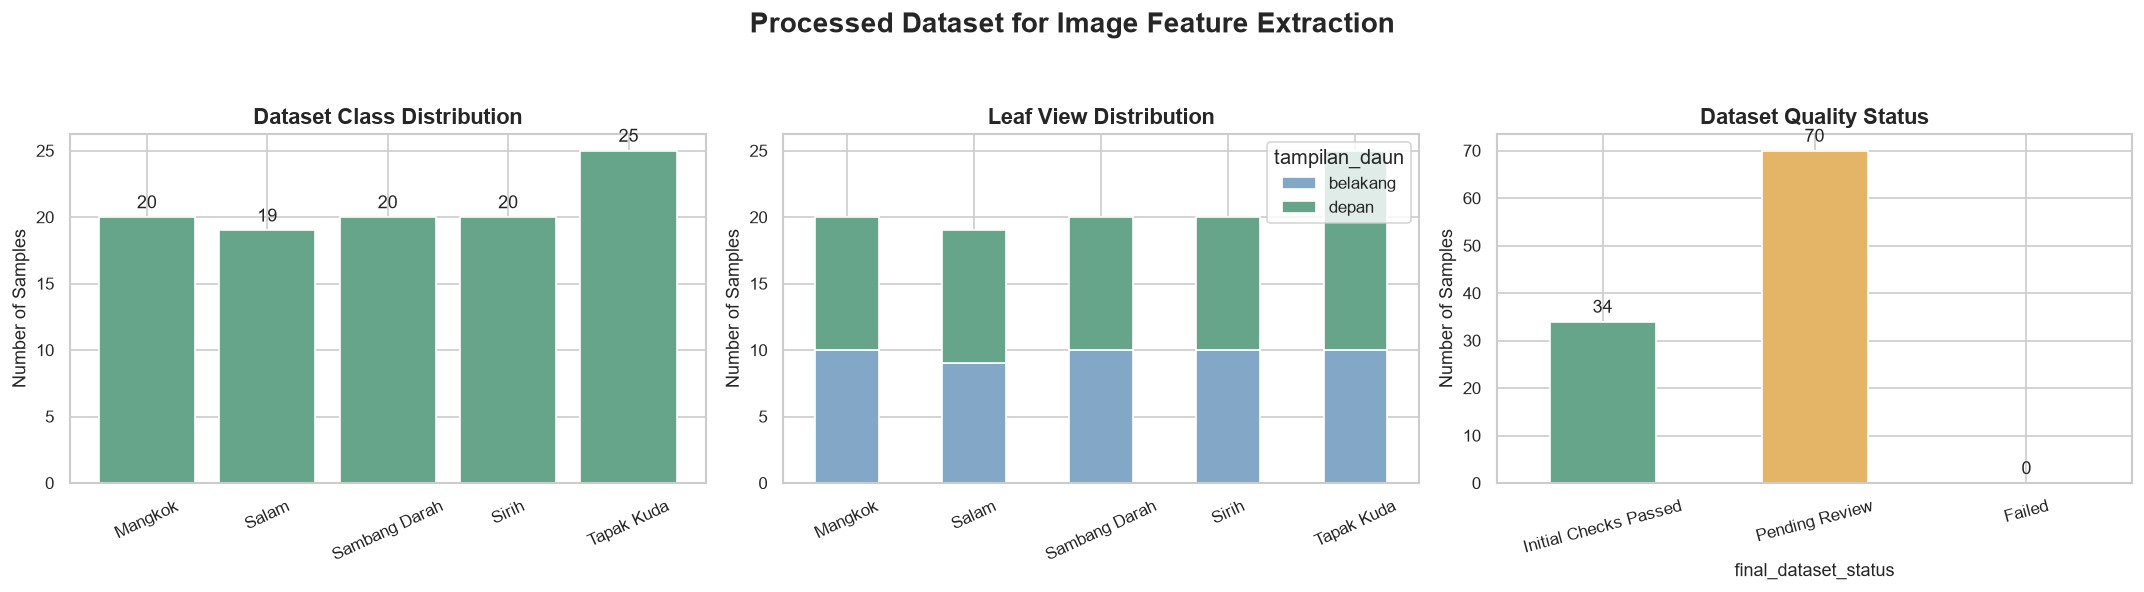


12. FINAL DATASET LOADING SUMMARY
Total samples         : 104
Total classes         : 5
Unique sample IDs     : 104
Available RGB images  : 104
Available binary masks: 104
Complete input pairs  : 104
Pending quality review: 70
Target image size     : 256 x 256

[PASS] Processed metadata loaded successfully.
[PASS] Dataset manifest is consistent.
[PASS] Sample identifiers are unique.
[PASS] All required image and mask files exist.
[PASS] Original dataset order is preserved.

[INFO] Image content validation is pending.
[INFO] No features have been extracted.
[INFO] No additional samples have been removed.

Processed dataset loaded successfully!

Next cell: Cell 5 - Dataset Validation


In [3]:
# ==================================================
# LOAD PROCESSED DATASET
# ==================================================

print("LOAD PROCESSED DATASET")
print("=" * 60)


# ==================================================
# 1. LOAD FINAL PROCESSED METADATA
# ==================================================

df_processed = pd.read_csv(

    FINAL_METADATA_PATH,

    encoding="utf-8-sig"
)

print("\n1. PROCESSED METADATA INFORMATION")

print(f"Metadata path : {FINAL_METADATA_PATH}")
print(f"Total samples : {len(df_processed)}")
print(f"Total columns : {df_processed.shape[1]}")

display(df_processed.head())


# ==================================================
# 2. LOAD DATASET MANIFEST
# ==================================================

with open(

    DATASET_MANIFEST_PATH,

    "r",

    encoding="utf-8"

) as file:

    dataset_manifest = json.load(file)


with open(

    PREPROCESSING_CONFIG_PATH,

    "r",

    encoding="utf-8"

) as file:

    preprocessing_config = json.load(file)


with open(

    PREPROCESSING_SUMMARY_PATH,

    "r",

    encoding="utf-8"

) as file:

    preprocessing_summary = json.load(file)


print("\n2. DATASET MANIFEST INFORMATION")

manifest_information = pd.DataFrame({

    "Indicator": [

        "Dataset name",
        "Total samples",
        "Total classes",
        "Modalities",
        "Image size",
        "Image format",
        "Image mode",
        "Preprocessing completed",
        "Feature extraction ready",
        "Pending quality review"
    ],

    "Value": [

        dataset_manifest["dataset_name"],

        dataset_manifest["total_samples"],

        dataset_manifest["total_classes"],

        ", ".join(
            dataset_manifest["modalities"]
        ),

        " x ".join(
            map(
                str,
                dataset_manifest["image_size"]
            )
        ),

        dataset_manifest["image_format"],

        dataset_manifest["image_mode"],

        dataset_manifest.get(
            "preprocessing_completed", False
        ),

        dataset_manifest.get(
            "feature_extraction_ready", False
        ),

        dataset_manifest.get(
            "records_pending_review", 0
        )
    ]
})

display(manifest_information)


# ==================================================
# 3. VALIDATE REQUIRED METADATA COLUMNS
# ==================================================

required_columns = [

    # Sample identification
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",

    # Image paths
    "image_path",
    "processed_image_path",
    "mask_path",

    # Morphological attributes
    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur",

    # Text modality
    "cleaned_description",
    "tokenized_description",

    # Image preprocessing information
    "roi_applied",
    "final_foreground_ratio",
    "final_foreground_pixels",
    "final_border_ratio",

    # Technical validation
    "processed_image_valid",
    "processed_mask_valid",
    "processed_text_valid",
    "image_mask_aligned",
    "multimodal_valid",

    # Quality status
    "batch_status",
    "final_dataset_status",
    "final_review_notes"
]

missing_columns = [

    column

    for column in required_columns

    if column not in df_processed.columns
]

print("\n3. METADATA STRUCTURE VALIDATION")

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("[OK] All required metadata columns are available.")

print(f"Required columns : {len(required_columns)}")

print(f"Available columns: {df_processed.shape[1]}")


# ==================================================
# 4. VALIDATE MISSING REQUIRED VALUES
# ==================================================

essential_columns = [

    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "image_path",
    "processed_image_path",
    "mask_path",
    "tokenized_description"
]

missing_value_records = []

for column in essential_columns:

    missing_count = int(

        df_processed[column].isna().sum()
    )

    empty_count = int(

        df_processed[column]

        .fillna("")

        .astype(str)

        .str.strip()

        .eq("").sum()
    )

    missing_value_records.append({

        "Column": column,

        "Missing Values": missing_count,

        "Missing or Empty": empty_count
    })


missing_value_df = pd.DataFrame(
    missing_value_records
)

print("\n4. ESSENTIAL METADATA COMPLETENESS")

display(missing_value_df)

if missing_value_df["Missing or Empty"].sum() > 0:

    raise ValueError(
        "Missing or empty essential metadata values detected."
    )


# ==================================================
# 5. NORMALIZE BOOLEAN COLUMNS
# ==================================================

boolean_columns = [

    "roi_applied",
    "processed_image_valid",
    "processed_mask_valid",
    "processed_text_valid",
    "image_mask_aligned",
    "multimodal_valid"
]

def parse_boolean(value):

    normalized_value = str(value).strip().lower()

    if normalized_value in ["true", "1", "1.0"]:

        return True

    if normalized_value in ["false", "0", "0.0"]:

        return False

    raise ValueError(
        f"Invalid boolean value: {value}"
    )


for column in boolean_columns:

    df_processed[column] = (

        df_processed[column]

        .apply(parse_boolean)

        .astype(bool)
    )


# ==================================================
# 6. VERIFY DATASET CONSISTENCY WITH MANIFEST
# ==================================================

EXPECTED_SAMPLE_COUNT = int(
    dataset_manifest["total_samples"]
)

EXPECTED_CLASS_COUNT = int(
    dataset_manifest["total_classes"]
)

EXPECTED_CLASSES = sorted(
    dataset_manifest["classes"]
)

TARGET_WIDTH, TARGET_HEIGHT = map(

    int,

    dataset_manifest["image_size"]
)

TARGET_SIZE = (
    TARGET_WIDTH,
    TARGET_HEIGHT
)

actual_classes = sorted(
    df_processed["kelas"].unique().tolist()
)

manifest_validation_df = pd.DataFrame({

    "Validation": [

        "Sample count matches manifest",

        "Class count matches manifest",

        "Class labels match manifest",

        "Unique sample identifiers",

        "Unique original image paths",

        "Unique processed image paths",

        "Unique binary mask paths",

        "All multimodal pairs technically valid",

        "Preprocessing completed",

        "Feature extraction ready"
    ],

    "Passed": [

        len(df_processed)
        == EXPECTED_SAMPLE_COUNT,

        df_processed["kelas"].nunique()
        == EXPECTED_CLASS_COUNT,

        actual_classes == EXPECTED_CLASSES,

        df_processed["sample_id"].is_unique,

        df_processed["image_path"].is_unique,

        df_processed["processed_image_path"].is_unique,

        df_processed["mask_path"].is_unique,

        df_processed["multimodal_valid"].all(),

        dataset_manifest.get(
            "preprocessing_completed", False
        ) is True,

        dataset_manifest.get(
            "feature_extraction_ready", False
        ) is True
    ]
})

print("\n5. DATASET MANIFEST CONSISTENCY")

display(manifest_validation_df)

if not manifest_validation_df["Passed"].all():

    failed_checks = manifest_validation_df.loc[

        ~manifest_validation_df["Passed"],

        "Validation"

    ].tolist()

    raise ValueError(
        f"Dataset consistency checks failed: {failed_checks}"
    )


# ==================================================
# 7. PREPARE MAIN IMAGE FEATURE DATAFRAME
# ==================================================

df_image = (

    df_processed.copy()

    .reset_index(drop=True)
)

# Preserve dataset order for future feature alignment
df_image["feature_index"] = np.arange(
    len(df_image)
)


# ==================================================
# 8. RESOLVE ABSOLUTE IMAGE AND MASK PATHS
# ==================================================

def resolve_project_path(relative_path):

    relative_path = Path(str(relative_path))

    if relative_path.is_absolute():

        raise ValueError(
            f"Expected relative path: {relative_path}"
        )

    resolved_path = (

        PROJECT_ROOT / relative_path

    ).resolve()

    # Ensure the path remains within the project directory
    resolved_path.relative_to(
        PROJECT_ROOT.resolve()
    )

    return resolved_path


df_image["absolute_processed_image_path"] = (

    df_image["processed_image_path"]

    .apply(resolve_project_path)
)

df_image["absolute_mask_path"] = (

    df_image["mask_path"]

    .apply(resolve_project_path)
)

df_image["absolute_original_image_path"] = (

    df_image["image_path"]

    .apply(resolve_project_path)
)


# ==================================================
# 9. CHECK FILE AVAILABILITY
# ==================================================

df_image["processed_image_exists"] = (

    df_image["absolute_processed_image_path"]

    .apply(lambda path: path.is_file())
)

df_image["mask_exists"] = (

    df_image["absolute_mask_path"]

    .apply(lambda path: path.is_file())
)

df_image["original_image_exists"] = (

    df_image["absolute_original_image_path"]

    .apply(lambda path: path.is_file())
)

df_image["feature_input_available"] = (

    df_image["processed_image_exists"]

    & df_image["mask_exists"]
)

file_availability_df = pd.DataFrame({

    "Indicator": [

        "Total metadata records",

        "Available processed RGB images",

        "Available binary masks",

        "Available original images",

        "Complete feature input pairs",

        "Missing feature input pairs"
    ],

    "Result": [

        len(df_image),

        df_image["processed_image_exists"].sum(),

        df_image["mask_exists"].sum(),

        df_image["original_image_exists"].sum(),

        df_image["feature_input_available"].sum(),

        (~df_image["feature_input_available"]).sum()
    ]
})

print("\n6. INPUT FILE AVAILABILITY")

display(file_availability_df)

if not df_image["feature_input_available"].all():

    display(

        df_image.loc[

            ~df_image["feature_input_available"],

            [
                "sample_id",
                "nama_file",
                "processed_image_path",
                "mask_path"
            ]
        ]
    )

    raise FileNotFoundError(
        "Some processed images or masks are missing."
    )


# ==================================================
# 10. ANALYZE CLASS DISTRIBUTION
# ==================================================

class_distribution_df = (

    df_image["kelas"]

    .value_counts()

    .sort_index()

    .rename_axis("kelas")

    .reset_index(name="total_samples")
)

class_distribution_df["percentage"] = (

    class_distribution_df["total_samples"]

    / len(df_image)

    * 100
).round(2)

print("\n7. CLASS DISTRIBUTION")

display(class_distribution_df)


# ==================================================
# 11. ANALYZE LEAF VIEW DISTRIBUTION
# ==================================================

leaf_view_distribution_df = pd.crosstab(

    df_image["kelas"],

    df_image["tampilan_daun"]
)

leaf_view_distribution_df["Total"] = (

    leaf_view_distribution_df.sum(axis=1)
)

print("\n8. LEAF VIEW DISTRIBUTION")

display(leaf_view_distribution_df)


# ==================================================
# 12. ANALYZE DATASET QUALITY STATUS
# ==================================================

dataset_status_counts = (

    df_image["final_dataset_status"]

    .value_counts()

    .reindex(

        [

            "Ready - Initial Checks Passed",

            "Ready - Pending Review",

            "Failed"
        ],

        fill_value=0
    )
)

print("\n9. DATASET QUALITY STATUS")

display(

    dataset_status_counts.to_frame(

        "Number of Samples"
    )
)

print(

    "[INFO] Pending review samples are retained "
    "for feature extraction."
)


# ==================================================
# 13. PREPARE SAMPLE IDENTIFIERS
# ==================================================

sample_ids = (

    df_image["sample_id"]

    .astype(str)

    .to_numpy(dtype=str)
)

class_labels = (

    df_image["kelas"]

    .astype(str)

    .to_numpy(dtype=str)
)

assert len(sample_ids) == len(df_image)

assert len(np.unique(sample_ids)) == len(sample_ids)

assert len(class_labels) == len(sample_ids)

assert df_image["sample_id"].equals(

    df_processed["sample_id"]

    .reset_index(drop=True)
)

print("\n10. SAMPLE ALIGNMENT")

display(

    df_image[
        [
            "feature_index",
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun"
        ]
    ].head(10)
)


# ==================================================
# 14. CREATE DATASET LOADING SUMMARY
# ==================================================

dataset_loading_summary_df = pd.DataFrame({

    "Indicator": [

        "Total loaded samples",

        "Total classes",

        "Unique sample identifiers",

        "Available processed images",

        "Available binary masks",

        "Complete feature input pairs",

        "Technically valid multimodal pairs",

        "Initial checks passed",

        "Pending quality review",

        "Failed samples",

        "Target image width",

        "Target image height"
    ],

    "Result": [

        len(df_image),

        df_image["kelas"].nunique(),

        df_image["sample_id"].nunique(),

        df_image["processed_image_exists"].sum(),

        df_image["mask_exists"].sum(),

        df_image["feature_input_available"].sum(),

        df_image["multimodal_valid"].sum(),

        dataset_status_counts[
            "Ready - Initial Checks Passed"
        ],

        dataset_status_counts[
            "Ready - Pending Review"
        ],

        dataset_status_counts["Failed"],

        TARGET_WIDTH,

        TARGET_HEIGHT
    ]
})

print("\n11. DATASET LOADING SUMMARY")

display(dataset_loading_summary_df)


# ==================================================
# 15. VISUALIZE DATASET DISTRIBUTION
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(18, 5)
)

# Class distribution
axes[0].bar(

    class_distribution_df["kelas"],

    class_distribution_df["total_samples"],

    color="#66A58A"
)

axes[0].set_title(
    "Dataset Class Distribution"
)

axes[0].set_ylabel(
    "Number of Samples"
)

axes[0].tick_params(

    axis="x",

    rotation=25
)

for container in axes[0].containers:

    axes[0].bar_label(
        container,
        padding=3
    )


# Leaf view distribution
leaf_view_distribution_df.drop(

    columns=["Total"]

).plot(

    kind="bar",

    stacked=True,

    color=["#83A7C7", "#66A58A"],

    rot=25,

    ax=axes[1]
)

axes[1].set_title(
    "Leaf View Distribution"
)

axes[1].set_ylabel(
    "Number of Samples"
)

axes[1].set_xlabel("")


# Dataset quality status
dataset_status_counts.plot(

    kind="bar",

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=15,

    ax=axes[2]
)

axes[2].set_title(
    "Dataset Quality Status"
)

axes[2].set_ylabel(
    "Number of Samples"
)

axes[2].set_xticklabels(

    [
        "Initial Checks Passed",
        "Pending Review",
        "Failed"
    ]
)

for container in axes[2].containers:

    axes[2].bar_label(
        container,
        padding=3
    )


fig.suptitle(

    "Processed Dataset for Image Feature Extraction",

    fontsize=17,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.93]
)

plt.savefig(

    FEATURE_FIGURES_DIR /
    "25_processed_dataset_distribution.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ==================================================
# 16. SAVE DATASET LOADING REPORTS
# ==================================================

dataset_loading_summary_df.to_csv(

    METRICS_DIR /
    "72_image_feature_dataset_loading_summary.csv",

    index=False,

    encoding="utf-8-sig"
)

manifest_validation_df.to_csv(

    METRICS_DIR /
    "73_dataset_manifest_consistency.csv",

    index=False,

    encoding="utf-8-sig"
)

class_distribution_df.to_csv(

    METRICS_DIR /
    "74_image_feature_class_distribution.csv",

    index=False,

    encoding="utf-8-sig"
)

leaf_view_distribution_df.to_csv(

    METRICS_DIR /
    "75_image_feature_leaf_view_distribution.csv",

    encoding="utf-8-sig"
)

file_availability_df.to_csv(

    METRICS_DIR /
    "76_image_feature_file_availability.csv",

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 17. FINAL DATASET LOADING SUMMARY
# ==================================================

print("\n12. FINAL DATASET LOADING SUMMARY")

print("=" * 60)

print(f"Total samples         : {len(df_image)}")

print(f"Total classes         : {df_image['kelas'].nunique()}")

print(f"Unique sample IDs     : {len(np.unique(sample_ids))}")

print(
    f"Available RGB images  : "
    f"{df_image['processed_image_exists'].sum()}"
)

print(
    f"Available binary masks: "
    f"{df_image['mask_exists'].sum()}"
)

print(
    f"Complete input pairs  : "
    f"{df_image['feature_input_available'].sum()}"
)

print(
    f"Pending quality review: "
    f"{dataset_status_counts['Ready - Pending Review']}"
)

print(
    f"Target image size     : "
    f"{TARGET_WIDTH} x {TARGET_HEIGHT}"
)

print("\n[PASS] Processed metadata loaded successfully.")

print("[PASS] Dataset manifest is consistent.")

print("[PASS] Sample identifiers are unique.")

print("[PASS] All required image and mask files exist.")

print("[PASS] Original dataset order is preserved.")

print("\n[INFO] Image content validation is pending.")

print("[INFO] No features have been extracted.")

print("[INFO] No additional samples have been removed.")

print("\nProcessed dataset loaded successfully!")

print("\nNext cell: Cell 5 - Dataset Validation")

DATASET VALIDATION

1. VALIDATING ALL DATASET SAMPLES


Validating images and masks:   0%|          | 0/104 [00:00<?, ?it/s]


2. SAMPLE VALIDATION RESULTS


,feature_index,nama_file,kelas,foreground_pixels,foreground_ratio,grayscale_std,technical_valid,validation_status
0,0,mangkok 10.jpeg,Mangkok,27532,0.420100,34.171300,True,Needs Review
1,1,mangkok 11.png,Mangkok,16446,0.250900,19.913600,True,Passed Initial Check
2,2,mangkok 12.png,Mangkok,16642,0.253900,18.785800,True,Passed Initial Check
3,3,mangkok 13.png,Mangkok,18669,0.284900,22.001300,True,Passed Initial Check
4,4,mangkok 14.png,Mangkok,16987,0.259200,17.068300,True,Passed Initial Check
5,5,mangkok 15.png,Mangkok,17752,0.270900,18.763900,True,Passed Initial Check
6,6,mangkok 6.jpeg,Mangkok,13803,0.210600,27.676700,True,Needs Review
7,7,mangkok 7.jpeg,Mangkok,32016,0.488500,15.492900,True,Needs Review
8,8,mangkok 8.jpeg,Mangkok,24059,0.367100,28.298000,True,Needs Review
9,9,mangkok 9.jpeg,Mangkok,31092,0.474400,31.224000,True,Needs Review



3. DATASET VALIDATION SUMMARY


,Indicator,Result
0,Total validated samples,104
1,Valid RGB dimensions,104
2,Valid RGB data type,104
3,Valid RGB mode,104
4,Valid RGB format,104
5,Valid mask dimensions,104
6,Valid mask data type,104
7,Valid mask mode,104
8,Valid mask format,104
9,Valid binary mask values,104


... (3 outputs left out)

validation_status,Passed Initial Check,Needs Review,Failed,Total
kelas,,,,
Mangkok,11,9,0,20
Salam,9,10,0,19
Sambang Darah,4,16,0,20
Sirih,10,10,0,20
Tapak Kuda,0,25,0,25



6. FAILED VALIDATION RECORDS
[OK] No technical validation failures.

7. RECORDS REQUIRING QUALITY REVIEW
Total review records: 70


,nama_file,kelas,foreground_ratio,grayscale_std,review_issues
0,mangkok 10.jpeg,Mangkok,0.420105,34.171343,Previous quality review pending
6,mangkok 6.jpeg,Mangkok,0.210617,27.676694,Previous quality review pending
7,mangkok 7.jpeg,Mangkok,0.488525,15.492932,Previous quality review pending
8,mangkok 8.jpeg,Mangkok,0.367111,28.298023,Previous quality review pending
9,mangkok 9.jpeg,Mangkok,0.474426,31.223975,Previous quality review pending
10,mangkok 1.jpeg,Mangkok,0.460480,18.638830,Previous quality review pending
12,mangkok 2.jpeg,Mangkok,0.465958,22.360829,Previous quality review pending
13,mangkok 3.jpeg,Mangkok,0.410370,25.219783,Previous quality review pending
14,mangkok 4.jpeg,Mangkok,0.321732,25.892266,Previous quality review pending
20,daun salam 10.jpeg,Salam,0.166138,7.139015,Previous quality review pending



8. SAMPLE ALIGNMENT VALIDATION
[OK] All sample identifiers are consistent.
[OK] Original sample order is preserved.
[OK] Feature indices are sequential.


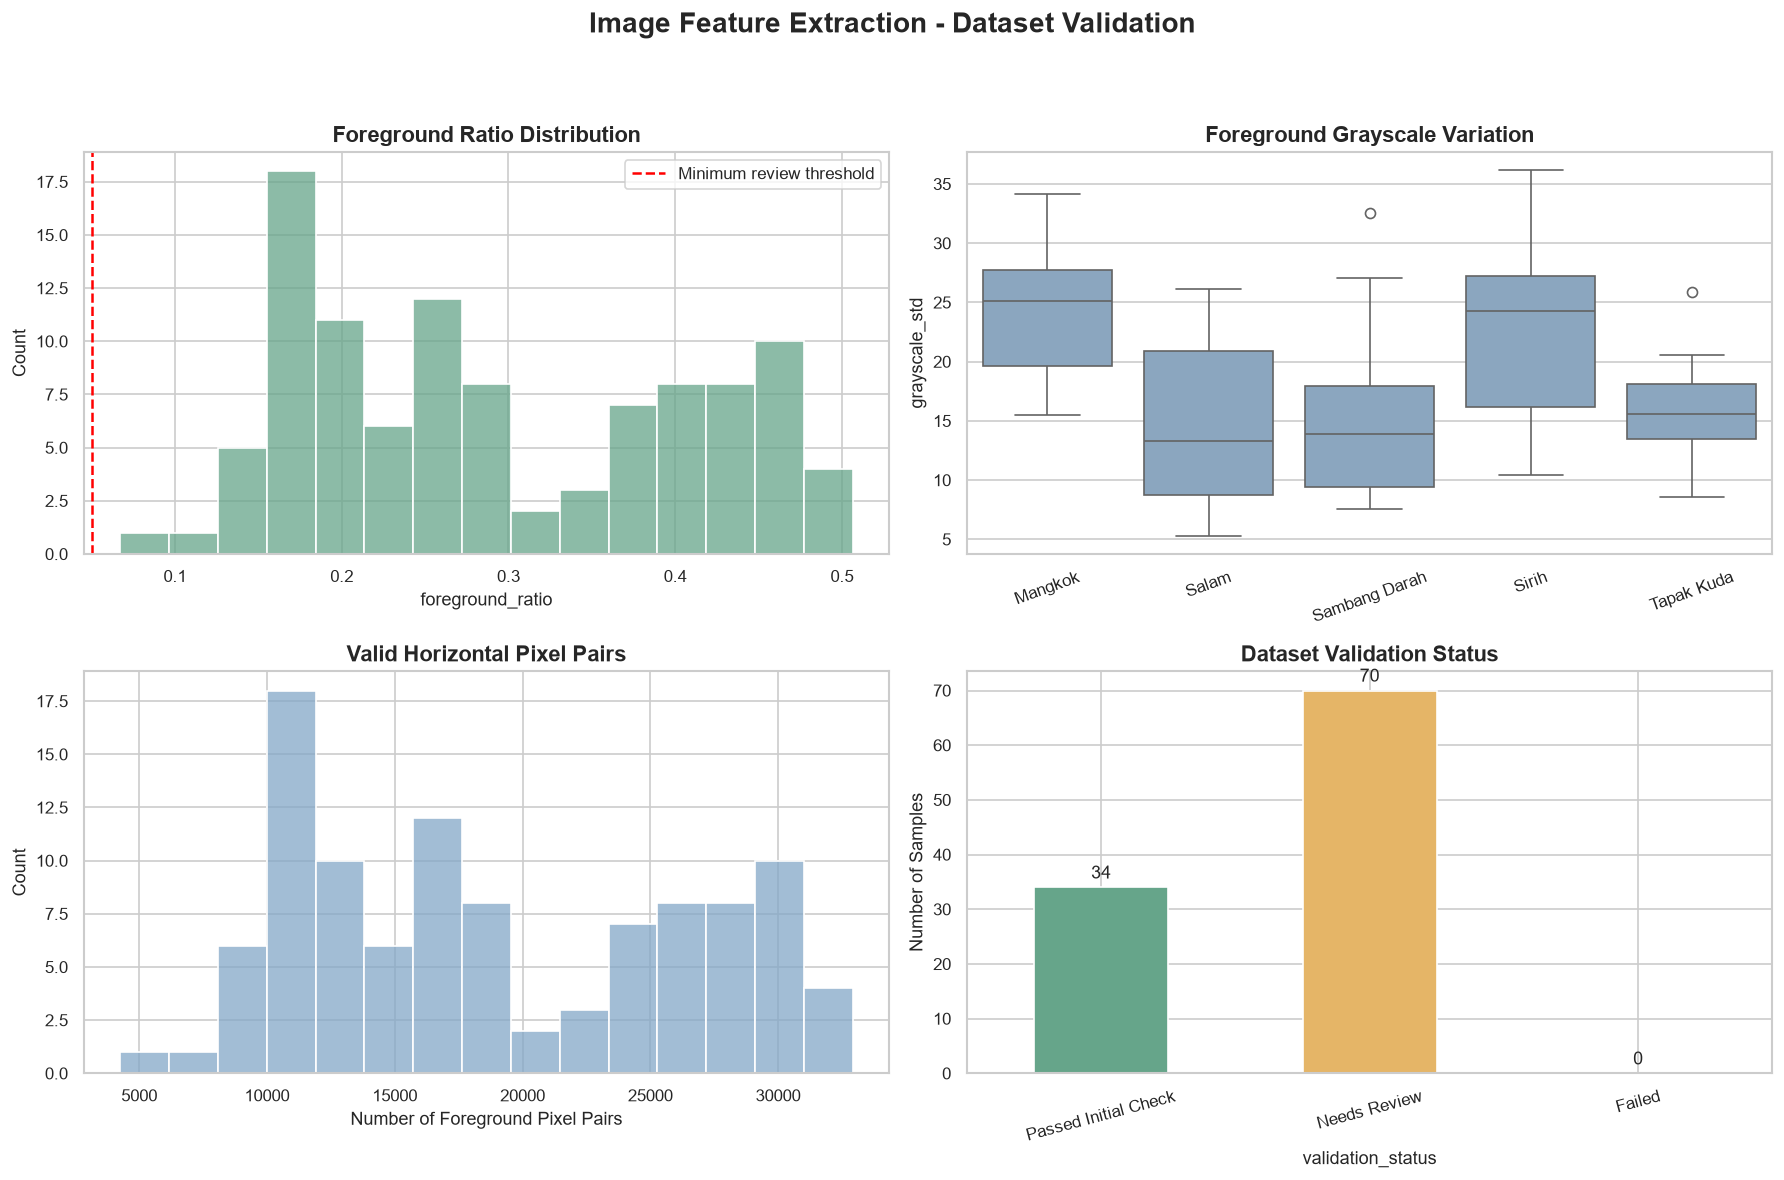


9. REPRESENTATIVE SAMPLE VALIDATION


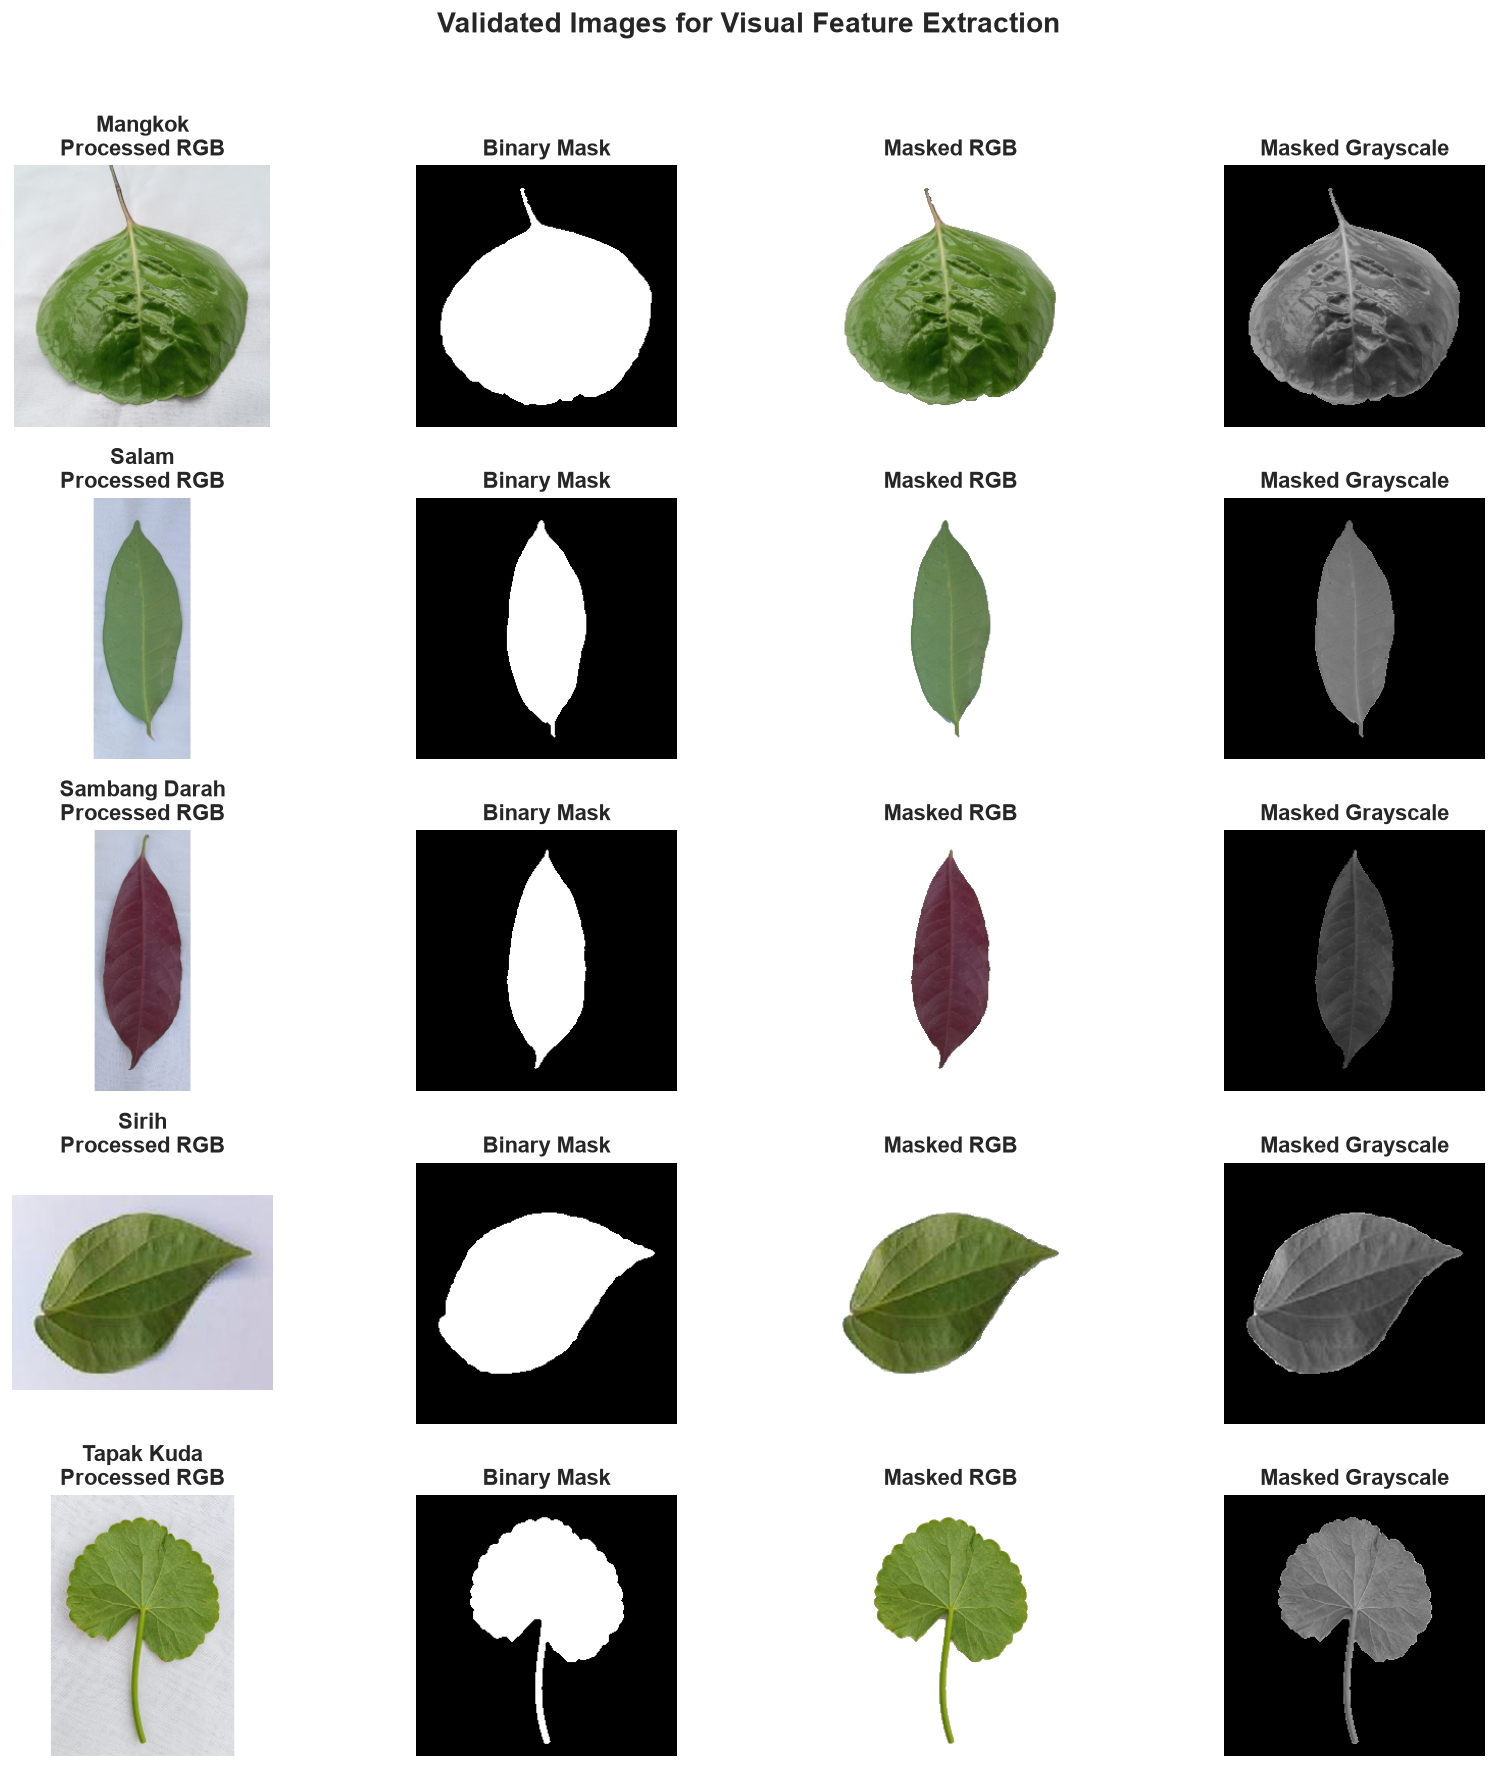


10. FINAL DATASET VALIDATION SUMMARY
Total validated samples : 104
Technically valid       : 104
Technically invalid     : 0
Passed initial check    : 34
Needs review            : 70
Failed validation       : 0
Final feature dataset   : 104
Target image size       : 256 x 256

[PASS] RGB images passed technical validation.
[PASS] Binary masks passed technical validation.
[PASS] Image-mask dimensions and paths match.
[PASS] Foreground measurements are consistent.
[PASS] Sample identifiers and order are preserved.

[INFO] Pending review samples are retained.
[INFO] No additional samples have been removed.
[INFO] No feature vectors have been extracted.

Dataset validation completed successfully!

Next cell: Cell 6 - Feature Extraction Configuration


In [4]:
# ==================================================
# DATASET VALIDATION
# ==================================================

print("DATASET VALIDATION")
print("=" * 60)


# ==================================================
# 1. VALIDATION CONFIGURATION
# ==================================================

MIN_FOREGROUND_PIXELS = int(
    preprocessing_config.get(
        "roi_min_mask_pixels", 100
    )
)

MIN_FOREGROUND_RATIO = float(
    preprocessing_config.get(
        "small_foreground_review_ratio", 0.05
    )
)

MAX_FOREGROUND_RATIO = 0.90

FOREGROUND_RATIO_TOLERANCE = 1e-6

MIN_GRAYSCALE_VARIATION = 1.0


# ==================================================
# 2. DEFINE IMAGE AND MASK LOADING FUNCTION
# ==================================================

def load_processed_pair(image_path, mask_path):

    # Load RGB image without changing its format
    with Image.open(image_path) as image:

        image_mode = image.mode
        image_format = image.format
        rgb_image = np.array(image)

    # Load binary mask without changing its values
    with Image.open(mask_path) as mask:

        mask_mode = mask.mode
        mask_format = mask.format
        binary_mask = np.array(mask)

    return {
        "rgb_image": rgb_image,
        "binary_mask": binary_mask,
        "image_mode": image_mode,
        "image_format": image_format,
        "mask_mode": mask_mode,
        "mask_format": mask_format
    }


# ==================================================
# 3. DEFINE INDIVIDUAL SAMPLE VALIDATION
# ==================================================

def validate_sample(row):

    errors = []
    review_issues = []

    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]
    binary_mask = data["binary_mask"]

    # --------------------------------------------------
    # Validate RGB image
    # --------------------------------------------------

    valid_image_shape = (

        rgb_image.shape
        == (TARGET_HEIGHT, TARGET_WIDTH, 3)
    )

    valid_image_dtype = (
        rgb_image.dtype == np.uint8
    )

    valid_image_mode = (
        data["image_mode"] == "RGB"
    )

    valid_image_format = (
        data["image_format"] == "PNG"
    )

    if not valid_image_shape:
        errors.append("Invalid RGB dimensions")

    if not valid_image_dtype:
        errors.append("Invalid RGB data type")

    if not valid_image_mode:
        errors.append("Invalid RGB image mode")

    if not valid_image_format:
        errors.append("Invalid RGB image format")

    # --------------------------------------------------
    # Validate binary mask
    # --------------------------------------------------

    valid_mask_shape = (

        binary_mask.shape
        == (TARGET_HEIGHT, TARGET_WIDTH)
    )

    valid_mask_dtype = (
        binary_mask.dtype == np.uint8
    )

    valid_mask_mode = (
        data["mask_mode"] == "L"
    )

    valid_mask_format = (
        data["mask_format"] == "PNG"
    )

    mask_unique_values = set(
        np.unique(binary_mask).tolist()
    )

    valid_mask_values = (
        mask_unique_values == {0, 255}
    )

    if not valid_mask_shape:
        errors.append("Invalid mask dimensions")

    if not valid_mask_dtype:
        errors.append("Invalid mask data type")

    if not valid_mask_mode:
        errors.append("Invalid mask mode")

    if not valid_mask_format:
        errors.append("Invalid mask format")

    if not valid_mask_values:
        errors.append("Invalid binary mask values")

    # --------------------------------------------------
    # Validate image-mask alignment
    # --------------------------------------------------

    matching_dimensions = (

        rgb_image.shape[:2]
        == binary_mask.shape
    )

    if not matching_dimensions:

        errors.append(
            "Image-mask dimension mismatch"
        )

    try:

        image_relative_path = (

            row["absolute_processed_image_path"]

            .relative_to(
                PROCESSED_IMAGE_DIR.resolve()
            )
        )

        mask_relative_path = (

            row["absolute_mask_path"]

            .relative_to(
                MASK_DIR.resolve()
            )
        )

        matching_paths = (
            image_relative_path == mask_relative_path
        )

    except ValueError:

        matching_paths = False

    if not matching_paths:

        errors.append(
            "Image-mask path mismatch"
        )

    # --------------------------------------------------
    # Initialize quality measurements
    # --------------------------------------------------

    foreground_pixels = np.nan
    foreground_ratio = np.nan
    background_pixels = np.nan

    mean_red = np.nan
    mean_green = np.nan
    mean_blue = np.nan

    grayscale_mean = np.nan
    grayscale_std = np.nan

    valid_horizontal_pairs = 0
    valid_vertical_pairs = 0

    foreground_ratio_difference = np.nan

    # --------------------------------------------------
    # Inspect foreground region
    # --------------------------------------------------

    if not errors:

        foreground = binary_mask == 255

        foreground_pixels = int(
            foreground.sum()
        )

        background_pixels = int(
            binary_mask.size - foreground_pixels
        )

        foreground_ratio = float(

            foreground_pixels
            / binary_mask.size
        )

        if foreground_pixels < MIN_FOREGROUND_PIXELS:

            errors.append(
                "Insufficient foreground pixels"
            )

        if foreground_ratio < MIN_FOREGROUND_RATIO:

            review_issues.append(
                "Small foreground"
            )

        if foreground_ratio > MAX_FOREGROUND_RATIO:

            review_issues.append(
                "Large foreground"
            )

        # Compare saved mask with metadata
        foreground_ratio_difference = abs(

            foreground_ratio

            - float(row["final_foreground_ratio"])
        )

        if (
            foreground_ratio_difference
            > FOREGROUND_RATIO_TOLERANCE
        ):

            errors.append(
                "Foreground ratio mismatch with metadata"
            )

        if foreground_pixels != int(
            row["final_foreground_pixels"]
        ):

            errors.append(
                "Foreground pixel count mismatch"
            )

        # --------------------------------------------------
        # Inspect RGB and grayscale information
        # --------------------------------------------------

        if foreground_pixels > 0:

            foreground_rgb = rgb_image[foreground]

            mean_red = float(
                foreground_rgb[:, 0].mean()
            )

            mean_green = float(
                foreground_rgb[:, 1].mean()
            )

            mean_blue = float(
                foreground_rgb[:, 2].mean()
            )

            gray_image = cv2.cvtColor(

                rgb_image,

                cv2.COLOR_RGB2GRAY
            )

            foreground_gray = gray_image[
                foreground
            ]

            grayscale_mean = float(
                foreground_gray.mean()
            )

            grayscale_std = float(
                foreground_gray.std()
            )

            if grayscale_std < MIN_GRAYSCALE_VARIATION:

                review_issues.append(
                    "Very low grayscale variation"
                )

            # ----------------------------------------------
            # Check valid pixel pairs for GLCM
            # ----------------------------------------------

            valid_horizontal_pairs = int(

                np.logical_and(

                    foreground[:, :-1],

                    foreground[:, 1:]

                ).sum()
            )

            valid_vertical_pairs = int(

                np.logical_and(

                    foreground[:-1, :],

                    foreground[1:, :]

                ).sum()
            )

            if (
                valid_horizontal_pairs == 0
                or valid_vertical_pairs == 0
            ):

                errors.append(
                    "Insufficient valid GLCM pixel pairs"
                )

    # --------------------------------------------------
    # Preserve previous quality review
    # --------------------------------------------------

    previous_pending_review = (

        row["final_dataset_status"]

        == "Ready - Pending Review"
    )

    if previous_pending_review:

        review_issues.append(
            "Previous quality review pending"
        )

    # --------------------------------------------------
    # Determine final validation status
    # --------------------------------------------------

    technical_valid = len(errors) == 0

    if not technical_valid:

        validation_status = "Failed"

    elif review_issues:

        validation_status = "Needs Review"

    else:

        validation_status = "Passed Initial Check"

    return {

        "feature_index": row["feature_index"],

        "sample_id": row["sample_id"],

        "nama_file": row["nama_file"],

        "kelas": row["kelas"],

        "tampilan_daun": row["tampilan_daun"],

        "valid_image_shape": valid_image_shape,

        "valid_image_dtype": valid_image_dtype,

        "valid_image_mode": valid_image_mode,

        "valid_image_format": valid_image_format,

        "valid_mask_shape": valid_mask_shape,

        "valid_mask_dtype": valid_mask_dtype,

        "valid_mask_mode": valid_mask_mode,

        "valid_mask_format": valid_mask_format,

        "valid_mask_values": valid_mask_values,

        "matching_dimensions": matching_dimensions,

        "matching_paths": matching_paths,

        "foreground_pixels": foreground_pixels,

        "background_pixels": background_pixels,

        "foreground_ratio": foreground_ratio,

        "foreground_ratio_difference": (
            foreground_ratio_difference
        ),

        "mean_red": mean_red,

        "mean_green": mean_green,

        "mean_blue": mean_blue,

        "grayscale_mean": grayscale_mean,

        "grayscale_std": grayscale_std,

        "valid_horizontal_pairs": (
            valid_horizontal_pairs
        ),

        "valid_vertical_pairs": (
            valid_vertical_pairs
        ),

        "previous_pending_review": (
            previous_pending_review
        ),

        "technical_valid": technical_valid,

        "validation_status": validation_status,

        "validation_errors": (
            "; ".join(errors)
            if errors
            else "None"
        ),

        "review_issues": (
            "; ".join(review_issues)
            if review_issues
            else "None"
        )
    }


# ==================================================
# 4. VALIDATE ALL DATASET SAMPLES
# ==================================================

print("\n1. VALIDATING ALL DATASET SAMPLES")

validation_records = []

for _, row in tqdm(

    df_image.iterrows(),

    total=len(df_image),

    desc="Validating images and masks"
):

    try:

        result = validate_sample(row)

    except Exception as error:

        result = {

            "feature_index": row["feature_index"],

            "sample_id": row["sample_id"],

            "nama_file": row["nama_file"],

            "kelas": row["kelas"],

            "tampilan_daun": row["tampilan_daun"],

            "technical_valid": False,

            "validation_status": "Failed",

            "validation_errors": str(error),

            "review_issues": "None"
        }

    validation_records.append(result)


dataset_validation_df = pd.DataFrame(
    validation_records
)


# ==================================================
# 5. ENSURE REQUIRED VALIDATION COLUMNS
# ==================================================

boolean_validation_columns = [

    "valid_image_shape",
    "valid_image_dtype",
    "valid_image_mode",
    "valid_image_format",
    "valid_mask_shape",
    "valid_mask_dtype",
    "valid_mask_mode",
    "valid_mask_format",
    "valid_mask_values",
    "matching_dimensions",
    "matching_paths"
]

numeric_validation_columns = [

    "foreground_pixels",
    "background_pixels",
    "foreground_ratio",
    "foreground_ratio_difference",
    "mean_red",
    "mean_green",
    "mean_blue",
    "grayscale_mean",
    "grayscale_std",
    "valid_horizontal_pairs",
    "valid_vertical_pairs"
]

for column in boolean_validation_columns:

    if column not in dataset_validation_df.columns:

        dataset_validation_df[column] = False

    else:

        dataset_validation_df[column] = (

            dataset_validation_df[column]
            .eq(True)
        )

for column in numeric_validation_columns:

    if column not in dataset_validation_df.columns:

        dataset_validation_df[column] = np.nan


# ==================================================
# 6. DATASET VALIDATION RESULTS
# ==================================================

print("\n2. SAMPLE VALIDATION RESULTS")

display(

    dataset_validation_df[
        [
            "feature_index",
            "nama_file",
            "kelas",
            "foreground_pixels",
            "foreground_ratio",
            "grayscale_std",
            "technical_valid",
            "validation_status"
        ]
    ].head(10).round(4)
)


# ==================================================
# 7. VALIDATION STATUS SUMMARY
# ==================================================

validation_counts = (

    dataset_validation_df["validation_status"]

    .value_counts()

    .reindex(

        [
            "Passed Initial Check",
            "Needs Review",
            "Failed"
        ],

        fill_value=0
    )
)

technically_valid_count = int(

    dataset_validation_df["technical_valid"]

    .eq(True).sum()
)

technically_invalid_count = (

    len(dataset_validation_df)

    - technically_valid_count
)

validation_summary_df = pd.DataFrame({

    "Indicator": [

        "Total validated samples",

        "Valid RGB dimensions",

        "Valid RGB data type",

        "Valid RGB mode",

        "Valid RGB format",

        "Valid mask dimensions",

        "Valid mask data type",

        "Valid mask mode",

        "Valid mask format",

        "Valid binary mask values",

        "Matching image-mask dimensions",

        "Matching image-mask paths",

        "Technically valid samples",

        "Technically invalid samples",

        "Passed initial check",

        "Needs review",

        "Failed validation"
    ],

    "Result": [

        len(dataset_validation_df),

        dataset_validation_df[
            "valid_image_shape"
        ].sum(),

        dataset_validation_df[
            "valid_image_dtype"
        ].sum(),

        dataset_validation_df[
            "valid_image_mode"
        ].sum(),

        dataset_validation_df[
            "valid_image_format"
        ].sum(),

        dataset_validation_df[
            "valid_mask_shape"
        ].sum(),

        dataset_validation_df[
            "valid_mask_dtype"
        ].sum(),

        dataset_validation_df[
            "valid_mask_mode"
        ].sum(),

        dataset_validation_df[
            "valid_mask_format"
        ].sum(),

        dataset_validation_df[
            "valid_mask_values"
        ].sum(),

        dataset_validation_df[
            "matching_dimensions"
        ].sum(),

        dataset_validation_df[
            "matching_paths"
        ].sum(),

        technically_valid_count,

        technically_invalid_count,

        validation_counts[
            "Passed Initial Check"
        ],

        validation_counts["Needs Review"],

        validation_counts["Failed"]
    ]
})

print("\n3. DATASET VALIDATION SUMMARY")

display(validation_summary_df)


# ==================================================
# 8. FOREGROUND AND TEXTURE STATISTICS
# ==================================================

valid_dataset_df = dataset_validation_df[

    dataset_validation_df["technical_valid"]

    .eq(True)

].copy()

statistics_columns = [

    "foreground_pixels",

    "foreground_ratio",

    "mean_red",

    "mean_green",

    "mean_blue",

    "grayscale_mean",

    "grayscale_std",

    "valid_horizontal_pairs",

    "valid_vertical_pairs"
]

foreground_statistics_df = (

    valid_dataset_df[statistics_columns]

    .describe()

    .round(4)
)

print("\n4. FOREGROUND AND TEXTURE STATISTICS")

display(foreground_statistics_df)


# ==================================================
# 9. VALIDATION PER CLASS
# ==================================================

validation_class_df = pd.crosstab(

    dataset_validation_df["kelas"],

    dataset_validation_df["validation_status"]

).reindex(

    columns=[
        "Passed Initial Check",
        "Needs Review",
        "Failed"
    ],

    fill_value=0
)

validation_class_df["Total"] = (

    validation_class_df.sum(axis=1)
)

print("\n5. DATASET VALIDATION PER CLASS")

display(validation_class_df)


# ==================================================
# 10. IDENTIFY FAILED AND REVIEW SAMPLES
# ==================================================

failed_validation_df = dataset_validation_df[

    dataset_validation_df["validation_status"]

    .eq("Failed")

].copy()

feature_review_df = dataset_validation_df[

    dataset_validation_df["validation_status"]

    .eq("Needs Review")

].copy()

print("\n6. FAILED VALIDATION RECORDS")

if failed_validation_df.empty:

    print("[OK] No technical validation failures.")

else:

    display(

        failed_validation_df[
            [
                "sample_id",
                "nama_file",
                "kelas",
                "validation_errors"
            ]
        ]
    )

print("\n7. RECORDS REQUIRING QUALITY REVIEW")

print(

    f"Total review records: "
    f"{len(feature_review_df)}"
)

if not feature_review_df.empty:

    display(

        feature_review_df[
            [
                "nama_file",
                "kelas",
                "foreground_ratio",
                "grayscale_std",
                "review_issues"
            ]
        ].head(10)
    )


# ==================================================
# 11. VERIFY SAMPLE ORDER AND ALIGNMENT
# ==================================================

assert len(dataset_validation_df) == len(df_image)

assert dataset_validation_df["sample_id"].is_unique

assert np.array_equal(

    dataset_validation_df["sample_id"]

    .astype(str)

    .to_numpy(),

    sample_ids
)

assert np.array_equal(

    dataset_validation_df["feature_index"]

    .to_numpy(),

    np.arange(len(df_image))
)

print("\n8. SAMPLE ALIGNMENT VALIDATION")

print("[OK] All sample identifiers are consistent.")

print("[OK] Original sample order is preserved.")

print("[OK] Feature indices are sequential.")


# ==================================================
# 12. VISUALIZE DATASET VALIDATION
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(15, 10)
)

# Foreground ratio distribution
if not valid_dataset_df.empty:

    sns.histplot(

        data=valid_dataset_df,

        x="foreground_ratio",

        bins=15,

        color="#66A58A",

        ax=axes[0, 0]
    )

axes[0, 0].axvline(

    MIN_FOREGROUND_RATIO,

    color="red",

    linestyle="--",

    label="Minimum review threshold"
)

axes[0, 0].set_title(
    "Foreground Ratio Distribution"
)

axes[0, 0].legend()


# Grayscale variation
if not valid_dataset_df.empty:

    sns.boxplot(

        data=valid_dataset_df,

        x="kelas",

        y="grayscale_std",

        color="#83A7C7",

        ax=axes[0, 1]
    )

axes[0, 1].set_title(
    "Foreground Grayscale Variation"
)

axes[0, 1].set_xlabel("")

axes[0, 1].tick_params(

    axis="x",

    rotation=20
)


# Valid horizontal pixel pairs
if not valid_dataset_df.empty:

    sns.histplot(

        data=valid_dataset_df,

        x="valid_horizontal_pairs",

        bins=15,

        color="#83A7C7",

        ax=axes[1, 0]
    )

axes[1, 0].set_title(
    "Valid Horizontal Pixel Pairs"
)

axes[1, 0].set_xlabel(
    "Number of Foreground Pixel Pairs"
)


# Validation status
validation_counts.plot(

    kind="bar",

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=15,

    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Dataset Validation Status"
)

axes[1, 1].set_ylabel(
    "Number of Samples"
)

for container in axes[1, 1].containers:

    axes[1, 1].bar_label(

        container,

        padding=3
    )

fig.suptitle(

    "Image Feature Extraction - Dataset Validation",

    fontsize=17,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.savefig(

    FEATURE_FIGURES_DIR /

    "26_image_feature_dataset_validation.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 13. VISUALIZE REPRESENTATIVE VALID SAMPLES
# ==================================================

print("\n9. REPRESENTATIVE SAMPLE VALIDATION")

representative_samples = []

for plant_class, group in df_image.groupby("kelas"):

    valid_ids = set(

        valid_dataset_df["sample_id"]
    )

    valid_group = group[

        group["sample_id"].isin(valid_ids)
    ]

    if not valid_group.empty:

        representative_samples.append(

            valid_group.sample(

                n=1,

                random_state=RANDOM_STATE

            ).iloc[0]
        )

if representative_samples:

    fig, axes = plt.subplots(

        len(representative_samples),

        4,

        figsize=(14, 3 * len(representative_samples)),

        squeeze=False
    )

    for i, row in enumerate(representative_samples):

        data = load_processed_pair(

            row["absolute_processed_image_path"],

            row["absolute_mask_path"]
        )

        rgb = data["rgb_image"]

        mask = data["binary_mask"]

        foreground = mask == 255

        gray = cv2.cvtColor(

            rgb,

            cv2.COLOR_RGB2GRAY
        )

        # Create visualization-only masked RGB image
        segmented = np.full_like(rgb, 255)

        segmented[foreground] = rgb[foreground]

        # Create visualization-only masked grayscale image
        masked_gray = np.zeros_like(gray)

        masked_gray[foreground] = gray[foreground]

        axes[i, 0].imshow(rgb)

        axes[i, 0].set_title(

            f"{row['kelas']}\nProcessed RGB"
        )

        axes[i, 1].imshow(

            mask,

            cmap="gray",

            vmin=0,

            vmax=255
        )

        axes[i, 1].set_title(
            "Binary Mask"
        )

        axes[i, 2].imshow(segmented)

        axes[i, 2].set_title(
            "Masked RGB"
        )

        axes[i, 3].imshow(

            masked_gray,

            cmap="gray",

            vmin=0,

            vmax=255
        )

        axes[i, 3].set_title(
            "Masked Grayscale"
        )

        for ax in axes[i]:

            ax.axis("off")

    fig.suptitle(

        "Validated Images for Visual Feature Extraction",

        fontsize=17,

        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    plt.savefig(

        FEATURE_FIGURES_DIR /

        "27_validated_feature_input_samples.png",

        dpi=300,

        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ==================================================
# 14. SAVE DATASET VALIDATION REPORTS
# ==================================================

dataset_validation_df.to_csv(

    METRICS_DIR /

    "77_image_feature_dataset_validation_details.csv",

    index=False,

    encoding="utf-8-sig"
)

validation_summary_df.to_csv(

    METRICS_DIR /

    "78_image_feature_dataset_validation_summary.csv",

    index=False,

    encoding="utf-8-sig"
)

foreground_statistics_df.to_csv(

    METRICS_DIR /

    "79_feature_input_foreground_statistics.csv"
)

validation_class_df.to_csv(

    METRICS_DIR /

    "80_feature_input_validation_per_class.csv"
)

failed_validation_df.to_csv(

    METRICS_DIR /

    "81_feature_input_validation_failed.csv",

    index=False,

    encoding="utf-8-sig"
)

feature_review_df.to_csv(

    METRICS_DIR /

    "82_feature_input_validation_review.csv",

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 15. PREPARE VALIDATED FEATURE DATASET
# ==================================================

if technically_invalid_count > 0:

    raise RuntimeError(

        f"{technically_invalid_count} samples failed "
        "technical validation. Inspect the failed "
        "validation report before feature extraction."
    )

# Keep all samples, including review candidates
df_image_validated = df_image.merge(

    dataset_validation_df[
        [
            "sample_id",
            "technical_valid",
            "validation_status",
            "review_issues",
            "foreground_pixels",
            "foreground_ratio",
            "grayscale_std",
            "valid_horizontal_pairs",
            "valid_vertical_pairs"
        ]
    ],

    on="sample_id",

    how="left",

    validate="one_to_one"
)

assert len(df_image_validated) == len(df_image)

assert df_image_validated["technical_valid"].all()

assert np.array_equal(

    df_image_validated["sample_id"]

    .astype(str)

    .to_numpy(),

    sample_ids
)


# ==================================================
# 16. SAVE VALIDATION MANIFEST
# ==================================================

validation_manifest = {

    "total_samples": int(len(df_image_validated)),

    "technically_valid_samples": (
        technically_valid_count
    ),

    "technically_invalid_samples": (
        technically_invalid_count
    ),

    "pending_quality_review": int(
        validation_counts["Needs Review"]
    ),

    "target_image_size": [
        TARGET_WIDTH,
        TARGET_HEIGHT
    ],

    "minimum_foreground_pixels": (
        MIN_FOREGROUND_PIXELS
    ),

    "minimum_foreground_review_ratio": (
        MIN_FOREGROUND_RATIO
    ),

    "maximum_foreground_review_ratio": (
        MAX_FOREGROUND_RATIO
    ),

    "foreground_ratio_tolerance": (
        FOREGROUND_RATIO_TOLERANCE
    ),

    "minimum_grayscale_variation": (
        MIN_GRAYSCALE_VARIATION
    ),

    "sample_order_preserved": True,

    "feature_extraction_ready": True,

    "feature_extraction_completed": False
}

VALIDATION_MANIFEST_PATH = (

    IMAGE_FEATURES_DIR /

    "dataset_validation_manifest.json"
)

with open(

    VALIDATION_MANIFEST_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        validation_manifest,

        file,

        indent=4
    )


# ==================================================
# 17. FINAL DATASET VALIDATION SUMMARY
# ==================================================

print("\n10. FINAL DATASET VALIDATION SUMMARY")

print("=" * 60)

print(

    f"Total validated samples : "
    f"{len(dataset_validation_df)}"
)

print(

    f"Technically valid       : "
    f"{technically_valid_count}"
)

print(

    f"Technically invalid     : "
    f"{technically_invalid_count}"
)

print(

    f"Passed initial check    : "
    f"{validation_counts['Passed Initial Check']}"
)

print(

    f"Needs review            : "
    f"{validation_counts['Needs Review']}"
)

print(

    f"Failed validation       : "
    f"{validation_counts['Failed']}"
)

print(

    f"Final feature dataset   : "
    f"{len(df_image_validated)}"
)

print(

    f"Target image size       : "
    f"{TARGET_WIDTH} x {TARGET_HEIGHT}"
)

print("\n[PASS] RGB images passed technical validation.")

print("[PASS] Binary masks passed technical validation.")

print("[PASS] Image-mask dimensions and paths match.")

print("[PASS] Foreground measurements are consistent.")

print("[PASS] Sample identifiers and order are preserved.")

print("\n[INFO] Pending review samples are retained.")

print("[INFO] No additional samples have been removed.")

print("[INFO] No feature vectors have been extracted.")

print("\nDataset validation completed successfully!")

print("\nNext cell: Cell 6 - Feature Extraction Configuration")

FEATURE EXTRACTION CONFIGURATION

1. GENERAL CONFIGURATION
Total samples : 104
Image shape   : (256, 256, 3)
Mask shape    : (256, 256)
Feature dtype : float64
Use mask      : True

2. HSV HISTOGRAM CONFIGURATION


,Channel,Number of Bins,Value Range,Normalization
0,Hue,32,"[0, 180)",L1
1,Saturation,16,"[0, 256)",L1
2,Value,16,"[0, 256)",L1


HSV feature dimension : 64
Background excluded   : True

3. GLCM CONFIGURATION


,Parameter,Value
0,Gray levels,32
1,Distances,"[1, 2, 3]"
2,Angles,"[0, 45, 90, 135]"
3,Properties,"contrast, dissimilarity, homogeneity, energy, correlation, ASM"
4,Symmetric matrix,True
5,Normalized matrix,True
6,Foreground masking,True
7,Aggregation,None
8,Feature dimension,72



4. GLCM SPATIAL OFFSETS


,Distance,Angle (Degree),Row Offset,Column Offset
0,1,0,0,1
1,1,45,1,1
2,1,90,1,0
3,1,135,1,-1
4,2,0,0,2
5,2,45,2,2
6,2,90,2,0
7,2,135,2,-2
8,3,0,0,3
9,3,45,3,3


... (5 outputs left out)

,Feature Group,Feature Type,Dimension
0,HSV Histogram,Color,64
1,GLCM,Texture,72
2,Hu Moments,Shape,7
3,Combined Visual Features,Color + Texture + Shape,143


Total visual feature dimension: 143

8. FEATURE CONFIGURATION SAVED
D:\Project\Multimodal_Leaf_Retrieval\features\image\image_feature_config.json

9. FEATURE NAME PREVIEW


,feature_index,feature_name,feature_group
0,0,hsv_h_00,HSV
1,1,hsv_h_01,HSV
2,2,hsv_h_02,HSV
3,3,hsv_h_03,HSV
4,4,hsv_h_04,HSV
5,5,hsv_h_05,HSV
6,6,hsv_h_06,HSV
7,7,hsv_h_07,HSV
8,8,hsv_h_08,HSV
9,9,hsv_h_09,HSV


,feature_index,feature_name,feature_group
133,133,glcm_asm_d3_a45,GLCM
134,134,glcm_asm_d3_a90,GLCM
135,135,glcm_asm_d3_a135,GLCM
136,136,hu_moment_1,Hu Moments
137,137,hu_moment_2,Hu Moments
138,138,hu_moment_3,Hu Moments
139,139,hu_moment_4,Hu Moments
140,140,hu_moment_5,Hu Moments
141,141,hu_moment_6,Hu Moments
142,142,hu_moment_7,Hu Moments


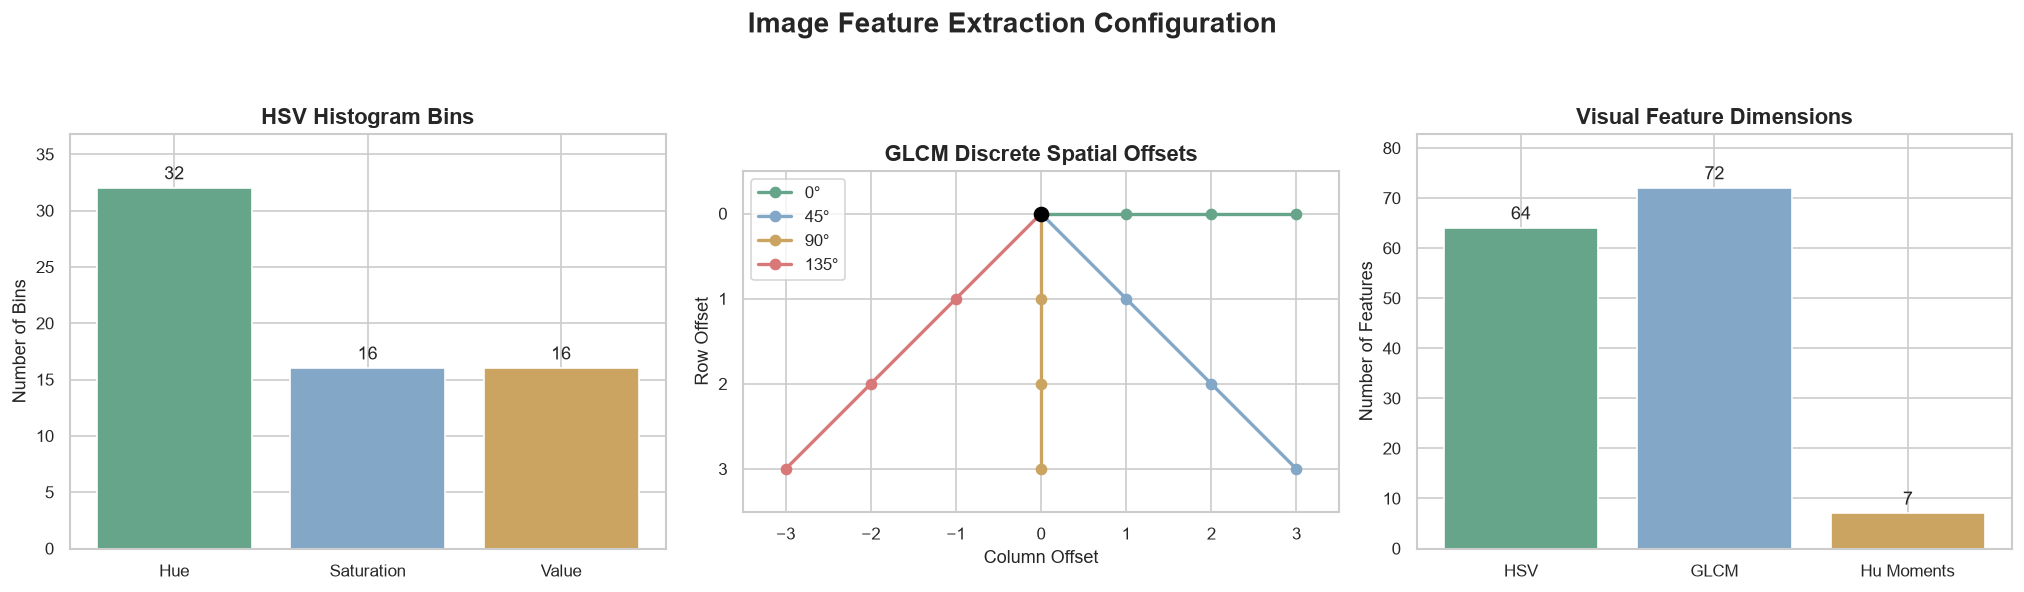


10. FINAL FEATURE CONFIGURATION SUMMARY
Total samples       : 104
HSV features        : 64
GLCM features       : 72
Hu Moments features : 7
Total dimensions    : 143
GLCM spatial offsets: 12
Expected matrix     : (104, 143)
Normalization       : StandardScaler
Normalization scope : Reference Dataset Only

[PASS] HSV configuration initialized.
[PASS] GLCM configuration initialized.
[PASS] All 12 GLCM spatial offsets are unique.
[PASS] Hu Moments configuration initialized.
[PASS] Feature dimensions are consistent.
[PASS] Feature names are unique.
[PASS] Saved GLCM offsets verified successfully.
[PASS] Feature configuration saved successfully.

[INFO] No feature vectors have been extracted.
[INFO] Normalization parameters have not been fitted.

Feature extraction configuration completed!

Next cell: Cell 7 - HSV Histogram Extraction


In [6]:
# ==================================================
# FEATURE EXTRACTION CONFIGURATION
# ==================================================

print("FEATURE EXTRACTION CONFIGURATION")
print("=" * 60)


# ==================================================
# 1. GENERAL CONFIGURATION
# ==================================================

FEATURE_EXTRACTION_VERSION = "1.0"

USE_FOREGROUND_MASK = True
FEATURE_DTYPE = np.float64
EPSILON = 1e-12

EXPECTED_IMAGE_SHAPE = (
    TARGET_HEIGHT,
    TARGET_WIDTH,
    3
)

EXPECTED_MASK_SHAPE = (
    TARGET_HEIGHT,
    TARGET_WIDTH
)

assert len(df_image_validated) > 0

assert df_image_validated["technical_valid"].all()

assert USE_FOREGROUND_MASK is True

print("\n1. GENERAL CONFIGURATION")

print(f"Total samples : {len(df_image_validated)}")
print(f"Image shape   : {EXPECTED_IMAGE_SHAPE}")
print(f"Mask shape    : {EXPECTED_MASK_SHAPE}")
print(f"Feature dtype : {FEATURE_DTYPE.__name__}")
print(f"Use mask      : {USE_FOREGROUND_MASK}")


# ==================================================
# 2. HSV HISTOGRAM CONFIGURATION
# ==================================================

HSV_H_BINS = 32
HSV_S_BINS = 16
HSV_V_BINS = 16

HSV_BINS = (
    HSV_H_BINS,
    HSV_S_BINS,
    HSV_V_BINS
)

# OpenCV HSV value ranges
HSV_H_RANGE = (0, 180)
HSV_S_RANGE = (0, 256)
HSV_V_RANGE = (0, 256)

HSV_RANGES = (
    HSV_H_RANGE,
    HSV_S_RANGE,
    HSV_V_RANGE
)

HSV_CHANNELS = [
    "Hue",
    "Saturation",
    "Value"
]

HSV_HISTOGRAM_TYPE = "Independent Channel Histograms"

HSV_NORMALIZATION = "L1 Per Channel"

HSV_USE_MASK = True

# Total HSV feature dimension
HSV_FEATURE_DIM = sum(HSV_BINS)

# Generate HSV feature names
HSV_FEATURE_NAMES = [

    f"hsv_h_{i:02d}"

    for i in range(HSV_H_BINS)

] + [

    f"hsv_s_{i:02d}"

    for i in range(HSV_S_BINS)

] + [

    f"hsv_v_{i:02d}"

    for i in range(HSV_V_BINS)
]

assert len(HSV_FEATURE_NAMES) == HSV_FEATURE_DIM

print("\n2. HSV HISTOGRAM CONFIGURATION")

hsv_config_df = pd.DataFrame({

    "Channel": HSV_CHANNELS,

    "Number of Bins": HSV_BINS,

    "Value Range": [
        "[0, 180)",
        "[0, 256)",
        "[0, 256)"
    ],

    "Normalization": [
        "L1",
        "L1",
        "L1"
    ]
})

display(hsv_config_df)

print(f"HSV feature dimension : {HSV_FEATURE_DIM}")
print(f"Background excluded   : {HSV_USE_MASK}")


# ==================================================
# 3. GLCM CONFIGURATION
# ==================================================

# Grayscale quantization
GLCM_LEVELS = 32

# Discrete pixel-step distances
GLCM_DISTANCES = [1, 2, 3]

# Angular directions in degrees
GLCM_ANGLES_DEGREES = [
    0,
    45,
    90,
    135
]

# Angular directions in radians
GLCM_ANGLES = [

    float(np.deg2rad(angle))

    for angle in GLCM_ANGLES_DEGREES
]

# Texture properties
GLCM_PROPERTIES = [

    "contrast",

    "dissimilarity",

    "homogeneity",

    "energy",

    "correlation",

    "ASM"
]

GLCM_SYMMETRIC = True

GLCM_NORMED = True

GLCM_USE_MASK = True

GLCM_MASK_POLICY = (
    "Both pixels must belong to foreground"
)

GLCM_AGGREGATION = "None"

GLCM_FEATURE_ORDER = (
    "Property -> Distance -> Angle"
)

GLCM_EMPTY_PAIR_POLICY = "Raise Error"

GLCM_QUANTIZATION_METHOD = (
    "Uniform quantization from 256 to 32 gray levels"
)

# Total GLCM feature dimension
GLCM_FEATURE_DIM = (

    len(GLCM_DISTANCES)

    * len(GLCM_ANGLES_DEGREES)

    * len(GLCM_PROPERTIES)
)

# Generate GLCM feature names
GLCM_FEATURE_NAMES = [

    f"glcm_{prop.lower()}_d{distance}_a{angle}"

    for prop in GLCM_PROPERTIES

    for distance in GLCM_DISTANCES

    for angle in GLCM_ANGLES_DEGREES
]

assert len(GLCM_FEATURE_NAMES) == GLCM_FEATURE_DIM

print("\n3. GLCM CONFIGURATION")

glcm_config_df = pd.DataFrame({

    "Parameter": [

        "Gray levels",
        "Distances",
        "Angles",
        "Properties",
        "Symmetric matrix",
        "Normalized matrix",
        "Foreground masking",
        "Aggregation",
        "Feature dimension"
    ],

    "Value": [

        GLCM_LEVELS,

        str(GLCM_DISTANCES),

        str(GLCM_ANGLES_DEGREES),

        ", ".join(GLCM_PROPERTIES),

        GLCM_SYMMETRIC,

        GLCM_NORMED,

        GLCM_USE_MASK,

        GLCM_AGGREGATION,

        GLCM_FEATURE_DIM
    ]
})

display(glcm_config_df)


# ==================================================
# 4. GENERATE GLCM SPATIAL OFFSETS (REVISED)
# ==================================================

# Discrete directional vectors
# Format: (row direction, column direction)
#
# Image coordinate system:
# Row increases downward.
# Column increases to the right.

GLCM_DIRECTION_OFFSETS = {

    0: (0, 1),

    45: (1, 1),

    90: (1, 0),

    135: (1, -1)
}

GLCM_OFFSET_CONVENTION = (
    "Discrete directional steps (Chebyshev distance)"
)

glcm_offset_records = []

for distance in GLCM_DISTANCES:

    for angle_degree in GLCM_ANGLES_DEGREES:

        row_direction, col_direction = (
            GLCM_DIRECTION_OFFSETS[angle_degree]
        )

        # Calculate discrete spatial offsets
        row_offset = distance * row_direction

        col_offset = distance * col_direction

        glcm_offset_records.append({

            "Distance": distance,

            "Angle (Degree)": angle_degree,

            "Row Offset": row_offset,

            "Column Offset": col_offset
        })


glcm_offsets_df = pd.DataFrame(
    glcm_offset_records
)


# Validate non-zero spatial offsets
assert not (

    glcm_offsets_df["Row Offset"].eq(0)

    & glcm_offsets_df["Column Offset"].eq(0)

).any(), "Zero spatial offset detected."


# Validate unique spatial offsets
assert not glcm_offsets_df[
    ["Row Offset", "Column Offset"]
].duplicated().any(), "Duplicate spatial offsets detected."


# Validate number of spatial configurations
assert len(glcm_offsets_df) == (

    len(GLCM_DISTANCES)

    * len(GLCM_ANGLES_DEGREES)

), "Invalid number of GLCM configurations."


# Validate discrete step distances
for offset in glcm_offset_records:

    actual_step_distance = max(

        abs(offset["Row Offset"]),

        abs(offset["Column Offset"])
    )

    assert actual_step_distance == offset["Distance"]


# Create offset lookup for future masked GLCM extraction
GLCM_OFFSET_LOOKUP = {

    (
        offset["Distance"],
        offset["Angle (Degree)"]
    ): (

        offset["Row Offset"],

        offset["Column Offset"]
    )

    for offset in glcm_offset_records
}


print("\n4. GLCM SPATIAL OFFSETS")

display(glcm_offsets_df)

print(
    f"Total spatial configurations: "
    f"{len(glcm_offsets_df)}"
)

print(
    f"Offset convention: "
    f"{GLCM_OFFSET_CONVENTION}"
)

print("[PASS] All spatial offsets are unique.")


# ==================================================
# 5. HU MOMENTS CONFIGURATION
# ==================================================

HU_MOMENTS_COUNT = 7

HU_USE_BINARY_MASK = True

HU_APPLY_LOG_TRANSFORM = True

HU_LOG_EPSILON = 1e-30

HU_ZERO_POLICY = "Preserve Zero"

HU_INCLUDE_PETIOLE = True

HU_LOG_TRANSFORM_METHOD = (
    "-sign(hu) * log10(max(abs(hu), epsilon))"
)

HU_FEATURE_DIM = HU_MOMENTS_COUNT

HU_FEATURE_NAMES = [

    f"hu_moment_{i}"

    for i in range(
        1,
        HU_MOMENTS_COUNT + 1
    )
]

assert len(HU_FEATURE_NAMES) == HU_FEATURE_DIM

print("\n5. HU MOMENTS CONFIGURATION")

hu_config_df = pd.DataFrame({

    "Parameter": [

        "Number of moments",
        "Binary mask input",
        "Log transformation",
        "Log epsilon",
        "Zero handling",
        "Include petiole",
        "Feature dimension"
    ],

    "Value": [

        HU_MOMENTS_COUNT,

        HU_USE_BINARY_MASK,

        HU_APPLY_LOG_TRANSFORM,

        str(HU_LOG_EPSILON),

        HU_ZERO_POLICY,

        HU_INCLUDE_PETIOLE,

        HU_FEATURE_DIM
    ]
})

display(hu_config_df)


# ==================================================
# 6. FEATURE NORMALIZATION CONFIGURATION
# ==================================================

FEATURE_NORMALIZATION_METHOD = "StandardScaler"

NORMALIZE_FEATURE_GROUPS = True

BALANCE_FEATURE_GROUP_DIMENSIONS = True

NORMALIZATION_FIT_SCOPE = "Reference Dataset Only"

APPLY_FINAL_L2_NORMALIZATION = False

# Initial equal weights for visual feature groups
FEATURE_GROUP_WEIGHTS = {

    "HSV": 1 / 3,

    "GLCM": 1 / 3,

    "Hu Moments": 1 / 3
}

FEATURE_GROUP_DIMENSIONS = {

    "HSV": HSV_FEATURE_DIM,

    "GLCM": GLCM_FEATURE_DIM,

    "Hu Moments": HU_FEATURE_DIM
}

# Dimension-aware feature scaling
FEATURE_GROUP_SCALE_FACTORS = {

    group: float(

        np.sqrt(

            FEATURE_GROUP_WEIGHTS[group]

            / FEATURE_GROUP_DIMENSIONS[group]
        )
    )

    for group in FEATURE_GROUP_DIMENSIONS
}

assert np.isclose(

    sum(FEATURE_GROUP_WEIGHTS.values()),

    1.0
)

normalization_config_df = pd.DataFrame([

    {

        "Feature Group": group,

        "Dimension": FEATURE_GROUP_DIMENSIONS[group],

        "Weight": FEATURE_GROUP_WEIGHTS[group],

        "Scale Factor": (
            FEATURE_GROUP_SCALE_FACTORS[group]
        )
    }

    for group in FEATURE_GROUP_DIMENSIONS
])

print("\n6. FEATURE NORMALIZATION CONFIGURATION")

print(f"Normalization : {FEATURE_NORMALIZATION_METHOD}")
print(f"Fit scope     : {NORMALIZATION_FIT_SCOPE}")
print(f"Group balance : {BALANCE_FEATURE_GROUP_DIMENSIONS}")

display(normalization_config_df)


# ==================================================
# 7. COMBINED VISUAL FEATURE CONFIGURATION
# ==================================================

FEATURE_CONCATENATION_ORDER = [

    "HSV",

    "GLCM",

    "Hu Moments"
]

TOTAL_VISUAL_FEATURE_DIM = (

    HSV_FEATURE_DIM

    + GLCM_FEATURE_DIM

    + HU_FEATURE_DIM
)

COMBINED_FEATURE_NAMES = (

    HSV_FEATURE_NAMES

    + GLCM_FEATURE_NAMES

    + HU_FEATURE_NAMES
)

assert len(COMBINED_FEATURE_NAMES) == (
    TOTAL_VISUAL_FEATURE_DIM
)

assert len(set(COMBINED_FEATURE_NAMES)) == (
    TOTAL_VISUAL_FEATURE_DIM
)

# Feature group ranges
# Start index inclusive, end index exclusive
FEATURE_GROUP_SLICES = {

    "HSV": (

        0,

        HSV_FEATURE_DIM
    ),

    "GLCM": (

        HSV_FEATURE_DIM,

        HSV_FEATURE_DIM + GLCM_FEATURE_DIM
    ),

    "Hu Moments": (

        HSV_FEATURE_DIM + GLCM_FEATURE_DIM,

        TOTAL_VISUAL_FEATURE_DIM
    )
}

feature_dimension_df = pd.DataFrame({

    "Feature Group": [

        "HSV Histogram",

        "GLCM",

        "Hu Moments",

        "Combined Visual Features"
    ],

    "Feature Type": [

        "Color",

        "Texture",

        "Shape",

        "Color + Texture + Shape"
    ],

    "Dimension": [

        HSV_FEATURE_DIM,

        GLCM_FEATURE_DIM,

        HU_FEATURE_DIM,

        TOTAL_VISUAL_FEATURE_DIM
    ]
})

print("\n7. FEATURE DIMENSION SUMMARY")

display(feature_dimension_df)

print(
    f"Total visual feature dimension: "
    f"{TOTAL_VISUAL_FEATURE_DIM}"
)


# ==================================================
# 8. CREATE FEATURE CONFIGURATION
# ==================================================

feature_config = {

    "version": FEATURE_EXTRACTION_VERSION,

    "dataset": {

        "total_samples": int(
            len(df_image_validated)
        ),

        "total_classes": int(
            df_image_validated["kelas"].nunique()
        ),

        "image_size": [
            TARGET_WIDTH,
            TARGET_HEIGHT
        ],

        "image_mode": "RGB",

        "mask_values": [0, 255],

        "use_foreground_mask": True
    },

    "hsv": {

        "enabled": True,

        "color_space": "HSV",

        "histogram_type": HSV_HISTOGRAM_TYPE,

        "h_bins": HSV_H_BINS,

        "s_bins": HSV_S_BINS,

        "v_bins": HSV_V_BINS,

        "h_range": list(HSV_H_RANGE),

        "s_range": list(HSV_S_RANGE),

        "v_range": list(HSV_V_RANGE),

        "normalization": HSV_NORMALIZATION,

        "use_mask": HSV_USE_MASK,

        "feature_dimension": HSV_FEATURE_DIM
    },

    "glcm": {

        "enabled": True,

        "levels": GLCM_LEVELS,

        "quantization_method": (
            GLCM_QUANTIZATION_METHOD
        ),

        "distances": GLCM_DISTANCES,

        "angles_degrees": GLCM_ANGLES_DEGREES,

        "angles_radians": GLCM_ANGLES,

        "properties": GLCM_PROPERTIES,

        "symmetric": GLCM_SYMMETRIC,

        "normalized": GLCM_NORMED,

        "use_mask": GLCM_USE_MASK,

        "mask_policy": GLCM_MASK_POLICY,

        "aggregation": GLCM_AGGREGATION,

        "feature_order": GLCM_FEATURE_ORDER,

        "empty_pair_policy": GLCM_EMPTY_PAIR_POLICY,

        "offset_convention": GLCM_OFFSET_CONVENTION,

        "offsets": glcm_offsets_df.to_dict(
            orient="records"
        ),

        "feature_dimension": GLCM_FEATURE_DIM
    },

    "hu_moments": {

        "enabled": True,

        "number_of_moments": HU_MOMENTS_COUNT,

        "binary_mask": HU_USE_BINARY_MASK,

        "log_transform": HU_APPLY_LOG_TRANSFORM,

        "log_transform_method": HU_LOG_TRANSFORM_METHOD,

        "epsilon": HU_LOG_EPSILON,

        "zero_policy": HU_ZERO_POLICY,

        "include_petiole_if_present": HU_INCLUDE_PETIOLE,

        "feature_dimension": HU_FEATURE_DIM
    },

    "normalization": {

        "method": FEATURE_NORMALIZATION_METHOD,

        "normalize_groups": NORMALIZE_FEATURE_GROUPS,

        "balance_group_dimensions": (
            BALANCE_FEATURE_GROUP_DIMENSIONS
        ),

        "fit_scope": NORMALIZATION_FIT_SCOPE,

        "group_weights": FEATURE_GROUP_WEIGHTS,

        "group_scale_factors": (
            FEATURE_GROUP_SCALE_FACTORS
        ),

        "final_l2_normalization": (
            APPLY_FINAL_L2_NORMALIZATION
        ),

        "scalers_fitted": False
    },

    "concatenation": {

        "method": "Feature Concatenation",

        "order": FEATURE_CONCATENATION_ORDER,

        "group_slices": FEATURE_GROUP_SLICES,

        "total_dimension": TOTAL_VISUAL_FEATURE_DIM
    },

    "similarity_matching": {

        "image_method": "Euclidean Distance",

        "text_method": "Cosine Similarity",

        "multimodal_fusion": (
            "Weighted Score Late Fusion"
        )
    },

    "feature_dtype": FEATURE_DTYPE.__name__,

    "random_state": RANDOM_STATE,

    "feature_extraction_completed": False
}


# ==================================================
# 9. SAVE FEATURE CONFIGURATION
# ==================================================

with open(

    FEATURE_CONFIG_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        feature_config,

        file,

        indent=4,

        ensure_ascii=False
    )

print("\n8. FEATURE CONFIGURATION SAVED")

print(FEATURE_CONFIG_PATH)


# ==================================================
# 10. SAVE FEATURE NAMES
# ==================================================

feature_names_config = {

    "hsv": HSV_FEATURE_NAMES,

    "glcm": GLCM_FEATURE_NAMES,

    "hu_moments": HU_FEATURE_NAMES,

    "combined": COMBINED_FEATURE_NAMES,

    "group_slices": FEATURE_GROUP_SLICES
}

with open(

    FEATURE_NAMES_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        feature_names_config,

        file,

        indent=4
    )

feature_names_df = pd.DataFrame({

    "feature_index": np.arange(
        TOTAL_VISUAL_FEATURE_DIM
    ),

    "feature_name": COMBINED_FEATURE_NAMES,

    "feature_group": (

        ["HSV"] * HSV_FEATURE_DIM

        + ["GLCM"] * GLCM_FEATURE_DIM

        + ["Hu Moments"] * HU_FEATURE_DIM
    )
})

print("\n9. FEATURE NAME PREVIEW")

display(feature_names_df.head(10))

display(feature_names_df.tail(10))


# ==================================================
# 11. SAVE CONFIGURATION REPORTS
# ==================================================

configuration_reports = {

    "83_hsv_feature_configuration.csv":
        hsv_config_df,

    "84_glcm_feature_configuration.csv":
        glcm_config_df,

    "85_glcm_spatial_offsets.csv":
        glcm_offsets_df,

    "86_hu_moments_configuration.csv":
        hu_config_df,

    "87_visual_feature_dimension_summary.csv":
        feature_dimension_df,

    "88_visual_feature_names.csv":
        feature_names_df,

    "89_feature_normalization_configuration.csv":
        normalization_config_df
}

for filename, dataframe in (
    configuration_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )


# ==================================================
# 12. VISUALIZE FEATURE CONFIGURATION
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(17, 5)
)

# --------------------------------------------------
# A. HSV histogram configuration
# --------------------------------------------------

axes[0].bar(

    ["Hue", "Saturation", "Value"],

    HSV_BINS,

    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

axes[0].set_title(
    "HSV Histogram Bins"
)

axes[0].set_ylabel(
    "Number of Bins"
)

axes[0].set_ylim(
    0,
    max(HSV_BINS) * 1.15
)

for container in axes[0].containers:

    axes[0].bar_label(
        container,
        padding=3
    )


# --------------------------------------------------
# B. GLCM spatial directions
# --------------------------------------------------

direction_colors = [

    "#66A58A",

    "#83A7C7",

    "#CBA461",

    "#D97878"
]

for angle, color in zip(

    GLCM_ANGLES_DEGREES,

    direction_colors
):

    subset = glcm_offsets_df[

        glcm_offsets_df["Angle (Degree)"]
        .eq(angle)
    ]

    x = subset["Column Offset"].to_numpy()

    y = subset["Row Offset"].to_numpy()

    axes[1].plot(

        np.r_[0, x],

        np.r_[0, y],

        marker="o",

        color=color,

        linewidth=2,

        label=f"{angle}°"
    )

axes[1].scatter(

    0,

    0,

    color="black",

    s=70,

    zorder=5
)

axes[1].set_title(
    "GLCM Discrete Spatial Offsets"
)

axes[1].set_xlabel(
    "Column Offset"
)

axes[1].set_ylabel(
    "Row Offset"
)

axes[1].set_xlim(-3.5, 3.5)

axes[1].set_ylim(-0.5, 3.5)

axes[1].set_xticks(
    np.arange(-3, 4)
)

axes[1].set_yticks(
    np.arange(0, 4)
)

axes[1].invert_yaxis()

axes[1].set_aspect("equal")

axes[1].legend()


# --------------------------------------------------
# C. Visual feature dimensions
# --------------------------------------------------

axes[2].bar(

    ["HSV", "GLCM", "Hu Moments"],

    [
        HSV_FEATURE_DIM,
        GLCM_FEATURE_DIM,
        HU_FEATURE_DIM
    ],

    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

axes[2].set_title(
    "Visual Feature Dimensions"
)

axes[2].set_ylabel(
    "Number of Features"
)

axes[2].set_ylim(

    0,

    max(
        HSV_FEATURE_DIM,
        GLCM_FEATURE_DIM,
        HU_FEATURE_DIM
    ) * 1.15
)

for container in axes[2].containers:

    axes[2].bar_label(
        container,
        padding=3
    )

fig.suptitle(

    "Image Feature Extraction Configuration",

    fontsize=17,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.93]
)

plt.savefig(

    FEATURE_FIGURES_DIR /

    "28_visual_feature_configuration.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ==================================================
# 13. VERIFY SAVED CONFIGURATION
# ==================================================

with open(

    FEATURE_CONFIG_PATH,

    "r",

    encoding="utf-8"

) as file:

    saved_feature_config = json.load(file)

with open(

    FEATURE_NAMES_PATH,

    "r",

    encoding="utf-8"

) as file:

    saved_feature_names = json.load(file)


# Verify feature dimensions
assert (

    saved_feature_config["concatenation"]
    ["total_dimension"]

    == TOTAL_VISUAL_FEATURE_DIM
)

assert (

    saved_feature_names["combined"]

    == COMBINED_FEATURE_NAMES
)

assert len(COMBINED_FEATURE_NAMES) == 143

assert HSV_FEATURE_DIM == 64

assert GLCM_FEATURE_DIM == 72

assert HU_FEATURE_DIM == 7


# Verify saved GLCM offset configuration
saved_glcm_offsets = pd.DataFrame(

    saved_feature_config["glcm"]["offsets"]
)

assert len(saved_glcm_offsets) == 12

assert not saved_glcm_offsets[
    ["Row Offset", "Column Offset"]
].duplicated().any()

assert saved_glcm_offsets.equals(
    glcm_offsets_df
)

assert (

    saved_feature_config["glcm"]["offset_convention"]

    == GLCM_OFFSET_CONVENTION
)


# ==================================================
# 14. FINAL FEATURE CONFIGURATION SUMMARY
# ==================================================

print("\n10. FINAL FEATURE CONFIGURATION SUMMARY")

print("=" * 60)

print(
    f"Total samples       : "
    f"{len(df_image_validated)}"
)

print(
    f"HSV features        : "
    f"{HSV_FEATURE_DIM}"
)

print(
    f"GLCM features       : "
    f"{GLCM_FEATURE_DIM}"
)

print(
    f"Hu Moments features : "
    f"{HU_FEATURE_DIM}"
)

print(
    f"Total dimensions    : "
    f"{TOTAL_VISUAL_FEATURE_DIM}"
)

print(
    f"GLCM spatial offsets: "
    f"{len(glcm_offsets_df)}"
)

print(
    f"Expected matrix     : "
    f"({len(df_image_validated)}, "
    f"{TOTAL_VISUAL_FEATURE_DIM})"
)

print(
    f"Normalization       : "
    f"{FEATURE_NORMALIZATION_METHOD}"
)

print(
    f"Normalization scope : "
    f"{NORMALIZATION_FIT_SCOPE}"
)

print("\n[PASS] HSV configuration initialized.")

print("[PASS] GLCM configuration initialized.")

print("[PASS] All 12 GLCM spatial offsets are unique.")

print("[PASS] Hu Moments configuration initialized.")

print("[PASS] Feature dimensions are consistent.")

print("[PASS] Feature names are unique.")

print("[PASS] Saved GLCM offsets verified successfully.")

print("[PASS] Feature configuration saved successfully.")

print("\n[INFO] No feature vectors have been extracted.")

print("[INFO] Normalization parameters have not been fitted.")

print("\nFeature extraction configuration completed!")

print("\nNext cell: Cell 7 - HSV Histogram Extraction")

In [7]:
# ==================================================
# HSV HISTOGRAM EXTRACTION
# ==================================================

print("HSV HISTOGRAM EXTRACTION")
print("=" * 60)


# ==================================================
# 1. VALIDATE HSV CONFIGURATION
# ==================================================

assert HSV_FEATURE_DIM == 64

assert HSV_FEATURE_DIM == sum(HSV_BINS)

assert len(HSV_FEATURE_NAMES) == HSV_FEATURE_DIM

assert HSV_USE_MASK is True

assert HSV_NORMALIZATION == "L1 Per Channel"

assert df_image_validated["technical_valid"].all()

print("\n1. HSV CONFIGURATION")

print(f"Hue bins        : {HSV_H_BINS}")
print(f"Saturation bins : {HSV_S_BINS}")
print(f"Value bins      : {HSV_V_BINS}")
print(f"Total features  : {HSV_FEATURE_DIM}")
print(f"Normalization   : {HSV_NORMALIZATION}")
print(f"Foreground mask : {HSV_USE_MASK}")


# ==================================================
# 2. DEFINE HSV HISTOGRAM EXTRACTION FUNCTION
# ==================================================

def extract_hsv_features(
    rgb_image,
    binary_mask,
    return_details=False
):

    """
    Extract foreground-based HSV histogram features.

    Parameters
    ----------
    rgb_image : numpy.ndarray
        RGB image with shape (H, W, 3).

    binary_mask : numpy.ndarray
        Binary mask with values 0 and 255.

    return_details : bool
        Return additional histogram information.

    Returns
    -------
    feature_vector : numpy.ndarray
        HSV feature vector with 64 dimensions.
    """

    # --------------------------------------------------
    # A. Validate input RGB image
    # --------------------------------------------------

    if rgb_image.shape != EXPECTED_IMAGE_SHAPE:

        raise ValueError(
            f"Invalid RGB image shape: {rgb_image.shape}"
        )

    if rgb_image.dtype != np.uint8:

        raise ValueError(
            "RGB image must have uint8 data type."
        )

    # --------------------------------------------------
    # B. Validate binary mask
    # --------------------------------------------------

    if binary_mask.shape != EXPECTED_MASK_SHAPE:

        raise ValueError(
            f"Invalid binary mask shape: "
            f"{binary_mask.shape}"
        )

    if binary_mask.dtype != np.uint8:

        raise ValueError(
            "Binary mask must have uint8 data type."
        )

    if set(np.unique(binary_mask).tolist()) != {0, 255}:

        raise ValueError(
            "Binary mask must contain 0 and 255."
        )

    foreground = binary_mask == 255

    foreground_pixels = int(
        foreground.sum()
    )

    if foreground_pixels < MIN_FOREGROUND_PIXELS:

        raise ValueError(
            "Insufficient foreground pixels."
        )

    # --------------------------------------------------
    # C. Convert RGB image into HSV color space
    # --------------------------------------------------

    hsv_image = cv2.cvtColor(

        rgb_image,

        cv2.COLOR_RGB2HSV
    )

    # --------------------------------------------------
    # D. Calculate independent channel histograms
    # --------------------------------------------------

    raw_histograms = {}

    normalized_histograms = {}

    histogram_bin_edges = {}

    channel_keys = ["H", "S", "V"]

    for channel_index, channel_key in enumerate(
        channel_keys
    ):

        number_of_bins = HSV_BINS[channel_index]

        channel_range = HSV_RANGES[channel_index]

        histogram = cv2.calcHist(

            [hsv_image],

            [channel_index],

            binary_mask,

            [number_of_bins],

            list(channel_range)
        )

        histogram = (

            histogram.flatten()

            .astype(FEATURE_DTYPE)
        )

        histogram_sum = float(
            histogram.sum()
        )

        if histogram_sum <= 0:

            raise ValueError(
                f"Empty histogram in channel {channel_key}"
            )

        # Every foreground pixel must be counted once
        if not np.isclose(

            histogram_sum,

            foreground_pixels,

            rtol=0,

            atol=1e-6
        ):

            raise ValueError(
                f"Histogram count mismatch "
                f"in channel {channel_key}"
            )

        raw_histograms[channel_key] = (
            histogram.copy()
        )

        # ----------------------------------------------
        # E. L1 normalization per channel
        # ----------------------------------------------

        normalized_histogram = (

            histogram / histogram_sum
        )

        normalized_histograms[channel_key] = (
            normalized_histogram
        )

        histogram_bin_edges[channel_key] = np.linspace(

            channel_range[0],

            channel_range[1],

            number_of_bins + 1
        )

    # --------------------------------------------------
    # F. Concatenate H, S, and V histograms
    # --------------------------------------------------

    feature_vector = np.concatenate([

        normalized_histograms["H"],

        normalized_histograms["S"],

        normalized_histograms["V"]

    ]).astype(FEATURE_DTYPE)

    # --------------------------------------------------
    # G. Validate final HSV feature vector
    # --------------------------------------------------

    if feature_vector.shape != (HSV_FEATURE_DIM,):

        raise ValueError(

            f"Invalid HSV feature dimension: "
            f"{feature_vector.shape}"
        )

    if not np.isfinite(feature_vector).all():

        raise ValueError(
            "NaN or infinite HSV features detected."
        )

    if np.any(feature_vector < 0):

        raise ValueError(
            "Negative histogram values detected."
        )

    for channel_key, histogram in (
        normalized_histograms.items()
    ):

        if not np.isclose(

            histogram.sum(),

            1.0,

            atol=1e-8
        ):

            raise ValueError(
                f"L1 normalization failed "
                f"for channel {channel_key}"
            )

    # Three independently normalized histograms
    if not np.isclose(
        feature_vector.sum(),
        3.0,
        atol=1e-8
    ):

        raise ValueError(
            "Unexpected combined HSV feature sum."
        )

    # --------------------------------------------------
    # H. Return extraction results
    # --------------------------------------------------

    if return_details:

        return feature_vector, {

            "hsv_image": hsv_image,

            "raw_histograms": raw_histograms,

            "normalized_histograms": (
                normalized_histograms
            ),

            "histogram_bin_edges": (
                histogram_bin_edges
            ),

            "foreground_pixels": foreground_pixels,

            "foreground_ratio": (
                foreground_pixels
                / binary_mask.size
            ),

            "feature_dimension": len(feature_vector),

            "feature_sum": float(
                feature_vector.sum()
            )
        }

    return feature_vector


print("\n[OK] HSV feature extraction function initialized.")


# ==================================================
# 3. SELECT REPRESENTATIVE TEST SAMPLES
# ==================================================

hsv_test_records = []

for plant_class, group in (
    df_image_validated.groupby("kelas")
):

    # Prefer samples that passed initial checks
    passed_group = group[

        group["validation_status"]

        .eq("Passed Initial Check")
    ]

    available_group = (

        passed_group

        if not passed_group.empty

        else group
    )

    selected_sample = available_group.sample(

        n=1,

        random_state=RANDOM_STATE

    ).iloc[0]

    hsv_test_records.append(
        selected_sample
    )


hsv_test_samples = pd.DataFrame(

    hsv_test_records

).reset_index(drop=True)


print("\n2. REPRESENTATIVE TEST SAMPLES")

display(

    hsv_test_samples[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ]
)

print(f"Test samples: {len(hsv_test_samples)}")


# ==================================================
# 4. EXTRACT HSV FEATURES FROM TEST SAMPLES
# ==================================================

hsv_test_vectors = []

hsv_test_results = []

hsv_test_details = {}

print("\n3. EXTRACTING HSV FEATURES")

for _, row in tqdm(

    hsv_test_samples.iterrows(),

    total=len(hsv_test_samples),

    desc="Extracting HSV features"
):

    # Load processed RGB image and mask
    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]

    binary_mask = data["binary_mask"]

    # Measure extraction time
    start_time = time.perf_counter()

    feature_vector, details = extract_hsv_features(

        rgb_image,

        binary_mask,

        return_details=True
    )

    extraction_time_ms = (

        time.perf_counter() - start_time

    ) * 1000

    hue_histogram = (
        details["normalized_histograms"]["H"]
    )

    saturation_histogram = (
        details["normalized_histograms"]["S"]
    )

    value_histogram = (
        details["normalized_histograms"]["V"]
    )

    hsv_test_vectors.append(
        feature_vector
    )

    hsv_test_details[row["sample_id"]] = details

    hsv_test_results.append({

        "sample_id": row["sample_id"],

        "nama_file": row["nama_file"],

        "kelas": row["kelas"],

        "tampilan_daun": row["tampilan_daun"],

        "validation_status": row["validation_status"],

        "foreground_pixels": (
            details["foreground_pixels"]
        ),

        "foreground_ratio": (
            details["foreground_ratio"]
        ),

        "hue_dimension": len(hue_histogram),

        "saturation_dimension": len(
            saturation_histogram
        ),

        "value_dimension": len(value_histogram),

        "total_dimension": len(feature_vector),

        "hue_histogram_sum": float(
            hue_histogram.sum()
        ),

        "saturation_histogram_sum": float(
            saturation_histogram.sum()
        ),

        "value_histogram_sum": float(
            value_histogram.sum()
        ),

        "combined_feature_sum": float(
            feature_vector.sum()
        ),

        "minimum_feature_value": float(
            feature_vector.min()
        ),

        "maximum_feature_value": float(
            feature_vector.max()
        ),

        "nonzero_features": int(
            np.count_nonzero(feature_vector)
        ),

        "contains_nan": bool(
            np.isnan(feature_vector).any()
        ),

        "contains_inf": bool(
            np.isinf(feature_vector).any()
        ),

        "extraction_time_ms": float(
            extraction_time_ms
        ),

        "extraction_status": "Success"
    })


hsv_test_features = np.vstack(

    hsv_test_vectors

).astype(FEATURE_DTYPE)


hsv_test_results_df = pd.DataFrame(
    hsv_test_results
)


# ==================================================
# 5. VALIDATE HSV FEATURE MATRIX
# ==================================================

assert hsv_test_features.shape == (

    len(hsv_test_samples),

    HSV_FEATURE_DIM
)

assert np.isfinite(hsv_test_features).all()

assert np.all(hsv_test_features >= 0)

assert np.all(hsv_test_features <= 1)

# Define HSV feature group slices
HSV_H_SLICE = slice(
    0,
    HSV_H_BINS
)

HSV_S_SLICE = slice(

    HSV_H_BINS,

    HSV_H_BINS + HSV_S_BINS
)

HSV_V_SLICE = slice(

    HSV_H_BINS + HSV_S_BINS,

    HSV_FEATURE_DIM
)

# Validate L1 normalization for each channel
assert np.allclose(

    hsv_test_features[:, HSV_H_SLICE].sum(axis=1),

    1.0
)

assert np.allclose(

    hsv_test_features[:, HSV_S_SLICE].sum(axis=1),

    1.0
)

assert np.allclose(

    hsv_test_features[:, HSV_V_SLICE].sum(axis=1),

    1.0
)

assert np.allclose(

    hsv_test_features.sum(axis=1),

    3.0
)


print("\n4. HSV FEATURE MATRIX VALIDATION")

print(f"Matrix shape : {hsv_test_features.shape}")

print(f"Data type    : {hsv_test_features.dtype}")

print("[PASS] Feature dimensions are consistent.")

print("[PASS] No NaN or infinite values detected.")

print("[PASS] All histogram values are non-negative.")

print("[PASS] Each channel histogram sums to 1.")

print("[PASS] Combined feature vector sums to 3.")


# ==================================================
# 6. VERIFY BACKGROUND EXCLUSION
# ==================================================

print("\n5. BACKGROUND EXCLUSION TEST")

background_test_records = []

for _, row in hsv_test_samples.iterrows():

    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]

    binary_mask = data["binary_mask"]

    # Extract original HSV features
    original_features = extract_hsv_features(

        rgb_image,

        binary_mask
    )

    # Modify only background pixels
    modified_image = rgb_image.copy()

    modified_image[binary_mask == 0] = (

        255, 0, 255
    )

    # Extract features again
    modified_features = extract_hsv_features(

        modified_image,

        binary_mask
    )

    max_difference = float(

        np.abs(

            original_features - modified_features

        ).max()
    )

    background_excluded = bool(

        np.allclose(

            original_features,

            modified_features,

            rtol=0,

            atol=1e-12
        )
    )

    background_test_records.append({

        "sample_id": row["sample_id"],

        "kelas": row["kelas"],

        "maximum_difference": max_difference,

        "background_excluded": background_excluded
    })


hsv_background_test_df = pd.DataFrame(
    background_test_records
)

display(hsv_background_test_df)

assert hsv_background_test_df[
    "background_excluded"
].all(), "Background pixels affect HSV features."

print(
    "[PASS] Background changes do not affect "
    "the extracted HSV features."
)


# ==================================================
# 7. SYNTHETIC HSV CORRECTNESS TEST
# ==================================================

print("\n6. SYNTHETIC HSV CORRECTNESS TEST")

# Create a pure green RGB image
synthetic_rgb = np.zeros(

    EXPECTED_IMAGE_SHAPE,

    dtype=np.uint8
)

synthetic_rgb[:, :] = (0, 255, 0)

# Create a rectangular foreground mask
synthetic_mask = np.zeros(

    EXPECTED_MASK_SHAPE,

    dtype=np.uint8
)

synthetic_mask[

    TARGET_HEIGHT // 4 : 3 * TARGET_HEIGHT // 4,

    TARGET_WIDTH // 4 : 3 * TARGET_WIDTH // 4

] = 255


synthetic_features, synthetic_details = (
    extract_hsv_features(

        synthetic_rgb,

        synthetic_mask,

        return_details=True
    )
)

# Pure green in OpenCV HSV:
# H = 60, S = 255, V = 255

expected_hue_bin = int(

    60 * HSV_H_BINS / 180
)

expected_saturation_bin = int(

    255 * HSV_S_BINS / 256
)

expected_value_bin = int(

    255 * HSV_V_BINS / 256
)

synthetic_test_df = pd.DataFrame({

    "Channel": ["Hue", "Saturation", "Value"],

    "Expected Bin": [

        expected_hue_bin,

        expected_saturation_bin,

        expected_value_bin
    ],

    "Actual Bin": [

        int(np.argmax(

            synthetic_details[
                "normalized_histograms"
            ]["H"]

        )),

        int(np.argmax(

            synthetic_details[
                "normalized_histograms"
            ]["S"]

        )),

        int(np.argmax(

            synthetic_details[
                "normalized_histograms"
            ]["V"]

        ))
    ]
})

synthetic_test_df["Passed"] = (

    synthetic_test_df["Expected Bin"]

    == synthetic_test_df["Actual Bin"]
)

display(synthetic_test_df)

assert synthetic_test_df["Passed"].all()

assert np.count_nonzero(synthetic_features) == 3

print("[PASS] Synthetic HSV histogram test passed.")


# ==================================================
# 8. DISPLAY EXTRACTED FEATURE RESULTS
# ==================================================

print("\n7. HSV FEATURE EXTRACTION RESULTS")

display(

    hsv_test_results_df[
        [
            "nama_file",
            "kelas",
            "foreground_pixels",
            "hue_dimension",
            "saturation_dimension",
            "value_dimension",
            "total_dimension",
            "nonzero_features",
            "extraction_status"
        ]
    ]
)


print("\n8. HSV HISTOGRAM NORMALIZATION RESULTS")

display(

    hsv_test_results_df[
        [
            "kelas",
            "hue_histogram_sum",
            "saturation_histogram_sum",
            "value_histogram_sum",
            "combined_feature_sum",
            "contains_nan",
            "contains_inf"
        ]
    ]
)


# ==================================================
# 9. CREATE HSV FEATURE DATAFRAME
# ==================================================

hsv_test_feature_df = pd.DataFrame(

    hsv_test_features,

    columns=HSV_FEATURE_NAMES
)

hsv_test_feature_df.insert(

    0,

    "kelas",

    hsv_test_samples["kelas"].to_numpy()
)

hsv_test_feature_df.insert(

    0,

    "sample_id",

    hsv_test_samples["sample_id"].to_numpy()
)

print("\n9. HSV FEATURE VECTOR PREVIEW")

display(

    hsv_test_feature_df.round(6)
)


# ==================================================
# 10. ANALYZE DOMINANT HSV BINS
# ==================================================

dominant_hsv_records = []

for _, row in hsv_test_samples.iterrows():

    details = hsv_test_details[
        row["sample_id"]
    ]

    record = {

        "sample_id": row["sample_id"],

        "kelas": row["kelas"]
    }

    for channel_key in ["H", "S", "V"]:

        histogram = details[
            "normalized_histograms"
        ][channel_key]

        bin_edges = details[
            "histogram_bin_edges"
        ][channel_key]

        dominant_bin = int(
            np.argmax(histogram)
        )

        record[
            f"dominant_{channel_key}_bin"
        ] = dominant_bin

        record[
            f"dominant_{channel_key}_lower"
        ] = float(
            bin_edges[dominant_bin]
        )

        record[
            f"dominant_{channel_key}_upper"
        ] = float(
            bin_edges[dominant_bin + 1]
        )

        record[
            f"dominant_{channel_key}_frequency"
        ] = float(
            histogram[dominant_bin]
        )

    dominant_hsv_records.append(record)


dominant_hsv_df = pd.DataFrame(
    dominant_hsv_records
)

print("\n10. DOMINANT HSV BINS")

display(dominant_hsv_df.round(4))


# ==================================================
# 11. CREATE HSV EXTRACTION SUMMARY
# ==================================================

hsv_extraction_summary_df = pd.DataFrame({

    "Indicator": [

        "Total test samples",

        "Total represented classes",

        "Hue feature dimension",

        "Saturation feature dimension",

        "Value feature dimension",

        "Total HSV feature dimension",

        "Successful feature extractions",

        "Failed feature extractions",

        "Samples containing NaN",

        "Samples containing infinity",

        "Background exclusion tests passed",

        "Synthetic channel tests passed",

        "Mean extraction time (ms)"
    ],

    "Result": [

        len(hsv_test_samples),

        hsv_test_samples["kelas"].nunique(),

        HSV_H_BINS,

        HSV_S_BINS,

        HSV_V_BINS,

        HSV_FEATURE_DIM,

        hsv_test_results_df[
            "extraction_status"
        ].eq("Success").sum(),

        hsv_test_results_df[
            "extraction_status"
        ].ne("Success").sum(),

        hsv_test_results_df[
            "contains_nan"
        ].sum(),

        hsv_test_results_df[
            "contains_inf"
        ].sum(),

        hsv_background_test_df[
            "background_excluded"
        ].sum(),

        synthetic_test_df[
            "Passed"
        ].sum(),

        round(

            hsv_test_results_df[
                "extraction_time_ms"
            ].mean(),

            4
        )
    ]
})

print("\n11. HSV EXTRACTION SUMMARY")

display(hsv_extraction_summary_df)


# ==================================================
# 12. SAVE HSV TEST REPORTS
# ==================================================

hsv_reports = {

    "90_hsv_test_extraction_details.csv":
        hsv_test_results_df,

    "91_hsv_test_feature_vectors.csv":
        hsv_test_feature_df,

    "92_hsv_background_exclusion_test.csv":
        hsv_background_test_df,

    "93_hsv_synthetic_correctness_test.csv":
        synthetic_test_df,

    "94_hsv_dominant_bins.csv":
        dominant_hsv_df,

    "95_hsv_extraction_summary.csv":
        hsv_extraction_summary_df
}

for filename, dataframe in hsv_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )


# ==================================================
# 13. FINAL HSV EXTRACTION VALIDATION
# ==================================================

assert len(hsv_test_samples) == (
    df_image_validated["kelas"].nunique()
)

assert hsv_test_results_df[
    "extraction_status"
].eq("Success").all()

assert hsv_test_results_df[
    "sample_id"
].is_unique

assert np.array_equal(

    hsv_test_results_df["sample_id"].to_numpy(),

    hsv_test_samples["sample_id"].to_numpy()
)

assert hsv_background_test_df[
    "background_excluded"
].all()

assert synthetic_test_df["Passed"].all()


# ==================================================
# 14. FINAL HSV EXTRACTION SUMMARY
# ==================================================

print("\n12. FINAL HSV EXTRACTION SUMMARY")

print("=" * 60)

print(f"Test samples      : {len(hsv_test_samples)}")

print(

    f"Represented classes: "
    f"{hsv_test_samples['kelas'].nunique()}"
)

print(f"Hue features      : {HSV_H_BINS}")

print(f"Saturation features: {HSV_S_BINS}")

print(f"Value features    : {HSV_V_BINS}")

print(f"Total HSV features: {HSV_FEATURE_DIM}")

print(f"Test matrix shape : {hsv_test_features.shape}")

print(

    f"Mean extraction time: "
    f"{hsv_test_results_df['extraction_time_ms'].mean():.4f} ms"
)

print("\n[PASS] HSV feature extraction successful.")

print("[PASS] All test samples have 64 features.")

print("[PASS] L1 normalization is consistent.")

print("[PASS] Background pixels are excluded.")

print("[PASS] Synthetic correctness test passed.")

print("[PASS] No NaN or infinite features detected.")

print("[PASS] Sample alignment is preserved.")

print("\n[INFO] Only representative samples were processed.")

print("[INFO] Full batch extraction will be performed in Cell 13.")

print("\nHSV histogram extraction function is ready!")

print("\nNext cell: Cell 8 - HSV Feature Visualization")

HSV HISTOGRAM EXTRACTION

1. HSV CONFIGURATION
Hue bins        : 32
Saturation bins : 16
Value bins      : 16
Total features  : 64
Normalization   : L1 Per Channel
Foreground mask : True

[OK] HSV feature extraction function initialized.

2. REPRESENTATIVE TEST SAMPLES


,sample_id,nama_file,kelas,tampilan_daun,validation_status
0,leaf_8f09fd62c7391c0d,mangkok 10.png,Mangkok,depan,Passed Initial Check
1,leaf_9c7d463a5bb1a561,daun salam 8.png,Salam,depan,Passed Initial Check
2,leaf_d9d0b97961feaeac,sambang darah 7.png,Sambang Darah,depan,Passed Initial Check
3,leaf_338b7ee25be7d52d,sirih 4.jpeg,Sirih,depan,Passed Initial Check
4,leaf_721244faca19b94f,tapak kuda 19.png,Tapak Kuda,belakang,Needs Review


Test samples: 5

3. EXTRACTING HSV FEATURES


Extracting HSV features:   0%|          | 0/5 [00:00<?, ?it/s]


4. HSV FEATURE MATRIX VALIDATION
Matrix shape : (5, 64)
Data type    : float64
[PASS] Feature dimensions are consistent.
[PASS] No NaN or infinite values detected.
[PASS] All histogram values are non-negative.
[PASS] Each channel histogram sums to 1.
[PASS] Combined feature vector sums to 3.

5. BACKGROUND EXCLUSION TEST


,sample_id,kelas,maximum_difference,background_excluded
0,leaf_8f09fd62c7391c0d,Mangkok,0.000000,True
1,leaf_9c7d463a5bb1a561,Salam,0.000000,True
2,leaf_d9d0b97961feaeac,Sambang Darah,0.000000,True
3,leaf_338b7ee25be7d52d,Sirih,0.000000,True
4,leaf_721244faca19b94f,Tapak Kuda,0.000000,True


... (9 outputs left out)

,sample_id,kelas,dominant_H_bin,dominant_H_lower,dominant_H_upper,dominant_H_frequency,dominant_S_bin,dominant_S_lower,dominant_S_upper,dominant_S_frequency,dominant_V_bin,dominant_V_lower,dominant_V_upper,dominant_V_frequency
0,leaf_8f09fd62c7391c0d,Mangkok,7,39.375000,45.000000,0.694100,15,240.000000,256.000000,0.185200,7,112.000000,128.000000,0.259100
1,leaf_9c7d463a5bb1a561,Salam,7,39.375000,45.000000,0.606100,15,240.000000,256.000000,0.279200,4,64.000000,80.000000,0.332800
2,leaf_d9d0b97961feaeac,Sambang Darah,8,45.000000,50.625000,0.465400,13,208.000000,224.000000,0.177500,5,80.000000,96.000000,0.377300
3,leaf_338b7ee25be7d52d,Sirih,8,45.000000,50.625000,0.712800,13,208.000000,224.000000,0.162600,7,112.000000,128.000000,0.232000
4,leaf_721244faca19b94f,Tapak Kuda,6,33.750000,39.375000,0.538100,9,144.000000,160.000000,0.260200,8,128.000000,144.000000,0.419900



11. HSV EXTRACTION SUMMARY


,Indicator,Result
0,Total test samples,5.000000
1,Total represented classes,5.000000
2,Hue feature dimension,32.000000
3,Saturation feature dimension,16.000000
4,Value feature dimension,16.000000
5,Total HSV feature dimension,64.000000
6,Successful feature extractions,5.000000
7,Failed feature extractions,0.000000
8,Samples containing NaN,0.000000
9,Samples containing infinity,0.000000



12. FINAL HSV EXTRACTION SUMMARY
Test samples      : 5
Represented classes: 5
Hue features      : 32
Saturation features: 16
Value features    : 16
Total HSV features: 64
Test matrix shape : (5, 64)
Mean extraction time: 1.6528 ms

[PASS] HSV feature extraction successful.
[PASS] All test samples have 64 features.
[PASS] L1 normalization is consistent.
[PASS] Background pixels are excluded.
[PASS] Synthetic correctness test passed.
[PASS] No NaN or infinite features detected.
[PASS] Sample alignment is preserved.

[INFO] Only representative samples were processed.
[INFO] Full batch extraction will be performed in Cell 13.

HSV histogram extraction function is ready!

Next cell: Cell 8 - HSV Feature Visualization


HSV FEATURE VISUALIZATION

1. HSV FEATURE INFORMATION
Total samples     : 5
Feature dimension : 64
Feature matrix    : (5, 64)
[PASS] HSV extraction results are valid.

2. HSV CHANNEL VISUALIZATION


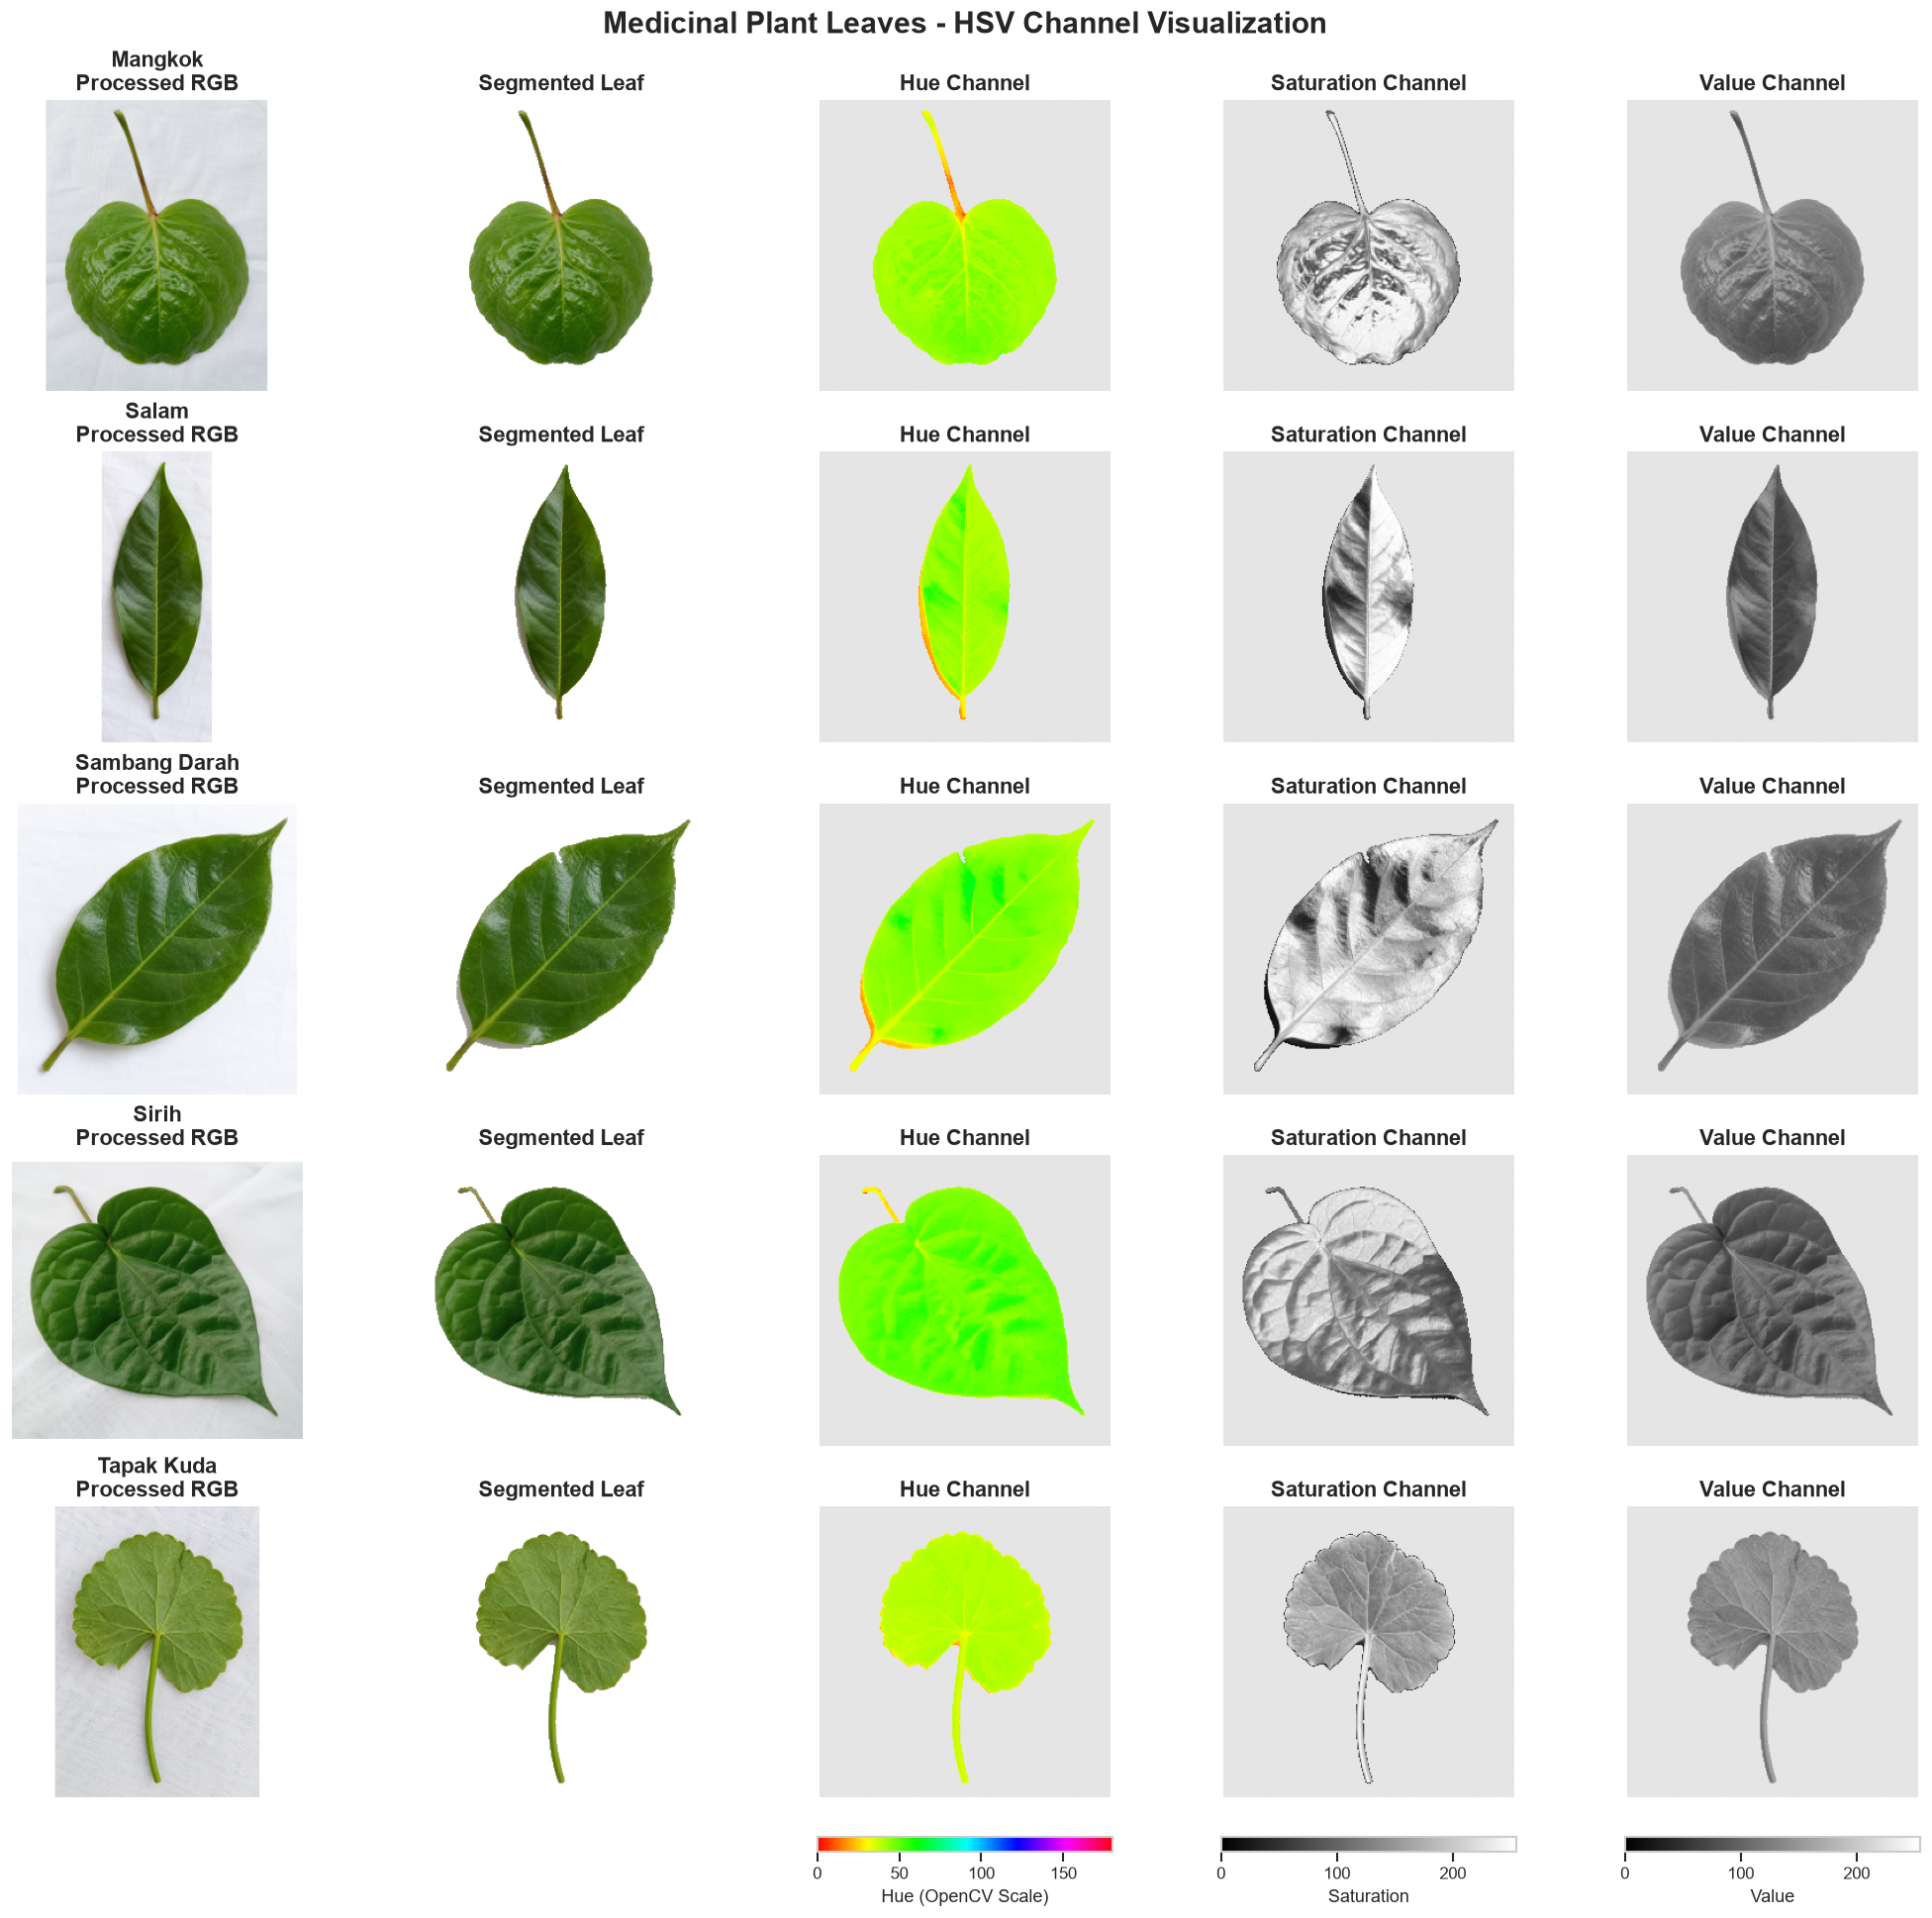


3. INDIVIDUAL HSV HISTOGRAMS


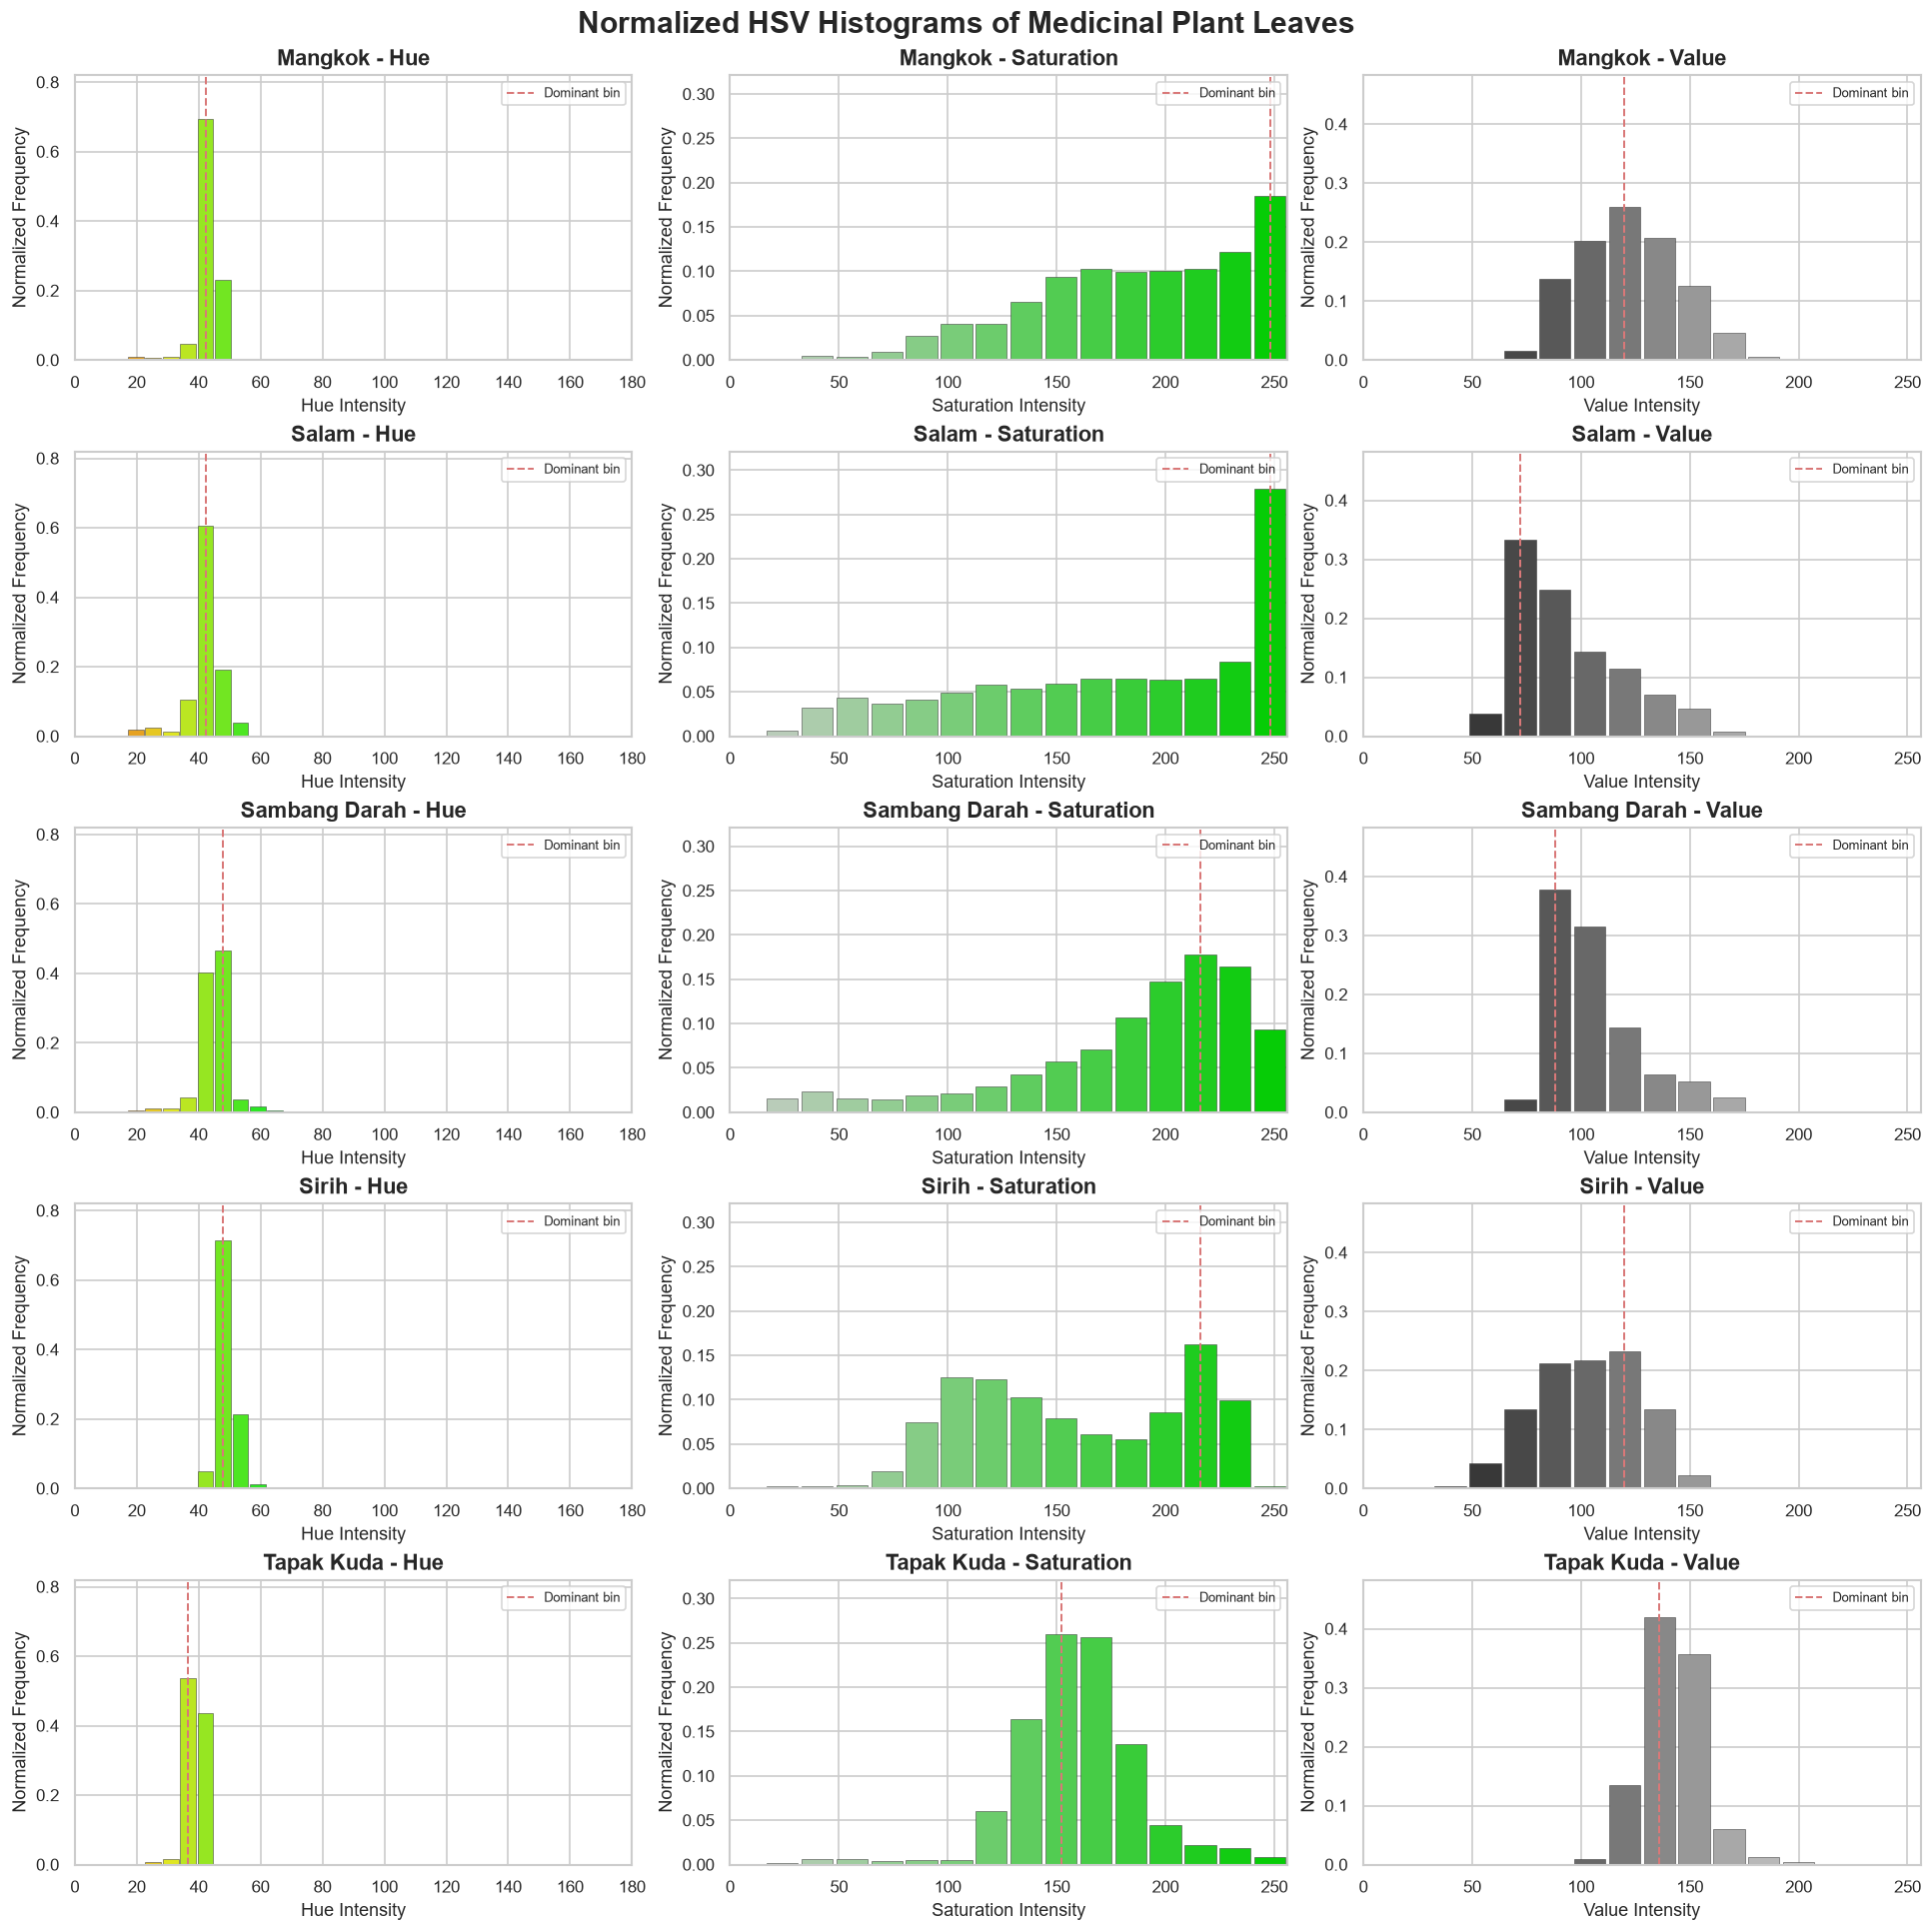


4. HSV HISTOGRAM COMPARISON


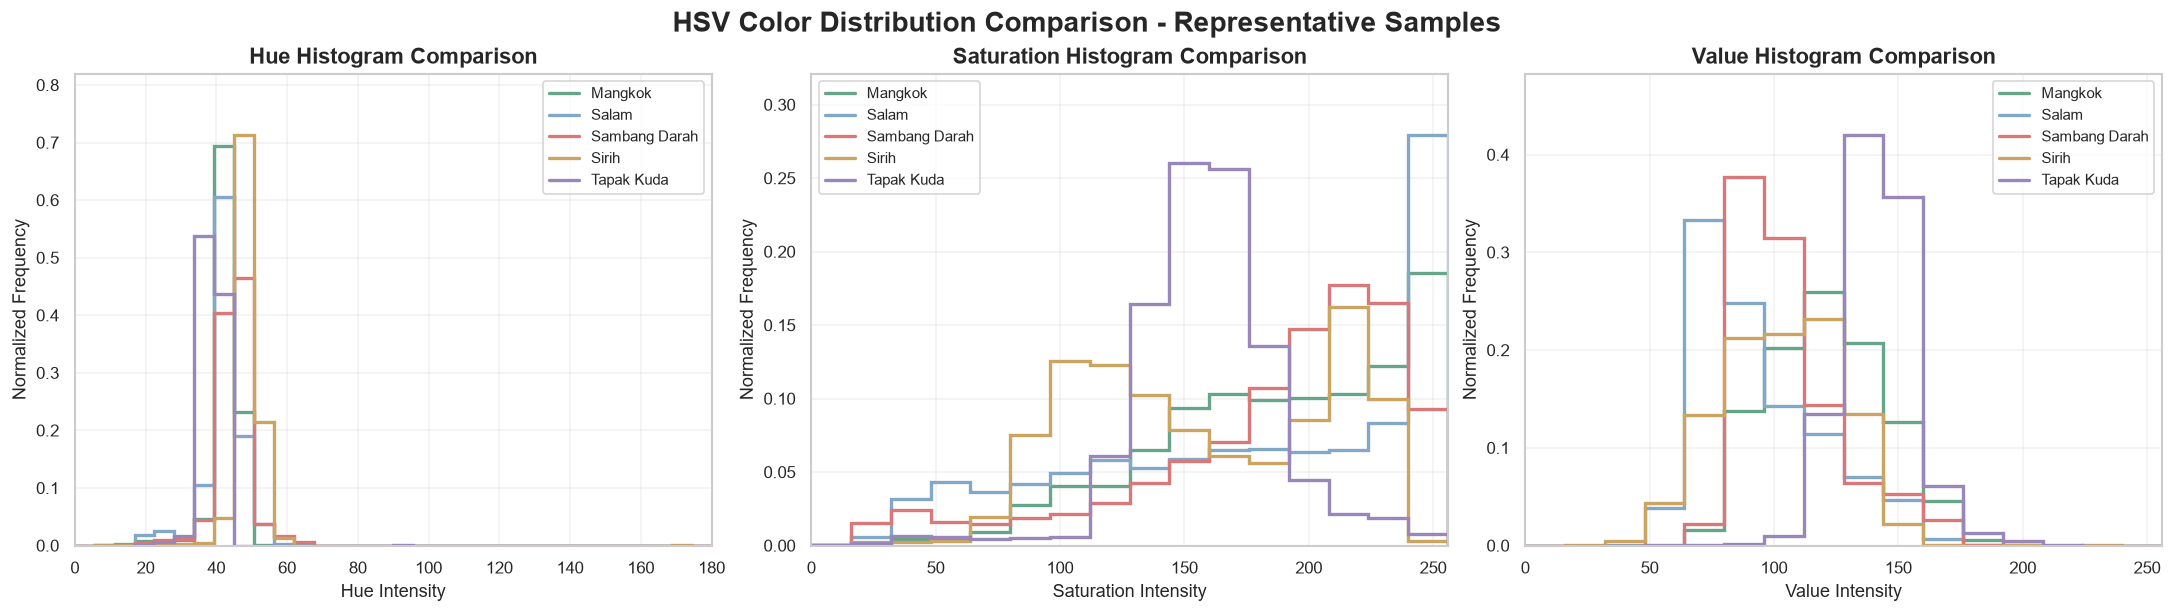


5. HSV FEATURE HEATMAP


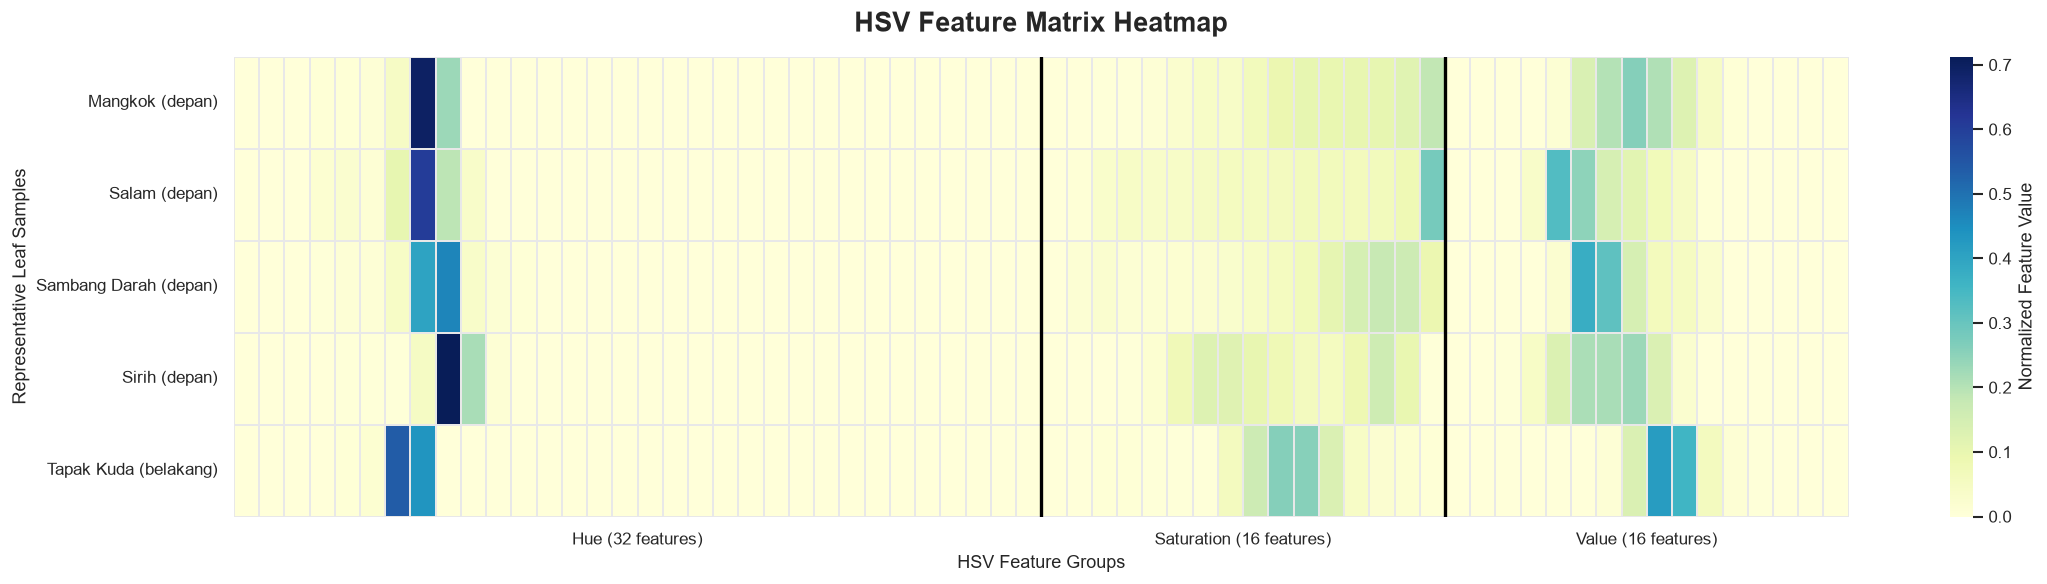


6. FOREGROUND HSV CHANNEL STATISTICS


,sample_id,nama_file,kelas,tampilan_daun,foreground_pixels,circular_mean_hue,hue_resultant_length,mean_saturation,std_saturation,mean_value,std_value,nonzero_hue_bins,nonzero_saturation_bins,nonzero_value_bins
0,leaf_8f09fd62c7391c0d,mangkok 10.png,Mangkok,depan,18806,42.460000,0.990700,187.281100,48.394500,121.017000,22.901200,9,16,9
1,leaf_9c7d463a5bb1a561,daun salam 8.png,Salam,depan,11306,41.828700,0.981500,176.599900,67.390900,93.651800,24.970500,10,15,10
2,leaf_d9d0b97961feaeac,sambang darah 7.png,Sambang Darah,depan,26494,44.574800,0.985400,185.312700,53.935100,105.254200,20.734100,9,16,8
3,leaf_338b7ee25be7d52d,sirih 4.jpeg,Sirih,depan,29003,48.589900,0.992700,158.075000,50.142500,102.667300,23.180400,11,16,12
4,leaf_721244faca19b94f,tapak kuda 19.png,Tapak Kuda,belakang,15480,38.803200,0.997100,158.551600,29.305500,141.609200,13.750500,6,16,11



7. DOMINANT HSV BIN COMPARISON


,kelas,dominant_H_bin,dominant_H_lower,dominant_H_upper,dominant_H_frequency,dominant_S_bin,dominant_S_frequency,dominant_V_bin,dominant_V_frequency
0,Mangkok,7,39.375000,45.000000,0.694100,15,0.185200,7,0.259100
1,Salam,7,39.375000,45.000000,0.606100,15,0.279200,4,0.332800
2,Sambang Darah,8,45.000000,50.625000,0.465400,13,0.177500,5,0.377300
3,Sirih,8,45.000000,50.625000,0.712800,13,0.162600,7,0.232000
4,Tapak Kuda,6,33.750000,39.375000,0.538100,9,0.260200,8,0.419900



8. HSV VISUALIZATION SUMMARY


,Indicator,Result
0,Total visualized samples,5.000000
1,Total represented classes,5.000000
2,Hue histogram bins,32.000000
3,Saturation histogram bins,16.000000
4,Value histogram bins,16.000000
5,Total HSV features,64.000000
6,Feature matrix rows,5.000000
7,Feature matrix columns,64.000000
8,Minimum feature value,0.000000
9,Maximum feature value,0.712788



9. GENERATED VISUALIZATIONS


,Visualization,Available,Size (KB)
0,29_hsv_channel_visualization.png,True,4976.120000
1,30_individual_hsv_histograms.png,True,805.250000
2,31_hsv_histogram_comparison.png,True,252.610000
3,32_hsv_feature_heatmap.png,True,158.650000



10. FINAL HSV VISUALIZATION SUMMARY
Visualized samples : 5
Represented classes: 5
Hue features       : 32
Saturation features: 16
Value features     : 16
Total HSV features : 64
Feature matrix     : (5, 64)
Generated figures  : 4

[PASS] HSV channels visualized successfully.
[PASS] Individual HSV histograms generated.
[PASS] Representative histogram comparison generated.
[PASS] HSV feature heatmap generated.
[PASS] Foreground HSV statistics calculated.
[PASS] All visualization files saved.

[INFO] Only representative samples were visualized.
[INFO] Original HSV features remain unchanged.
[INFO] Full dataset extraction will be performed in Cell 13.

HSV feature visualization completed successfully!

Next cell: Cell 9 - GLCM Feature Extraction


In [8]:
# ==================================================
# HSV FEATURE VISUALIZATION
# ==================================================

from matplotlib.colors import hsv_to_rgb

print("HSV FEATURE VISUALIZATION")
print("=" * 60)


# ==================================================
# 1. VALIDATE HSV EXTRACTION RESULTS
# ==================================================

assert len(hsv_test_samples) > 0

assert hsv_test_features.shape == (
    len(hsv_test_samples),
    HSV_FEATURE_DIM
)

assert np.isfinite(hsv_test_features).all()

assert len(hsv_test_details) == len(hsv_test_samples)

assert np.array_equal(
    hsv_test_results_df["sample_id"].to_numpy(),
    hsv_test_samples["sample_id"].to_numpy()
)

assert np.allclose(
    hsv_test_features[:, HSV_H_SLICE].sum(axis=1),
    1.0
)

assert np.allclose(
    hsv_test_features[:, HSV_S_SLICE].sum(axis=1),
    1.0
)

assert np.allclose(
    hsv_test_features[:, HSV_V_SLICE].sum(axis=1),
    1.0
)

print("\n1. HSV FEATURE INFORMATION")

print(f"Total samples     : {len(hsv_test_samples)}")
print(f"Feature dimension : {HSV_FEATURE_DIM}")
print(f"Feature matrix    : {hsv_test_features.shape}")

print("[PASS] HSV extraction results are valid.")


# ==================================================
# 2. VISUALIZATION CONFIGURATION
# ==================================================

HSV_CLASS_COLORS = {

    "Mangkok": "#66A58A",

    "Salam": "#83A7C7",

    "Sambang Darah": "#D97878",

    "Sirih": "#CBA461",

    "Tapak Kuda": "#9887B8"
}

HSV_CHANNEL_COLORS = {

    "H": "#66A58A",

    "S": "#83A7C7",

    "V": "#CBA461"
}

HSV_CHANNEL_TITLES = {

    "H": "Hue",

    "S": "Saturation",

    "V": "Value"
}

n_samples = len(hsv_test_samples)


# ==================================================
# 3. VISUALIZE RGB AND HSV CHANNELS
# ==================================================

print("\n2. HSV CHANNEL VISUALIZATION")

fig, axes = plt.subplots(

    n_samples,
    5,

    figsize=(17, 3.2 * n_samples),

    squeeze=False,

    constrained_layout=True
)

# Display masked background in neutral gray
hue_cmap = plt.get_cmap("hsv").copy()
hue_cmap.set_bad("#E5E5E5")

gray_cmap = plt.get_cmap("gray").copy()
gray_cmap.set_bad("#E5E5E5")

for i, (_, row) in enumerate(
    hsv_test_samples.iterrows()
):

    sample_id = row["sample_id"]

    # Load existing RGB image and binary mask
    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]
    binary_mask = data["binary_mask"]

    foreground = binary_mask == 255

    # Retrieve HSV image from Cell 7
    hsv_image = hsv_test_details[
        sample_id
    ]["hsv_image"]

    # Create segmented RGB for visualization
    segmented_rgb = np.full_like(
        rgb_image, 255
    )

    segmented_rgb[foreground] = (
        rgb_image[foreground]
    )

    # Mask background in each HSV channel
    hue_channel = np.ma.masked_where(

        ~foreground,

        hsv_image[:, :, 0]
    )

    saturation_channel = np.ma.masked_where(

        ~foreground,

        hsv_image[:, :, 1]
    )

    value_channel = np.ma.masked_where(

        ~foreground,

        hsv_image[:, :, 2]
    )

    # --------------------------------------------------
    # A. Processed RGB
    # --------------------------------------------------

    axes[i, 0].imshow(rgb_image)

    axes[i, 0].set_title(

        f"{row['kelas']}\nProcessed RGB"
    )

    # --------------------------------------------------
    # B. Segmented RGB
    # --------------------------------------------------

    axes[i, 1].imshow(segmented_rgb)

    axes[i, 1].set_title(
        "Segmented Leaf"
    )

    # --------------------------------------------------
    # C. Hue channel
    # --------------------------------------------------

    hue_plot = axes[i, 2].imshow(

        hue_channel,

        cmap=hue_cmap,

        vmin=0,

        vmax=180
    )

    axes[i, 2].set_title(
        "Hue Channel"
    )

    # --------------------------------------------------
    # D. Saturation channel
    # --------------------------------------------------

    saturation_plot = axes[i, 3].imshow(

        saturation_channel,

        cmap=gray_cmap,

        vmin=0,

        vmax=255
    )

    axes[i, 3].set_title(
        "Saturation Channel"
    )

    # --------------------------------------------------
    # E. Value channel
    # --------------------------------------------------

    value_plot = axes[i, 4].imshow(

        value_channel,

        cmap=gray_cmap,

        vmin=0,

        vmax=255
    )

    axes[i, 4].set_title(
        "Value Channel"
    )

    for ax in axes[i]:

        ax.axis("off")


# Add colorbars for HSV channels
fig.colorbar(

    hue_plot,

    ax=axes[:, 2].tolist(),

    orientation="horizontal",

    shrink=0.75,

    pad=0.02,

    label="Hue (OpenCV Scale)"
)

fig.colorbar(

    saturation_plot,

    ax=axes[:, 3].tolist(),

    orientation="horizontal",

    shrink=0.75,

    pad=0.02,

    label="Saturation"
)

fig.colorbar(

    value_plot,

    ax=axes[:, 4].tolist(),

    orientation="horizontal",

    shrink=0.75,

    pad=0.02,

    label="Value"
)

fig.suptitle(

    "Medicinal Plant Leaves - HSV Channel Visualization",

    fontsize=18,

    fontweight="bold"
)

plt.savefig(

    FEATURE_FIGURES_DIR /
    "29_hsv_channel_visualization.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 4. VISUALIZE INDIVIDUAL HSV HISTOGRAMS
# ==================================================

print("\n3. INDIVIDUAL HSV HISTOGRAMS")

fig, axes = plt.subplots(

    n_samples,

    3,

    figsize=(16, 3.2 * n_samples),

    squeeze=False,

    constrained_layout=True
)

channel_keys = ["H", "S", "V"]

# Use the same y-axis scale for samples of each channel
channel_maximum = {

    channel: max(

        details["normalized_histograms"][
            channel
        ].max()

        for details in hsv_test_details.values()
    )

    for channel in channel_keys
}

for i, (_, row) in enumerate(
    hsv_test_samples.iterrows()
):

    sample_id = row["sample_id"]

    details = hsv_test_details[sample_id]

    for j, channel_key in enumerate(
        channel_keys
    ):

        histogram = details[
            "normalized_histograms"
        ][channel_key]

        bin_edges = details[
            "histogram_bin_edges"
        ][channel_key]

        bin_centers = (

            bin_edges[:-1]

            + bin_edges[1:]

        ) / 2

        bin_widths = np.diff(
            bin_edges
        )

        # ----------------------------------------------
        # Define histogram bar colors
        # ----------------------------------------------

        if channel_key == "H":

            bar_colors = hsv_to_rgb(

                np.column_stack([

                    bin_centers / 180.0,

                    np.full(
                        len(bin_centers), 0.85
                    ),

                    np.full(
                        len(bin_centers), 0.90
                    )
                ])
            )

        elif channel_key == "S":

            bar_colors = hsv_to_rgb(

                np.column_stack([

                    np.full(
                        len(bin_centers), 1 / 3
                    ),

                    bin_centers / 255.0,

                    np.full(
                        len(bin_centers), 0.80
                    )
                ])
            )

        else:

            bar_colors = plt.cm.gray(
                bin_centers / 255.0
            )

        # ----------------------------------------------
        # Plot histogram
        # ----------------------------------------------

        axes[i, j].bar(

            bin_centers,

            histogram,

            width=bin_widths * 0.90,

            color=bar_colors,

            edgecolor="#333333",

            linewidth=0.3
        )

        # Highlight dominant bin
        dominant_bin = int(
            np.argmax(histogram)
        )

        axes[i, j].axvline(

            bin_centers[dominant_bin],

            color="#D97878",

            linestyle="--",

            linewidth=1.2,

            label="Dominant bin"
        )

        axes[i, j].set_title(

            f"{row['kelas']} - "
            f"{HSV_CHANNEL_TITLES[channel_key]}"
        )

        axes[i, j].set_xlabel(

            f"{HSV_CHANNEL_TITLES[channel_key]} "
            "Intensity"
        )

        axes[i, j].set_ylabel(
            "Normalized Frequency"
        )

        axes[i, j].set_xlim(

            bin_edges[0],

            bin_edges[-1]
        )

        axes[i, j].set_ylim(

            0,

            channel_maximum[channel_key] * 1.15
        )

        axes[i, j].legend(

            loc="upper right",

            fontsize=8
        )

fig.suptitle(

    "Normalized HSV Histograms of Medicinal Plant Leaves",

    fontsize=18,

    fontweight="bold"
)

plt.savefig(

    FEATURE_FIGURES_DIR /
    "30_individual_hsv_histograms.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 5. COMPARE HSV HISTOGRAMS ACROSS SAMPLES
# ==================================================

print("\n4. HSV HISTOGRAM COMPARISON")

fig, axes = plt.subplots(

    1,

    3,

    figsize=(18, 5),

    constrained_layout=True
)

for j, channel_key in enumerate(
    channel_keys
):

    for _, row in hsv_test_samples.iterrows():

        details = hsv_test_details[
            row["sample_id"]
        ]

        histogram = details[
            "normalized_histograms"
        ][channel_key]

        bin_edges = details[
            "histogram_bin_edges"
        ][channel_key]

        color = HSV_CLASS_COLORS.get(

            row["kelas"],

            "#777777"
        )

        axes[j].stairs(

            histogram,

            bin_edges,

            label=row["kelas"],

            color=color,

            linewidth=2
        )

    axes[j].set_title(

        f"{HSV_CHANNEL_TITLES[channel_key]} "
        "Histogram Comparison"
    )

    axes[j].set_xlabel(

        f"{HSV_CHANNEL_TITLES[channel_key]} "
        "Intensity"
    )

    axes[j].set_ylabel(
        "Normalized Frequency"
    )

    axes[j].set_xlim(

        HSV_RANGES[j][0],

        HSV_RANGES[j][1]
    )

    axes[j].set_ylim(

        0,

        channel_maximum[channel_key] * 1.15
    )

    axes[j].legend(fontsize=9)

    axes[j].grid(

        alpha=0.25
    )

fig.suptitle(

    "HSV Color Distribution Comparison - Representative Samples",

    fontsize=17,

    fontweight="bold"
)

plt.savefig(

    FEATURE_FIGURES_DIR /
    "31_hsv_histogram_comparison.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 6. VISUALIZE HSV FEATURE HEATMAP
# ==================================================

print("\n5. HSV FEATURE HEATMAP")

heatmap_labels = [

    f"{row['kelas']} ({row['tampilan_daun']})"

    for _, row in hsv_test_samples.iterrows()
]

fig, ax = plt.subplots(

    figsize=(19, 5)
)

sns.heatmap(

    hsv_test_features,

    cmap="YlGnBu",

    vmin=0,

    vmax=float(hsv_test_features.max()),

    linewidths=0.25,

    linecolor="#E8E8E8",

    xticklabels=False,

    yticklabels=heatmap_labels,

    cbar_kws={

        "label": "Normalized Feature Value"
    },

    ax=ax
)

# Separate Hue, Saturation, and Value features
ax.axvline(

    HSV_H_BINS,

    color="black",

    linewidth=2
)

ax.axvline(

    HSV_H_BINS + HSV_S_BINS,

    color="black",

    linewidth=2
)

# Feature group positions
group_centers = [

    HSV_H_BINS / 2,

    HSV_H_BINS + HSV_S_BINS / 2,

    HSV_H_BINS + HSV_S_BINS + HSV_V_BINS / 2
]

ax.set_xticks(group_centers)

ax.set_xticklabels(

    [
        f"Hue ({HSV_H_BINS} features)",

        f"Saturation ({HSV_S_BINS} features)",

        f"Value ({HSV_V_BINS} features)"
    ],

    rotation=0
)

ax.set_yticklabels(

    heatmap_labels,

    rotation=0
)

ax.set_title(

    "HSV Feature Matrix Heatmap",

    fontsize=16,

    fontweight="bold",

    pad=15
)

ax.set_xlabel(
    "HSV Feature Groups"
)

ax.set_ylabel(
    "Representative Leaf Samples"
)

plt.tight_layout()

plt.savefig(

    FEATURE_FIGURES_DIR /
    "32_hsv_feature_heatmap.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 7. ANALYZE FOREGROUND HSV CHANNEL STATISTICS
# ==================================================

print("\n6. FOREGROUND HSV CHANNEL STATISTICS")

hsv_statistics_records = []

for _, row in hsv_test_samples.iterrows():

    details = hsv_test_details[
        row["sample_id"]
    ]

    hsv_image = details["hsv_image"]

    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    foreground = (
        data["binary_mask"] == 255
    )

    foreground_hsv = hsv_image[
        foreground
    ].astype(np.float64)

    hue_values = foreground_hsv[:, 0]
    saturation_values = foreground_hsv[:, 1]
    value_values = foreground_hsv[:, 2]

    # Hue is circular: 0 and 179 are adjacent.
    # Calculate a circular mean instead of
    # a conventional arithmetic mean.

    hue_angles = (

        hue_values * 2 * np.pi / 180.0
    )

    mean_cos = np.cos(hue_angles).mean()
    mean_sin = np.sin(hue_angles).mean()

    hue_resultant_length = np.hypot(

        mean_cos,

        mean_sin
    )

    if hue_resultant_length > 1e-12:

        mean_hue_angle = (

            np.arctan2(mean_sin, mean_cos)

            % (2 * np.pi)
        )

        circular_mean_hue = (

            mean_hue_angle * 180.0 / (2 * np.pi)
        ) % 180.0

    else:

        circular_mean_hue = np.nan

    hsv_statistics_records.append({

        "sample_id": row["sample_id"],

        "nama_file": row["nama_file"],

        "kelas": row["kelas"],

        "tampilan_daun": row["tampilan_daun"],

        "foreground_pixels": int(
            foreground.sum()
        ),

        "circular_mean_hue": float(
            circular_mean_hue
        ),

        "hue_resultant_length": float(
            hue_resultant_length
        ),

        "mean_saturation": float(
            saturation_values.mean()
        ),

        "std_saturation": float(
            saturation_values.std()
        ),

        "mean_value": float(
            value_values.mean()
        ),

        "std_value": float(
            value_values.std()
        ),

        "nonzero_hue_bins": int(

            np.count_nonzero(

                details["normalized_histograms"]["H"]
            )
        ),

        "nonzero_saturation_bins": int(

            np.count_nonzero(

                details["normalized_histograms"]["S"]
            )
        ),

        "nonzero_value_bins": int(

            np.count_nonzero(

                details["normalized_histograms"]["V"]
            )
        )
    })

hsv_statistics_df = pd.DataFrame(
    hsv_statistics_records
)

display(hsv_statistics_df.round(4))


# ==================================================
# 8. DISPLAY DOMINANT HSV BINS
# ==================================================

print("\n7. DOMINANT HSV BIN COMPARISON")

dominant_hsv_comparison_df = dominant_hsv_df[

    [

        "kelas",

        "dominant_H_bin",

        "dominant_H_lower",

        "dominant_H_upper",

        "dominant_H_frequency",

        "dominant_S_bin",

        "dominant_S_frequency",

        "dominant_V_bin",

        "dominant_V_frequency"
    ]

].copy()

display(

    dominant_hsv_comparison_df.round(4)
)


# ==================================================
# 9. CREATE HSV VISUALIZATION SUMMARY
# ==================================================

hsv_visualization_summary_df = pd.DataFrame({

    "Indicator": [

        "Total visualized samples",

        "Total represented classes",

        "Hue histogram bins",

        "Saturation histogram bins",

        "Value histogram bins",

        "Total HSV features",

        "Feature matrix rows",

        "Feature matrix columns",

        "Minimum feature value",

        "Maximum feature value",

        "Mean nonzero features per sample",

        "Generated visualizations"
    ],

    "Result": [

        n_samples,

        hsv_test_samples["kelas"].nunique(),

        HSV_H_BINS,

        HSV_S_BINS,

        HSV_V_BINS,

        HSV_FEATURE_DIM,

        hsv_test_features.shape[0],

        hsv_test_features.shape[1],

        float(hsv_test_features.min()),

        float(hsv_test_features.max()),

        round(

            np.count_nonzero(

                hsv_test_features,

                axis=1

            ).mean(),

            4
        ),

        4
    ]
})

print("\n8. HSV VISUALIZATION SUMMARY")

display(hsv_visualization_summary_df)


# ==================================================
# 10. SAVE HSV VISUALIZATION REPORTS
# ==================================================

hsv_visualization_reports = {

    "96_hsv_foreground_channel_statistics.csv":
        hsv_statistics_df,

    "97_hsv_dominant_bin_comparison.csv":
        dominant_hsv_comparison_df,

    "98_hsv_visualization_summary.csv":
        hsv_visualization_summary_df
}

for filename, dataframe in (
    hsv_visualization_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )


# ==================================================
# 11. VALIDATE SAVED VISUALIZATIONS
# ==================================================

hsv_visualization_paths = [

    FEATURE_FIGURES_DIR /
    "29_hsv_channel_visualization.png",

    FEATURE_FIGURES_DIR /
    "30_individual_hsv_histograms.png",

    FEATURE_FIGURES_DIR /
    "31_hsv_histogram_comparison.png",

    FEATURE_FIGURES_DIR /
    "32_hsv_feature_heatmap.png"
]

hsv_visualization_validation_df = pd.DataFrame([

    {

        "Visualization": path.name,

        "Available": path.is_file(),

        "Size (KB)": (

            round(
                path.stat().st_size / 1024,
                2
            )

            if path.is_file()

            else 0
        )
    }

    for path in hsv_visualization_paths
])

print("\n9. GENERATED VISUALIZATIONS")

display(hsv_visualization_validation_df)

assert hsv_visualization_validation_df[
    "Available"
].all()

assert hsv_visualization_validation_df[
    "Size (KB)"
].gt(0).all()

assert np.array_equal(

    hsv_statistics_df["sample_id"].to_numpy(),

    hsv_test_samples["sample_id"].to_numpy()
)

hsv_visualization_validation_df.to_csv(

    METRICS_DIR /
    "99_hsv_visualization_artifact_validation.csv",

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 12. FINAL HSV VISUALIZATION SUMMARY
# ==================================================

print("\n10. FINAL HSV VISUALIZATION SUMMARY")

print("=" * 60)

print(f"Visualized samples : {n_samples}")

print(

    f"Represented classes: "
    f"{hsv_test_samples['kelas'].nunique()}"
)

print(f"Hue features       : {HSV_H_BINS}")
print(f"Saturation features: {HSV_S_BINS}")
print(f"Value features     : {HSV_V_BINS}")
print(f"Total HSV features : {HSV_FEATURE_DIM}")

print(f"Feature matrix     : {hsv_test_features.shape}")

print(

    f"Generated figures  : "
    f"{len(hsv_visualization_paths)}"
)

print("\n[PASS] HSV channels visualized successfully.")

print("[PASS] Individual HSV histograms generated.")

print("[PASS] Representative histogram comparison generated.")

print("[PASS] HSV feature heatmap generated.")

print("[PASS] Foreground HSV statistics calculated.")

print("[PASS] All visualization files saved.")

print("\n[INFO] Only representative samples were visualized.")

print("[INFO] Original HSV features remain unchanged.")

print("[INFO] Full dataset extraction will be performed in Cell 13.")

print("\nHSV feature visualization completed successfully!")

print("\nNext cell: Cell 9 - GLCM Feature Extraction")

In [9]:
# ==================================================
# GLCM FEATURE EXTRACTION
# ==================================================

print("GLCM FEATURE EXTRACTION")
print("=" * 60)


# ==================================================
# 1. VALIDATE GLCM CONFIGURATION
# ==================================================

assert GLCM_LEVELS == 32
assert GLCM_FEATURE_DIM == 72
assert len(GLCM_OFFSET_LOOKUP) == 12
assert len(set(GLCM_OFFSET_LOOKUP.values())) == 12
assert len(GLCM_FEATURE_NAMES) == GLCM_FEATURE_DIM
assert GLCM_USE_MASK is True
assert df_image_validated["technical_valid"].all()

print("\n1. GLCM CONFIGURATION")

print(f"Gray levels    : {GLCM_LEVELS}")
print(f"Distances      : {GLCM_DISTANCES}")
print(f"Angles         : {GLCM_ANGLES_DEGREES}")
print(f"Properties     : {GLCM_PROPERTIES}")
print(f"Spatial offsets: {len(GLCM_OFFSET_LOOKUP)}")
print(f"Feature size   : {GLCM_FEATURE_DIM}")
print(f"Symmetric      : {GLCM_SYMMETRIC}")
print(f"Normalized     : {GLCM_NORMED}")
print(f"Foreground mask: {GLCM_USE_MASK}")

display(glcm_offsets_df)


# ==================================================
# 2. DEFINE GRAYSCALE QUANTIZATION FUNCTION
# ==================================================

def quantize_grayscale(
    gray_image,
    levels=GLCM_LEVELS
):

    """
    Convert an 8-bit grayscale image into
    a fixed number of gray levels.
    """

    if gray_image.ndim != 2:

        raise ValueError(
            "Grayscale image must be two-dimensional."
        )

    if gray_image.dtype != np.uint8:

        raise ValueError(
            "Grayscale image must have uint8 data type."
        )

    if not 2 <= levels <= 256:

        raise ValueError(
            "Gray levels must be between 2 and 256."
        )

    # Uniform quantization
    quantized_image = (

        gray_image.astype(np.uint16)

        * levels

        // 256

    ).astype(np.uint8)

    assert quantized_image.min() >= 0
    assert quantized_image.max() < levels

    return quantized_image


print("\n[OK] Grayscale quantization function initialized.")


# ==================================================
# 3. DEFINE MASKED PIXEL PAIR COUNTING
# ==================================================

def masked_glcm_counts(
    quantized_image,
    foreground_mask,
    row_offset,
    col_offset,
    levels=GLCM_LEVELS
):

    """
    Count co-occurring gray-level pairs.

    Both pixels must be inside the foreground mask.
    """

    if quantized_image.ndim != 2:

        raise ValueError(
            "Quantized image must be two-dimensional."
        )

    if quantized_image.shape != foreground_mask.shape:

        raise ValueError(
            "Image and mask dimensions do not match."
        )

    if not np.issubdtype(
        quantized_image.dtype, np.integer
    ):

        raise ValueError(
            "Quantized image must contain integers."
        )

    if (
        quantized_image.min() < 0
        or quantized_image.max() >= levels
    ):

        raise ValueError(
            "Invalid quantized gray-level values."
        )

    if row_offset == 0 and col_offset == 0:

        raise ValueError(
            "Zero spatial offset is not allowed."
        )

    foreground_mask = foreground_mask.astype(bool)

    height, width = quantized_image.shape

    # Calculate valid overlapping image boundaries
    row_start = max(0, -row_offset)

    row_end = min(
        height,
        height - row_offset
    )

    col_start = max(0, -col_offset)

    col_end = min(
        width,
        width - col_offset
    )

    if (
        row_start >= row_end
        or col_start >= col_end
    ):

        raise ValueError(
            "Spatial offset exceeds image dimensions."
        )

    # Reference pixel region
    reference_slice = (

        slice(row_start, row_end),

        slice(col_start, col_end)
    )

    # Neighbor pixel region
    neighbor_slice = (

        slice(
            row_start + row_offset,
            row_end + row_offset
        ),

        slice(
            col_start + col_offset,
            col_end + col_offset
        )
    )

    reference_pixels = quantized_image[
        reference_slice
    ]

    neighbor_pixels = quantized_image[
        neighbor_slice
    ]

    reference_mask = foreground_mask[
        reference_slice
    ]

    neighbor_mask = foreground_mask[
        neighbor_slice
    ]

    # Both pixels must belong to the leaf
    valid_pairs = (

        reference_mask

        & neighbor_mask
    )

    valid_pair_count = int(
        valid_pairs.sum()
    )

    # Select valid gray-level pairs
    reference_values = reference_pixels[
        valid_pairs
    ].astype(np.int64)

    neighbor_values = neighbor_pixels[
        valid_pairs
    ].astype(np.int64)

    # Encode gray-level pairs
    pair_indices = (

        reference_values * levels

        + neighbor_values
    )

    # Count occurrences of each gray-level pair
    glcm_counts = np.bincount(

        pair_indices,

        minlength=levels * levels

    ).reshape(

        levels,
        levels
    )

    assert glcm_counts.sum() == valid_pair_count

    return glcm_counts, valid_pair_count


print("[OK] Masked pixel pair counting initialized.")


# ==================================================
# 4. DEFINE MASKED GLCM MATRIX FUNCTION
# ==================================================

def build_masked_glcm(
    quantized_image,
    binary_mask
):

    """
    Construct a masked GLCM tensor.

    Output shape:
    (gray_levels, gray_levels, distances, angles)
    """

    foreground_mask = binary_mask == 255

    number_of_distances = len(
        GLCM_DISTANCES
    )

    number_of_angles = len(
        GLCM_ANGLES_DEGREES
    )

    glcm_tensor = np.zeros(

        (
            GLCM_LEVELS,
            GLCM_LEVELS,
            number_of_distances,
            number_of_angles
        ),

        dtype=FEATURE_DTYPE
    )

    pair_count_records = []

    for distance_index, distance in enumerate(
        GLCM_DISTANCES
    ):

        for angle_index, angle in enumerate(
            GLCM_ANGLES_DEGREES
        ):

            # Use revised offsets from Cell 6
            row_offset, col_offset = (
                GLCM_OFFSET_LOOKUP[
                    (distance, angle)
                ]
            )

            counts, valid_pair_count = (
                masked_glcm_counts(

                    quantized_image,

                    foreground_mask,

                    row_offset,

                    col_offset,

                    GLCM_LEVELS
                )
            )

            if valid_pair_count == 0:

                raise ValueError(

                    f"No valid foreground pairs "
                    f"for distance={distance}, "
                    f"angle={angle}."
                )

            # Symmetric GLCM
            if GLCM_SYMMETRIC:

                counts = counts + counts.T

            matrix = counts.astype(
                FEATURE_DTYPE
            )

            # Normalize matrix into probabilities
            if GLCM_NORMED:

                matrix_sum = matrix.sum()

                if matrix_sum <= 0:

                    raise ValueError(
                        "Empty GLCM matrix."
                    )

                matrix = matrix / matrix_sum

            # Store matrix
            glcm_tensor[

                :,
                :,
                distance_index,
                angle_index

            ] = matrix

            pair_count_records.append({

                "distance": distance,

                "angle": angle,

                "row_offset": row_offset,

                "col_offset": col_offset,

                "valid_pixel_pairs": valid_pair_count,

                "matrix_sum": float(
                    matrix.sum()
                ),

                "nonzero_matrix_cells": int(
                    np.count_nonzero(matrix)
                ),

                "symmetric": bool(
                    np.allclose(matrix, matrix.T)
                )
            })

    return glcm_tensor, pd.DataFrame(
        pair_count_records
    )


print("[OK] Masked GLCM matrix function initialized.")


# ==================================================
# 5. DEFINE GLCM FEATURE EXTRACTION FUNCTION
# ==================================================

def extract_glcm_features(
    rgb_image,
    binary_mask,
    return_details=False
):

    """
    Extract 72 foreground-based GLCM texture features.

    Feature order:
    Property -> Distance -> Angle
    """

    # --------------------------------------------------
    # A. Validate input images
    # --------------------------------------------------

    if rgb_image.shape != EXPECTED_IMAGE_SHAPE:

        raise ValueError(
            f"Invalid RGB shape: {rgb_image.shape}"
        )

    if rgb_image.dtype != np.uint8:

        raise ValueError(
            "RGB image must have uint8 data type."
        )

    if binary_mask.shape != EXPECTED_MASK_SHAPE:

        raise ValueError(
            f"Invalid mask shape: {binary_mask.shape}"
        )

    if binary_mask.dtype != np.uint8:

        raise ValueError(
            "Binary mask must have uint8 data type."
        )

    if set(np.unique(binary_mask).tolist()) != {0, 255}:

        raise ValueError(
            "Binary mask must contain 0 and 255."
        )

    foreground_pixels = int(
        np.count_nonzero(binary_mask == 255)
    )

    if foreground_pixels < MIN_FOREGROUND_PIXELS:

        raise ValueError(
            "Insufficient foreground pixels."
        )

    # --------------------------------------------------
    # B. Convert RGB to grayscale
    # --------------------------------------------------

    gray_image = cv2.cvtColor(

        rgb_image,

        cv2.COLOR_RGB2GRAY
    )

    # --------------------------------------------------
    # C. Quantize grayscale into 32 levels
    # --------------------------------------------------

    quantized_image = quantize_grayscale(

        gray_image,

        GLCM_LEVELS
    )

    # --------------------------------------------------
    # D. Construct masked GLCM tensor
    # --------------------------------------------------

    glcm_tensor, pair_counts_df = (
        build_masked_glcm(

            quantized_image,

            binary_mask
        )
    )

    expected_glcm_shape = (

        GLCM_LEVELS,

        GLCM_LEVELS,

        len(GLCM_DISTANCES),

        len(GLCM_ANGLES_DEGREES)
    )

    assert glcm_tensor.shape == expected_glcm_shape

    assert np.isfinite(glcm_tensor).all()

    assert np.all(glcm_tensor >= 0)

    if GLCM_NORMED:

        assert np.allclose(

            glcm_tensor.sum(axis=(0, 1)),

            1.0
        )

    if GLCM_SYMMETRIC:

        assert np.allclose(

            glcm_tensor,

            glcm_tensor.swapaxes(0, 1)
        )

    # --------------------------------------------------
    # E. Calculate six GLCM texture properties
    # --------------------------------------------------

    property_matrices = {}

    feature_parts = []

    for property_name in GLCM_PROPERTIES:

        property_matrix = graycoprops(

            glcm_tensor,

            property_name
        ).astype(FEATURE_DTYPE)

        expected_property_shape = (

            len(GLCM_DISTANCES),

            len(GLCM_ANGLES_DEGREES)
        )

        assert property_matrix.shape == (
            expected_property_shape
        )

        property_matrices[property_name] = (
            property_matrix
        )

        # Distance -> Angle order
        feature_parts.append(

            property_matrix.ravel(order="C")
        )

    # --------------------------------------------------
    # F. Concatenate texture features
    # --------------------------------------------------

    feature_vector = np.concatenate(

        feature_parts

    ).astype(FEATURE_DTYPE)

    # --------------------------------------------------
    # G. Validate feature vector
    # --------------------------------------------------

    if feature_vector.shape != (GLCM_FEATURE_DIM,):

        raise ValueError(

            f"Invalid GLCM feature shape: "
            f"{feature_vector.shape}"
        )

    if not np.isfinite(feature_vector).all():

        raise ValueError(
            "NaN or infinite GLCM features detected."
        )

    # Validate mathematical feature relationships
    assert np.allclose(

        property_matrices["energy"] ** 2,

        property_matrices["ASM"],

        atol=1e-10
    )

    assert np.all(

        property_matrices["contrast"] >= 0
    )

    assert np.all(

        property_matrices["dissimilarity"] >= 0
    )

    assert np.all(

        np.abs(
            property_matrices["correlation"]
        ) <= 1 + 1e-8
    )

    # --------------------------------------------------
    # H. Return results
    # --------------------------------------------------

    if return_details:

        return feature_vector, {

            "gray_image": gray_image,

            "quantized_image": quantized_image,

            "glcm_tensor": glcm_tensor,

            "property_matrices": property_matrices,

            "pair_counts_df": pair_counts_df,

            "foreground_pixels": foreground_pixels,

            "foreground_ratio": (
                foreground_pixels / binary_mask.size
            ),

            "feature_dimension": len(
                feature_vector
            )
        }

    return feature_vector


print("\n[OK] GLCM feature extraction function initialized.")


# ==================================================
# 6. SELECT REPRESENTATIVE TEST SAMPLES
# ==================================================

# Use exactly the same samples as HSV extraction
glcm_test_samples = (

    hsv_test_samples.copy()

    .reset_index(drop=True)
)

assert np.array_equal(

    glcm_test_samples["sample_id"].to_numpy(),

    hsv_test_samples["sample_id"].to_numpy()
)

print("\n2. REPRESENTATIVE TEST SAMPLES")

display(

    glcm_test_samples[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ]
)


# ==================================================
# 7. EXTRACT GLCM FEATURES FROM TEST SAMPLES
# ==================================================

glcm_test_vectors = []

glcm_test_results = []

glcm_test_details = {}

glcm_test_pair_records = []

glcm_test_property_records = []

print("\n3. EXTRACTING GLCM FEATURES")

for _, row in tqdm(

    glcm_test_samples.iterrows(),

    total=len(glcm_test_samples),

    desc="Extracting GLCM features"
):

    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]
    binary_mask = data["binary_mask"]

    start_time = time.perf_counter()

    feature_vector, details = (
        extract_glcm_features(

            rgb_image,

            binary_mask,

            return_details=True
        )
    )

    extraction_time_ms = (

        time.perf_counter() - start_time

    ) * 1000

    glcm_test_vectors.append(
        feature_vector
    )

    glcm_test_details[
        row["sample_id"]
    ] = details

    pair_counts = details[
        "pair_counts_df"
    ].copy()

    pair_counts.insert(
        0, "kelas", row["kelas"]
    )

    pair_counts.insert(
        0, "sample_id", row["sample_id"]
    )

    glcm_test_pair_records.append(
        pair_counts
    )

    # Store every property, distance, and angle
    for property_name in GLCM_PROPERTIES:

        matrix = details[
            "property_matrices"
        ][property_name]

        for d_idx, distance in enumerate(
            GLCM_DISTANCES
        ):

            for a_idx, angle in enumerate(
                GLCM_ANGLES_DEGREES
            ):

                glcm_test_property_records.append({

                    "sample_id": row["sample_id"],

                    "kelas": row["kelas"],

                    "property": property_name,

                    "distance": distance,

                    "angle": angle,

                    "value": float(
                        matrix[d_idx, a_idx]
                    )
                })

    glcm_test_results.append({

        "sample_id": row["sample_id"],

        "nama_file": row["nama_file"],

        "kelas": row["kelas"],

        "tampilan_daun": row["tampilan_daun"],

        "validation_status": row["validation_status"],

        "foreground_pixels": (
            details["foreground_pixels"]
        ),

        "foreground_ratio": (
            details["foreground_ratio"]
        ),

        "gray_levels": GLCM_LEVELS,

        "number_of_matrices": (
            len(GLCM_DISTANCES)
            * len(GLCM_ANGLES_DEGREES)
        ),

        "minimum_valid_pairs": int(

            pair_counts[
                "valid_pixel_pairs"
            ].min()
        ),

        "maximum_valid_pairs": int(

            pair_counts[
                "valid_pixel_pairs"
            ].max()
        ),

        "mean_valid_pairs": float(

            pair_counts[
                "valid_pixel_pairs"
            ].mean()
        ),

        "all_matrices_normalized": bool(

            np.allclose(
                pair_counts["matrix_sum"],
                1.0
            )
        ),

        "all_matrices_symmetric": bool(

            pair_counts["symmetric"].all()
        ),

        "feature_dimension": len(
            feature_vector
        ),

        "minimum_feature_value": float(
            feature_vector.min()
        ),

        "maximum_feature_value": float(
            feature_vector.max()
        ),

        "contains_nan": bool(
            np.isnan(feature_vector).any()
        ),

        "contains_inf": bool(
            np.isinf(feature_vector).any()
        ),

        "extraction_time_ms": float(
            extraction_time_ms
        ),

        "extraction_status": "Success"
    })


glcm_test_features = np.vstack(

    glcm_test_vectors

).astype(FEATURE_DTYPE)


glcm_test_results_df = pd.DataFrame(
    glcm_test_results
)

glcm_test_pair_counts_df = pd.concat(

    glcm_test_pair_records,

    ignore_index=True
)

glcm_test_properties_df = pd.DataFrame(
    glcm_test_property_records
)


# ==================================================
# 8. VALIDATE GLCM FEATURE MATRIX
# ==================================================

assert glcm_test_features.shape == (

    len(glcm_test_samples),

    GLCM_FEATURE_DIM
)

assert np.isfinite(
    glcm_test_features
).all()

assert glcm_test_results_df[
    "all_matrices_normalized"
].all()

assert glcm_test_results_df[
    "all_matrices_symmetric"
].all()

assert glcm_test_pair_counts_df[
    "valid_pixel_pairs"
].gt(0).all()

assert len(glcm_test_properties_df) == (

    len(glcm_test_samples)

    * GLCM_FEATURE_DIM
)

assert np.array_equal(

    glcm_test_results_df["sample_id"].to_numpy(),

    hsv_test_samples["sample_id"].to_numpy()
)

print("\n4. GLCM FEATURE MATRIX VALIDATION")

print(f"Matrix shape : {glcm_test_features.shape}")
print(f"Data type    : {glcm_test_features.dtype}")

print("[PASS] All test samples have 72 features.")
print("[PASS] All GLCM matrices are normalized.")
print("[PASS] All GLCM matrices are symmetric.")
print("[PASS] All spatial configurations contain valid pairs.")
print("[PASS] Sample order matches HSV extraction.")


# ==================================================
# 9. VERIFY BACKGROUND EXCLUSION
# ==================================================

print("\n5. BACKGROUND EXCLUSION TEST")

glcm_background_test_records = []

for _, row in glcm_test_samples.iterrows():

    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]
    binary_mask = data["binary_mask"]

    original_features = extract_glcm_features(

        rgb_image,

        binary_mask
    )

    # Modify only the background
    modified_image = rgb_image.copy()

    background = binary_mask == 0

    # Use deterministic random background values
    rng = np.random.default_rng(
        RANDOM_STATE
    )

    modified_image[background] = rng.integers(

        0,

        256,

        size=(
            int(background.sum()),
            3
        ),

        dtype=np.uint8
    )

    modified_features = extract_glcm_features(

        modified_image,

        binary_mask
    )

    maximum_difference = float(

        np.abs(

            original_features

            - modified_features

        ).max()
    )

    glcm_background_test_records.append({

        "sample_id": row["sample_id"],

        "kelas": row["kelas"],

        "maximum_difference": maximum_difference,

        "background_excluded": bool(

            np.allclose(

                original_features,

                modified_features,

                rtol=0,

                atol=1e-12
            )
        )
    })


glcm_background_test_df = pd.DataFrame(
    glcm_background_test_records
)

display(glcm_background_test_df)

assert glcm_background_test_df[
    "background_excluded"
].all(), "Background affects GLCM features."

print("[PASS] Background changes do not affect GLCM.")


# ==================================================
# 10. SYNTHETIC PIXEL PAIR CORRECTNESS TEST
# ==================================================

print("\n6. SYNTHETIC PIXEL PAIR TEST")

# Create a small grayscale image with known values
synthetic_quantized = (

    np.indices((8, 8))[1] % 2

    * (GLCM_LEVELS - 1)

).astype(np.uint8)

synthetic_foreground = np.ones(

    (8, 8),

    dtype=bool
)

# Create background positions inside the test image
synthetic_foreground[0, 0] = False
synthetic_foreground[3, 4] = False
synthetic_foreground[6, 2] = False

glcm_offset_test_records = []

for distance in GLCM_DISTANCES:

    for angle in GLCM_ANGLES_DEGREES:

        row_offset, col_offset = (

            GLCM_OFFSET_LOOKUP[
                (distance, angle)
            ]
        )

        # Optimized masked counting
        actual_counts, actual_pairs = (

            masked_glcm_counts(

                synthetic_quantized,

                synthetic_foreground,

                row_offset,

                col_offset,

                GLCM_LEVELS
            )
        )

        # Independent brute-force reference
        expected_counts = np.zeros(

            (GLCM_LEVELS, GLCM_LEVELS),

            dtype=np.int64
        )

        height, width = synthetic_quantized.shape

        for r in range(height):

            for c in range(width):

                neighbor_r = r + row_offset
                neighbor_c = c + col_offset

                if not (

                    0 <= neighbor_r < height

                    and 0 <= neighbor_c < width
                ):

                    continue

                if not (

                    synthetic_foreground[r, c]

                    and synthetic_foreground[
                        neighbor_r,
                        neighbor_c
                    ]
                ):

                    continue

                i = synthetic_quantized[r, c]

                j = synthetic_quantized[
                    neighbor_r,
                    neighbor_c
                ]

                expected_counts[i, j] += 1

        matrix_matches = np.array_equal(

            actual_counts,

            expected_counts
        )

        pair_count_matches = (

            actual_pairs

            == expected_counts.sum()
        )

        glcm_offset_test_records.append({

            "distance": distance,

            "angle": angle,

            "row_offset": row_offset,

            "col_offset": col_offset,

            "expected_pairs": int(
                expected_counts.sum()
            ),

            "actual_pairs": actual_pairs,

            "passed": bool(

                matrix_matches

                and pair_count_matches
            )
        })


glcm_offset_test_df = pd.DataFrame(
    glcm_offset_test_records
)

display(glcm_offset_test_df)

assert glcm_offset_test_df[
    "passed"
].all()

print(
    "[PASS] All 12 masked spatial offsets "
    "match brute-force calculations."
)


# ==================================================
# 11. SYNTHETIC GLCM PROPERTY CORRECTNESS TEST
# ==================================================

print("\n7. SYNTHETIC GLCM PROPERTY TEST")

# Synthetic alternating black and white pixel columns
synthetic_gray = np.zeros(

    EXPECTED_MASK_SHAPE,

    dtype=np.uint8
)

synthetic_gray[:, 1::2] = 255

synthetic_rgb = np.repeat(

    synthetic_gray[:, :, None],

    3,

    axis=2
)

synthetic_mask = np.zeros(

    EXPECTED_MASK_SHAPE,

    dtype=np.uint8
)

synthetic_mask[

    TARGET_HEIGHT // 4 : 3 * TARGET_HEIGHT // 4,

    TARGET_WIDTH // 4 : 3 * TARGET_WIDTH // 4

] = 255

synthetic_glcm_features, synthetic_glcm_details = (

    extract_glcm_features(

        synthetic_rgb,

        synthetic_mask,

        return_details=True
    )
)

# For distance=1 and angle=0:
# Quantized black = 0
# Quantized white = 31
#
# P(0,31) = 0.5
# P(31,0) = 0.5

gray_difference = GLCM_LEVELS - 1

expected_properties = {

    "contrast": float(
        gray_difference ** 2
    ),

    "dissimilarity": float(
        gray_difference
    ),

    "homogeneity": (
        1.0 / (1 + gray_difference ** 2)
    ),

    "energy": np.sqrt(0.5),

    "correlation": -1.0,

    "ASM": 0.5
}

distance_index = GLCM_DISTANCES.index(1)

angle_index = GLCM_ANGLES_DEGREES.index(0)

glcm_synthetic_property_records = []

for property_name in GLCM_PROPERTIES:

    expected_value = expected_properties[
        property_name
    ]

    actual_value = float(

        synthetic_glcm_details[
            "property_matrices"
        ][property_name][
            distance_index,
            angle_index
        ]
    )

    glcm_synthetic_property_records.append({

        "property": property_name,

        "expected_value": expected_value,

        "actual_value": actual_value,

        "absolute_difference": abs(

            expected_value - actual_value
        ),

        "passed": bool(

            np.isclose(

                expected_value,

                actual_value,

                atol=1e-8
            )
        )
    })


glcm_synthetic_property_test_df = pd.DataFrame(
    glcm_synthetic_property_records
)

display(glcm_synthetic_property_test_df)

assert glcm_synthetic_property_test_df[
    "passed"
].all()

print("[PASS] All six GLCM properties are correct.")


# ==================================================
# 12. CREATE GLCM FEATURE DATAFRAME
# ==================================================

glcm_test_feature_df = pd.DataFrame(

    glcm_test_features,

    columns=GLCM_FEATURE_NAMES
)

glcm_test_feature_df.insert(

    0,

    "kelas",

    glcm_test_samples["kelas"].to_numpy()
)

glcm_test_feature_df.insert(

    0,

    "sample_id",

    glcm_test_samples["sample_id"].to_numpy()
)

print("\n8. GLCM FEATURE VECTOR PREVIEW")

display(
    glcm_test_feature_df.round(6)
)


# ==================================================
# 13. ANALYZE MEAN GLCM PROPERTIES
# ==================================================

glcm_mean_properties_df = (

    glcm_test_properties_df

    .groupby(
        ["sample_id", "kelas", "property"]
    )["value"]

    .mean()

    .unstack("property")

    .reset_index()
)

glcm_mean_properties_df = (

    glcm_mean_properties_df[

        [
            "sample_id",
            "kelas",
            *GLCM_PROPERTIES
        ]
    ]

    .sort_values("kelas")

    .reset_index(drop=True)
)

print("\n9. MEAN GLCM PROPERTY COMPARISON")

display(
    glcm_mean_properties_df.round(6)
)


# ==================================================
# 14. DISPLAY PIXEL PAIR STATISTICS
# ==================================================

print("\n10. VALID PIXEL PAIR STATISTICS")

glcm_pair_statistics_df = (

    glcm_test_pair_counts_df

    .groupby(
        ["sample_id", "kelas"]
    )

    .agg(

        spatial_configurations=(
            "valid_pixel_pairs",
            "count"
        ),

        minimum_pairs=(
            "valid_pixel_pairs",
            "min"
        ),

        maximum_pairs=(
            "valid_pixel_pairs",
            "max"
        ),

        average_pairs=(
            "valid_pixel_pairs",
            "mean"
        )
    )

    .reset_index()
)

display(
    glcm_pair_statistics_df.round(4)
)


# ==================================================
# 15. CREATE GLCM EXTRACTION SUMMARY
# ==================================================

glcm_extraction_summary_df = pd.DataFrame({

    "Indicator": [

        "Total test samples",

        "Represented classes",

        "Gray levels",

        "Number of distances",

        "Number of angles",

        "Number of properties",

        "Spatial configurations per sample",

        "GLCM feature dimension",

        "Successful extractions",

        "Failed extractions",

        "Total GLCM matrices",

        "Samples containing NaN",

        "Samples containing infinity",

        "Background exclusion tests passed",

        "Spatial offset tests passed",

        "Synthetic property tests passed",

        "Mean extraction time (ms)"
    ],

    "Result": [

        len(glcm_test_samples),

        glcm_test_samples["kelas"].nunique(),

        GLCM_LEVELS,

        len(GLCM_DISTANCES),

        len(GLCM_ANGLES_DEGREES),

        len(GLCM_PROPERTIES),

        len(GLCM_OFFSET_LOOKUP),

        GLCM_FEATURE_DIM,

        glcm_test_results_df[
            "extraction_status"
        ].eq("Success").sum(),

        glcm_test_results_df[
            "extraction_status"
        ].ne("Success").sum(),

        len(glcm_test_pair_counts_df),

        glcm_test_results_df[
            "contains_nan"
        ].sum(),

        glcm_test_results_df[
            "contains_inf"
        ].sum(),

        glcm_background_test_df[
            "background_excluded"
        ].sum(),

        glcm_offset_test_df[
            "passed"
        ].sum(),

        glcm_synthetic_property_test_df[
            "passed"
        ].sum(),

        round(

            glcm_test_results_df[
                "extraction_time_ms"
            ].mean(),

            4
        )
    ]
})

print("\n11. GLCM EXTRACTION SUMMARY")

display(glcm_extraction_summary_df)


# ==================================================
# 16. SAVE GLCM EXTRACTION REPORTS
# ==================================================

glcm_reports = {

    "100_glcm_test_extraction_details.csv":
        glcm_test_results_df,

    "101_glcm_test_feature_vectors.csv":
        glcm_test_feature_df,

    "102_glcm_valid_pixel_pairs.csv":
        glcm_test_pair_counts_df,

    "103_glcm_texture_properties.csv":
        glcm_test_properties_df,

    "104_glcm_background_exclusion_test.csv":
        glcm_background_test_df,

    "105_glcm_spatial_offset_test.csv":
        glcm_offset_test_df,

    "106_glcm_synthetic_property_test.csv":
        glcm_synthetic_property_test_df,

    "107_glcm_mean_properties.csv":
        glcm_mean_properties_df,

    "108_glcm_pixel_pair_statistics.csv":
        glcm_pair_statistics_df,

    "109_glcm_extraction_summary.csv":
        glcm_extraction_summary_df
}

for filename, dataframe in glcm_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )


# ==================================================
# 17. FINAL GLCM EXTRACTION VALIDATION
# ==================================================

assert len(glcm_test_samples) == (

    df_image_validated["kelas"].nunique()
)

assert glcm_test_results_df[
    "extraction_status"
].eq("Success").all()

assert glcm_test_results_df[
    "sample_id"
].is_unique

assert glcm_background_test_df[
    "background_excluded"
].all()

assert glcm_offset_test_df[
    "passed"
].all()

assert glcm_synthetic_property_test_df[
    "passed"
].all()

assert len(glcm_test_pair_counts_df) == (

    len(glcm_test_samples)

    * len(GLCM_DISTANCES)

    * len(GLCM_ANGLES_DEGREES)
)


# ==================================================
# 18. FINAL GLCM EXTRACTION SUMMARY
# ==================================================

print("\n12. FINAL GLCM EXTRACTION SUMMARY")

print("=" * 60)

print(f"Test samples       : {len(glcm_test_samples)}")

print(
    f"Represented classes: "
    f"{glcm_test_samples['kelas'].nunique()}"
)

print(f"Gray levels        : {GLCM_LEVELS}")

print(f"Distances          : {GLCM_DISTANCES}")

print(f"Angles             : {GLCM_ANGLES_DEGREES}")

print(f"Texture properties : {len(GLCM_PROPERTIES)}")

print(f"Spatial offsets    : {len(GLCM_OFFSET_LOOKUP)}")

print(
    f"Total GLCM matrices: "
    f"{len(glcm_test_pair_counts_df)}"
)

print(f"GLCM feature size  : {GLCM_FEATURE_DIM}")

print(f"Test matrix shape  : {glcm_test_features.shape}")

print(

    f"Mean extraction time: "
    f"{glcm_test_results_df['extraction_time_ms'].mean():.4f} ms"
)

print("\n[PASS] GLCM feature extraction successful.")

print("[PASS] All test samples have 72 texture features.")

print("[PASS] All 12 spatial offsets are valid.")

print("[PASS] All GLCM matrices are symmetric.")

print("[PASS] All GLCM matrices are normalized.")

print("[PASS] Background pixels are excluded.")

print("[PASS] Synthetic pixel pair tests passed.")

print("[PASS] All six GLCM property tests passed.")

print("[PASS] No NaN or infinite features detected.")

print("[PASS] Sample alignment matches HSV features.")

print("\n[INFO] Only representative samples were processed.")

print("[INFO] Full batch extraction will be performed in Cell 13.")

print("\nGLCM feature extraction function is ready!")

print("\nNext cell: Cell 10 - GLCM Feature Visualization")

GLCM FEATURE EXTRACTION

1. GLCM CONFIGURATION
Gray levels    : 32
Distances      : [1, 2, 3]
Angles         : [0, 45, 90, 135]
Properties     : ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
Spatial offsets: 12
Feature size   : 72
Symmetric      : True
Normalized     : True
Foreground mask: True


,Distance,Angle (Degree),Row Offset,Column Offset
0,1,0,0,1
1,1,45,1,1
2,1,90,1,0
3,1,135,1,-1
4,2,0,0,2
5,2,45,2,2
6,2,90,2,0
7,2,135,2,-2
8,3,0,0,3
9,3,45,3,3



[OK] Grayscale quantization function initialized.
[OK] Masked pixel pair counting initialized.
[OK] Masked GLCM matrix function initialized.

[OK] GLCM feature extraction function initialized.

2. REPRESENTATIVE TEST SAMPLES


,sample_id,nama_file,kelas,tampilan_daun,validation_status
0,leaf_8f09fd62c7391c0d,mangkok 10.png,Mangkok,depan,Passed Initial Check
1,leaf_9c7d463a5bb1a561,daun salam 8.png,Salam,depan,Passed Initial Check
2,leaf_d9d0b97961feaeac,sambang darah 7.png,Sambang Darah,depan,Passed Initial Check
3,leaf_338b7ee25be7d52d,sirih 4.jpeg,Sirih,depan,Passed Initial Check
4,leaf_721244faca19b94f,tapak kuda 19.png,Tapak Kuda,belakang,Needs Review



3. EXTRACTING GLCM FEATURES


Extracting GLCM features:   0%|          | 0/5 [00:00<?, ?it/s]

... (11 outputs left out)

,sample_id,kelas,spatial_configurations,minimum_pairs,maximum_pairs,average_pairs
0,leaf_338b7ee25be7d52d,Sirih,12,27770,28759,28413.000000
1,leaf_721244faca19b94f,Tapak Kuda,12,14508,15305,14935.416700
2,leaf_8f09fd62c7391c0d,Mangkok,12,17794,18614,18278.333300
3,leaf_9c7d463a5bb1a561,Salam,12,10608,11220,10924.916700
4,leaf_d9d0b97961feaeac,Sambang Darah,12,25185,26273,25930.833300



11. GLCM EXTRACTION SUMMARY


,Indicator,Result
0,Total test samples,5.000000
1,Represented classes,5.000000
2,Gray levels,32.000000
3,Number of distances,3.000000
4,Number of angles,4.000000
5,Number of properties,6.000000
6,Spatial configurations per sample,12.000000
7,GLCM feature dimension,72.000000
8,Successful extractions,5.000000
9,Failed extractions,0.000000



12. FINAL GLCM EXTRACTION SUMMARY
Test samples       : 5
Represented classes: 5
Gray levels        : 32
Distances          : [1, 2, 3]
Angles             : [0, 45, 90, 135]
Texture properties : 6
Spatial offsets    : 12
Total GLCM matrices: 60
GLCM feature size  : 72
Test matrix shape  : (5, 72)
Mean extraction time: 5.1848 ms

[PASS] GLCM feature extraction successful.
[PASS] All test samples have 72 texture features.
[PASS] All 12 spatial offsets are valid.
[PASS] All GLCM matrices are symmetric.
[PASS] All GLCM matrices are normalized.
[PASS] Background pixels are excluded.
[PASS] Synthetic pixel pair tests passed.
[PASS] All six GLCM property tests passed.
[PASS] No NaN or infinite features detected.
[PASS] Sample alignment matches HSV features.

[INFO] Only representative samples were processed.
[INFO] Full batch extraction will be performed in Cell 13.

GLCM feature extraction function is ready!

Next cell: Cell 10 - GLCM Feature Visualization


GLCM FEATURE VISUALIZATION

1. GLCM FEATURE INFORMATION
Total samples     : 5
Gray levels       : 32
Feature dimension : 72
Feature matrix    : (5, 72)
[PASS] GLCM extraction results are valid.

2. GRAYSCALE QUANTIZATION VISUALIZATION


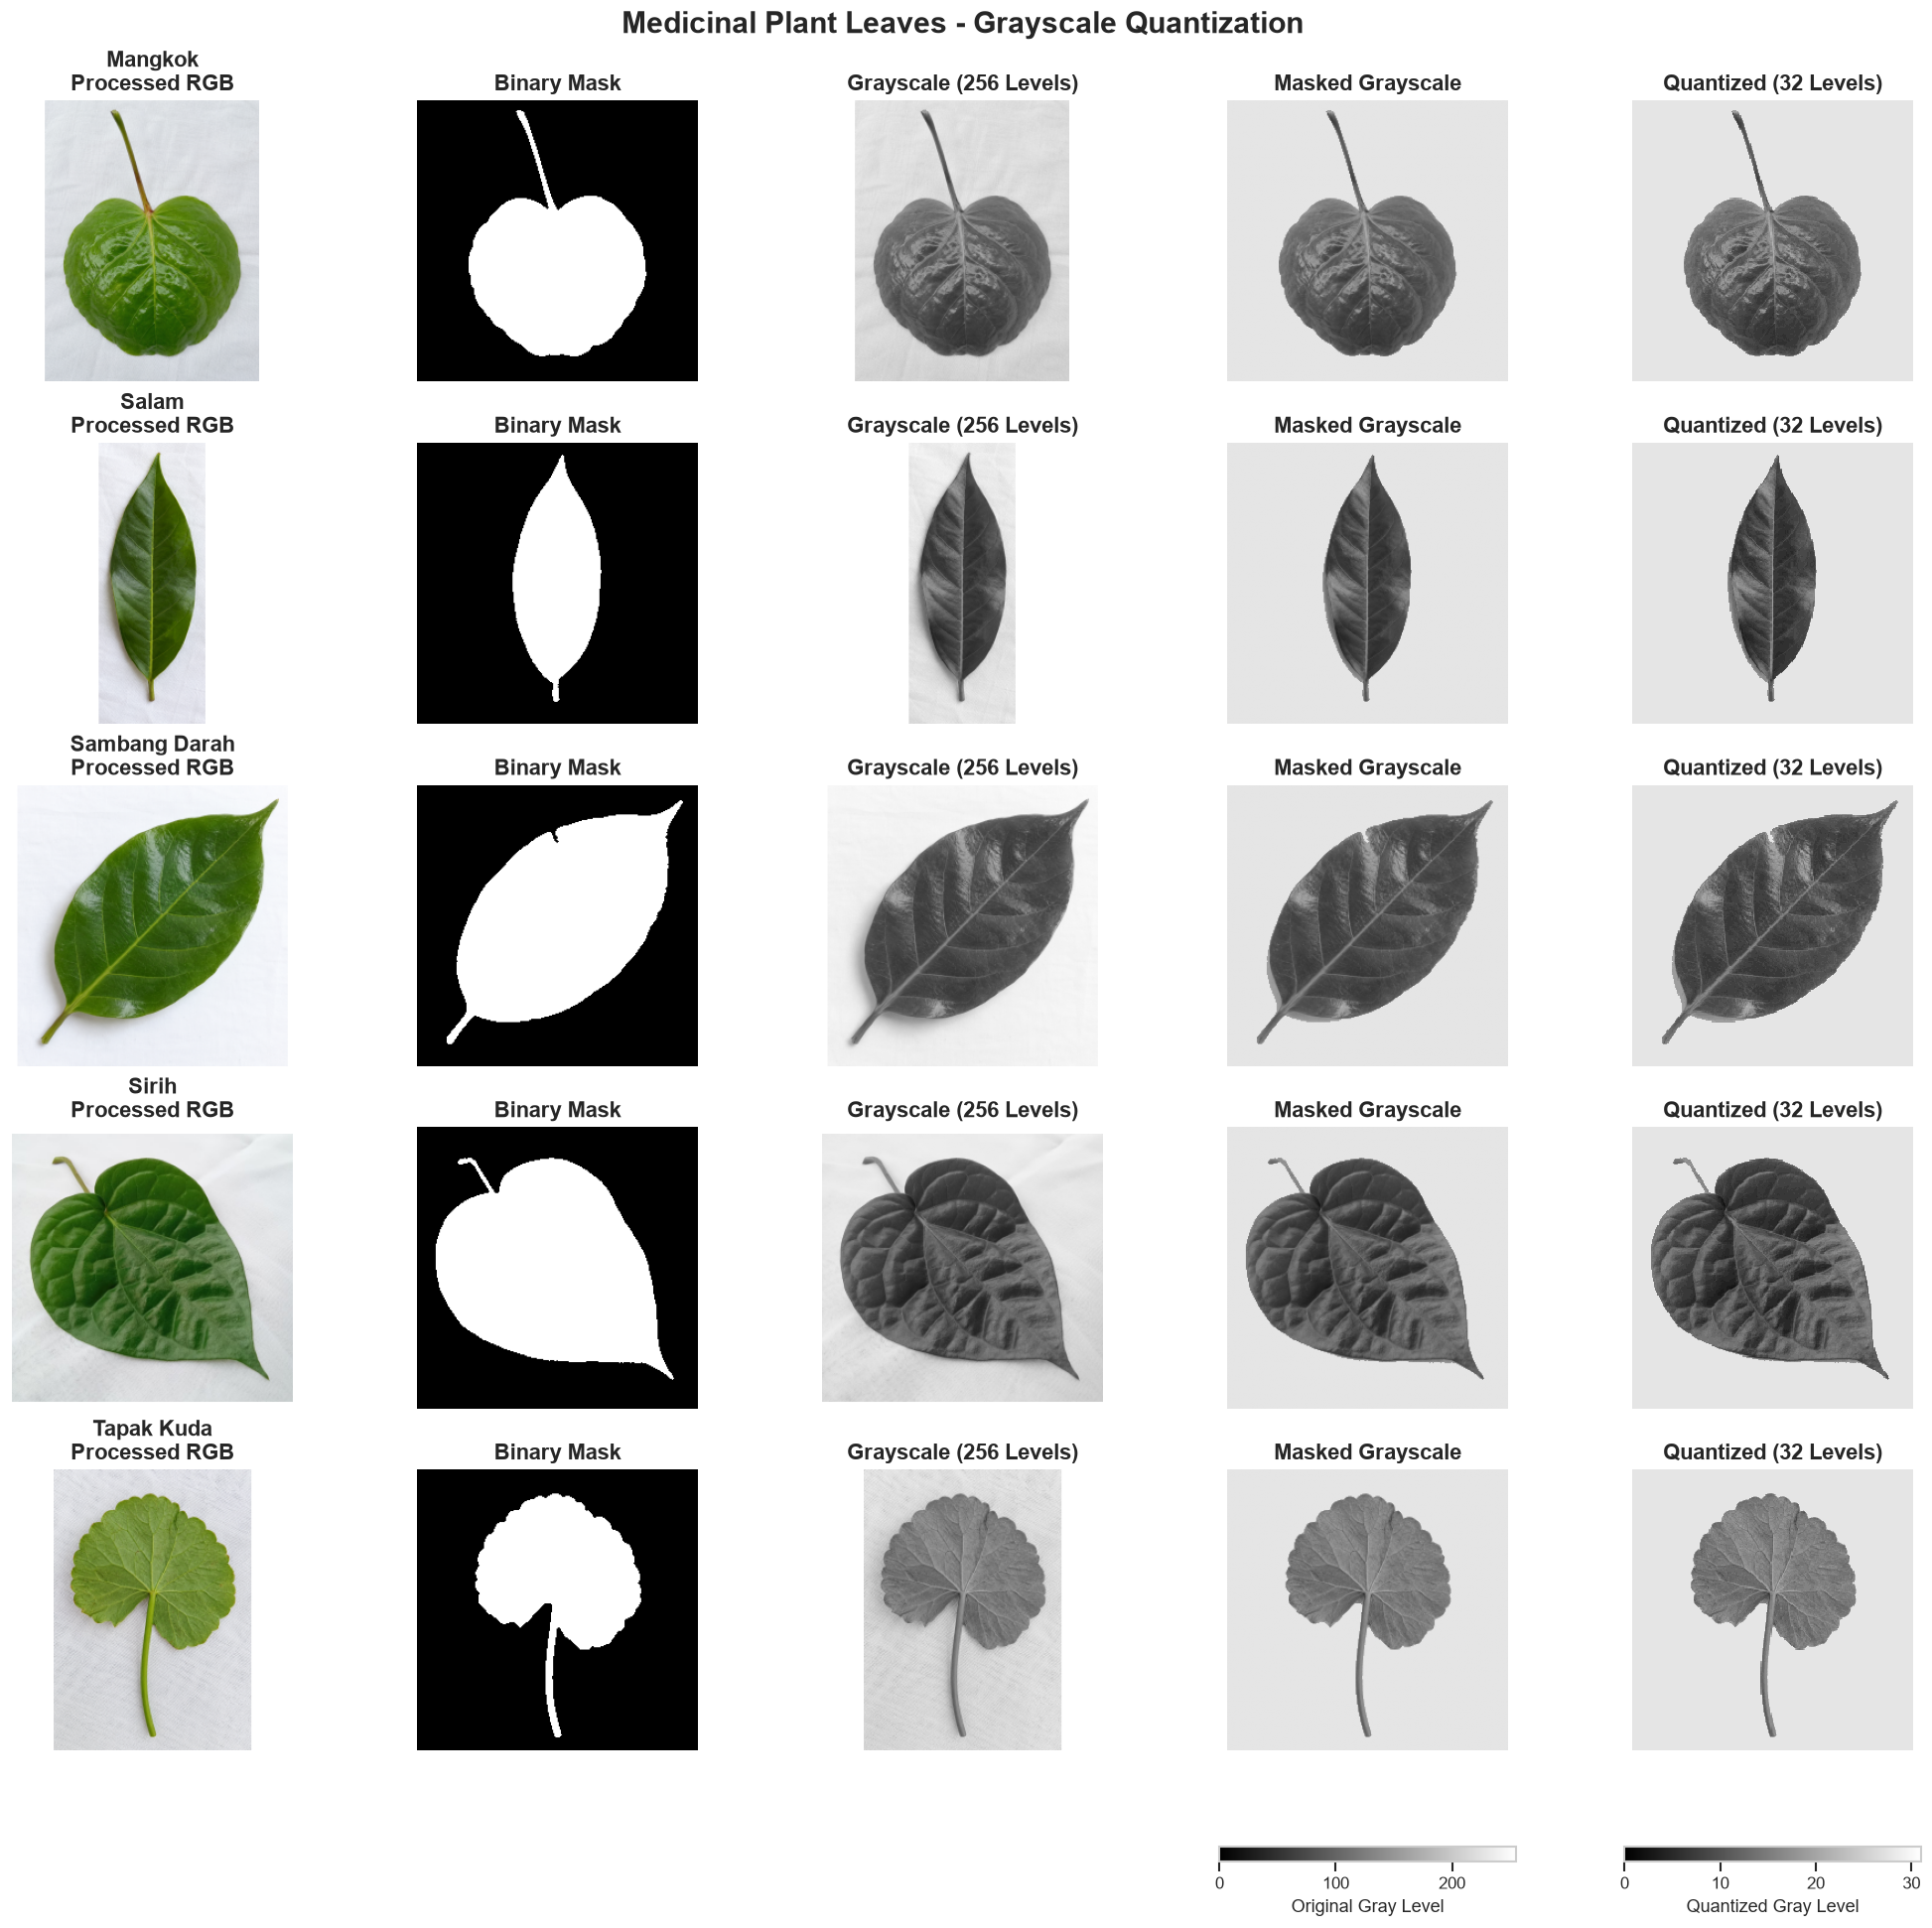


3. GLCM MATRIX HEATMAP COMPARISON


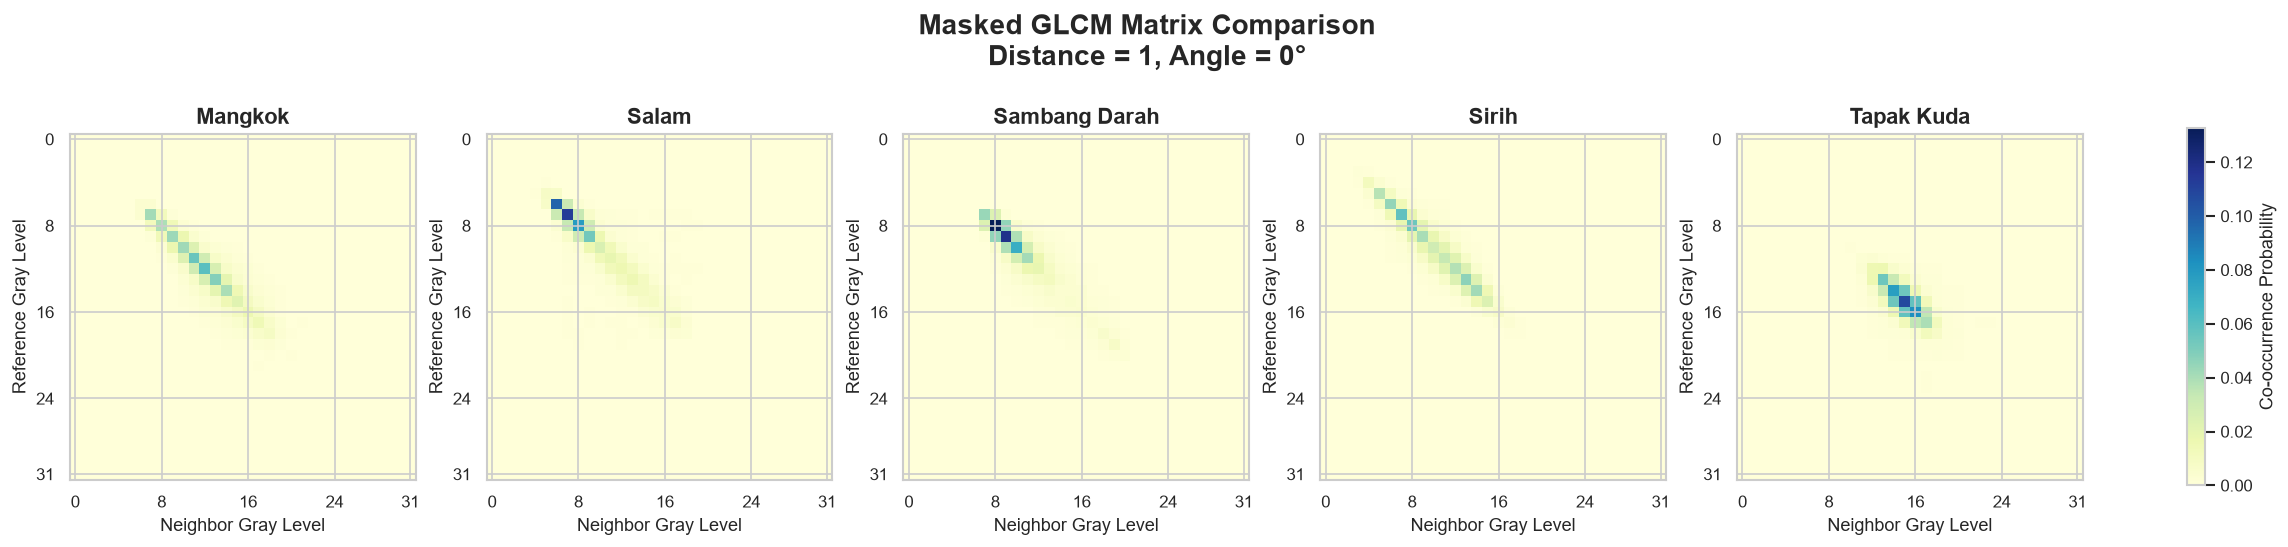


4. GLCM SPATIAL CONFIGURATION VISUALIZATION


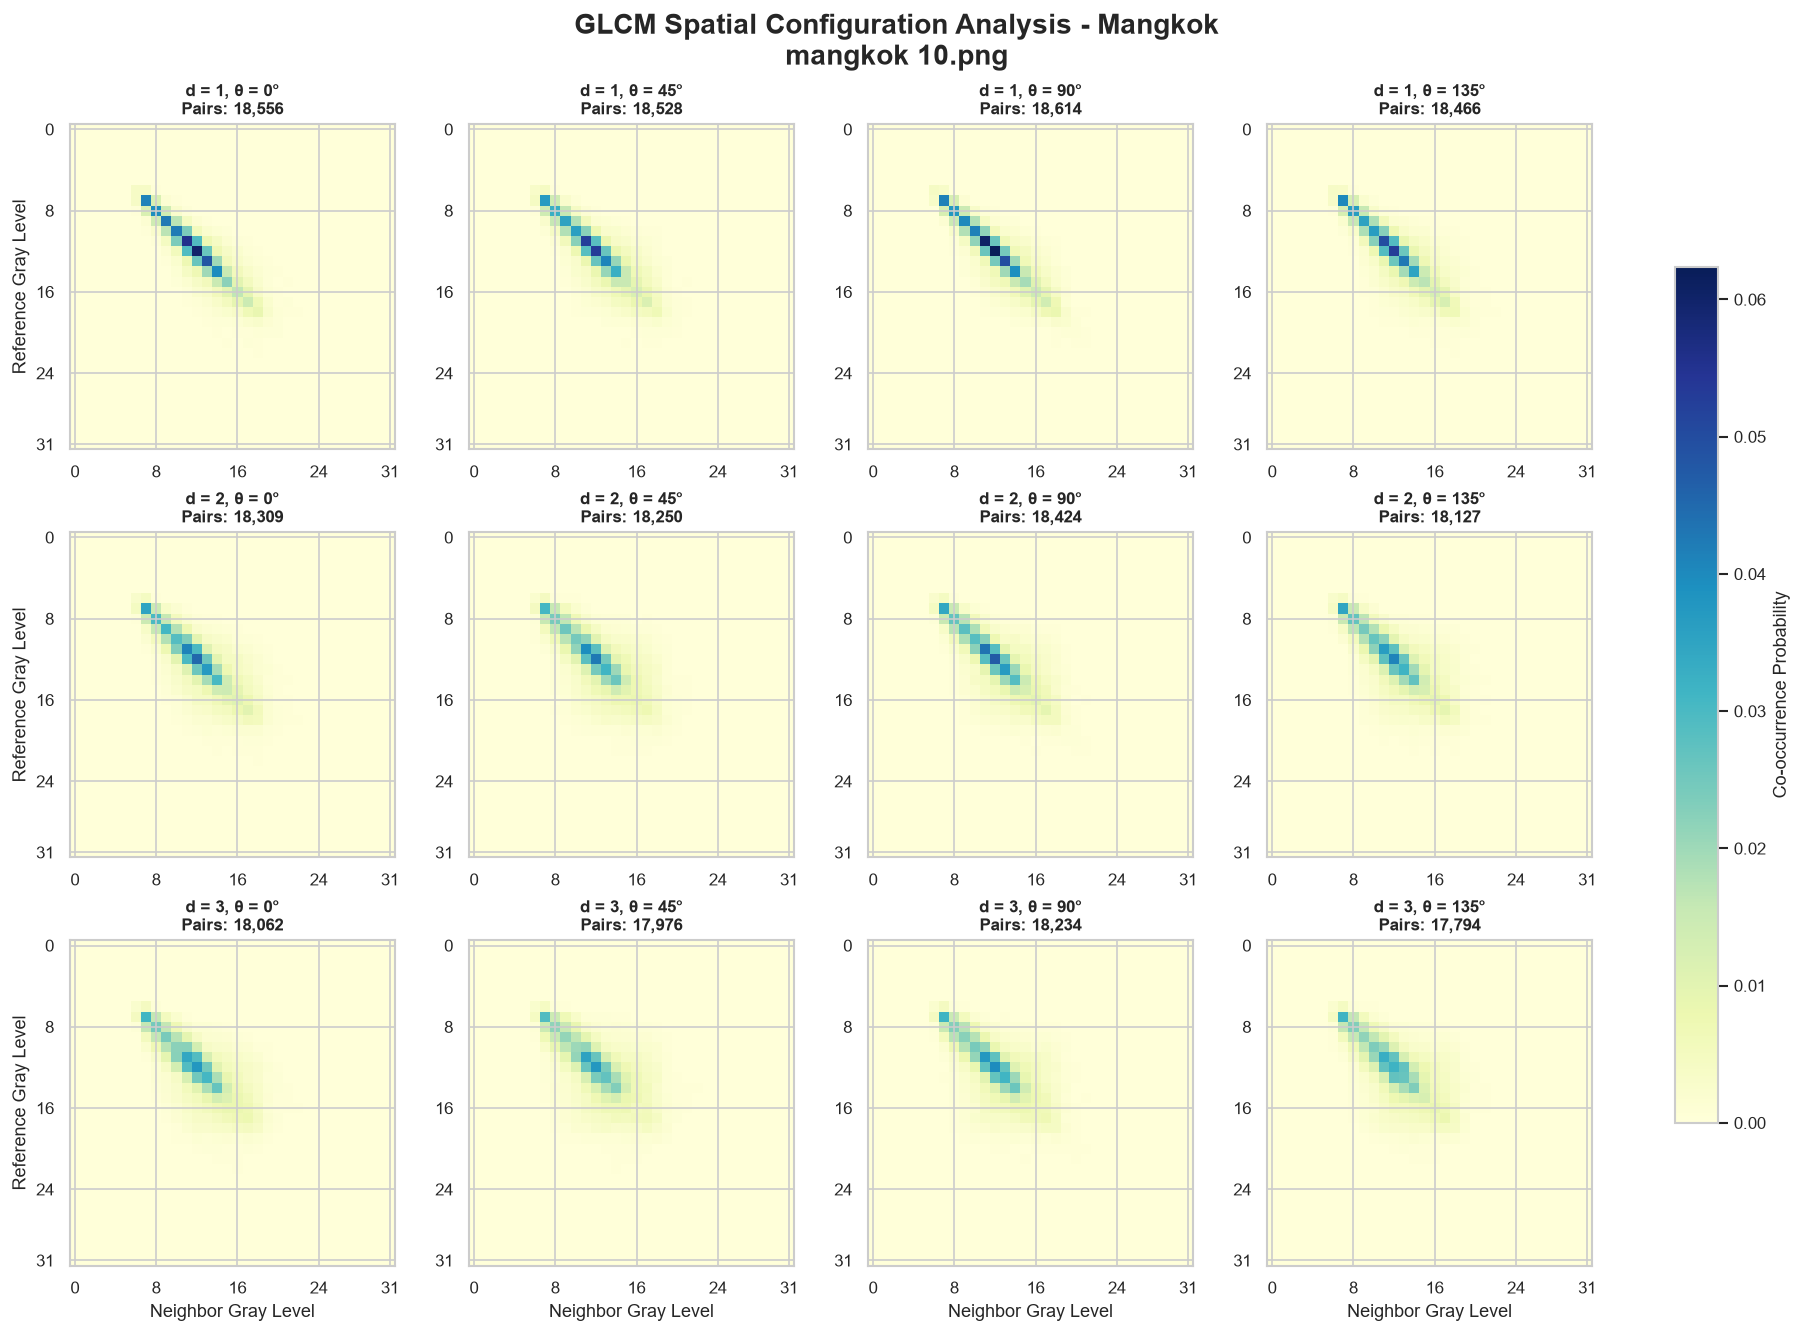


5. GLCM TEXTURE PROPERTY COMPARISON


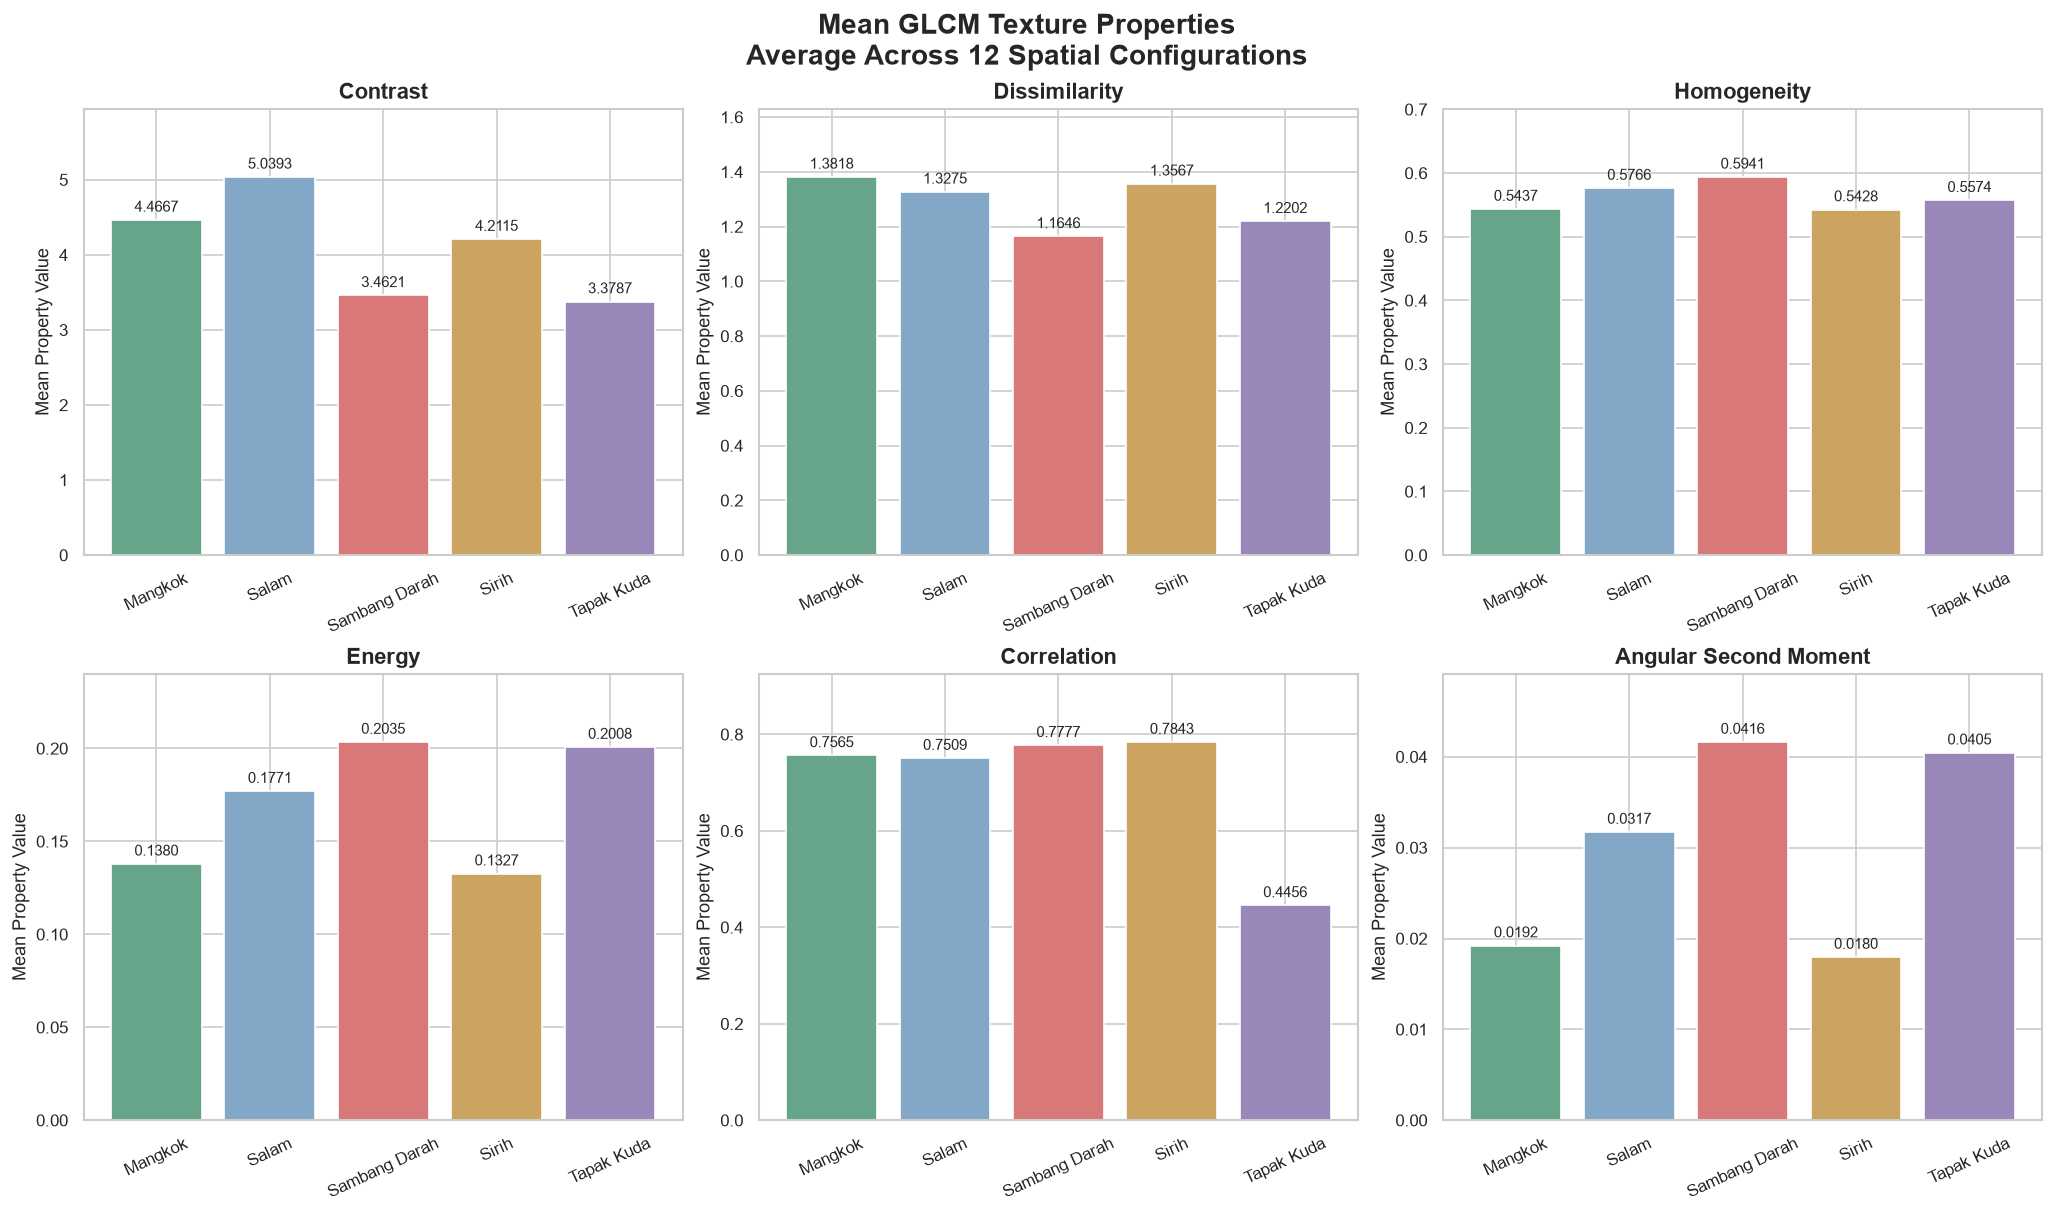


6. DISTANCE AND ANGLE ANALYSIS


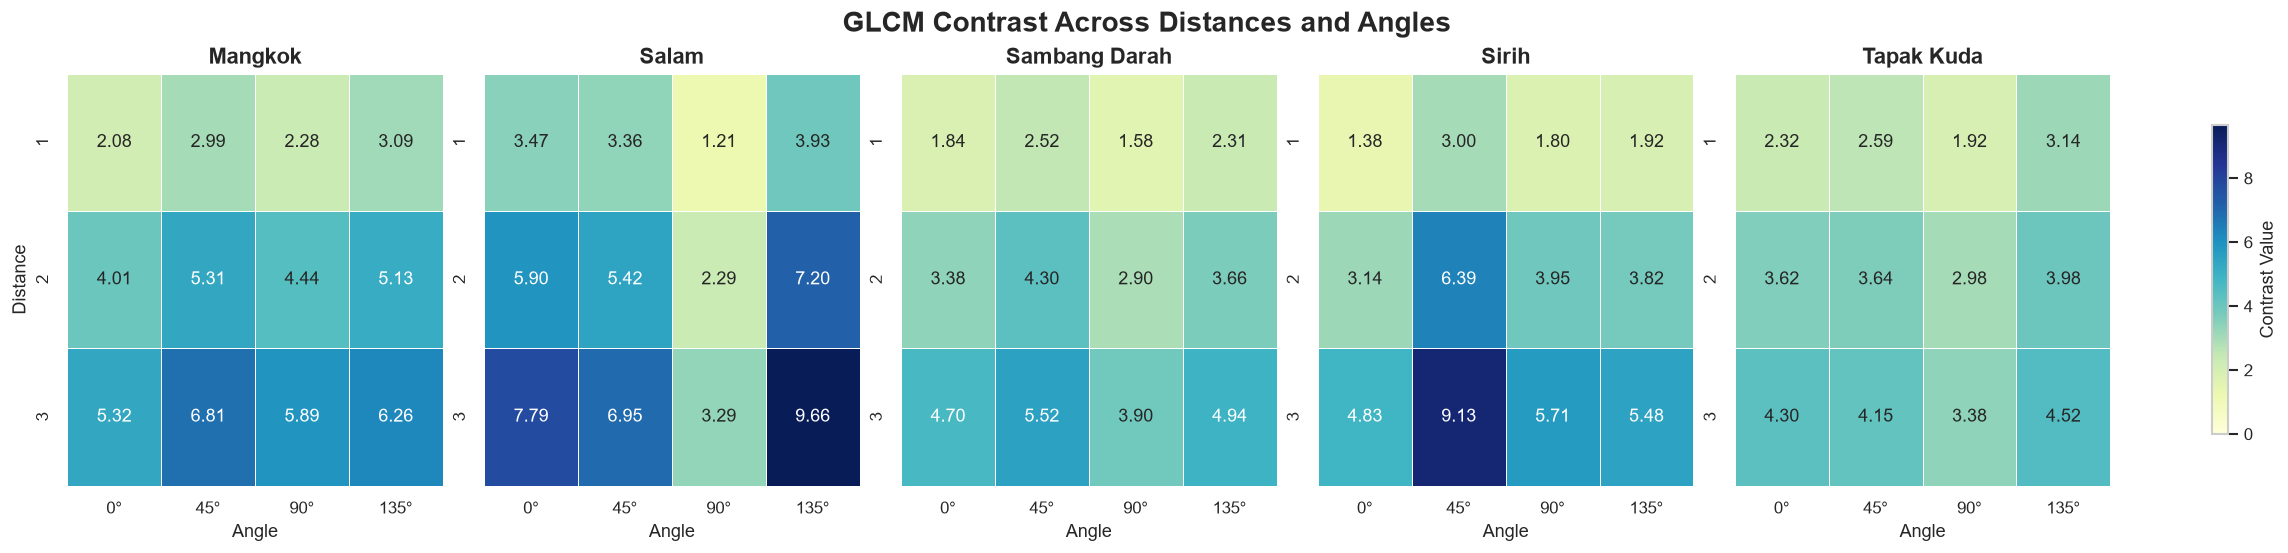


7. GLCM FEATURE MATRIX HEATMAP


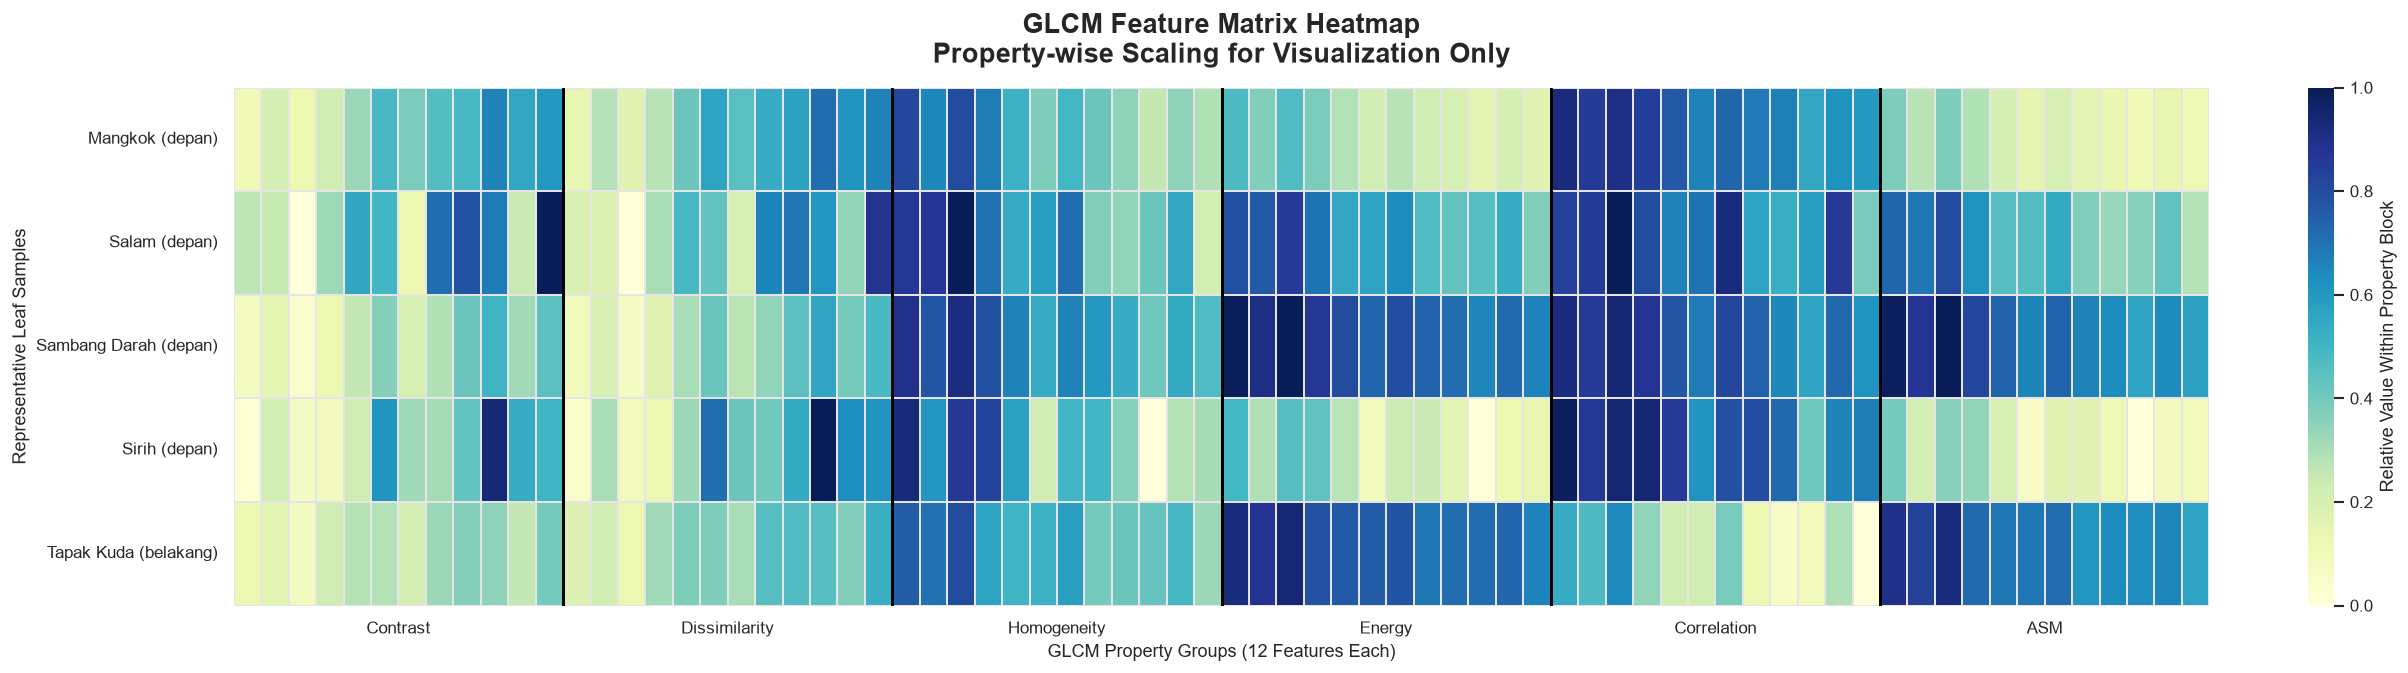


8. GLCM PROPERTY STATISTICS


,sample_id,kelas,property,mean_value,minimum_value,maximum_value,std_value,spatial_configurations
0,leaf_8f09fd62c7391c0d,Mangkok,contrast,4.466718,2.078519,6.809357,1.512428,12
1,leaf_8f09fd62c7391c0d,Mangkok,dissimilarity,1.381806,0.898308,1.800456,0.292148,12
2,leaf_8f09fd62c7391c0d,Mangkok,homogeneity,0.543702,0.460877,0.651487,0.063245,12
3,leaf_8f09fd62c7391c0d,Mangkok,energy,0.137994,0.121460,0.162053,0.013826,12
4,leaf_8f09fd62c7391c0d,Mangkok,correlation,0.756541,0.628739,0.886563,0.082073,12
5,leaf_8f09fd62c7391c0d,Mangkok,ASM,0.019234,0.014753,0.026261,0.003931,12
6,leaf_9c7d463a5bb1a561,Salam,contrast,5.039319,1.210250,9.661030,2.415602,12
7,leaf_9c7d463a5bb1a561,Salam,dissimilarity,1.327490,0.667647,2.069147,0.393703,12
8,leaf_9c7d463a5bb1a561,Salam,homogeneity,0.576611,0.446609,0.713596,0.077974,12
9,leaf_9c7d463a5bb1a561,Salam,energy,0.177107,0.149067,0.210550,0.018993,12



9. MEAN TEXTURE PROPERTY COMPARISON


property,kelas,contrast,dissimilarity,homogeneity,energy,correlation,ASM
0,Mangkok,4.466718,1.381806,0.543702,0.137994,0.756541,0.019234
1,Salam,5.039319,1.327490,0.576611,0.177107,0.750942,0.031727
2,Sambang Darah,3.462101,1.164590,0.594126,0.203511,0.777687,0.041632
3,Sirih,4.211459,1.356668,0.542836,0.132706,0.784314,0.017970
4,Tapak Kuda,3.378692,1.220246,0.557435,0.200828,0.445579,0.040458



10. GLCM VISUALIZATION SUMMARY


,Indicator,Result
0,Total visualized samples,5
1,Total represented classes,5
2,Gray levels,32
3,Number of distances,3
4,Number of angles,4
5,Number of texture properties,6
6,Spatial configurations per sample,12
7,Total GLCM matrices,60
8,GLCM feature dimension,72
9,Feature matrix rows,5



11. GENERATED VISUALIZATIONS


,Visualization,Available,Size (KB)
0,33_glcm_grayscale_quantization.png,True,4008.760000
1,34_glcm_matrix_comparison.png,True,260.970000
2,35_glcm_spatial_configuration_analysis.png,True,438.680000
3,36_glcm_texture_property_comparison.png,True,516.010000
4,37_glcm_distance_angle_analysis.png,True,300.740000
5,38_glcm_feature_heatmap.png,True,201.880000



12. FINAL GLCM VISUALIZATION SUMMARY
Visualized samples : 5
Represented classes: 5
Gray levels        : 32
Spatial offsets    : 12
Texture properties : 6
Total GLCM matrices: 60
GLCM feature size  : 72
Feature matrix     : (5, 72)
Generated figures  : 6

[PASS] Grayscale quantization visualized.
[PASS] GLCM matrix comparison generated.
[PASS] Spatial configurations visualized.
[PASS] Texture property comparison generated.
[PASS] Distance and angle analysis generated.
[PASS] GLCM feature heatmap generated.
[PASS] All visualization files saved.

[INFO] Only representative samples were visualized.
[INFO] Original GLCM features remain unchanged.
[INFO] Heatmap scaling is for visualization only.
[INFO] Full batch extraction will be performed in Cell 13.

GLCM feature visualization completed successfully!

Next cell: Cell 11 - Hu Moments Extraction


In [10]:
# ==================================================
# GLCM FEATURE VISUALIZATION
# ==================================================

print("GLCM FEATURE VISUALIZATION")
print("=" * 60)


# ==================================================
# 1. VALIDATE GLCM EXTRACTION RESULTS
# ==================================================

assert len(glcm_test_samples) > 0

assert glcm_test_features.shape == (
    len(glcm_test_samples),
    GLCM_FEATURE_DIM
)

assert np.isfinite(glcm_test_features).all()

assert np.array_equal(
    glcm_test_samples["sample_id"].to_numpy(),
    hsv_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(
    glcm_test_results_df["sample_id"].to_numpy(),
    glcm_test_samples["sample_id"].to_numpy()
)

assert len(glcm_test_details) == len(glcm_test_samples)

assert glcm_test_pair_counts_df[
    "valid_pixel_pairs"
].gt(0).all()

assert glcm_test_results_df[
    "all_matrices_normalized"
].all()

assert glcm_test_results_df[
    "all_matrices_symmetric"
].all()

glcm_n_samples = len(glcm_test_samples)

print("\n1. GLCM FEATURE INFORMATION")

print(f"Total samples     : {glcm_n_samples}")
print(f"Gray levels       : {GLCM_LEVELS}")
print(f"Feature dimension : {GLCM_FEATURE_DIM}")
print(f"Feature matrix    : {glcm_test_features.shape}")

print("[PASS] GLCM extraction results are valid.")


# ==================================================
# 2. VISUALIZATION CONFIGURATION
# ==================================================

GLCM_CLASS_COLORS = {
    "Mangkok": "#66A58A",
    "Salam": "#83A7C7",
    "Sambang Darah": "#D97878",
    "Sirih": "#CBA461",
    "Tapak Kuda": "#9887B8"
}

GLCM_PROPERTY_TITLES = {
    "contrast": "Contrast",
    "dissimilarity": "Dissimilarity",
    "homogeneity": "Homogeneity",
    "energy": "Energy",
    "correlation": "Correlation",
    "ASM": "Angular Second Moment"
}

GLCM_VIS_DISTANCE = 1
GLCM_VIS_ANGLE = 0

vis_distance_idx = GLCM_DISTANCES.index(
    GLCM_VIS_DISTANCE
)

vis_angle_idx = GLCM_ANGLES_DEGREES.index(
    GLCM_VIS_ANGLE
)

glcm_visualization_paths = []


def save_glcm_figure(fig, filename):

    path = FEATURE_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    glcm_visualization_paths.append(path)

    plt.show()
    plt.close(fig)


# ==================================================
# 3. VISUALIZE GRAYSCALE AND QUANTIZATION
# ==================================================

print("\n2. GRAYSCALE QUANTIZATION VISUALIZATION")

fig, axes = plt.subplots(
    glcm_n_samples,
    5,
    figsize=(17, 3.2 * glcm_n_samples),
    squeeze=False,
    constrained_layout=True
)

gray_cmap = plt.get_cmap("gray").copy()
gray_cmap.set_bad("#E5E5E5")

for i, (_, row) in enumerate(
    glcm_test_samples.iterrows()
):

    sample_id = row["sample_id"]

    data = load_processed_pair(
        row["absolute_processed_image_path"],
        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]
    binary_mask = data["binary_mask"]

    foreground = binary_mask == 255

    details = glcm_test_details[sample_id]

    gray_image = details["gray_image"]

    quantized_image = details["quantized_image"]

    # Visualization-only masked images
    masked_gray = np.ma.masked_where(
        ~foreground,
        gray_image
    )

    masked_quantized = np.ma.masked_where(
        ~foreground,
        quantized_image
    )

    # A. RGB image
    axes[i, 0].imshow(rgb_image)

    axes[i, 0].set_title(
        f"{row['kelas']}\nProcessed RGB"
    )

    # B. Binary mask
    axes[i, 1].imshow(
        binary_mask,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i, 1].set_title("Binary Mask")

    # C. Original grayscale
    axes[i, 2].imshow(
        gray_image,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i, 2].set_title("Grayscale (256 Levels)")

    # D. Masked grayscale
    gray_plot = axes[i, 3].imshow(
        masked_gray,
        cmap=gray_cmap,
        vmin=0,
        vmax=255
    )

    axes[i, 3].set_title("Masked Grayscale")

    # E. Quantized grayscale
    quantized_plot = axes[i, 4].imshow(
        masked_quantized,
        cmap=gray_cmap,
        vmin=0,
        vmax=GLCM_LEVELS - 1,
        interpolation="nearest"
    )

    axes[i, 4].set_title(
        f"Quantized ({GLCM_LEVELS} Levels)"
    )

    for ax in axes[i]:

        ax.axis("off")


fig.colorbar(
    gray_plot,
    ax=axes[:, 3].tolist(),
    orientation="horizontal",
    shrink=0.75,
    label="Original Gray Level"
)

fig.colorbar(
    quantized_plot,
    ax=axes[:, 4].tolist(),
    orientation="horizontal",
    shrink=0.75,
    label="Quantized Gray Level"
)

fig.suptitle(
    "Medicinal Plant Leaves - Grayscale Quantization",
    fontsize=18,
    fontweight="bold"
)

save_glcm_figure(
    fig,
    "33_glcm_grayscale_quantization.png"
)


# ==================================================
# 4. VISUALIZE GLCM MATRICES ACROSS SAMPLES
# ==================================================

print("\n3. GLCM MATRIX HEATMAP COMPARISON")

# Compare the same distance and angle for every sample
selected_glcm_matrices = [

    glcm_test_details[sample_id]["glcm_tensor"][
        :,
        :,
        vis_distance_idx,
        vis_angle_idx
    ]

    for sample_id in glcm_test_samples["sample_id"]
]

# Shared color scale for fair comparison
matrix_vmax = max(
    float(matrix.max())
    for matrix in selected_glcm_matrices
)

matrix_vmax = max(matrix_vmax, EPSILON)

fig, axes = plt.subplots(
    1,
    glcm_n_samples,
    figsize=(19, 4.5),
    squeeze=False,
    constrained_layout=True
)

gray_ticks = sorted(set([
    0, 8, 16, 24, GLCM_LEVELS - 1
]))

for i, (_, row) in enumerate(
    glcm_test_samples.iterrows()
):

    ax = axes[0, i]

    matrix = selected_glcm_matrices[i]

    matrix_plot = ax.imshow(
        matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=matrix_vmax,
        interpolation="nearest",
        origin="upper"
    )

    ax.set_title(row["kelas"])

    ax.set_xlabel("Neighbor Gray Level")

    ax.set_ylabel("Reference Gray Level")

    ax.set_xticks(gray_ticks)

    ax.set_yticks(gray_ticks)


fig.colorbar(
    matrix_plot,
    ax=axes.ravel().tolist(),
    shrink=0.80,
    label="Co-occurrence Probability"
)

fig.suptitle(
    f"Masked GLCM Matrix Comparison\n"
    f"Distance = {GLCM_VIS_DISTANCE}, "
    f"Angle = {GLCM_VIS_ANGLE}°",
    fontsize=17,
    fontweight="bold"
)

save_glcm_figure(
    fig,
    "34_glcm_matrix_comparison.png"
)


# ==================================================
# 5. VISUALIZE ALL GLCM SPATIAL CONFIGURATIONS
# ==================================================

print("\n4. GLCM SPATIAL CONFIGURATION VISUALIZATION")

# Select one representative sample for detailed analysis
GLCM_VIS_CLASS = "Mangkok"

spatial_candidates = glcm_test_samples[
    glcm_test_samples["kelas"].eq(GLCM_VIS_CLASS)
]

if spatial_candidates.empty:

    spatial_sample = glcm_test_samples.iloc[0]

else:

    spatial_sample = spatial_candidates.iloc[0]


spatial_sample_id = spatial_sample["sample_id"]

spatial_details = glcm_test_details[
    spatial_sample_id
]

spatial_tensor = spatial_details["glcm_tensor"]

spatial_vmax = max(
    float(spatial_tensor.max()),
    EPSILON
)

fig, axes = plt.subplots(
    len(GLCM_DISTANCES),
    len(GLCM_ANGLES_DEGREES),
    figsize=(15, 11),
    squeeze=False,
    constrained_layout=True
)

for d_idx, distance in enumerate(
    GLCM_DISTANCES
):

    for a_idx, angle in enumerate(
        GLCM_ANGLES_DEGREES
    ):

        ax = axes[d_idx, a_idx]

        matrix = spatial_tensor[
            :, :, d_idx, a_idx
        ]

        pair_record = spatial_details[
            "pair_counts_df"
        ]

        pair_record = pair_record.loc[
            pair_record["distance"].eq(distance)
            & pair_record["angle"].eq(angle)
        ].iloc[0]

        spatial_plot = ax.imshow(
            matrix,
            cmap="YlGnBu",
            vmin=0,
            vmax=spatial_vmax,
            interpolation="nearest"
        )

        ax.set_title(
            f"d = {distance}, θ = {angle}°\n"
            f"Pairs: {int(pair_record['valid_pixel_pairs']):,}",
            fontsize=10
        )

        ax.set_xticks(gray_ticks)
        ax.set_yticks(gray_ticks)

        if d_idx == len(GLCM_DISTANCES) - 1:

            ax.set_xlabel("Neighbor Gray Level")

        if a_idx == 0:

            ax.set_ylabel("Reference Gray Level")


fig.colorbar(
    spatial_plot,
    ax=axes.ravel().tolist(),
    shrink=0.75,
    label="Co-occurrence Probability"
)

fig.suptitle(
    f"GLCM Spatial Configuration Analysis - "
    f"{spatial_sample['kelas']}\n"
    f"{spatial_sample['nama_file']}",
    fontsize=17,
    fontweight="bold"
)

save_glcm_figure(
    fig,
    "35_glcm_spatial_configuration_analysis.png"
)


# ==================================================
# 6. COMPARE SIX GLCM TEXTURE PROPERTIES
# ==================================================

print("\n5. GLCM TEXTURE PROPERTY COMPARISON")

# Mean values are used only for visualization
# Original 72-dimensional features remain unchanged

property_plot_df = (
    glcm_mean_properties_df
    .set_index("sample_id")
    .loc[glcm_test_samples["sample_id"]]
    .reset_index()
)

class_colors = [

    GLCM_CLASS_COLORS.get(
        plant_class, "#777777"
    )

    for plant_class in property_plot_df["kelas"]
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 10),
    constrained_layout=True
)

for ax, property_name in zip(
    axes.ravel(),
    GLCM_PROPERTIES
):

    values = property_plot_df[
        property_name
    ].to_numpy()

    bars = ax.bar(
        property_plot_df["kelas"],
        values,
        color=class_colors
    )

    ax.set_title(
        GLCM_PROPERTY_TITLES[property_name]
    )

    ax.set_ylabel("Mean Property Value")

    ax.tick_params(
        axis="x",
        rotation=25
    )

    ax.margins(y=0.18)

    if property_name == "correlation":

        ax.axhline(
            0,
            color="black",
            linewidth=0.8
        )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )


fig.suptitle(
    "Mean GLCM Texture Properties\n"
    "Average Across 12 Spatial Configurations",
    fontsize=17,
    fontweight="bold"
)

save_glcm_figure(
    fig,
    "36_glcm_texture_property_comparison.png"
)


# ==================================================
# 7. ANALYZE DISTANCE AND ANGLE EFFECTS
# ==================================================

print("\n6. DISTANCE AND ANGLE ANALYSIS")

# Use contrast as the representative texture property
# to examine directional and distance differences

contrast_matrices = [

    glcm_test_details[sample_id][
        "property_matrices"
    ]["contrast"]

    for sample_id in glcm_test_samples["sample_id"]
]

contrast_vmax = max(
    max(
        float(matrix.max())
        for matrix in contrast_matrices
    ),
    EPSILON
)

fig, axes = plt.subplots(
    1,
    glcm_n_samples,
    figsize=(19, 4.5),
    squeeze=False,
    constrained_layout=True
)

for i, (_, row) in enumerate(
    glcm_test_samples.iterrows()
):

    ax = axes[0, i]

    contrast_matrix = contrast_matrices[i]

    sns.heatmap(
        contrast_matrix,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        vmin=0,
        vmax=contrast_vmax,
        xticklabels=[
            f"{angle}°"
            for angle in GLCM_ANGLES_DEGREES
        ],
        yticklabels=GLCM_DISTANCES,
        linewidths=0.5,
        cbar=False,
        ax=ax
    )

    ax.set_title(row["kelas"])

    ax.set_xlabel("Angle")

    ax.set_ylabel(
        "Distance" if i == 0 else ""
    )


fig.colorbar(
    axes[0, -1].collections[0],
    ax=axes.ravel().tolist(),
    shrink=0.75,
    label="Contrast Value"
)

fig.suptitle(
    "GLCM Contrast Across Distances and Angles",
    fontsize=17,
    fontweight="bold"
)

save_glcm_figure(
    fig,
    "37_glcm_distance_angle_analysis.png"
)


# ==================================================
# 8. VISUALIZE COMPLETE GLCM FEATURE HEATMAP
# ==================================================

print("\n7. GLCM FEATURE MATRIX HEATMAP")

# GLCM properties have different numerical ranges.
# Scale each property block to [0, 1] ONLY for display.
# Do not overwrite the original feature matrix.

features_per_property = (
    len(GLCM_DISTANCES)
    * len(GLCM_ANGLES_DEGREES)
)

glcm_display_features = np.zeros_like(
    glcm_test_features,
    dtype=np.float64
)

glcm_display_range_records = []

for property_idx, property_name in enumerate(
    GLCM_PROPERTIES
):

    start_idx = (
        property_idx * features_per_property
    )

    end_idx = (
        start_idx + features_per_property
    )

    property_block = glcm_test_features[
        :, start_idx:end_idx
    ]

    block_min = float(property_block.min())

    block_max = float(property_block.max())

    block_range = block_max - block_min

    if block_range > EPSILON:

        glcm_display_features[
            :, start_idx:end_idx
        ] = (
            property_block - block_min
        ) / block_range

    else:

        glcm_display_features[
            :, start_idx:end_idx
        ] = 0.0

    glcm_display_range_records.append({

        "property": property_name,

        "start_index": start_idx,

        "end_index_inclusive": end_idx - 1,

        "original_minimum": block_min,

        "original_maximum": block_max,

        "constant_block": bool(
            block_range <= EPSILON
        )
    })


glcm_display_ranges_df = pd.DataFrame(
    glcm_display_range_records
)

assert glcm_display_features.shape == (
    glcm_test_features.shape
)

assert np.isfinite(
    glcm_display_features
).all()

assert np.all(
    glcm_display_features >= 0
)

assert np.all(
    glcm_display_features <= 1
)

heatmap_labels = [

    f"{row['kelas']} ({row['tampilan_daun']})"

    for _, row in glcm_test_samples.iterrows()
]

fig, ax = plt.subplots(
    figsize=(20, 5.5),
    constrained_layout=True
)

sns.heatmap(
    glcm_display_features,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.25,
    linecolor="#E5E5E5",
    xticklabels=False,
    yticklabels=heatmap_labels,
    cbar_kws={
        "label": "Relative Value Within Property Block"
    },
    ax=ax
)

# Separate each GLCM property block
for i in range(1, len(GLCM_PROPERTIES)):

    ax.axvline(
        i * features_per_property,
        color="black",
        linewidth=1.8
    )

group_centers = [

    i * features_per_property
    + features_per_property / 2

    for i in range(len(GLCM_PROPERTIES))
]

ax.set_xticks(group_centers)

ax.set_xticklabels(
    [
        "Contrast",
        "Dissimilarity",
        "Homogeneity",
        "Energy",
        "Correlation",
        "ASM"
    ],
    rotation=0
)

ax.set_yticklabels(
    heatmap_labels,
    rotation=0
)

ax.set_xlabel(
    "GLCM Property Groups (12 Features Each)"
)

ax.set_ylabel(
    "Representative Leaf Samples"
)

ax.set_title(
    "GLCM Feature Matrix Heatmap\n"
    "Property-wise Scaling for Visualization Only",
    fontsize=16,
    fontweight="bold",
    pad=15
)

save_glcm_figure(
    fig,
    "38_glcm_feature_heatmap.png"
)


# ==================================================
# 9. ANALYZE GLCM PROPERTY STATISTICS
# ==================================================

print("\n8. GLCM PROPERTY STATISTICS")

glcm_property_statistics_df = (

    glcm_test_properties_df

    .groupby(
        ["sample_id", "kelas", "property"],
        sort=False
    )

    .agg(

        mean_value=(
            "value", "mean"
        ),

        minimum_value=(
            "value", "min"
        ),

        maximum_value=(
            "value", "max"
        ),

        std_value=(
            "value",
            lambda values: values.std(ddof=0)
        ),

        spatial_configurations=(
            "value", "count"
        )
    )

    .reset_index()
)

assert glcm_property_statistics_df[
    "spatial_configurations"
].eq(features_per_property).all()

display(
    glcm_property_statistics_df.round(6)
)


print("\n9. MEAN TEXTURE PROPERTY COMPARISON")

display(

    property_plot_df[
        ["kelas", *GLCM_PROPERTIES]
    ].round(6)
)


# ==================================================
# 10. CREATE GLCM VISUALIZATION SUMMARY
# ==================================================

glcm_visualization_summary_df = pd.DataFrame({

    "Indicator": [

        "Total visualized samples",

        "Total represented classes",

        "Gray levels",

        "Number of distances",

        "Number of angles",

        "Number of texture properties",

        "Spatial configurations per sample",

        "Total GLCM matrices",

        "GLCM feature dimension",

        "Feature matrix rows",

        "Feature matrix columns",

        "Minimum valid pixel pairs",

        "Maximum valid pixel pairs",

        "Generated visualizations"
    ],

    "Result": [

        glcm_n_samples,

        glcm_test_samples["kelas"].nunique(),

        GLCM_LEVELS,

        len(GLCM_DISTANCES),

        len(GLCM_ANGLES_DEGREES),

        len(GLCM_PROPERTIES),

        features_per_property,

        len(glcm_test_pair_counts_df),

        GLCM_FEATURE_DIM,

        glcm_test_features.shape[0],

        glcm_test_features.shape[1],

        glcm_test_pair_counts_df[
            "valid_pixel_pairs"
        ].min(),

        glcm_test_pair_counts_df[
            "valid_pixel_pairs"
        ].max(),

        len(glcm_visualization_paths)
    ]
})

print("\n10. GLCM VISUALIZATION SUMMARY")

display(glcm_visualization_summary_df)


# ==================================================
# 11. VALIDATE GENERATED VISUALIZATIONS
# ==================================================

glcm_visualization_validation_df = pd.DataFrame([

    {

        "Visualization": path.name,

        "Available": path.is_file(),

        "Size (KB)": (
            round(path.stat().st_size / 1024, 2)
            if path.is_file()
            else 0
        )
    }

    for path in glcm_visualization_paths
])

print("\n11. GENERATED VISUALIZATIONS")

display(glcm_visualization_validation_df)

assert len(glcm_visualization_paths) == 6

assert glcm_visualization_validation_df[
    "Available"
].all()

assert glcm_visualization_validation_df[
    "Size (KB)"
].gt(0).all()


# ==================================================
# 12. SAVE GLCM VISUALIZATION REPORTS
# ==================================================

glcm_visualization_reports = {

    "110_glcm_property_statistics.csv":
        glcm_property_statistics_df,

    "111_glcm_visualization_scaling_ranges.csv":
        glcm_display_ranges_df,

    "112_glcm_visualization_summary.csv":
        glcm_visualization_summary_df,

    "113_glcm_visualization_artifact_validation.csv":
        glcm_visualization_validation_df
}

for filename, dataframe in (
    glcm_visualization_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )


# ==================================================
# 13. FINAL GLCM VISUALIZATION SUMMARY
# ==================================================

print("\n12. FINAL GLCM VISUALIZATION SUMMARY")

print("=" * 60)

print(f"Visualized samples : {glcm_n_samples}")

print(
    f"Represented classes: "
    f"{glcm_test_samples['kelas'].nunique()}"
)

print(f"Gray levels        : {GLCM_LEVELS}")

print(
    f"Spatial offsets    : "
    f"{len(GLCM_OFFSET_LOOKUP)}"
)

print(
    f"Texture properties : "
    f"{len(GLCM_PROPERTIES)}"
)

print(
    f"Total GLCM matrices: "
    f"{len(glcm_test_pair_counts_df)}"
)

print(f"GLCM feature size  : {GLCM_FEATURE_DIM}")

print(
    f"Feature matrix     : "
    f"{glcm_test_features.shape}"
)

print(
    f"Generated figures  : "
    f"{len(glcm_visualization_paths)}"
)

print("\n[PASS] Grayscale quantization visualized.")

print("[PASS] GLCM matrix comparison generated.")

print("[PASS] Spatial configurations visualized.")

print("[PASS] Texture property comparison generated.")

print("[PASS] Distance and angle analysis generated.")

print("[PASS] GLCM feature heatmap generated.")

print("[PASS] All visualization files saved.")

print("\n[INFO] Only representative samples were visualized.")

print("[INFO] Original GLCM features remain unchanged.")

print("[INFO] Heatmap scaling is for visualization only.")

print("[INFO] Full batch extraction will be performed in Cell 13.")

print("\nGLCM feature visualization completed successfully!")

print("\nNext cell: Cell 11 - Hu Moments Extraction")

In [11]:
# ==================================================
# HU MOMENTS FEATURE EXTRACTION
# ==================================================

print("HU MOMENTS FEATURE EXTRACTION")
print("=" * 60)


# ==================================================
# 1. VALIDATE HU MOMENTS CONFIGURATION
# ==================================================

assert HU_MOMENTS_COUNT == 7
assert HU_FEATURE_DIM == 7
assert len(HU_FEATURE_NAMES) == HU_FEATURE_DIM
assert HU_USE_BINARY_MASK is True
assert HU_APPLY_LOG_TRANSFORM is True
assert HU_LOG_EPSILON > 0
assert HU_ZERO_POLICY == "Preserve Zero"
assert HU_INCLUDE_PETIOLE is True
assert df_image_validated["technical_valid"].all()

print("\n1. HU MOMENTS CONFIGURATION")

print(f"Number of moments : {HU_MOMENTS_COUNT}")
print(f"Binary mask input : {HU_USE_BINARY_MASK}")
print(f"Log transformation: {HU_APPLY_LOG_TRANSFORM}")
print(f"Log epsilon       : {HU_LOG_EPSILON}")
print(f"Zero policy       : {HU_ZERO_POLICY}")
print(f"Include petiole   : {HU_INCLUDE_PETIOLE}")
print(f"Feature dimension : {HU_FEATURE_DIM}")

display(hu_config_df)


# ==================================================
# 2. DEFINE SIGNED LOG TRANSFORMATION
# ==================================================

def transform_hu_moments(raw_hu):

    """
    Apply signed logarithmic transformation
    to seven original Hu Moments.

    Exact zero values are preserved.
    """

    raw_hu = np.asarray(
        raw_hu,
        dtype=FEATURE_DTYPE
    ).reshape(-1)

    if raw_hu.shape != (HU_FEATURE_DIM,):

        raise ValueError(
            "Invalid Hu Moments dimension."
        )

    if not np.isfinite(raw_hu).all():

        raise ValueError(
            "Non-finite raw Hu Moments detected."
        )

    transformed_hu = np.zeros_like(
        raw_hu,
        dtype=FEATURE_DTYPE
    )

    nonzero_mask = raw_hu != 0

    transformed_hu[nonzero_mask] = (

        -np.sign(raw_hu[nonzero_mask])

        * np.log10(

            np.maximum(

                np.abs(raw_hu[nonzero_mask]),

                HU_LOG_EPSILON
            )
        )
    )

    if not np.isfinite(transformed_hu).all():

        raise ValueError(
            "Non-finite transformed Hu Moments."
        )

    return transformed_hu


print("\n[OK] Signed log transformation initialized.")


# ==================================================
# 3. DEFINE HU MOMENTS EXTRACTION FUNCTION
# ==================================================

def extract_hu_features(
    binary_mask,
    return_details=False
):

    """
    Extract seven Hu Moments shape features
    from a binary leaf mask.

    Parameters
    ----------
    binary_mask : numpy.ndarray
        Binary image containing 0 and 255.

    return_details : bool
        Return raw moments and shape information.

    Returns
    -------
    feature_vector : numpy.ndarray
        Seven signed-log Hu Moments.
    """

    # --------------------------------------------------
    # A. Validate binary mask
    # --------------------------------------------------

    if binary_mask.shape != EXPECTED_MASK_SHAPE:

        raise ValueError(

            f"Invalid binary mask shape: "
            f"{binary_mask.shape}"
        )

    if binary_mask.dtype != np.uint8:

        raise ValueError(
            "Binary mask must have uint8 data type."
        )

    if set(np.unique(binary_mask).tolist()) != {0, 255}:

        raise ValueError(
            "Binary mask must contain 0 and 255."
        )

    foreground_pixels = int(

        np.count_nonzero(binary_mask == 255)
    )

    if foreground_pixels < MIN_FOREGROUND_PIXELS:

        raise ValueError(
            "Insufficient foreground pixels."
        )

    # --------------------------------------------------
    # B. Calculate image moments
    # --------------------------------------------------

    # binaryImage=True treats every nonzero pixel
    # as a foreground pixel with value 1.

    image_moments = cv2.moments(

        binary_mask,

        binaryImage=True
    )

    m00 = float(image_moments["m00"])

    if m00 <= 0:

        raise ValueError(
            "Zero foreground area detected."
        )

    assert np.isclose(

        m00,

        foreground_pixels,

        rtol=0,

        atol=1e-8
    )

    # --------------------------------------------------
    # C. Calculate centroid
    # --------------------------------------------------

    centroid_x = (

        image_moments["m10"] / m00
    )

    centroid_y = (

        image_moments["m01"] / m00
    )

    # --------------------------------------------------
    # D. Extract spatial moments
    # --------------------------------------------------

    spatial_moments = {

        key: float(value)

        for key, value in image_moments.items()

        if key.startswith("m")
        and not key.startswith("mu")
    }

    # --------------------------------------------------
    # E. Extract central moments
    # --------------------------------------------------

    central_moments = {

        key: float(value)

        for key, value in image_moments.items()

        if key.startswith("mu")
    }

    # --------------------------------------------------
    # F. Extract normalized central moments
    # --------------------------------------------------

    normalized_central_moments = {

        key: float(value)

        for key, value in image_moments.items()

        if key.startswith("nu")
    }

    # --------------------------------------------------
    # G. Calculate seven Hu Moments
    # --------------------------------------------------

    raw_hu = cv2.HuMoments(

        image_moments

    ).flatten().astype(FEATURE_DTYPE)

    if raw_hu.shape != (HU_FEATURE_DIM,):

        raise ValueError(
            "Unexpected raw Hu Moments dimension."
        )

    if not np.isfinite(raw_hu).all():

        raise ValueError(
            "Non-finite raw Hu Moments detected."
        )

    # --------------------------------------------------
    # H. Apply signed log transformation
    # --------------------------------------------------

    if HU_APPLY_LOG_TRANSFORM:

        feature_vector = transform_hu_moments(
            raw_hu
        )

    else:

        feature_vector = raw_hu.copy()

    # --------------------------------------------------
    # I. Validate extracted features
    # --------------------------------------------------

    assert feature_vector.shape == (
        HU_FEATURE_DIM,
    )

    assert np.isfinite(feature_vector).all()

    assert np.all(
        feature_vector[raw_hu == 0] == 0
    )

    # --------------------------------------------------
    # J. Return extraction results
    # --------------------------------------------------

    if return_details:

        # Bounding box for shape analysis
        x, y, width, height = cv2.boundingRect(
            binary_mask
        )

        return feature_vector, {

            "binary_mask": binary_mask.copy(),

            "raw_hu_moments": raw_hu,

            "transformed_hu_moments": (
                feature_vector.copy()
            ),

            "image_moments": image_moments,

            "spatial_moments": spatial_moments,

            "central_moments": central_moments,

            "normalized_central_moments": (
                normalized_central_moments
            ),

            "centroid_x": float(centroid_x),

            "centroid_y": float(centroid_y),

            "foreground_pixels": foreground_pixels,

            "foreground_ratio": (
                foreground_pixels / binary_mask.size
            ),

            "bounding_box": (
                int(x),
                int(y),
                int(width),
                int(height)
            ),

            "aspect_ratio": (
                float(width / height)
                if height > 0
                else np.nan
            ),

            "feature_dimension": len(
                feature_vector
            )
        }

    return feature_vector


print("[OK] Hu Moments extraction function initialized.")


# ==================================================
# 4. SELECT REPRESENTATIVE TEST SAMPLES
# ==================================================

# Use exactly the same samples as HSV and GLCM

hu_test_samples = (

    hsv_test_samples.copy()

    .reset_index(drop=True)
)

assert np.array_equal(

    hu_test_samples["sample_id"].to_numpy(),

    hsv_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(

    hu_test_samples["sample_id"].to_numpy(),

    glcm_test_samples["sample_id"].to_numpy()
)

print("\n2. REPRESENTATIVE TEST SAMPLES")

display(

    hu_test_samples[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ]
)

print(f"Total test samples: {len(hu_test_samples)}")


# ==================================================
# 5. EXTRACT HU MOMENTS FROM TEST SAMPLES
# ==================================================

hu_test_vectors = []
hu_test_raw_vectors = []
hu_test_results = []
hu_test_details = {}
hu_moment_records = []

print("\n3. EXTRACTING HU MOMENTS FEATURES")

for _, row in tqdm(

    hu_test_samples.iterrows(),

    total=len(hu_test_samples),

    desc="Extracting Hu Moments"
):

    data = load_processed_pair(

        row["absolute_processed_image_path"],

        row["absolute_mask_path"]
    )

    binary_mask = data["binary_mask"]

    start_time = time.perf_counter()

    feature_vector, details = (

        extract_hu_features(

            binary_mask,

            return_details=True
        )
    )

    extraction_time_ms = (

        time.perf_counter() - start_time

    ) * 1000

    raw_hu = details["raw_hu_moments"]

    hu_test_vectors.append(feature_vector)

    hu_test_raw_vectors.append(raw_hu)

    hu_test_details[
        row["sample_id"]
    ] = details

    # Save each original and transformed moment
    for i in range(HU_MOMENTS_COUNT):

        hu_moment_records.append({

            "sample_id": row["sample_id"],

            "kelas": row["kelas"],

            "moment": f"Hu_{i + 1}",

            "raw_value": float(raw_hu[i]),

            "transformed_value": float(
                feature_vector[i]
            ),

            "raw_sign": int(
                np.sign(raw_hu[i])
            ),

            "is_zero": bool(raw_hu[i] == 0)
        })

    hu_test_results.append({

        "sample_id": row["sample_id"],

        "nama_file": row["nama_file"],

        "kelas": row["kelas"],

        "tampilan_daun": row["tampilan_daun"],

        "validation_status": (
            row["validation_status"]
        ),

        "foreground_pixels": (
            details["foreground_pixels"]
        ),

        "foreground_ratio": (
            details["foreground_ratio"]
        ),

        "centroid_x": details["centroid_x"],

        "centroid_y": details["centroid_y"],

        "bounding_box_width": (
            details["bounding_box"][2]
        ),

        "bounding_box_height": (
            details["bounding_box"][3]
        ),

        "aspect_ratio": details["aspect_ratio"],

        "feature_dimension": len(feature_vector),

        "minimum_raw_value": float(raw_hu.min()),

        "maximum_raw_value": float(raw_hu.max()),

        "minimum_transformed_value": float(
            feature_vector.min()
        ),

        "maximum_transformed_value": float(
            feature_vector.max()
        ),

        "zero_raw_moments": int(
            np.count_nonzero(raw_hu == 0)
        ),

        "negative_raw_moments": int(
            np.count_nonzero(raw_hu < 0)
        ),

        "contains_nan": bool(
            np.isnan(feature_vector).any()
        ),

        "contains_inf": bool(
            np.isinf(feature_vector).any()
        ),

        "extraction_time_ms": float(
            extraction_time_ms
        ),

        "extraction_status": "Success"
    })


hu_test_features = np.vstack(

    hu_test_vectors

).astype(FEATURE_DTYPE)


hu_test_raw_features = np.vstack(

    hu_test_raw_vectors

).astype(FEATURE_DTYPE)


hu_test_results_df = pd.DataFrame(
    hu_test_results
)

hu_moments_details_df = pd.DataFrame(
    hu_moment_records
)


# ==================================================
# 6. VALIDATE HU MOMENTS FEATURE MATRICES
# ==================================================

expected_test_shape = (

    len(hu_test_samples),

    HU_FEATURE_DIM
)

assert hu_test_features.shape == expected_test_shape

assert hu_test_raw_features.shape == expected_test_shape

assert np.isfinite(hu_test_features).all()

assert np.isfinite(hu_test_raw_features).all()

assert np.array_equal(

    hu_test_results_df["sample_id"].to_numpy(),

    hsv_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(

    hu_test_results_df["sample_id"].to_numpy(),

    glcm_test_samples["sample_id"].to_numpy()
)

# Verify transformed features against raw features
recomputed_transformed_features = np.vstack([

    transform_hu_moments(raw_vector)

    for raw_vector in hu_test_raw_features
])

assert np.allclose(

    hu_test_features,

    recomputed_transformed_features,

    rtol=0,

    atol=1e-12
)

print("\n4. HU MOMENTS MATRIX VALIDATION")

print(f"Raw matrix shape        : {hu_test_raw_features.shape}")

print(f"Transformed matrix shape: {hu_test_features.shape}")

print(f"Data type               : {hu_test_features.dtype}")

print("[PASS] All test samples have seven Hu Moments.")

print("[PASS] Raw and transformed features are finite.")

print("[PASS] Signed log transformation is consistent.")

print("[PASS] Sample order matches HSV and GLCM.")


# ==================================================
# 7. VERIFY MASK AREA AND CENTROID
# ==================================================

print("\n5. FOREGROUND AREA AND CENTROID TEST")

hu_geometry_test_records = []

for _, row in hu_test_samples.iterrows():

    details = hu_test_details[
        row["sample_id"]
    ]

    mask = details["binary_mask"]

    # Independent calculation from pixel coordinates
    foreground_y, foreground_x = np.where(
        mask == 255
    )

    expected_area = len(foreground_x)

    expected_centroid_x = float(
        foreground_x.mean()
    )

    expected_centroid_y = float(
        foreground_y.mean()
    )

    actual_area = details[
        "image_moments"
    ]["m00"]

    area_matches = np.isclose(
        expected_area,
        actual_area
    )

    centroid_matches = (

        np.isclose(

            expected_centroid_x,

            details["centroid_x"]
        )

        and np.isclose(

            expected_centroid_y,

            details["centroid_y"]
        )
    )

    hu_geometry_test_records.append({

        "sample_id": row["sample_id"],

        "kelas": row["kelas"],

        "expected_area": expected_area,

        "actual_area": actual_area,

        "expected_centroid_x": expected_centroid_x,

        "actual_centroid_x": details["centroid_x"],

        "expected_centroid_y": expected_centroid_y,

        "actual_centroid_y": details["centroid_y"],

        "area_matches": bool(area_matches),

        "centroid_matches": bool(centroid_matches),

        "passed": bool(
            area_matches and centroid_matches
        )
    })


hu_geometry_test_df = pd.DataFrame(
    hu_geometry_test_records
)

display(hu_geometry_test_df)

assert hu_geometry_test_df["passed"].all()

print("[PASS] Mask area and centroid calculations are correct.")


# ==================================================
# 8. SYNTHETIC SIGNED LOG CORRECTNESS TEST
# ==================================================

print("\n6. SIGNED LOG TRANSFORMATION TEST")

synthetic_raw_hu = np.array(

    [
        1e-1,
        1e-3,
        1e-6,
        -1e-6,
        1e-9,
        -1e-12,
        0.0
    ],

    dtype=FEATURE_DTYPE
)

expected_transformed_hu = np.array(

    [1.0, 3.0, 6.0, -6.0, 9.0, -12.0, 0.0],

    dtype=FEATURE_DTYPE
)

actual_transformed_hu = transform_hu_moments(
    synthetic_raw_hu
)

hu_log_test_df = pd.DataFrame({

    "moment": [
        f"Hu_{i + 1}"
        for i in range(HU_MOMENTS_COUNT)
    ],

    "raw_value": synthetic_raw_hu,

    "expected_value": expected_transformed_hu,

    "actual_value": actual_transformed_hu
})

hu_log_test_df["passed"] = np.isclose(

    hu_log_test_df["expected_value"],

    hu_log_test_df["actual_value"],

    rtol=0,

    atol=1e-10
)

display(

    hu_log_test_df.style.format({

        "raw_value": "{:.6e}",

        "expected_value": "{:.6f}",

        "actual_value": "{:.6f}"
    })
)

assert hu_log_test_df["passed"].all()

print("[PASS] All seven signed log tests passed.")


# ==================================================
# 9. SYNTHETIC HU MOMENTS CORRECTNESS TEST
# ==================================================

print("\n7. SYNTHETIC SHAPE CORRECTNESS TEST")

# Create a symmetrical 64 x 64 square

synthetic_square_mask = np.zeros(

    EXPECTED_MASK_SHAPE,

    dtype=np.uint8
)

SYNTHETIC_SQUARE_SIZE = 64

square_start_y = 64
square_start_x = 64

synthetic_square_mask[

    square_start_y:
    square_start_y + SYNTHETIC_SQUARE_SIZE,

    square_start_x:
    square_start_x + SYNTHETIC_SQUARE_SIZE

] = 255


square_features, square_details = extract_hu_features(

    synthetic_square_mask,

    return_details=True
)

square_raw_hu = square_details[
    "raw_hu_moments"
]

# The theoretical first Hu Moment
# for an n x n discrete square:
#
# h1 = (n^2 - 1) / (6 * n^2)
#
# The remaining six moments are zero
# due to the symmetry of the square.

n = SYNTHETIC_SQUARE_SIZE

expected_square_hu = np.array(

    [
        (n ** 2 - 1) / (6 * n ** 2),
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
    ],

    dtype=FEATURE_DTYPE
)

hu_synthetic_shape_test_df = pd.DataFrame({

    "moment": [
        f"Hu_{i + 1}"
        for i in range(HU_MOMENTS_COUNT)
    ],

    "expected_value": expected_square_hu,

    "actual_value": square_raw_hu,

    "absolute_difference": np.abs(

        expected_square_hu - square_raw_hu
    )
})

hu_synthetic_shape_test_df["passed"] = np.isclose(

    expected_square_hu,

    square_raw_hu,

    rtol=1e-7,

    atol=1e-12
)

display(

    hu_synthetic_shape_test_df.style.format({

        "expected_value": "{:.10e}",

        "actual_value": "{:.10e}",

        "absolute_difference": "{:.10e}"
    })
)

assert hu_synthetic_shape_test_df["passed"].all()

print("[PASS] Synthetic square Hu Moments are correct.")


# ==================================================
# 10. TEST TRANSLATION AND ROTATION INVARIANCE
# ==================================================

print("\n8. HU MOMENTS INVARIANCE TEST")

# Create an asymmetric shape so higher-order
# Hu Moments are not all zero.

synthetic_shape_mask = np.zeros(

    EXPECTED_MASK_SHAPE,

    dtype=np.uint8
)

synthetic_shape_mask[60:145, 65:110] = 255

synthetic_shape_mask[110:145, 110:170] = 255

synthetic_shape_mask[60:80, 110:130] = 255


# Original shape
_, original_shape_details = extract_hu_features(

    synthetic_shape_mask,

    return_details=True
)

original_shape_raw_hu = original_shape_details[
    "raw_hu_moments"
]


# Translation without clipping
translated_shape_mask = np.roll(

    synthetic_shape_mask,

    shift=(13, 17),

    axis=(0, 1)
)

# Exact 90-degree rotation without interpolation
rotated_shape_mask = np.rot90(

    synthetic_shape_mask

).copy()

# Horizontal reflection
reflected_shape_mask = np.fliplr(

    synthetic_shape_mask

).copy()


invariance_test_masks = {

    "Translation": translated_shape_mask,

    "Rotation 90 Degrees": rotated_shape_mask,

    "Horizontal Reflection": reflected_shape_mask
}

hu_invariance_test_records = []

for test_name, test_mask in (

    invariance_test_masks.items()
):

    _, test_details = extract_hu_features(

        test_mask,

        return_details=True
    )

    actual_hu = test_details[
        "raw_hu_moments"
    ]

    expected_hu = original_shape_raw_hu.copy()

    # The seventh Hu Moment changes sign
    # under reflection.
    if test_name == "Horizontal Reflection":

        expected_hu[6] *= -1

    for i in range(HU_MOMENTS_COUNT):

        hu_invariance_test_records.append({

            "test": test_name,

            "moment": f"Hu_{i + 1}",

            "expected_value": float(
                expected_hu[i]
            ),

            "actual_value": float(
                actual_hu[i]
            ),

            "absolute_difference": float(

                abs(expected_hu[i] - actual_hu[i])
            ),

            "passed": bool(

                np.isclose(

                    expected_hu[i],

                    actual_hu[i],

                    rtol=1e-6,

                    atol=1e-15
                )
            )
        })


hu_invariance_test_df = pd.DataFrame(
    hu_invariance_test_records
)

hu_invariance_summary_df = (

    hu_invariance_test_df

    .groupby("test", sort=False)

    .agg(

        total_moments=("moment", "count"),

        passed_moments=("passed", "sum"),

        maximum_difference=(
            "absolute_difference", "max"
        ),

        passed=("passed", "all")
    )

    .reset_index()
)

display(hu_invariance_summary_df)

assert hu_invariance_test_df["passed"].all()

print("[PASS] Translation invariance test passed.")

print("[PASS] Rotation invariance test passed.")

print("[PASS] Reflection behavior test passed.")


# ==================================================
# 11. CREATE RAW HU MOMENTS DATAFRAME
# ==================================================

hu_raw_feature_names = [

    f"hu_moment_{i}_raw"

    for i in range(1, HU_MOMENTS_COUNT + 1)
]

hu_test_raw_feature_df = pd.DataFrame(

    hu_test_raw_features,

    columns=hu_raw_feature_names
)

hu_test_raw_feature_df.insert(

    0,

    "kelas",

    hu_test_samples["kelas"].to_numpy()
)

hu_test_raw_feature_df.insert(

    0,

    "sample_id",

    hu_test_samples["sample_id"].to_numpy()
)

print("\n9. RAW HU MOMENTS")

display(

    hu_test_raw_feature_df.style.format({

        column: "{:.8e}"

        for column in hu_raw_feature_names
    })
)


# ==================================================
# 12. CREATE TRANSFORMED HU FEATURE DATAFRAME
# ==================================================

hu_test_feature_df = pd.DataFrame(

    hu_test_features,

    columns=HU_FEATURE_NAMES
)

hu_test_feature_df.insert(

    0,

    "kelas",

    hu_test_samples["kelas"].to_numpy()
)

hu_test_feature_df.insert(

    0,

    "sample_id",

    hu_test_samples["sample_id"].to_numpy()
)

print("\n10. TRANSFORMED HU MOMENTS")

display(

    hu_test_feature_df.round(6)
)


# ==================================================
# 13. ANALYZE SHAPE GEOMETRY
# ==================================================

hu_shape_statistics_df = hu_test_results_df[

    [
        "sample_id",
        "nama_file",
        "kelas",
        "foreground_pixels",
        "foreground_ratio",
        "centroid_x",
        "centroid_y",
        "bounding_box_width",
        "bounding_box_height",
        "aspect_ratio"
    ]

].copy()

print("\n11. LEAF SHAPE GEOMETRY STATISTICS")

display(

    hu_shape_statistics_df.round(4)
)

print(

    "[INFO] Shape geometry statistics are "
    "for analysis only."
)

print(

    "[INFO] Only the seven Hu Moments "
    "are used as shape features."
)


# ==================================================
# 14. CREATE HU MOMENTS EXTRACTION SUMMARY
# ==================================================

hu_extraction_summary_df = pd.DataFrame({

    "Indicator": [

        "Total test samples",

        "Represented classes",

        "Raw Hu Moments per sample",

        "Transformed Hu Moments per sample",

        "Successful extractions",

        "Failed extractions",

        "Samples containing NaN",

        "Samples containing infinity",

        "Geometry tests passed",

        "Signed log tests passed",

        "Synthetic shape tests passed",

        "Invariance moment tests passed",

        "Mean extraction time (ms)"
    ],

    "Result": [

        len(hu_test_samples),

        hu_test_samples["kelas"].nunique(),

        HU_MOMENTS_COUNT,

        HU_FEATURE_DIM,

        hu_test_results_df[
            "extraction_status"
        ].eq("Success").sum(),

        hu_test_results_df[
            "extraction_status"
        ].ne("Success").sum(),

        hu_test_results_df[
            "contains_nan"
        ].sum(),

        hu_test_results_df[
            "contains_inf"
        ].sum(),

        hu_geometry_test_df["passed"].sum(),

        hu_log_test_df["passed"].sum(),

        hu_synthetic_shape_test_df[
            "passed"
        ].sum(),

        hu_invariance_test_df["passed"].sum(),

        round(

            hu_test_results_df[
                "extraction_time_ms"
            ].mean(),

            4
        )
    ]
})

print("\n12. HU MOMENTS EXTRACTION SUMMARY")

display(hu_extraction_summary_df)


# ==================================================
# 15. SAVE HU MOMENTS EXTRACTION REPORTS
# ==================================================

hu_reports = {

    "114_hu_test_extraction_details.csv":
        hu_test_results_df,

    "115_hu_raw_feature_vectors.csv":
        hu_test_raw_feature_df,

    "116_hu_transformed_feature_vectors.csv":
        hu_test_feature_df,

    "117_hu_moments_details.csv":
        hu_moments_details_df,

    "118_hu_geometry_test.csv":
        hu_geometry_test_df,

    "119_hu_signed_log_test.csv":
        hu_log_test_df,

    "120_hu_synthetic_shape_test.csv":
        hu_synthetic_shape_test_df,

    "121_hu_invariance_test.csv":
        hu_invariance_test_df,

    "122_hu_invariance_summary.csv":
        hu_invariance_summary_df,

    "123_hu_shape_statistics.csv":
        hu_shape_statistics_df,

    "124_hu_extraction_summary.csv":
        hu_extraction_summary_df
}

for filename, dataframe in hu_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )


# ==================================================
# 16. FINAL HU MOMENTS VALIDATION
# ==================================================

assert len(hu_test_samples) == (

    df_image_validated["kelas"].nunique()
)

assert hu_test_results_df[
    "extraction_status"
].eq("Success").all()

assert hu_test_results_df["sample_id"].is_unique

assert hu_geometry_test_df["passed"].all()

assert hu_log_test_df["passed"].all()

assert hu_synthetic_shape_test_df["passed"].all()

assert hu_invariance_test_df["passed"].all()

assert len(hu_moments_details_df) == (

    len(hu_test_samples) * HU_MOMENTS_COUNT
)

# Verify alignment across all three modalities
# of visual feature extraction

assert np.array_equal(

    hsv_test_samples["sample_id"].to_numpy(),

    glcm_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(

    glcm_test_samples["sample_id"].to_numpy(),

    hu_test_samples["sample_id"].to_numpy()
)

assert (

    HSV_FEATURE_DIM

    + GLCM_FEATURE_DIM

    + HU_FEATURE_DIM

) == TOTAL_VISUAL_FEATURE_DIM


# ==================================================
# 17. FINAL HU MOMENTS EXTRACTION SUMMARY
# ==================================================

print("\n13. FINAL HU MOMENTS EXTRACTION SUMMARY")

print("=" * 60)

print(f"Test samples       : {len(hu_test_samples)}")

print(

    f"Represented classes: "
    f"{hu_test_samples['kelas'].nunique()}"
)

print(f"Raw Hu Moments     : {HU_MOMENTS_COUNT}")

print(f"Shape feature size : {HU_FEATURE_DIM}")

print(

    f"Raw matrix shape   : "
    f"{hu_test_raw_features.shape}"
)

print(

    f"Transformed matrix : "
    f"{hu_test_features.shape}"
)

print(

    f"Mean extraction time: "
    f"{hu_test_results_df['extraction_time_ms'].mean():.4f} ms"
)

print("\n[PASS] Hu Moments extraction successful.")

print("[PASS] All test samples have seven shape features.")

print("[PASS] Signed log transformation is consistent.")

print("[PASS] Mask area and centroid tests passed.")

print("[PASS] Synthetic shape correctness test passed.")

print("[PASS] Translation and rotation tests passed.")

print("[PASS] Reflection behavior verified.")

print("[PASS] No NaN or infinite features detected.")

print("[PASS] Sample alignment matches HSV and GLCM.")


print("\nVISUAL FEATURE EXTRACTION STATUS")

print("-" * 60)

print(f"HSV Histogram : {HSV_FEATURE_DIM} features")

print(f"GLCM          : {GLCM_FEATURE_DIM} features")

print(f"Hu Moments    : {HU_FEATURE_DIM} features")

print(f"Total         : {TOTAL_VISUAL_FEATURE_DIM} features")

print("\n[INFO] All three extraction functions are ready.")

print("[INFO] Only representative samples were processed.")

print("[INFO] Full batch extraction will be performed in Cell 13.")

print("\nHu Moments extraction function is ready!")

print("\nNext cell: Cell 12 - Hu Moments Visualization")

HU MOMENTS FEATURE EXTRACTION

1. HU MOMENTS CONFIGURATION
Number of moments : 7
Binary mask input : True
Log transformation: True
Log epsilon       : 1e-30
Zero policy       : Preserve Zero
Include petiole   : True
Feature dimension : 7


,Parameter,Value
0,Number of moments,7
1,Binary mask input,True
2,Log transformation,True
3,Log epsilon,1e-30
4,Zero handling,Preserve Zero
5,Include petiole,True
6,Feature dimension,7



[OK] Signed log transformation initialized.
[OK] Hu Moments extraction function initialized.

2. REPRESENTATIVE TEST SAMPLES


,sample_id,nama_file,kelas,tampilan_daun,validation_status
0,leaf_8f09fd62c7391c0d,mangkok 10.png,Mangkok,depan,Passed Initial Check
1,leaf_9c7d463a5bb1a561,daun salam 8.png,Salam,depan,Passed Initial Check
2,leaf_d9d0b97961feaeac,sambang darah 7.png,Sambang Darah,depan,Passed Initial Check
3,leaf_338b7ee25be7d52d,sirih 4.jpeg,Sirih,depan,Passed Initial Check
4,leaf_721244faca19b94f,tapak kuda 19.png,Tapak Kuda,belakang,Needs Review


Total test samples: 5

3. EXTRACTING HU MOMENTS FEATURES


Extracting Hu Moments:   0%|          | 0/5 [00:00<?, ?it/s]

... (13 outputs left out)

,sample_id,nama_file,kelas,foreground_pixels,foreground_ratio,centroid_x,centroid_y,bounding_box_width,bounding_box_height,aspect_ratio
0,leaf_8f09fd62c7391c0d,mangkok 10.png,Mangkok,18806,0.287000,127.284200,154.450900,162,224,0.723200
1,leaf_9c7d463a5bb1a561,daun salam 8.png,Salam,11306,0.172500,127.036100,123.356600,81,225,0.360000
2,leaf_d9d0b97961feaeac,sambang darah 7.png,Sambang Darah,26494,0.404300,132.484400,120.480400,215,222,0.968500
3,leaf_338b7ee25be7d52d,sirih 4.jpeg,Sirih,29003,0.442600,120.430000,128.820300,217,202,1.074300
4,leaf_721244faca19b94f,tapak kuda 19.png,Tapak Kuda,15480,0.236200,129.047500,96.399200,151,222,0.680200


[INFO] Shape geometry statistics are for analysis only.
[INFO] Only the seven Hu Moments are used as shape features.

12. HU MOMENTS EXTRACTION SUMMARY


,Indicator,Result
0,Total test samples,5.000000
1,Represented classes,5.000000
2,Raw Hu Moments per sample,7.000000
3,Transformed Hu Moments per sample,7.000000
4,Successful extractions,5.000000
5,Failed extractions,0.000000
6,Samples containing NaN,0.000000
7,Samples containing infinity,0.000000
8,Geometry tests passed,5.000000
9,Signed log tests passed,7.000000



13. FINAL HU MOMENTS EXTRACTION SUMMARY
Test samples       : 5
Represented classes: 5
Raw Hu Moments     : 7
Shape feature size : 7
Raw matrix shape   : (5, 7)
Transformed matrix : (5, 7)
Mean extraction time: 3.0993 ms

[PASS] Hu Moments extraction successful.
[PASS] All test samples have seven shape features.
[PASS] Signed log transformation is consistent.
[PASS] Mask area and centroid tests passed.
[PASS] Synthetic shape correctness test passed.
[PASS] Translation and rotation tests passed.
[PASS] Reflection behavior verified.
[PASS] No NaN or infinite features detected.
[PASS] Sample alignment matches HSV and GLCM.

VISUAL FEATURE EXTRACTION STATUS
------------------------------------------------------------
HSV Histogram : 64 features
GLCM          : 72 features
Hu Moments    : 7 features
Total         : 143 features

[INFO] All three extraction functions are ready.
[INFO] Only representative samples were processed.
[INFO] Full batch extraction will be performed in Cell 13.

Hu M

HU MOMENTS FEATURE VISUALIZATION

1. HU MOMENTS FEATURE INFORMATION
Total samples      : 5
Raw feature matrix : (5, 7)
Transformed matrix : (5, 7)
Feature dimension  : 7
[PASS] Hu Moments extraction results are valid.

2. LEAF SHAPE GEOMETRY VISUALIZATION


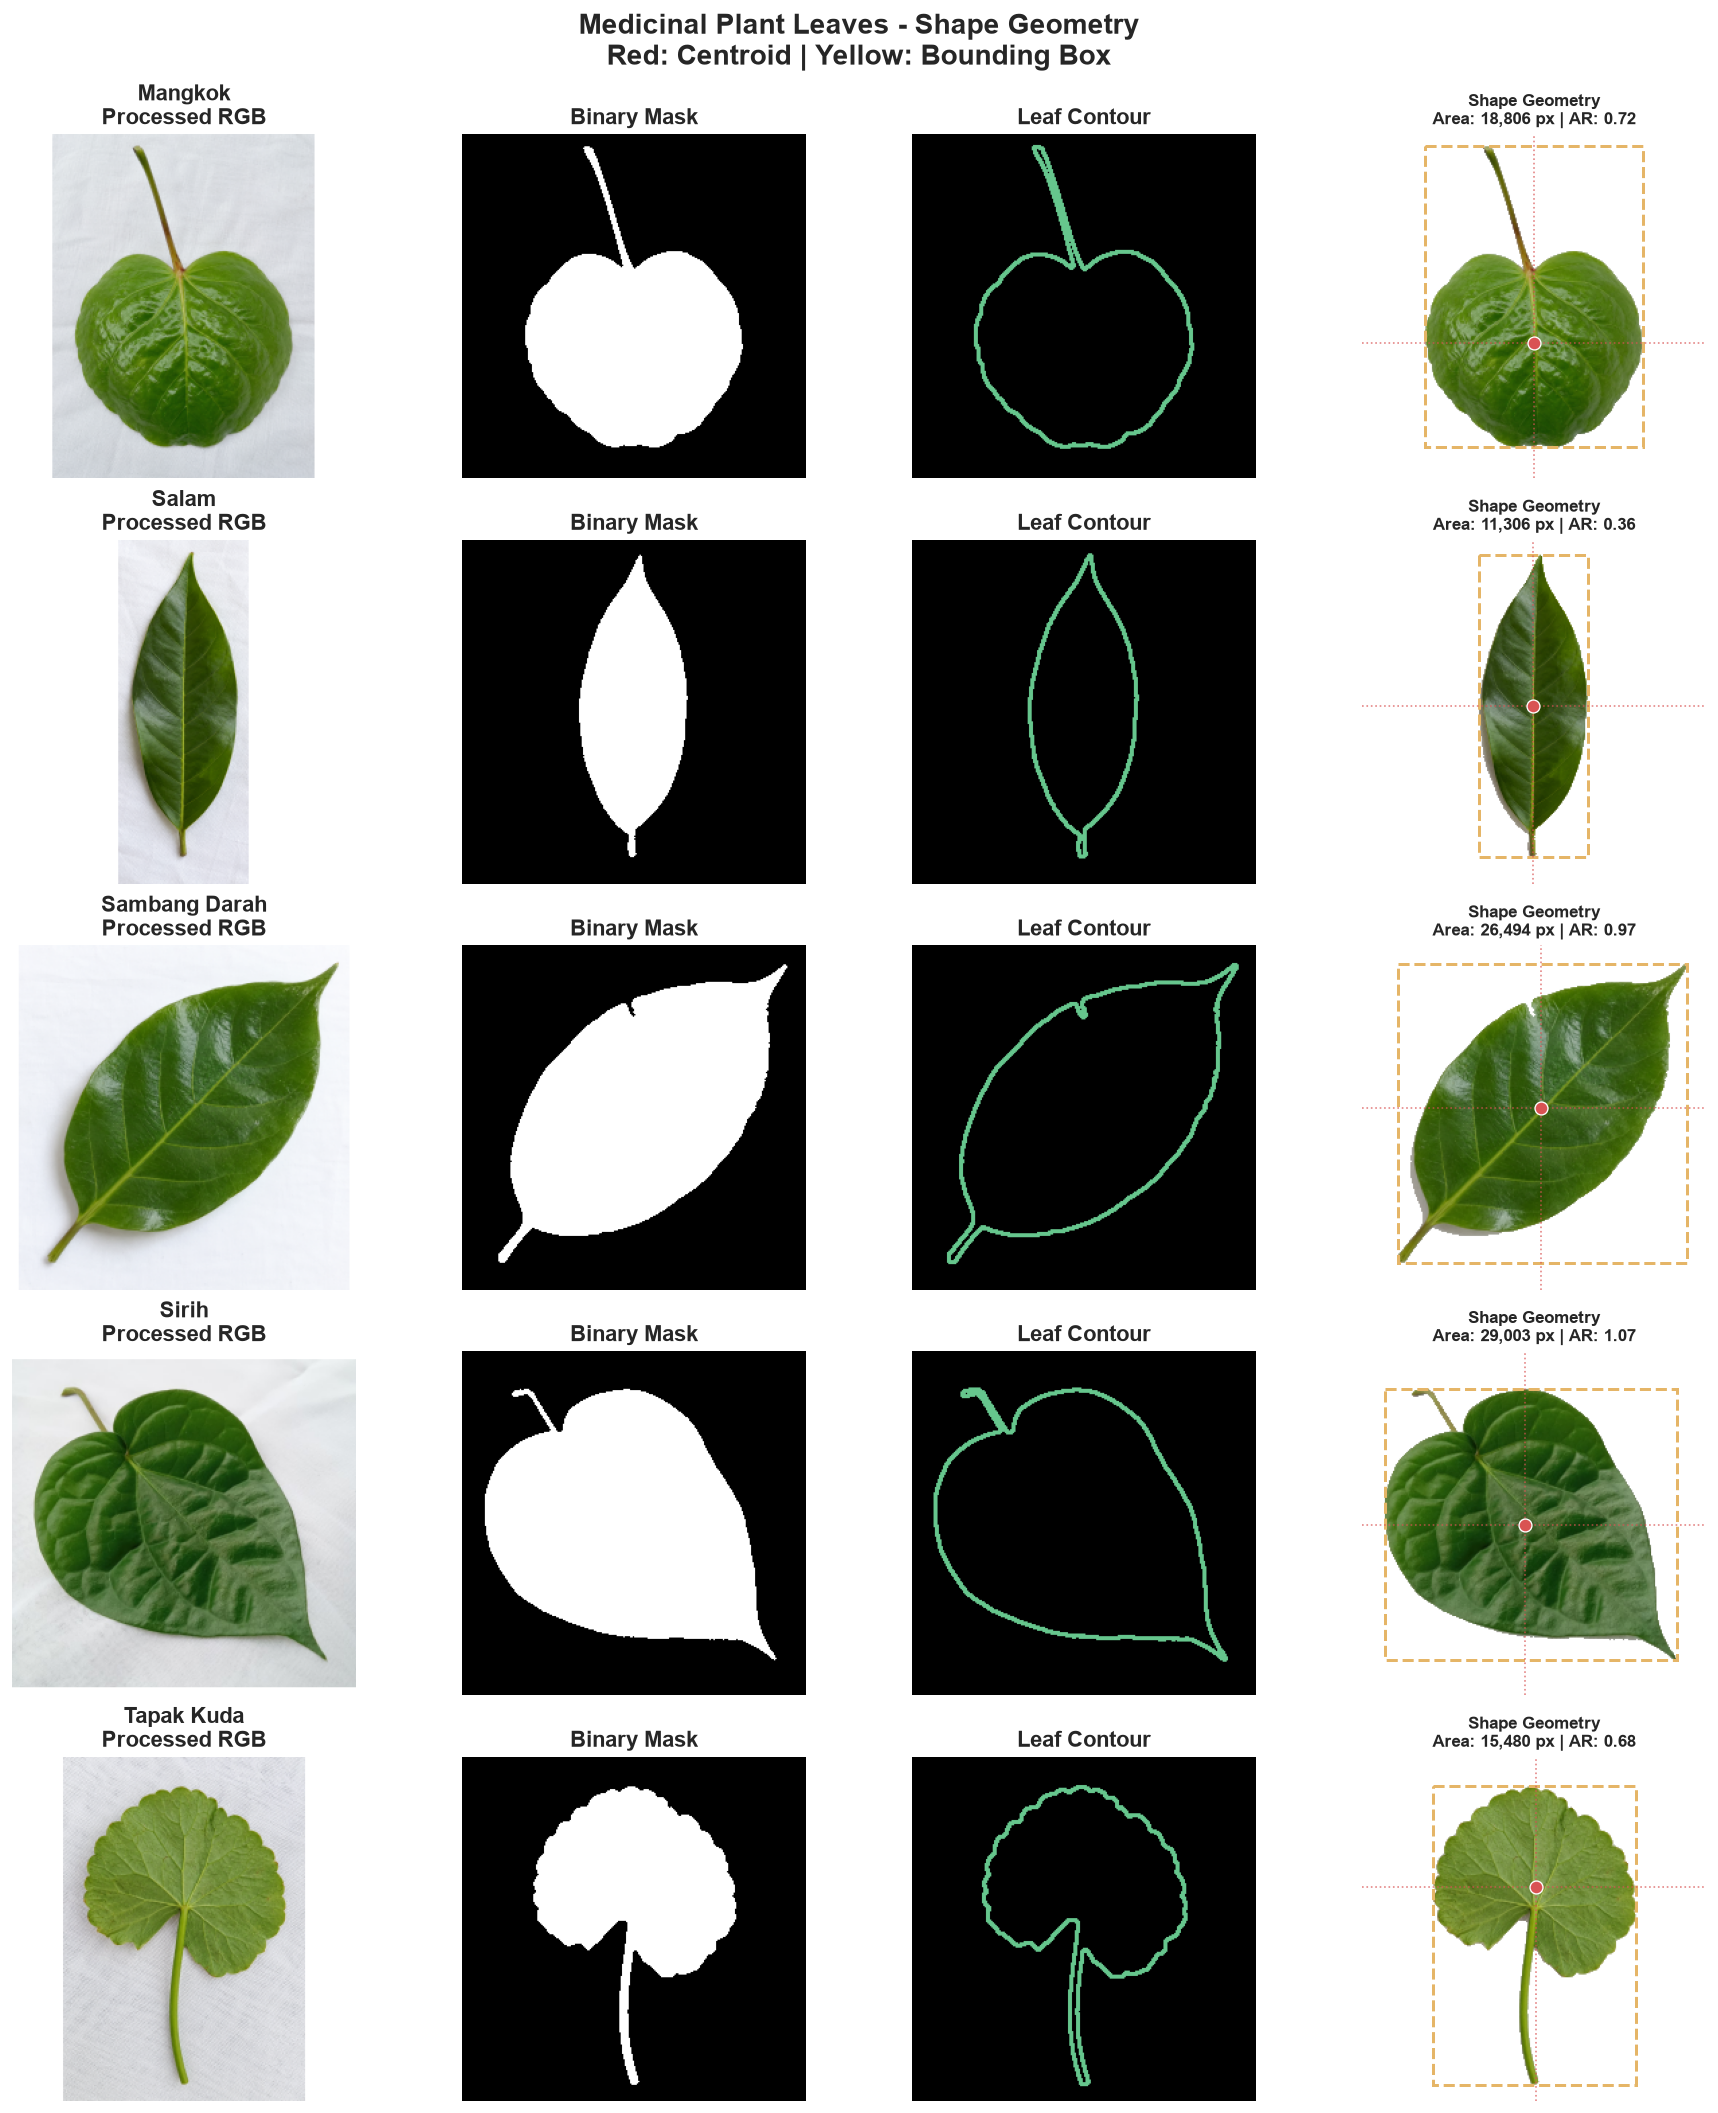


3. RAW HU MOMENTS VISUALIZATION


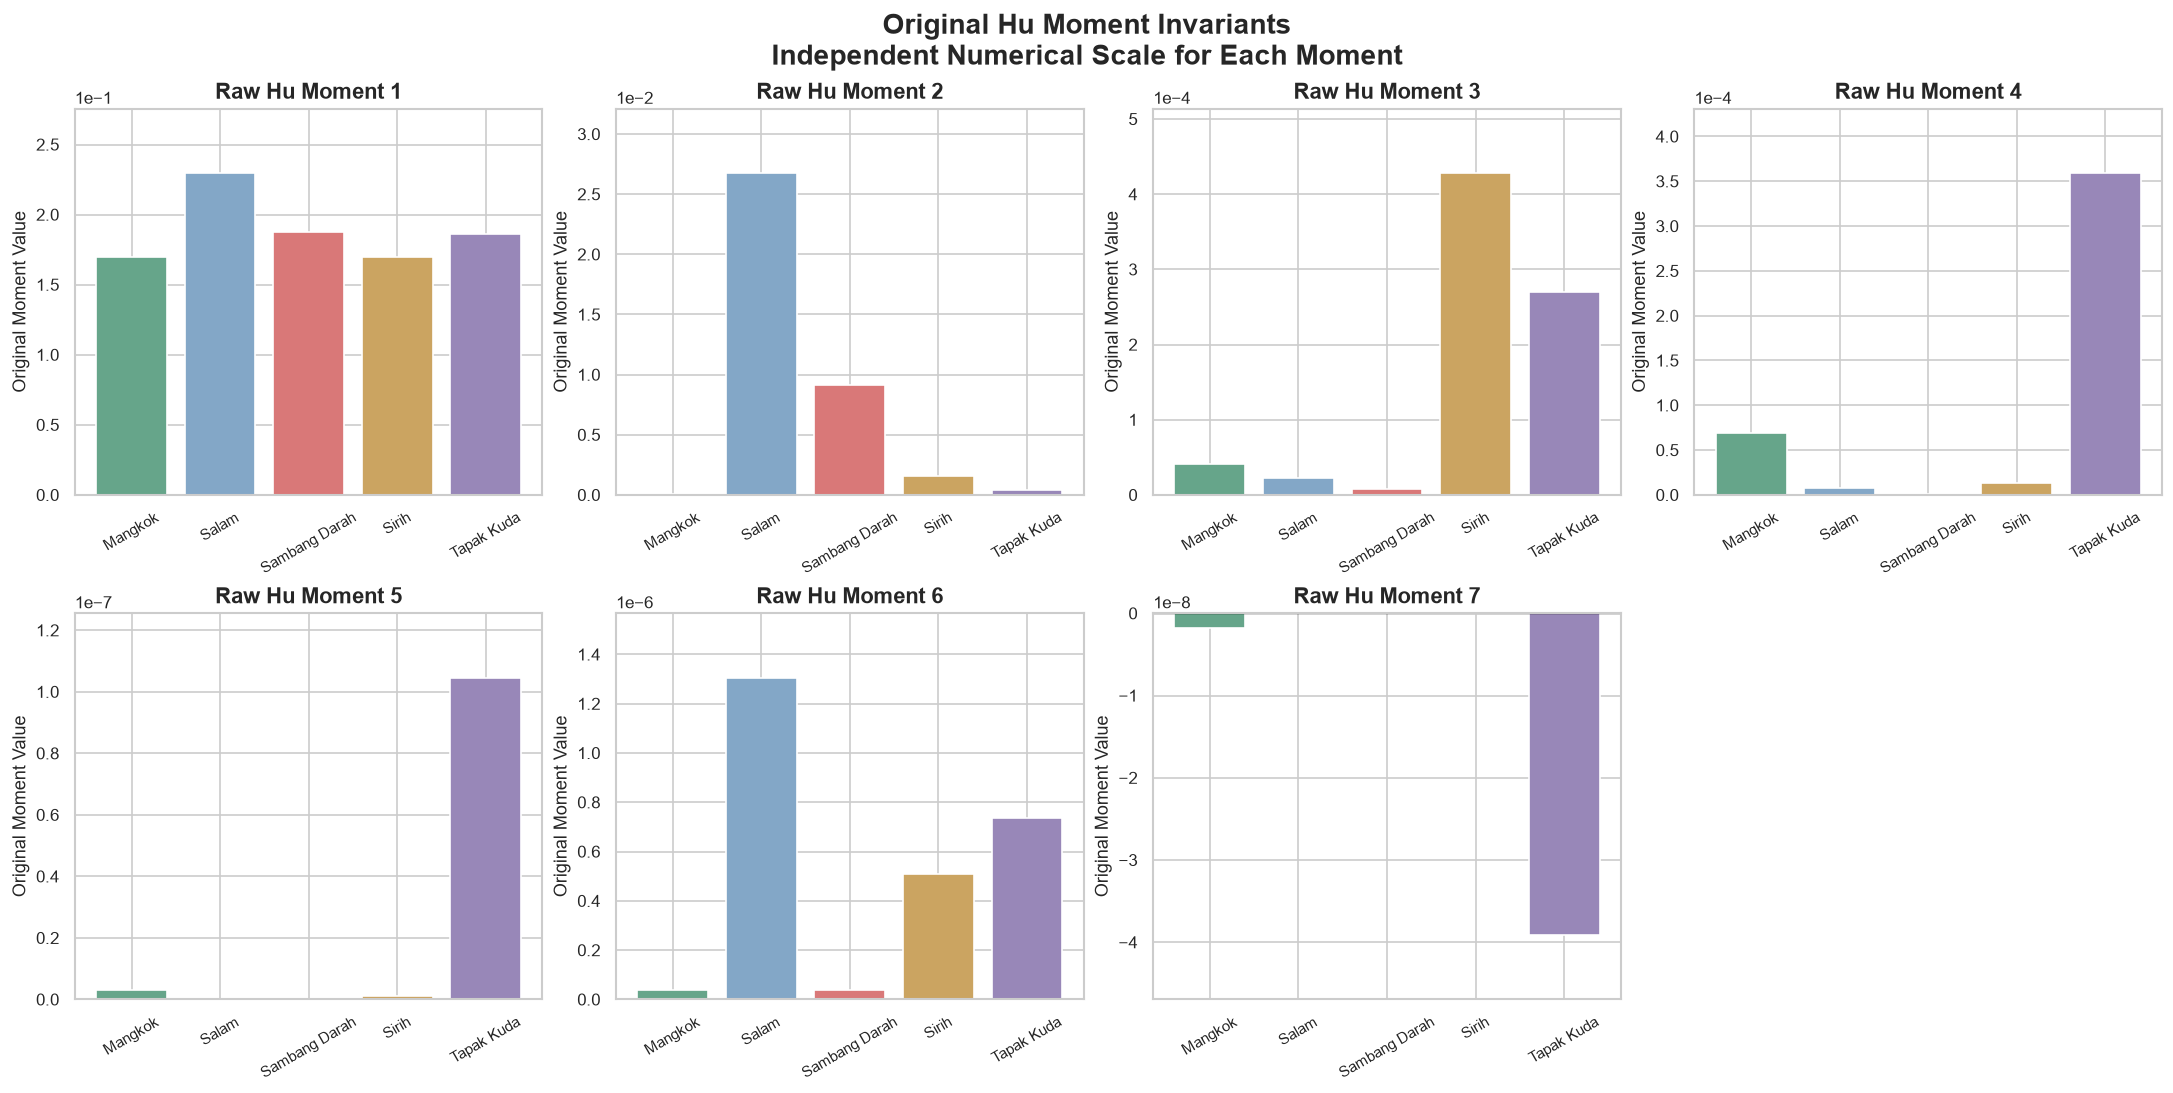


4. TRANSFORMED HU MOMENTS VISUALIZATION


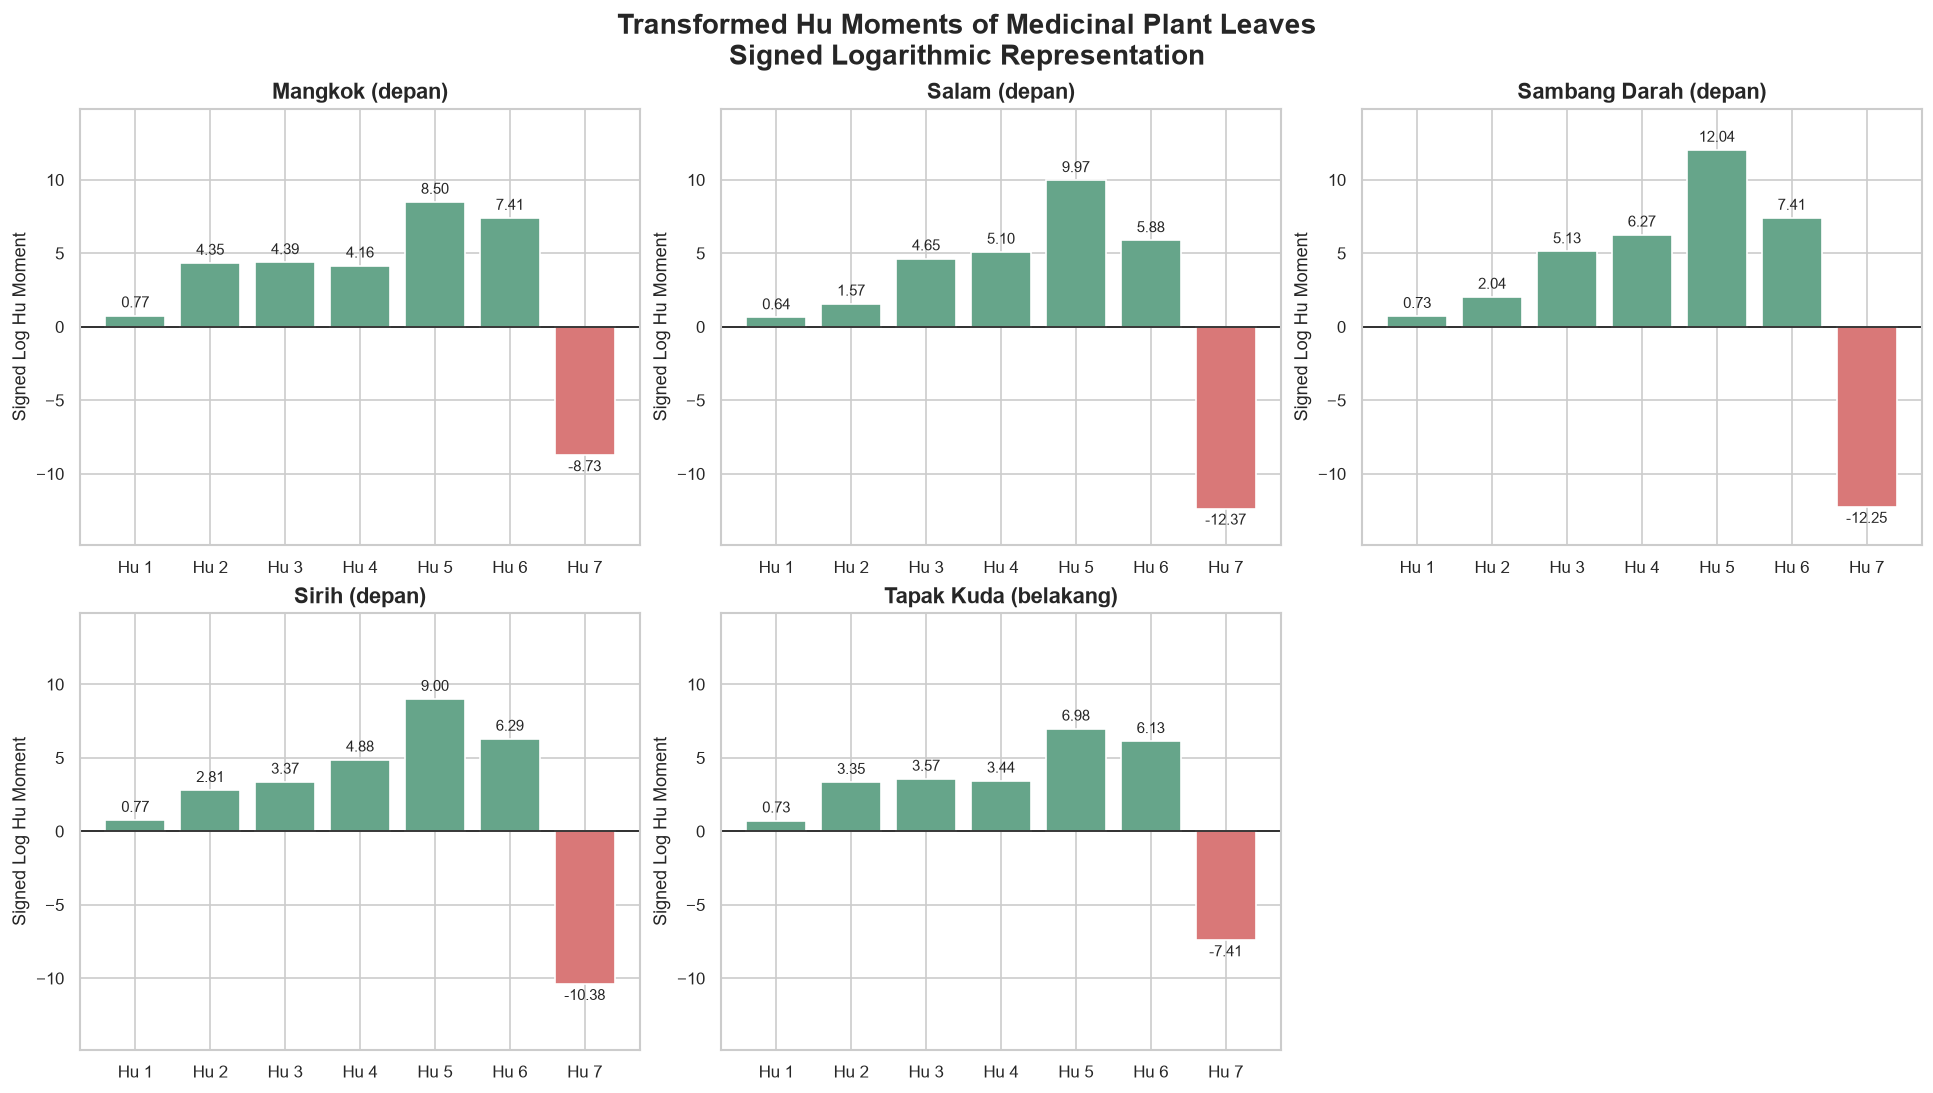


5. HU MOMENTS COMPARISON


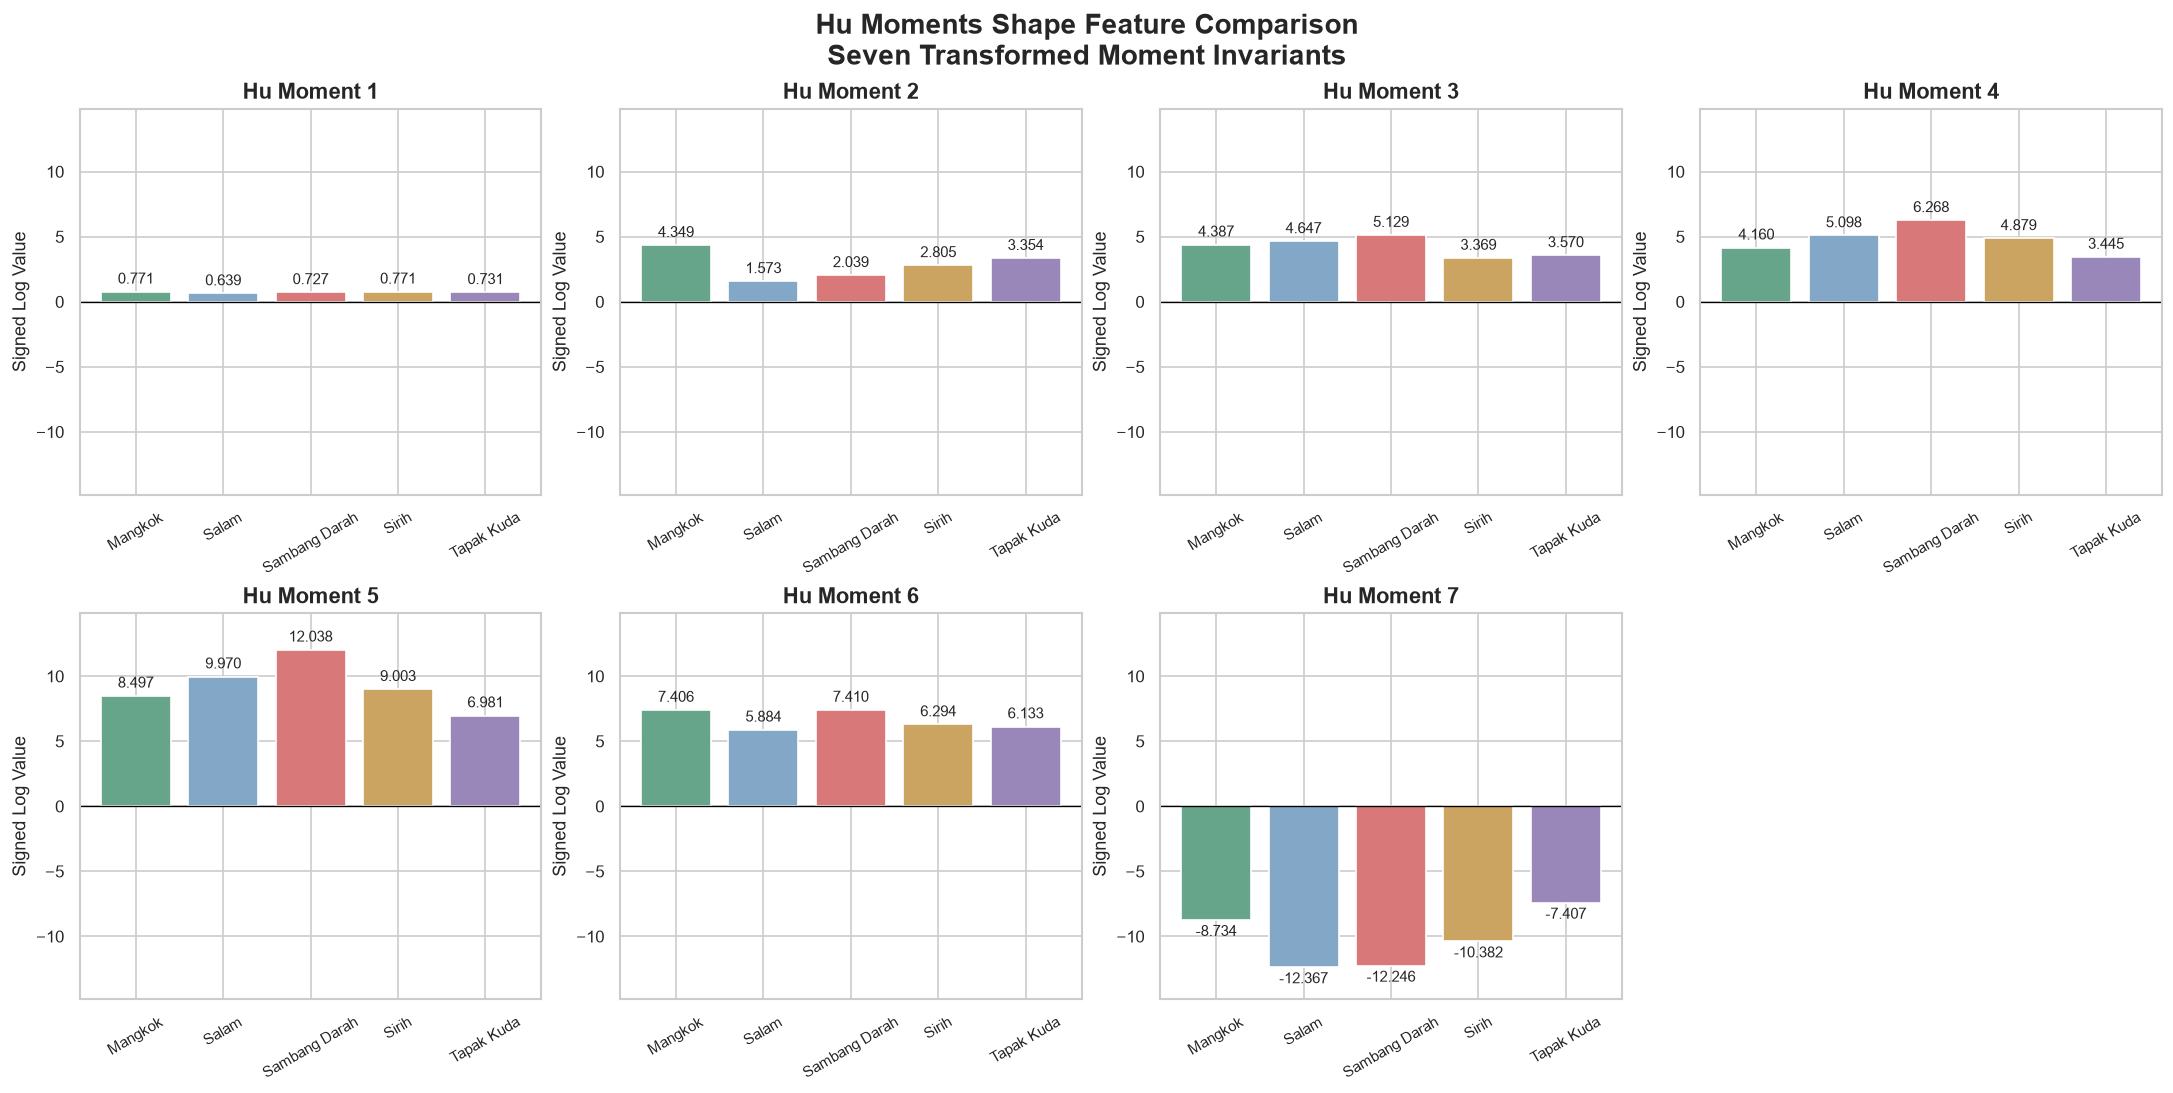


6. HU MOMENTS TRANSFORMATION VISUALIZATION


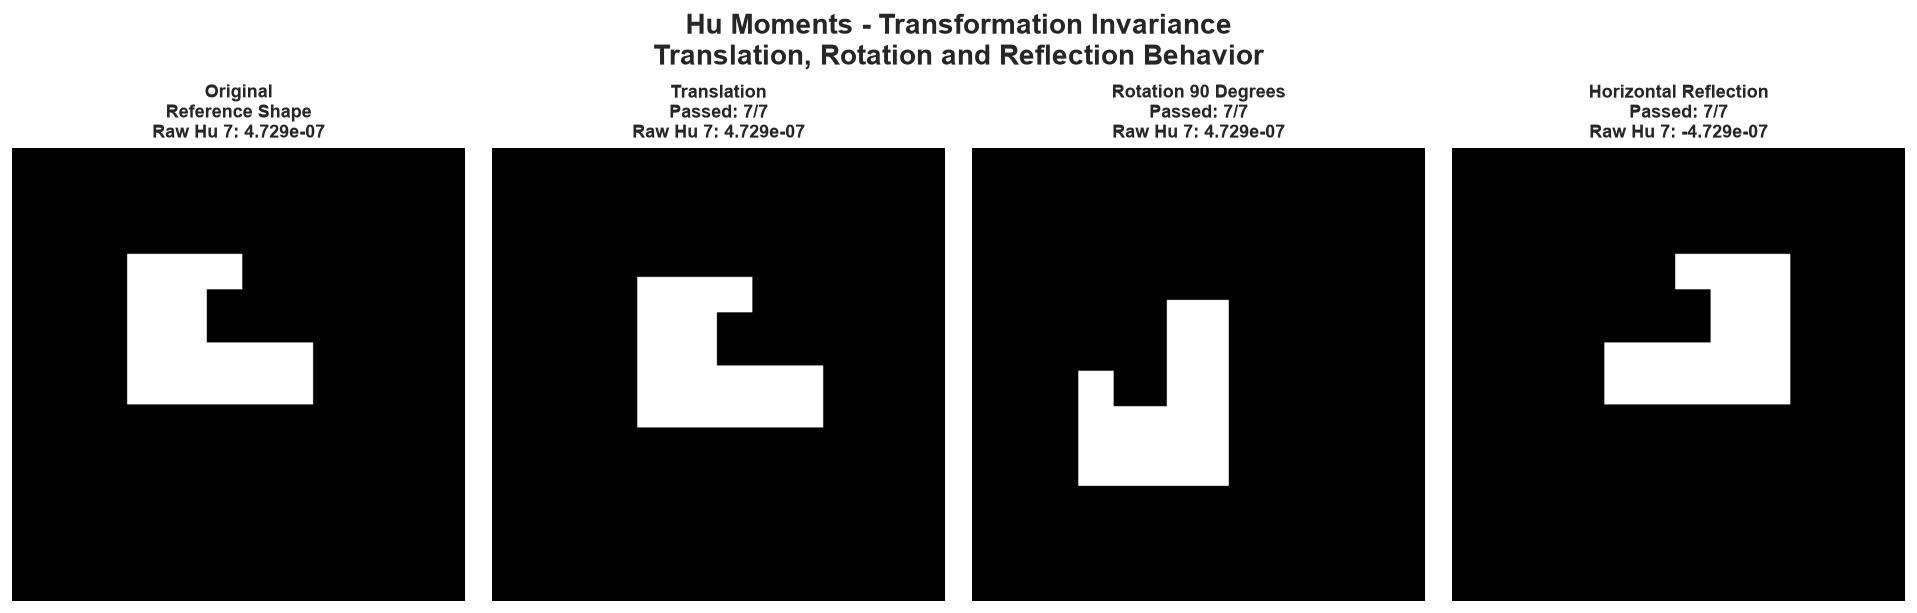

,test,total_moments,passed_moments,maximum_difference,passed
0,Translation,7,7,0.000000,True
1,Rotation 90 Degrees,7,7,0.000000,True
2,Horizontal Reflection,7,7,0.000000,True



7. HU MOMENTS FEATURE MATRIX HEATMAP


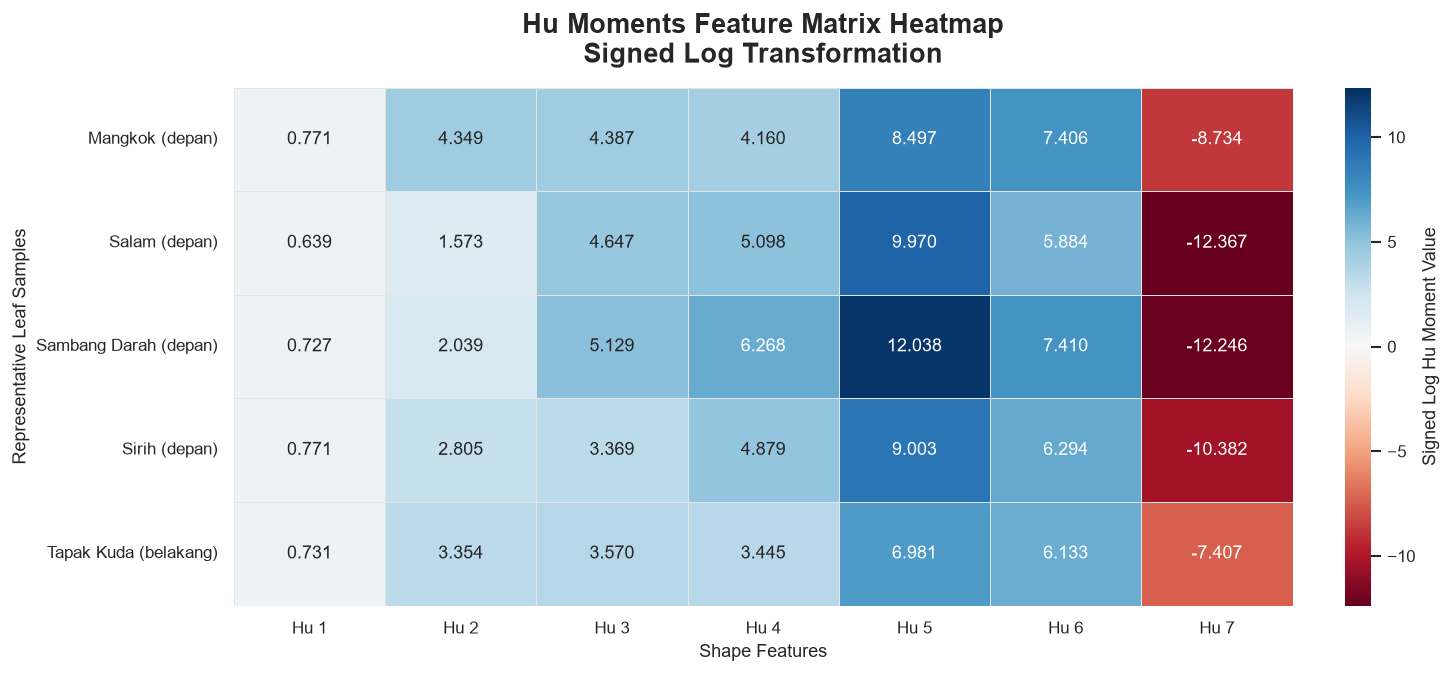


8. HU MOMENTS FEATURE STATISTICS


,moment,raw_minimum,raw_maximum,raw_mean,transformed_minimum,transformed_maximum,transformed_mean,transformed_std,positive_values,negative_values,zero_values
0,Hu_1,1.694208e-01,2.295895e-01,1.883516e-01,0.639048,0.771033,0.727798,0.048191,5,0,0
1,Hu_2,4.479751e-05,2.675232e-02,7.590805e-03,1.572639,4.348746,2.823880,0.978677,5,0,0
2,Hu_3,7.423289e-06,4.280419e-04,1.536669e-04,3.368514,5.129404,4.220430,0.661140,5,0,0
3,Hu_4,5.390049e-07,3.590826e-04,8.999016e-05,3.444806,6.268407,4.770059,0.947883,5,0,0
4,Hu_5,9.170166e-13,1.045906e-07,2.177512e-08,6.980507,12.037623,9.297725,1.676730,5,0,0
5,Hu_6,3.892942e-08,1.305628e-06,5.255630e-07,5.884181,7.409722,6.625416,0.652060,5,0,0
6,Hu_7,-3.913253e-08,-4.295491e-13,-8.204332e-09,-12.366987,-7.407462,-10.227282,1.942239,0,5,0



9. SHAPE GEOMETRY STATISTICS


,kelas,foreground_pixels,foreground_ratio,centroid_x,centroid_y,bounding_box_width,bounding_box_height,aspect_ratio
0,Mangkok,18806,0.287000,127.284200,154.450900,162,224,0.723200
1,Salam,11306,0.172500,127.036100,123.356600,81,225,0.360000
2,Sambang Darah,26494,0.404300,132.484400,120.480400,215,222,0.968500
3,Sirih,29003,0.442600,120.430000,128.820300,217,202,1.074300
4,Tapak Kuda,15480,0.236200,129.047500,96.399200,151,222,0.680200


[INFO] Geometry measurements are for interpretation only.
[INFO] Shape feature dimension remains seven.

[PASS] Original Hu Moments remain unchanged.

10. HU MOMENTS VISUALIZATION SUMMARY


,Indicator,Result
0,Total visualized samples,5.000000
1,Total represented classes,5.000000
2,Raw Hu Moments per sample,7.000000
3,Transformed Hu Moments per sample,7.000000
4,Feature matrix rows,5.000000
5,Feature matrix columns,7.000000
6,Total shape feature values,35.000000
7,Minimum transformed value,-12.366987
8,Maximum transformed value,12.037623
9,Positive transformed values,30.000000



11. GENERATED VISUALIZATIONS


,Visualization,Available,Size (KB)
0,39_hu_leaf_shape_geometry.png,True,1124.690000
1,40_hu_raw_moments_visualization.png,True,324.020000
2,41_hu_transformed_moments_visualization.png,True,323.860000
3,42_hu_moments_comparison.png,True,437.120000
4,43_hu_transformation_invariance.png,True,104.770000
5,44_hu_feature_heatmap.png,True,256.490000



[PASS] HSV, GLCM, and Hu Moments are aligned.

12. FINAL HU MOMENTS VISUALIZATION SUMMARY
Visualized samples : 5
Represented classes: 5
Raw Hu Moments     : 7
Shape features     : 7
Feature matrix     : (5, 7)
Generated figures  : 6

[PASS] Leaf shape geometry visualized.
[PASS] Original Hu Moments visualized.
[PASS] Transformed Hu Moments visualized.
[PASS] Shape feature comparison generated.
[PASS] Transformation invariance visualized.
[PASS] Hu Moments feature heatmap generated.
[PASS] All visualization files saved.
[PASS] Sample alignment preserved.

VISUAL FEATURE EXTRACTION STATUS
------------------------------------------------------------
HSV Histogram : 64 features
GLCM          : 72 features
Hu Moments    : 7 features
Total         : 143 features

[INFO] All three feature extraction methods are ready.
[INFO] Only representative samples were processed.
[INFO] Original feature values remain unchanged.
[INFO] Full dataset extraction begins in Cell 13.

Hu Moments visualization 

In [12]:
# ==================================================
# HU MOMENTS FEATURE VISUALIZATION
# ==================================================

from matplotlib.patches import Rectangle

print("HU MOMENTS FEATURE VISUALIZATION")
print("=" * 60)


# ==================================================
# 1. VALIDATE HU MOMENTS EXTRACTION RESULTS
# ==================================================

hu_n_samples = len(hu_test_samples)

assert hu_n_samples > 0

assert hu_test_features.shape == (
    hu_n_samples,
    HU_FEATURE_DIM
)

assert hu_test_raw_features.shape == (
    hu_n_samples,
    HU_FEATURE_DIM
)

assert np.isfinite(hu_test_features).all()
assert np.isfinite(hu_test_raw_features).all()

assert len(hu_test_details) == hu_n_samples

assert np.array_equal(
    hu_test_samples["sample_id"].to_numpy(),
    hsv_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(
    hu_test_samples["sample_id"].to_numpy(),
    glcm_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(
    hu_test_results_df["sample_id"].to_numpy(),
    hu_test_samples["sample_id"].to_numpy()
)

assert hu_geometry_test_df["passed"].all()
assert hu_log_test_df["passed"].all()
assert hu_synthetic_shape_test_df["passed"].all()
assert hu_invariance_test_df["passed"].all()

print("\n1. HU MOMENTS FEATURE INFORMATION")

print(f"Total samples      : {hu_n_samples}")
print(f"Raw feature matrix : {hu_test_raw_features.shape}")
print(f"Transformed matrix : {hu_test_features.shape}")
print(f"Feature dimension  : {HU_FEATURE_DIM}")

print("[PASS] Hu Moments extraction results are valid.")


# ==================================================
# 2. VISUALIZATION CONFIGURATION
# ==================================================

HU_CLASS_COLORS = {
    "Mangkok": "#66A58A",
    "Salam": "#83A7C7",
    "Sambang Darah": "#D97878",
    "Sirih": "#CBA461",
    "Tapak Kuda": "#9887B8"
}

HU_POSITIVE_COLOR = "#66A58A"
HU_NEGATIVE_COLOR = "#D97878"
HU_ZERO_COLOR = "#BDBDBD"

HU_MOMENT_LABELS = [
    f"Hu {i + 1}"
    for i in range(HU_MOMENTS_COUNT)
]

hu_visualization_paths = []

hu_class_labels = hu_test_samples[
    "kelas"
].tolist()

hu_class_colors = [
    HU_CLASS_COLORS.get(plant_class, "#777777")
    for plant_class in hu_class_labels
]


def save_hu_figure(fig, filename):

    path = FEATURE_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    hu_visualization_paths.append(path)

    plt.show()
    plt.close(fig)


# ==================================================
# 3. VISUALIZE LEAF SHAPE GEOMETRY
# ==================================================

print("\n2. LEAF SHAPE GEOMETRY VISUALIZATION")

fig, axes = plt.subplots(
    hu_n_samples,
    4,
    figsize=(15, 3.5 * hu_n_samples),
    squeeze=False,
    constrained_layout=True
)

for i, (_, row) in enumerate(
    hu_test_samples.iterrows()
):

    sample_id = row["sample_id"]

    details = hu_test_details[sample_id]

    data = load_processed_pair(
        row["absolute_processed_image_path"],
        row["absolute_mask_path"]
    )

    rgb_image = data["rgb_image"]

    binary_mask = details["binary_mask"]

    foreground = binary_mask == 255

    # Verify that the mask has not changed
    assert np.array_equal(
        binary_mask,
        data["binary_mask"]
    )

    centroid_x = details["centroid_x"]
    centroid_y = details["centroid_y"]

    x, y, width, height = details["bounding_box"]

    # --------------------------------------------------
    # A. Create segmented RGB for visualization
    # --------------------------------------------------

    segmented_rgb = np.full_like(
        rgb_image,
        255
    )

    segmented_rgb[foreground] = (
        rgb_image[foreground]
    )

    # --------------------------------------------------
    # B. Find mask contours
    # --------------------------------------------------

    contours = cv2.findContours(
        binary_mask.copy(),
        cv2.RETR_LIST,
        cv2.CHAIN_APPROX_SIMPLE
    )[-2]

    contour_image = np.zeros_like(
        rgb_image
    )

    cv2.drawContours(
        contour_image,
        contours,
        -1,
        (102, 198, 141),
        2
    )

    # --------------------------------------------------
    # C. Processed RGB image
    # --------------------------------------------------

    axes[i, 0].imshow(rgb_image)

    axes[i, 0].set_title(
        f"{row['kelas']}\nProcessed RGB"
    )

    # --------------------------------------------------
    # D. Binary mask
    # --------------------------------------------------

    axes[i, 1].imshow(
        binary_mask,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i, 1].set_title(
        "Binary Mask"
    )

    # --------------------------------------------------
    # E. Leaf contour
    # --------------------------------------------------

    axes[i, 2].imshow(contour_image)

    axes[i, 2].set_title(
        "Leaf Contour"
    )

    # --------------------------------------------------
    # F. Shape geometry
    # --------------------------------------------------

    axes[i, 3].imshow(segmented_rgb)

    bounding_box = Rectangle(
        (x - 0.5, y - 0.5),
        width,
        height,
        linewidth=1.8,
        edgecolor="#E5B567",
        facecolor="none",
        linestyle="--"
    )

    axes[i, 3].add_patch(bounding_box)

    axes[i, 3].scatter(
        centroid_x,
        centroid_y,
        color="#D95353",
        edgecolor="white",
        linewidth=0.8,
        s=60,
        zorder=5
    )

    # Centroid reference lines
    axes[i, 3].axvline(
        centroid_x,
        color="#D95353",
        linestyle=":",
        linewidth=1,
        alpha=0.7
    )

    axes[i, 3].axhline(
        centroid_y,
        color="#D95353",
        linestyle=":",
        linewidth=1,
        alpha=0.7
    )

    axes[i, 3].set_title(
        "Shape Geometry\n"
        f"Area: {details['foreground_pixels']:,} px | "
        f"AR: {details['aspect_ratio']:.2f}",
        fontsize=10
    )

    for ax in axes[i]:
        ax.axis("off")


fig.suptitle(
    "Medicinal Plant Leaves - Shape Geometry\n"
    "Red: Centroid | Yellow: Bounding Box",
    fontsize=17,
    fontweight="bold"
)

save_hu_figure(
    fig,
    "39_hu_leaf_shape_geometry.png"
)


# ==================================================
# 4. VISUALIZE RAW HU MOMENTS
# ==================================================

print("\n3. RAW HU MOMENTS VISUALIZATION")

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 9),
    constrained_layout=True
)

for moment_idx in range(HU_MOMENTS_COUNT):

    ax = axes.ravel()[moment_idx]

    values = hu_test_raw_features[:, moment_idx]

    ax.bar(
        hu_class_labels,
        values,
        color=hu_class_colors
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(
        f"Raw Hu Moment {moment_idx + 1}"
    )

    ax.set_ylabel("Original Moment Value")

    # Each moment has its own numerical scale
    ax.ticklabel_format(
        axis="y",
        style="sci",
        scilimits=(0, 0),
        useOffset=False
    )

    ax.tick_params(
        axis="x",
        rotation=30,
        labelsize=9
    )

    ax.margins(y=0.20)

axes.ravel()[-1].axis("off")

fig.suptitle(
    "Original Hu Moment Invariants\n"
    "Independent Numerical Scale for Each Moment",
    fontsize=17,
    fontweight="bold"
)

save_hu_figure(
    fig,
    "40_hu_raw_moments_visualization.png"
)


# ==================================================
# 5. VISUALIZE TRANSFORMED HU MOMENTS PER SAMPLE
# ==================================================

print("\n4. TRANSFORMED HU MOMENTS VISUALIZATION")

# Use the same y-axis range for every sample
hu_absolute_max = max(
    float(np.abs(hu_test_features).max()),
    1.0
)

hu_plot_rows = int(
    np.ceil(hu_n_samples / 3)
)

fig, axes = plt.subplots(
    hu_plot_rows,
    3,
    figsize=(16, 4.5 * hu_plot_rows),
    squeeze=False,
    constrained_layout=True
)

for i, (_, row) in enumerate(
    hu_test_samples.iterrows()
):

    ax = axes.ravel()[i]

    values = hu_test_features[i]

    bar_colors = [
        HU_POSITIVE_COLOR
        if value > 0
        else HU_NEGATIVE_COLOR
        if value < 0
        else HU_ZERO_COLOR
        for value in values
    ]

    bars = ax.bar(
        HU_MOMENT_LABELS,
        values,
        color=bar_colors
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.9
    )

    ax.set_title(
        f"{row['kelas']} ({row['tampilan_daun']})"
    )

    ax.set_ylabel("Signed Log Hu Moment")

    ax.set_ylim(
        -hu_absolute_max * 1.20,
        hu_absolute_max * 1.20
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

for i in range(
    hu_n_samples,
    len(axes.ravel())
):

    axes.ravel()[i].axis("off")


fig.suptitle(
    "Transformed Hu Moments of Medicinal Plant Leaves\n"
    "Signed Logarithmic Representation",
    fontsize=17,
    fontweight="bold"
)

save_hu_figure(
    fig,
    "41_hu_transformed_moments_visualization.png"
)


# ==================================================
# 6. COMPARE SEVEN HU MOMENTS ACROSS SAMPLES
# ==================================================

print("\n5. HU MOMENTS COMPARISON")

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 9),
    constrained_layout=True
)

for moment_idx in range(HU_MOMENTS_COUNT):

    ax = axes.ravel()[moment_idx]

    values = hu_test_features[:, moment_idx]

    bars = ax.bar(
        hu_class_labels,
        values,
        color=hu_class_colors
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(
        f"Hu Moment {moment_idx + 1}"
    )

    ax.set_ylabel("Signed Log Value")

    ax.set_ylim(
        -hu_absolute_max * 1.20,
        hu_absolute_max * 1.20
    )

    ax.tick_params(
        axis="x",
        rotation=30,
        labelsize=9
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

axes.ravel()[-1].axis("off")

fig.suptitle(
    "Hu Moments Shape Feature Comparison\n"
    "Seven Transformed Moment Invariants",
    fontsize=17,
    fontweight="bold"
)

save_hu_figure(
    fig,
    "42_hu_moments_comparison.png"
)


# ==================================================
# 7. VISUALIZE TRANSFORMATION INVARIANCE
# ==================================================

print("\n6. HU MOMENTS TRANSFORMATION VISUALIZATION")

# Reuse synthetic masks from Cell 11
invariance_visual_masks = {
    "Original": synthetic_shape_mask,
    **invariance_test_masks
}

fig, axes = plt.subplots(
    1,
    len(invariance_visual_masks),
    figsize=(16, 5),
    squeeze=False,
    constrained_layout=True
)

invariance_visual_records = []

for i, (test_name, test_mask) in enumerate(
    invariance_visual_masks.items()
):

    ax = axes[0, i]

    ax.imshow(
        test_mask,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    if test_name == "Original":

        raw_hu = original_shape_raw_hu

        status_text = "Reference Shape"

        passed_moments = np.nan
        total_moments = HU_MOMENTS_COUNT
        maximum_difference = 0.0

    else:

        test_records = (
            hu_invariance_test_df[
                hu_invariance_test_df["test"].eq(
                    test_name
                )
            ]
            .set_index("moment")
            .loc[
                [
                    f"Hu_{j + 1}"
                    for j in range(HU_MOMENTS_COUNT)
                ]
            ]
        )

        raw_hu = test_records[
            "actual_value"
        ].to_numpy()

        passed_moments = int(
            test_records["passed"].sum()
        )

        total_moments = len(test_records)

        maximum_difference = float(
            test_records[
                "absolute_difference"
            ].max()
        )

        status_text = (
            f"Passed: {passed_moments}/"
            f"{total_moments}"
        )

    ax.set_title(
        f"{test_name}\n"
        f"{status_text}\n"
        f"Raw Hu 7: {raw_hu[6]:.3e}",
        fontsize=11
    )

    ax.axis("off")

    invariance_visual_records.append({
        "transformation": test_name,
        "raw_hu_1": float(raw_hu[0]),
        "raw_hu_7": float(raw_hu[6]),
        "passed_moments": passed_moments,
        "total_moments": total_moments,
        "maximum_difference": maximum_difference
    })


hu_invariance_visualization_df = pd.DataFrame(
    invariance_visual_records
)

fig.suptitle(
    "Hu Moments - Transformation Invariance\n"
    "Translation, Rotation and Reflection Behavior",
    fontsize=17,
    fontweight="bold"
)

save_hu_figure(
    fig,
    "43_hu_transformation_invariance.png"
)

display(hu_invariance_summary_df)


# ==================================================
# 8. VISUALIZE HU MOMENTS FEATURE HEATMAP
# ==================================================

print("\n7. HU MOMENTS FEATURE MATRIX HEATMAP")

hu_heatmap_labels = [
    f"{row['kelas']} ({row['tampilan_daun']})"
    for _, row in hu_test_samples.iterrows()
]

# Diverging color scale centered at zero
# Negative and positive moments remain distinguishable.

hu_heatmap_limit = max(
    float(np.abs(hu_test_features).max()),
    EPSILON
)

fig, ax = plt.subplots(
    figsize=(12, 5.5),
    constrained_layout=True
)

sns.heatmap(
    hu_test_features,
    annot=True,
    fmt=".3f",
    cmap="RdBu",
    center=0,
    vmin=-hu_heatmap_limit,
    vmax=hu_heatmap_limit,
    linewidths=0.5,
    linecolor="#E5E5E5",
    xticklabels=HU_MOMENT_LABELS,
    yticklabels=hu_heatmap_labels,
    cbar_kws={
        "label": "Signed Log Hu Moment Value"
    },
    ax=ax
)

ax.set_xticklabels(
    HU_MOMENT_LABELS,
    rotation=0
)

ax.set_yticklabels(
    hu_heatmap_labels,
    rotation=0
)

ax.set_title(
    "Hu Moments Feature Matrix Heatmap\n"
    "Signed Log Transformation",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Shape Features")
ax.set_ylabel("Representative Leaf Samples")

save_hu_figure(
    fig,
    "44_hu_feature_heatmap.png"
)


# ==================================================
# 9. ANALYZE HU MOMENTS STATISTICS
# ==================================================

print("\n8. HU MOMENTS FEATURE STATISTICS")

hu_feature_statistics_records = []

for i in range(HU_MOMENTS_COUNT):

    raw_values = hu_test_raw_features[:, i]

    transformed_values = hu_test_features[:, i]

    hu_feature_statistics_records.append({
        "moment": f"Hu_{i + 1}",

        "raw_minimum": float(raw_values.min()),

        "raw_maximum": float(raw_values.max()),

        "raw_mean": float(raw_values.mean()),

        "transformed_minimum": float(
            transformed_values.min()
        ),

        "transformed_maximum": float(
            transformed_values.max()
        ),

        "transformed_mean": float(
            transformed_values.mean()
        ),

        "transformed_std": float(
            transformed_values.std(ddof=0)
        ),

        "positive_values": int(
            np.count_nonzero(transformed_values > 0)
        ),

        "negative_values": int(
            np.count_nonzero(transformed_values < 0)
        ),

        "zero_values": int(
            np.count_nonzero(transformed_values == 0)
        )
    })


hu_feature_statistics_df = pd.DataFrame(
    hu_feature_statistics_records
)

assert len(hu_feature_statistics_df) == (
    HU_MOMENTS_COUNT
)

assert (
    hu_feature_statistics_df["positive_values"]
    + hu_feature_statistics_df["negative_values"]
    + hu_feature_statistics_df["zero_values"]
).eq(hu_n_samples).all()

display(
    hu_feature_statistics_df.style.format({
        "raw_minimum": "{:.6e}",
        "raw_maximum": "{:.6e}",
        "raw_mean": "{:.6e}",
        "transformed_minimum": "{:.6f}",
        "transformed_maximum": "{:.6f}",
        "transformed_mean": "{:.6f}",
        "transformed_std": "{:.6f}"
    })
)


# ==================================================
# 10. DISPLAY SHAPE GEOMETRY STATISTICS
# ==================================================

print("\n9. SHAPE GEOMETRY STATISTICS")

display(
    hu_shape_statistics_df[
        [
            "kelas",
            "foreground_pixels",
            "foreground_ratio",
            "centroid_x",
            "centroid_y",
            "bounding_box_width",
            "bounding_box_height",
            "aspect_ratio"
        ]
    ].round(4)
)

print(
    "[INFO] Geometry measurements are for "
    "interpretation only."
)

print(
    "[INFO] Shape feature dimension remains seven."
)


# ==================================================
# 11. VERIFY ORIGINAL FEATURES REMAIN UNCHANGED
# ==================================================

recomputed_hu_features = np.vstack([
    transform_hu_moments(raw_vector)
    for raw_vector in hu_test_raw_features
])

assert np.allclose(
    hu_test_features,
    recomputed_hu_features,
    rtol=0,
    atol=1e-12
)

assert np.isfinite(hu_test_features).all()

assert np.array_equal(
    hu_test_feature_df["sample_id"].to_numpy(),
    hu_test_samples["sample_id"].to_numpy()
)

print("\n[PASS] Original Hu Moments remain unchanged.")


# ==================================================
# 12. CREATE VISUALIZATION SUMMARY
# ==================================================

hu_visualization_summary_df = pd.DataFrame({
    "Indicator": [
        "Total visualized samples",
        "Total represented classes",
        "Raw Hu Moments per sample",
        "Transformed Hu Moments per sample",
        "Feature matrix rows",
        "Feature matrix columns",
        "Total shape feature values",
        "Minimum transformed value",
        "Maximum transformed value",
        "Positive transformed values",
        "Negative transformed values",
        "Zero transformed values",
        "Invariance moment tests passed",
        "Generated visualizations"
    ],

    "Result": [
        hu_n_samples,
        hu_test_samples["kelas"].nunique(),
        HU_MOMENTS_COUNT,
        HU_FEATURE_DIM,
        hu_test_features.shape[0],
        hu_test_features.shape[1],
        hu_test_features.size,
        float(hu_test_features.min()),
        float(hu_test_features.max()),
        int(np.count_nonzero(hu_test_features > 0)),
        int(np.count_nonzero(hu_test_features < 0)),
        int(np.count_nonzero(hu_test_features == 0)),
        int(hu_invariance_test_df["passed"].sum()),
        len(hu_visualization_paths)
    ]
})

print("\n10. HU MOMENTS VISUALIZATION SUMMARY")

display(hu_visualization_summary_df)


# ==================================================
# 13. VALIDATE GENERATED VISUALIZATIONS
# ==================================================

hu_visualization_validation_df = pd.DataFrame([
    {
        "Visualization": path.name,

        "Available": path.is_file(),

        "Size (KB)": (
            round(path.stat().st_size / 1024, 2)
            if path.is_file()
            else 0
        )
    }
    for path in hu_visualization_paths
])

print("\n11. GENERATED VISUALIZATIONS")

display(hu_visualization_validation_df)

assert len(hu_visualization_paths) == 6

assert hu_visualization_validation_df[
    "Available"
].all()

assert hu_visualization_validation_df[
    "Size (KB)"
].gt(0).all()


# ==================================================
# 14. SAVE HU MOMENTS VISUALIZATION REPORTS
# ==================================================

hu_visualization_reports = {
    "125_hu_feature_statistics.csv":
        hu_feature_statistics_df,

    "126_hu_invariance_visualization.csv":
        hu_invariance_visualization_df,

    "127_hu_visualization_summary.csv":
        hu_visualization_summary_df,

    "128_hu_visualization_artifact_validation.csv":
        hu_visualization_validation_df
}

for filename, dataframe in (
    hu_visualization_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )


# ==================================================
# 15. VERIFY THREE VISUAL FEATURE GROUPS
# ==================================================

assert np.array_equal(
    hsv_test_samples["sample_id"].to_numpy(),
    glcm_test_samples["sample_id"].to_numpy()
)

assert np.array_equal(
    glcm_test_samples["sample_id"].to_numpy(),
    hu_test_samples["sample_id"].to_numpy()
)

assert hsv_test_features.shape == (
    hu_n_samples,
    HSV_FEATURE_DIM
)

assert glcm_test_features.shape == (
    hu_n_samples,
    GLCM_FEATURE_DIM
)

assert hu_test_features.shape == (
    hu_n_samples,
    HU_FEATURE_DIM
)

assert (
    HSV_FEATURE_DIM
    + GLCM_FEATURE_DIM
    + HU_FEATURE_DIM
) == TOTAL_VISUAL_FEATURE_DIM

print("\n[PASS] HSV, GLCM, and Hu Moments are aligned.")


# ==================================================
# 16. FINAL HU MOMENTS VISUALIZATION SUMMARY
# ==================================================

print("\n12. FINAL HU MOMENTS VISUALIZATION SUMMARY")
print("=" * 60)

print(f"Visualized samples : {hu_n_samples}")

print(
    f"Represented classes: "
    f"{hu_test_samples['kelas'].nunique()}"
)

print(f"Raw Hu Moments     : {HU_MOMENTS_COUNT}")
print(f"Shape features     : {HU_FEATURE_DIM}")
print(f"Feature matrix     : {hu_test_features.shape}")

print(
    f"Generated figures  : "
    f"{len(hu_visualization_paths)}"
)

print("\n[PASS] Leaf shape geometry visualized.")
print("[PASS] Original Hu Moments visualized.")
print("[PASS] Transformed Hu Moments visualized.")
print("[PASS] Shape feature comparison generated.")
print("[PASS] Transformation invariance visualized.")
print("[PASS] Hu Moments feature heatmap generated.")
print("[PASS] All visualization files saved.")
print("[PASS] Sample alignment preserved.")

print("\nVISUAL FEATURE EXTRACTION STATUS")
print("-" * 60)

print(f"HSV Histogram : {HSV_FEATURE_DIM} features")
print(f"GLCM          : {GLCM_FEATURE_DIM} features")
print(f"Hu Moments    : {HU_FEATURE_DIM} features")
print(f"Total         : {TOTAL_VISUAL_FEATURE_DIM} features")

print("\n[INFO] All three feature extraction methods are ready.")
print("[INFO] Only representative samples were processed.")
print("[INFO] Original feature values remain unchanged.")
print("[INFO] Full dataset extraction begins in Cell 13.")

print("\nHu Moments visualization completed successfully!")

print("\nNext cell: Cell 13 - Batch Feature Extraction")

BATCH FEATURE EXTRACTION

1. FEATURE EXTRACTION CONFIGURATION
HSV features : 64
GLCM features: 72
Hu Moments   : 7
Total        : 143
[PASS] All extraction functions are available.

2. BATCH DATASET INFORMATION
Total samples: 104
Total classes: 5


,kelas,validation_status,count
0,Tapak Kuda,Needs Review,25
1,Sambang Darah,Needs Review,16
2,Mangkok,Passed Initial Check,11
3,Salam,Needs Review,10
4,Sirih,Passed Initial Check,10
5,Sirih,Needs Review,10
6,Mangkok,Needs Review,9
7,Salam,Passed Initial Check,9
8,Sambang Darah,Passed Initial Check,4



[OK] Feature vector validation initialized.
[OK] Single sample extraction function initialized.

3. EXTRACTING VISUAL FEATURES
Processing 104 samples...


Batch feature extraction:   0%|          | 0/104 [00:00<?, ?it/s]


4. BATCH EXTRACTION RESULTS
Total samples : 104
Successful    : 104
Failed        : 0
Total time    : 0.7299 seconds

5. VISUAL FEATURE MATRICES
HSV Histogram : (104, 64)
GLCM          : (104, 72)
Hu Moments    : (104, 7)
Raw Hu Moments: (104, 7)

6. MATRIX VALIDATION
[PASS] All feature dimensions are consistent.
[PASS] No NaN or infinite values detected.
[PASS] Feature and metadata alignment preserved.
[PASS] All processed samples are accounted for.

7. REPRESENTATIVE SAMPLE CONSISTENCY


,sample_id,kelas,hsv_max_difference,glcm_max_difference,hu_max_difference,passed,status
0,leaf_8f09fd62c7391c0d,Mangkok,0.000000,0.000000,0.000000,True,Consistent
1,leaf_9c7d463a5bb1a561,Salam,0.000000,0.000000,0.000000,True,Consistent
2,leaf_d9d0b97961feaeac,Sambang Darah,0.000000,0.000000,0.000000,True,Consistent
3,leaf_338b7ee25be7d52d,Sirih,0.000000,0.000000,0.000000,True,Consistent
4,leaf_721244faca19b94f,Tapak Kuda,0.000000,0.000000,0.000000,True,Consistent


... (10 outputs left out)

[INFO] Existing review statuses are preserved.
[INFO] Successful extraction does not imply complete manual verification.

13. FEATURE EXTRACTION TIME


,feature_group,total_time_ms,mean_time_ms,median_time_ms,minimum_time_ms,maximum_time_ms,std_time_ms
0,HSV,66.470800,0.639100,0.609900,0.503600,1.194300,0.122600
1,GLCM,369.184400,3.549800,3.465300,2.740400,5.634600,0.537700
2,Hu Moments,45.961200,0.441900,0.400800,0.356300,1.001000,0.110300
3,Total Extraction,481.616400,4.630900,4.488300,3.664400,7.607600,0.627400



14. FEATURE MATRIX SUMMARY


,feature_group,number_of_samples,feature_dimension,total_values,minimum_value,maximum_value,zero_values,negative_values,nan_values,infinite_values,data_type
0,HSV,104,64,6656,0.000000,0.968563,3034,0,0,0,float64
1,GLCM,104,72,7488,0.008254,15.209430,0,0,0,0,float64
2,Hu Moments,104,7,728,-12.853698,13.568041,0,113,0,0,float64


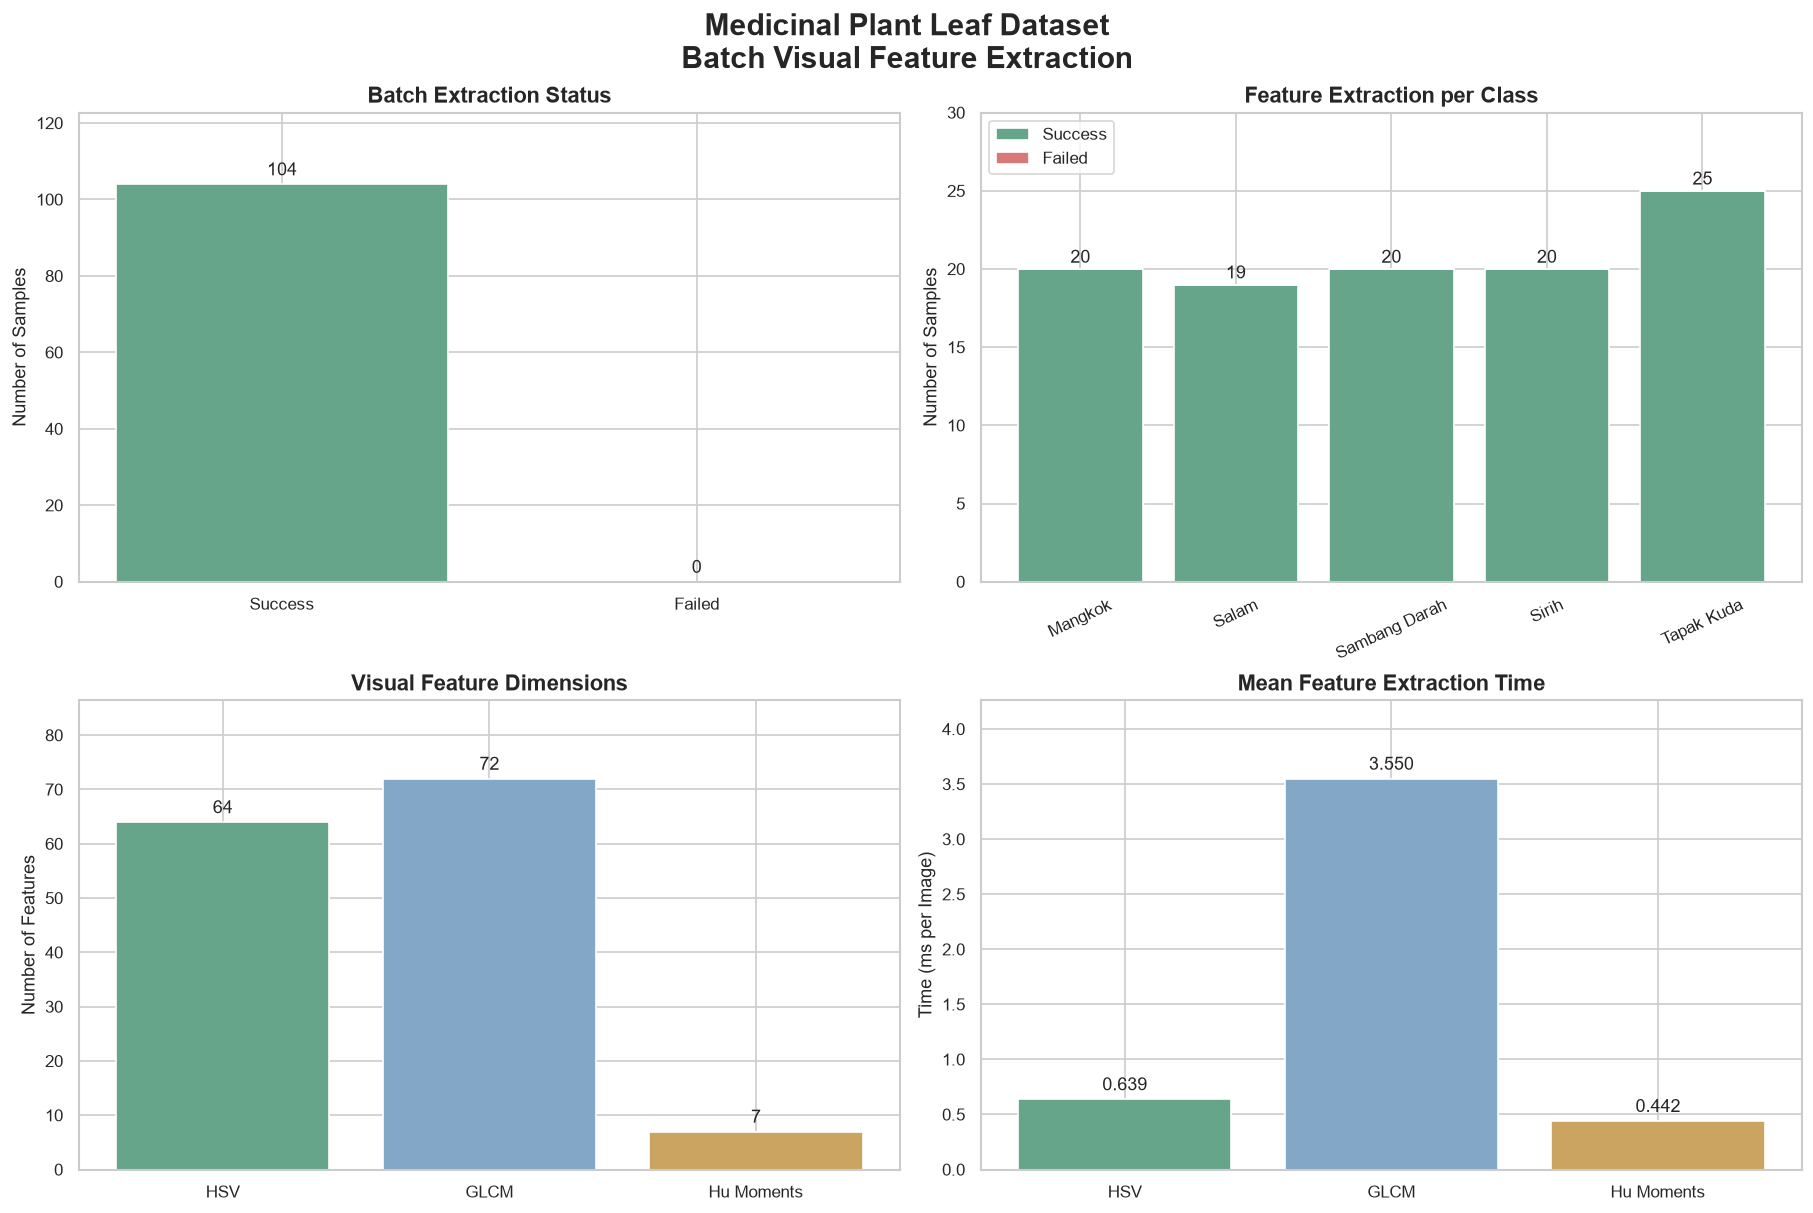


15. BATCH EXTRACTION SUMMARY


,Indicator,Result
0,Total input samples,104
1,Successful extractions,104
2,Failed extractions,0
3,Success rate (%),100.000000
4,Represented classes,5
5,HSV feature dimension,64
6,GLCM feature dimension,72
7,Hu Moments feature dimension,7
8,Total visual feature dimension,143
9,Total extracted feature values,14872



16. FINAL BATCH EXTRACTION SUMMARY
Total input samples : 104
Successful samples  : 104
Failed samples      : 0
Represented classes : 5

FEATURE MATRIX DIMENSIONS
------------------------------------------------------------
HSV Histogram : (104, 64)
GLCM          : (104, 72)
Hu Moments    : (104, 7)
Total feature dimension: 143
Total extracted values : 14,872
Batch processing time  : 0.7299 seconds

[PASS] All samples extracted successfully.
[PASS] HSV feature dimensions are consistent.
[PASS] GLCM feature dimensions are consistent.
[PASS] Hu Moments feature dimensions are consistent.
[PASS] No NaN or infinite features detected.
[PASS] Representative sample consistency verified.
[PASS] Image and metadata alignment preserved.
[PASS] Dataset review statuses preserved.
[PASS] Intermediate feature reports saved.

[INFO] Feature groups remain separate.
[INFO] StandardScaler has not been fitted.
[INFO] Feature concatenation has not been performed.
[INFO] Final feature files will be saved in 

In [13]:
# ==================================================
# BATCH FEATURE EXTRACTION
# ==================================================

import time

print("BATCH FEATURE EXTRACTION")
print("=" * 60)


# ==================================================
# 1. VALIDATE EXTRACTION CONFIGURATION
# ==================================================

assert callable(extract_hsv_features)
assert callable(extract_glcm_features)
assert callable(extract_hu_features)

assert HSV_FEATURE_DIM == 64
assert GLCM_FEATURE_DIM == 72
assert HU_FEATURE_DIM == 7
assert TOTAL_VISUAL_FEATURE_DIM == 143

assert (
    HSV_FEATURE_DIM
    + GLCM_FEATURE_DIM
    + HU_FEATURE_DIM
) == TOTAL_VISUAL_FEATURE_DIM

assert df_image_validated["technical_valid"].all()

assert df_image_validated["sample_id"].is_unique
assert df_image_validated["sample_id"].notna().all()

print("\n1. FEATURE EXTRACTION CONFIGURATION")

print(f"HSV features : {HSV_FEATURE_DIM}")
print(f"GLCM features: {GLCM_FEATURE_DIM}")
print(f"Hu Moments   : {HU_FEATURE_DIM}")
print(f"Total        : {TOTAL_VISUAL_FEATURE_DIM}")

print("[PASS] All extraction functions are available.")


# ==================================================
# 2. PREPARE BATCH DATASET
# ==================================================

df_batch_input = (
    df_image_validated.copy()
    .reset_index(drop=True)
)

BATCH_TOTAL_SAMPLES = len(df_batch_input)

required_batch_columns = [
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "absolute_processed_image_path",
    "absolute_mask_path",
    "validation_status"
]

missing_batch_columns = [
    column
    for column in required_batch_columns
    if column not in df_batch_input.columns
]

assert not missing_batch_columns, (
    f"Missing columns: {missing_batch_columns}"
)

assert BATCH_TOTAL_SAMPLES > 0

print("\n2. BATCH DATASET INFORMATION")

print(f"Total samples: {BATCH_TOTAL_SAMPLES}")

print(
    f"Total classes: "
    f"{df_batch_input['kelas'].nunique()}"
)

display(
    df_batch_input[
        [
            "kelas",
            "validation_status"
        ]
    ].value_counts().reset_index(name="count")
)


# ==================================================
# 3. DEFINE FEATURE VECTOR VALIDATION
# ==================================================

def validate_extracted_vector(
    feature_vector,
    expected_dimension,
    feature_name
):

    """
    Validate the shape and numerical values
    of an extracted feature vector.
    """

    feature_vector = np.asarray(
        feature_vector,
        dtype=FEATURE_DTYPE
    )

    if feature_vector.shape != (
        expected_dimension,
    ):

        raise ValueError(
            f"{feature_name}: invalid dimension "
            f"{feature_vector.shape}"
        )

    if not np.isfinite(feature_vector).all():

        raise ValueError(
            f"{feature_name}: NaN or infinity detected."
        )

    return feature_vector


print("\n[OK] Feature vector validation initialized.")


# ==================================================
# 4. DEFINE SINGLE SAMPLE EXTRACTION FUNCTION
# ==================================================

def extract_visual_feature_groups(
    rgb_image,
    binary_mask
):

    """
    Extract three visual feature groups
    from one processed leaf image.

    No StandardScaler or feature concatenation
    is applied at this stage.
    """

    # --------------------------------------------------
    # A. Extract HSV features
    # --------------------------------------------------

    hsv_start = time.perf_counter()

    hsv_vector = extract_hsv_features(
        rgb_image,
        binary_mask
    )

    hsv_time_ms = (
        time.perf_counter() - hsv_start
    ) * 1000

    hsv_vector = validate_extracted_vector(
        hsv_vector,
        HSV_FEATURE_DIM,
        "HSV"
    )

    # --------------------------------------------------
    # B. Extract GLCM features
    # --------------------------------------------------

    glcm_start = time.perf_counter()

    glcm_vector, glcm_details = (
        extract_glcm_features(
            rgb_image,
            binary_mask,
            return_details=True
        )
    )

    glcm_time_ms = (
        time.perf_counter() - glcm_start
    ) * 1000

    glcm_vector = validate_extracted_vector(
        glcm_vector,
        GLCM_FEATURE_DIM,
        "GLCM"
    )

    # --------------------------------------------------
    # C. Extract Hu Moments
    # --------------------------------------------------

    hu_start = time.perf_counter()

    hu_vector, hu_details = extract_hu_features(
        binary_mask,
        return_details=True
    )

    hu_time_ms = (
        time.perf_counter() - hu_start
    ) * 1000

    hu_vector = validate_extracted_vector(
        hu_vector,
        HU_FEATURE_DIM,
        "Hu Moments"
    )

    raw_hu_vector = validate_extracted_vector(
        hu_details["raw_hu_moments"],
        HU_FEATURE_DIM,
        "Raw Hu Moments"
    )

    # --------------------------------------------------
    # D. Validate HSV normalization
    # --------------------------------------------------

    channel_sums = [
        hsv_vector[HSV_H_SLICE].sum(),
        hsv_vector[HSV_S_SLICE].sum(),
        hsv_vector[HSV_V_SLICE].sum()
    ]

    if not np.allclose(channel_sums, 1.0):

        raise ValueError(
            "HSV channel normalization failed."
        )

    if np.any(hsv_vector < 0):

        raise ValueError(
            "Negative HSV histogram values detected."
        )

    # --------------------------------------------------
    # E. Validate GLCM matrices
    # --------------------------------------------------

    pair_counts = glcm_details["pair_counts_df"]

    if not pair_counts["valid_pixel_pairs"].gt(0).all():

        raise ValueError(
            "GLCM contains empty pixel pair configurations."
        )

    if not np.allclose(
        pair_counts["matrix_sum"],
        1.0
    ):

        raise ValueError(
            "GLCM matrix normalization failed."
        )

    if not pair_counts["symmetric"].all():

        raise ValueError(
            "Non-symmetric GLCM matrix detected."
        )

    # --------------------------------------------------
    # F. Validate Hu Moments transformation
    # --------------------------------------------------

    if not np.allclose(
        hu_vector,
        transform_hu_moments(raw_hu_vector),
        rtol=0,
        atol=1e-12
    ):

        raise ValueError(
            "Hu Moments transformation mismatch."
        )

    # --------------------------------------------------
    # G. Return separate feature groups
    # --------------------------------------------------

    return {

        "hsv_features": hsv_vector,

        "glcm_features": glcm_vector,

        "hu_features": hu_vector,

        "hu_raw_features": raw_hu_vector,

        "hsv_time_ms": float(hsv_time_ms),

        "glcm_time_ms": float(glcm_time_ms),

        "hu_time_ms": float(hu_time_ms),

        "total_extraction_time_ms": float(
            hsv_time_ms
            + glcm_time_ms
            + hu_time_ms
        ),

        "foreground_pixels": int(
            np.count_nonzero(binary_mask == 255)
        ),

        "foreground_ratio": float(
            np.count_nonzero(binary_mask == 255)
            / binary_mask.size
        ),

        "minimum_glcm_pairs": int(
            pair_counts["valid_pixel_pairs"].min()
        ),

        "maximum_glcm_pairs": int(
            pair_counts["valid_pixel_pairs"].max()
        )
    }


print("[OK] Single sample extraction function initialized.")


# ==================================================
# 5. INITIALIZE BATCH EXTRACTION CONTAINERS
# ==================================================

batch_hsv_vectors = []

batch_glcm_vectors = []

batch_hu_vectors = []

batch_hu_raw_vectors = []

batch_extraction_records = []

batch_successful_indices = []

batch_successful_ids = []

batch_start_time = time.perf_counter()

print("\n3. EXTRACTING VISUAL FEATURES")

print(f"Processing {BATCH_TOTAL_SAMPLES} samples...")


# ==================================================
# 6. RUN BATCH FEATURE EXTRACTION
# ==================================================

for row_idx, row in tqdm(
    df_batch_input.iterrows(),
    total=BATCH_TOTAL_SAMPLES,
    desc="Batch feature extraction"
):

    sample_start_time = time.perf_counter()

    record = {

        "sample_id": row["sample_id"],

        "nama_file": row["nama_file"],

        "kelas": row["kelas"],

        "tampilan_daun": row["tampilan_daun"],

        "validation_status": row["validation_status"],

        "foreground_pixels": np.nan,

        "foreground_ratio": np.nan,

        "hsv_dimension": np.nan,

        "glcm_dimension": np.nan,

        "hu_dimension": np.nan,

        "total_dimension": np.nan,

        "minimum_glcm_pairs": np.nan,

        "maximum_glcm_pairs": np.nan,

        "hsv_time_ms": np.nan,

        "glcm_time_ms": np.nan,

        "hu_time_ms": np.nan,

        "total_extraction_time_ms": np.nan,

        "processing_time_ms": np.nan,

        "contains_nan": np.nan,

        "contains_inf": np.nan,

        "extraction_success": False,

        "extraction_status": "Failed",

        "failed_stage": "",

        "error_message": ""
    }

    current_stage = "Image and mask loading"

    try:

        # ----------------------------------------------
        # A. Load image and mask
        # ----------------------------------------------

        data = load_processed_pair(

            row["absolute_processed_image_path"],

            row["absolute_mask_path"]
        )

        rgb_image = data["rgb_image"]

        binary_mask = data["binary_mask"]

        # ----------------------------------------------
        # B. Extract all feature groups
        # ----------------------------------------------

        current_stage = "Visual feature extraction"

        extracted = extract_visual_feature_groups(
            rgb_image,
            binary_mask
        )

        hsv_vector = extracted["hsv_features"]

        glcm_vector = extracted["glcm_features"]

        hu_vector = extracted["hu_features"]

        hu_raw_vector = extracted["hu_raw_features"]

        # ----------------------------------------------
        # C. Final sample-level validation
        # ----------------------------------------------

        current_stage = "Feature vector validation"

        feature_groups = [
            hsv_vector,
            glcm_vector,
            hu_vector
        ]

        total_dimension = sum(
            vector.size
            for vector in feature_groups
        )

        contains_nan = any(
            np.isnan(vector).any()
            for vector in feature_groups
        )

        contains_inf = any(
            np.isinf(vector).any()
            for vector in feature_groups
        )

        if total_dimension != TOTAL_VISUAL_FEATURE_DIM:

            raise ValueError(
                "Invalid total visual feature dimension."
            )

        if contains_nan or contains_inf:

            raise ValueError(
                "Non-finite visual features detected."
            )

        # ----------------------------------------------
        # D. Prepare successful extraction record
        # ----------------------------------------------

        record.update({

            "foreground_pixels": (
                extracted["foreground_pixels"]
            ),

            "foreground_ratio": (
                extracted["foreground_ratio"]
            ),

            "hsv_dimension": hsv_vector.size,

            "glcm_dimension": glcm_vector.size,

            "hu_dimension": hu_vector.size,

            "total_dimension": total_dimension,

            "minimum_glcm_pairs": (
                extracted["minimum_glcm_pairs"]
            ),

            "maximum_glcm_pairs": (
                extracted["maximum_glcm_pairs"]
            ),

            "hsv_time_ms": extracted["hsv_time_ms"],

            "glcm_time_ms": extracted["glcm_time_ms"],

            "hu_time_ms": extracted["hu_time_ms"],

            "total_extraction_time_ms": (
                extracted["total_extraction_time_ms"]
            ),

            "contains_nan": bool(contains_nan),

            "contains_inf": bool(contains_inf),

            "extraction_success": True,

            "extraction_status": "Success"
        })

        # Save all feature groups together.
        # This preserves sample alignment.

        batch_hsv_vectors.append(hsv_vector)

        batch_glcm_vectors.append(glcm_vector)

        batch_hu_vectors.append(hu_vector)

        batch_hu_raw_vectors.append(hu_raw_vector)

        batch_successful_indices.append(row_idx)

        batch_successful_ids.append(row["sample_id"])

    except Exception as error:

        record["extraction_success"] = False

        record["extraction_status"] = "Failed"

        record["failed_stage"] = current_stage

        record["error_message"] = (
            f"{type(error).__name__}: {error}"
        )

    finally:

        record["processing_time_ms"] = (

            time.perf_counter()
            - sample_start_time

        ) * 1000

        batch_extraction_records.append(record)


batch_total_time_seconds = (
    time.perf_counter() - batch_start_time
)

batch_extraction_results_df = pd.DataFrame(
    batch_extraction_records
)

batch_success_df = (
    batch_extraction_results_df[
        batch_extraction_results_df[
            "extraction_success"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

batch_failed_df = (
    batch_extraction_results_df[
        ~batch_extraction_results_df[
            "extraction_success"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

BATCH_SUCCESS_COUNT = len(batch_success_df)

BATCH_FAILED_COUNT = len(batch_failed_df)

print("\n4. BATCH EXTRACTION RESULTS")

print(f"Total samples : {BATCH_TOTAL_SAMPLES}")
print(f"Successful    : {BATCH_SUCCESS_COUNT}")
print(f"Failed        : {BATCH_FAILED_COUNT}")

print(
    f"Total time    : "
    f"{batch_total_time_seconds:.4f} seconds"
)

# Always save the extraction log,
# including any failed samples.

batch_extraction_results_df.to_csv(
    METRICS_DIR /
    "129_batch_feature_extraction_details.csv",
    index=False,
    encoding="utf-8-sig"
)

batch_failed_df.to_csv(
    METRICS_DIR /
    "130_batch_feature_extraction_failed.csv",
    index=False,
    encoding="utf-8-sig"
)

if BATCH_FAILED_COUNT > 0:

    print("\n[WARNING] Failed samples detected.")

    display(
        batch_failed_df[
            [
                "sample_id",
                "nama_file",
                "kelas",
                "failed_stage",
                "error_message"
            ]
        ]
    )

if BATCH_SUCCESS_COUNT == 0:

    raise RuntimeError(
        "No successful feature extractions."
    )


# ==================================================
# 7. BUILD SEPARATE FEATURE MATRICES
# ==================================================

hsv_features = np.vstack(
    batch_hsv_vectors
).astype(FEATURE_DTYPE)

glcm_features = np.vstack(
    batch_glcm_vectors
).astype(FEATURE_DTYPE)

hu_features = np.vstack(
    batch_hu_vectors
).astype(FEATURE_DTYPE)

hu_raw_features = np.vstack(
    batch_hu_raw_vectors
).astype(FEATURE_DTYPE)

# Preserve metadata for successful samples only

df_visual_features = (
    df_batch_input
    .iloc[batch_successful_indices]
    .copy()
    .reset_index(drop=True)
)

visual_feature_sample_ids = (
    df_visual_features["sample_id"].to_numpy()
)

# Explicit aliases for subsequent cells

hsv_features_raw = hsv_features.copy()

glcm_features_raw = glcm_features.copy()

# Here, raw means before StandardScaler.
# Hu Moments already use signed log transformation.

hu_features_raw = hu_features.copy()

# The original untransformed Hu Moments are
# stored separately in hu_raw_features.

print("\n5. VISUAL FEATURE MATRICES")

print(f"HSV Histogram : {hsv_features.shape}")

print(f"GLCM          : {glcm_features.shape}")

print(f"Hu Moments    : {hu_features.shape}")

print(f"Raw Hu Moments: {hu_raw_features.shape}")


# ==================================================
# 8. VALIDATE FEATURE MATRIX DIMENSIONS
# ==================================================

assert hsv_features.shape == (
    BATCH_SUCCESS_COUNT,
    HSV_FEATURE_DIM
)

assert glcm_features.shape == (
    BATCH_SUCCESS_COUNT,
    GLCM_FEATURE_DIM
)

assert hu_features.shape == (
    BATCH_SUCCESS_COUNT,
    HU_FEATURE_DIM
)

assert hu_raw_features.shape == (
    BATCH_SUCCESS_COUNT,
    HU_FEATURE_DIM
)

assert np.isfinite(hsv_features).all()

assert np.isfinite(glcm_features).all()

assert np.isfinite(hu_features).all()

assert np.isfinite(hu_raw_features).all()

assert len(df_visual_features) == BATCH_SUCCESS_COUNT

assert df_visual_features["sample_id"].is_unique

assert np.array_equal(
    visual_feature_sample_ids,
    np.asarray(batch_successful_ids)
)

assert np.array_equal(
    visual_feature_sample_ids,
    batch_success_df["sample_id"].to_numpy()
)

assert np.array_equal(
    batch_extraction_results_df["sample_id"].to_numpy(),
    df_batch_input["sample_id"].to_numpy()
)

assert (
    BATCH_SUCCESS_COUNT
    + BATCH_FAILED_COUNT
) == BATCH_TOTAL_SAMPLES

print("\n6. MATRIX VALIDATION")

print("[PASS] All feature dimensions are consistent.")
print("[PASS] No NaN or infinite values detected.")
print("[PASS] Feature and metadata alignment preserved.")
print("[PASS] All processed samples are accounted for.")


# ==================================================
# 9. VERIFY REPRESENTATIVE SAMPLE CONSISTENCY
# ==================================================

# Compare batch results against Cell 7, 9 and 11.
# Re-extraction should produce the same values.

batch_sample_index = {

    sample_id: index

    for index, sample_id in enumerate(
        visual_feature_sample_ids
    )
}

batch_consistency_records = []

for i, sample_id in enumerate(
    hsv_test_samples["sample_id"]
):

    if sample_id not in batch_sample_index:

        batch_consistency_records.append({

            "sample_id": sample_id,

            "kelas": hsv_test_samples.iloc[i]["kelas"],

            "hsv_max_difference": np.nan,

            "glcm_max_difference": np.nan,

            "hu_max_difference": np.nan,

            "passed": False,

            "status": "Missing from batch results"
        })

        continue

    batch_idx = batch_sample_index[sample_id]

    hsv_difference = float(
        np.max(
            np.abs(
                hsv_features[batch_idx]
                - hsv_test_features[i]
            )
        )
    )

    glcm_difference = float(
        np.max(
            np.abs(
                glcm_features[batch_idx]
                - glcm_test_features[i]
            )
        )
    )

    hu_difference = float(
        np.max(
            np.abs(
                hu_features[batch_idx]
                - hu_test_features[i]
            )
        )
    )

    passed = bool(

        np.allclose(
            hsv_features[batch_idx],
            hsv_test_features[i],
            rtol=1e-9,
            atol=1e-12
        )

        and np.allclose(
            glcm_features[batch_idx],
            glcm_test_features[i],
            rtol=1e-9,
            atol=1e-12
        )

        and np.allclose(
            hu_features[batch_idx],
            hu_test_features[i],
            rtol=1e-9,
            atol=1e-12
        )
    )

    batch_consistency_records.append({

        "sample_id": sample_id,

        "kelas": hsv_test_samples.iloc[i]["kelas"],

        "hsv_max_difference": hsv_difference,

        "glcm_max_difference": glcm_difference,

        "hu_max_difference": hu_difference,

        "passed": passed,

        "status": (
            "Consistent" if passed
            else "Feature mismatch"
        )
    })

batch_consistency_df = pd.DataFrame(
    batch_consistency_records
)

print("\n7. REPRESENTATIVE SAMPLE CONSISTENCY")

display(batch_consistency_df)

batch_consistency_df.to_csv(
    METRICS_DIR /
    "131_batch_feature_consistency_test.csv",
    index=False,
    encoding="utf-8-sig"
)

assert batch_consistency_df["passed"].all(), (
    "Batch features differ from representative tests."
)

print("[PASS] Batch features match previous extraction tests.")


# ==================================================
# 10. CREATE FEATURE DATAFRAMES
# ==================================================

def create_batch_feature_dataframe(
    feature_matrix,
    feature_names,
    metadata
):

    feature_df = pd.DataFrame(
        feature_matrix,
        columns=feature_names
    )

    identity_columns = [
        "sample_id",
        "nama_file",
        "kelas",
        "tampilan_daun",
        "validation_status"
    ]

    identity_df = (
        metadata[identity_columns]
        .copy()
        .reset_index(drop=True)
    )

    assert len(identity_df) == len(feature_df)

    return pd.concat(
        [identity_df, feature_df],
        axis=1
    )


hsv_features_df = create_batch_feature_dataframe(
    hsv_features,
    HSV_FEATURE_NAMES,
    df_visual_features
)

glcm_features_df = create_batch_feature_dataframe(
    glcm_features,
    GLCM_FEATURE_NAMES,
    df_visual_features
)

hu_features_df = create_batch_feature_dataframe(
    hu_features,
    HU_FEATURE_NAMES,
    df_visual_features
)

hu_raw_features_df = create_batch_feature_dataframe(
    hu_raw_features,
    [
        f"hu_moment_{i}_raw"
        for i in range(1, HU_FEATURE_DIM + 1)
    ],
    df_visual_features
)

print("\n8. HSV FEATURE PREVIEW")

display(
    hsv_features_df[
        [
            "sample_id",
            "kelas",
            *HSV_FEATURE_NAMES[:8]
        ]
    ].head().round(6)
)

print("\n9. GLCM FEATURE PREVIEW")

display(
    glcm_features_df[
        [
            "sample_id",
            "kelas",
            *GLCM_FEATURE_NAMES[:8]
        ]
    ].head().round(6)
)

print("\n10. HU MOMENTS FEATURE PREVIEW")

display(
    hu_features_df[
        [
            "sample_id",
            "kelas",
            *HU_FEATURE_NAMES
        ]
    ].head().round(6)
)


# ==================================================
# 11. ANALYZE EXTRACTION RESULTS PER CLASS
# ==================================================

batch_class_summary_df = (

    batch_extraction_results_df

    .groupby("kelas")

    .agg(

        total_samples=(
            "sample_id",
            "count"
        ),

        successful_extractions=(
            "extraction_success",
            "sum"
        ),

        mean_extraction_time_ms=(
            "total_extraction_time_ms",
            "mean"
        ),

        minimum_glcm_pairs=(
            "minimum_glcm_pairs",
            "min"
        )
    )

    .reset_index()
)

batch_class_summary_df["failed_extractions"] = (

    batch_class_summary_df["total_samples"]

    - batch_class_summary_df["successful_extractions"]
)

batch_class_summary_df["success_rate_percent"] = (

    batch_class_summary_df["successful_extractions"]

    / batch_class_summary_df["total_samples"]

    * 100
)

print("\n11. BATCH EXTRACTION PER CLASS")

display(
    batch_class_summary_df.round(4)
)


# ==================================================
# 12. PRESERVE DATASET QUALITY STATUS
# ==================================================

batch_review_summary_df = (

    batch_extraction_results_df

    .groupby(
        [
            "validation_status",
            "extraction_status"
        ],

        dropna=False
    )

    .size()

    .reset_index(name="total_samples")
)

print("\n12. DATASET QUALITY STATUS")

display(batch_review_summary_df)

print(
    "[INFO] Existing review statuses are preserved."
)

print(
    "[INFO] Successful extraction does not "
    "imply complete manual verification."
)


# ==================================================
# 13. ANALYZE FEATURE EXTRACTION TIME
# ==================================================

feature_timing_columns = {

    "HSV": "hsv_time_ms",

    "GLCM": "glcm_time_ms",

    "Hu Moments": "hu_time_ms",

    "Total Extraction": "total_extraction_time_ms"
}

batch_timing_records = []

for feature_group, time_column in (
    feature_timing_columns.items()
):

    values = batch_success_df[time_column]

    batch_timing_records.append({

        "feature_group": feature_group,

        "total_time_ms": float(values.sum()),

        "mean_time_ms": float(values.mean()),

        "median_time_ms": float(values.median()),

        "minimum_time_ms": float(values.min()),

        "maximum_time_ms": float(values.max()),

        "std_time_ms": float(values.std(ddof=0))
    })

batch_timing_df = pd.DataFrame(
    batch_timing_records
)

print("\n13. FEATURE EXTRACTION TIME")

display(batch_timing_df.round(4))


# ==================================================
# 14. CREATE FEATURE MATRIX SUMMARY
# ==================================================

batch_feature_matrices = {

    "HSV": hsv_features,

    "GLCM": glcm_features,

    "Hu Moments": hu_features
}

batch_matrix_summary_records = []

for feature_group, matrix in (
    batch_feature_matrices.items()
):

    batch_matrix_summary_records.append({

        "feature_group": feature_group,

        "number_of_samples": matrix.shape[0],

        "feature_dimension": matrix.shape[1],

        "total_values": matrix.size,

        "minimum_value": float(matrix.min()),

        "maximum_value": float(matrix.max()),

        "zero_values": int(
            np.count_nonzero(matrix == 0)
        ),

        "negative_values": int(
            np.count_nonzero(matrix < 0)
        ),

        "nan_values": int(
            np.isnan(matrix).sum()
        ),

        "infinite_values": int(
            np.isinf(matrix).sum()
        ),

        "data_type": str(matrix.dtype)
    })

batch_matrix_summary_df = pd.DataFrame(
    batch_matrix_summary_records
)

print("\n14. FEATURE MATRIX SUMMARY")

display(batch_matrix_summary_df.round(6))


# ==================================================
# 15. VISUALIZE BATCH EXTRACTION RESULTS
# ==================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
    constrained_layout=True
)

# --------------------------------------------------
# A. Extraction status
# --------------------------------------------------

status_values = [
    BATCH_SUCCESS_COUNT,
    BATCH_FAILED_COUNT
]

bars = axes[0, 0].bar(
    ["Success", "Failed"],
    status_values,
    color=["#66A58A", "#D97878"]
)

axes[0, 0].set_title(
    "Batch Extraction Status"
)

axes[0, 0].set_ylabel(
    "Number of Samples"
)

axes[0, 0].bar_label(
    bars,
    padding=3
)

axes[0, 0].set_ylim(
    0,
    max(status_values) * 1.18
)


# --------------------------------------------------
# B. Extraction results per class
# --------------------------------------------------

class_labels = batch_class_summary_df[
    "kelas"
]

successful_counts = batch_class_summary_df[
    "successful_extractions"
]

failed_counts = batch_class_summary_df[
    "failed_extractions"
]

axes[0, 1].bar(
    class_labels,
    successful_counts,
    color="#66A58A",
    label="Success"
)

axes[0, 1].bar(
    class_labels,
    failed_counts,
    bottom=successful_counts,
    color="#D97878",
    label="Failed"
)

axes[0, 1].set_title(
    "Feature Extraction per Class"
)

axes[0, 1].set_ylabel(
    "Number of Samples"
)

axes[0, 1].tick_params(
    axis="x",
    rotation=25
)

axes[0, 1].legend()

for i, total in enumerate(
    batch_class_summary_df["total_samples"]
):

    axes[0, 1].text(
        i,
        total + 0.4,
        str(total),
        ha="center"
    )

axes[0, 1].set_ylim(
    0,
    batch_class_summary_df[
        "total_samples"
    ].max() * 1.2
)


# --------------------------------------------------
# C. Feature matrix dimensions
# --------------------------------------------------

feature_dimensions = [
    HSV_FEATURE_DIM,
    GLCM_FEATURE_DIM,
    HU_FEATURE_DIM
]

bars = axes[1, 0].bar(
    ["HSV", "GLCM", "Hu Moments"],
    feature_dimensions,
    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

axes[1, 0].set_title(
    "Visual Feature Dimensions"
)

axes[1, 0].set_ylabel(
    "Number of Features"
)

axes[1, 0].bar_label(
    bars,
    padding=3
)

axes[1, 0].set_ylim(
    0,
    max(feature_dimensions) * 1.2
)


# --------------------------------------------------
# D. Mean feature extraction time
# --------------------------------------------------

timing_plot_df = batch_timing_df[
    batch_timing_df["feature_group"].ne(
        "Total Extraction"
    )
]

bars = axes[1, 1].bar(
    timing_plot_df["feature_group"],
    timing_plot_df["mean_time_ms"],
    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

axes[1, 1].set_title(
    "Mean Feature Extraction Time"
)

axes[1, 1].set_ylabel(
    "Time (ms per Image)"
)

axes[1, 1].bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

axes[1, 1].set_ylim(
    0,
    max(
        float(timing_plot_df["mean_time_ms"].max())
        * 1.2,
        0.001
    )
)

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Batch Visual Feature Extraction",
    fontsize=18,
    fontweight="bold"
)

batch_figure_path = (
    FEATURE_FIGURES_DIR /
    "45_batch_feature_extraction_summary.png"
)

fig.savefig(
    batch_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert batch_figure_path.is_file()

assert batch_figure_path.stat().st_size > 0


# ==================================================
# 16. CREATE OVERALL BATCH SUMMARY
# ==================================================

BATCH_TOTAL_FEATURE_VALUES = sum(
    matrix.size
    for matrix in batch_feature_matrices.values()
)

batch_extraction_summary_df = pd.DataFrame({

    "Indicator": [

        "Total input samples",

        "Successful extractions",

        "Failed extractions",

        "Success rate (%)",

        "Represented classes",

        "HSV feature dimension",

        "GLCM feature dimension",

        "Hu Moments feature dimension",

        "Total visual feature dimension",

        "Total extracted feature values",

        "Total NaN values",

        "Total infinity values",

        "Representative consistency tests passed",

        "Total batch processing time (seconds)",

        "Mean feature extraction time (ms)",

        "Mean end-to-end processing time (ms)",

        "Normalization fitted",

        "Feature concatenation completed"
    ],

    "Result": [

        BATCH_TOTAL_SAMPLES,

        BATCH_SUCCESS_COUNT,

        BATCH_FAILED_COUNT,

        round(
            BATCH_SUCCESS_COUNT
            / BATCH_TOTAL_SAMPLES
            * 100,
            4
        ),

        df_visual_features["kelas"].nunique(),

        HSV_FEATURE_DIM,

        GLCM_FEATURE_DIM,

        HU_FEATURE_DIM,

        TOTAL_VISUAL_FEATURE_DIM,

        BATCH_TOTAL_FEATURE_VALUES,

        int(
            batch_matrix_summary_df[
                "nan_values"
            ].sum()
        ),

        int(
            batch_matrix_summary_df[
                "infinite_values"
            ].sum()
        ),

        int(
            batch_consistency_df[
                "passed"
            ].sum()
        ),

        round(
            batch_total_time_seconds,
            4
        ),

        round(
            batch_success_df[
                "total_extraction_time_ms"
            ].mean(),
            4
        ),

        round(
            batch_success_df[
                "processing_time_ms"
            ].mean(),
            4
        ),

        False,

        False
    ]
})

print("\n15. BATCH EXTRACTION SUMMARY")

display(batch_extraction_summary_df)


# ==================================================
# 17. SAVE INTERMEDIATE FEATURE REPORTS
# ==================================================

batch_reports = {

    "132_batch_hsv_feature_vectors.csv":
        hsv_features_df,

    "133_batch_glcm_feature_vectors.csv":
        glcm_features_df,

    "134_batch_hu_feature_vectors.csv":
        hu_features_df,

    "135_batch_raw_hu_feature_vectors.csv":
        hu_raw_features_df,

    "136_batch_extraction_per_class.csv":
        batch_class_summary_df,

    "137_batch_dataset_quality_status.csv":
        batch_review_summary_df,

    "138_batch_feature_extraction_time.csv":
        batch_timing_df,

    "139_batch_feature_matrix_summary.csv":
        batch_matrix_summary_df,

    "140_batch_feature_extraction_summary.csv":
        batch_extraction_summary_df
}

for filename, dataframe in batch_reports.items():

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )


# ==================================================
# 18. FINAL BATCH EXTRACTION VALIDATION
# ==================================================

assert BATCH_TOTAL_FEATURE_VALUES == (
    BATCH_SUCCESS_COUNT
    * TOTAL_VISUAL_FEATURE_DIM
)

assert np.array_equal(
    hsv_features_df["sample_id"].to_numpy(),
    glcm_features_df["sample_id"].to_numpy()
)

assert np.array_equal(
    hsv_features_df["sample_id"].to_numpy(),
    hu_features_df["sample_id"].to_numpy()
)

assert np.array_equal(
    hu_features_df["sample_id"].to_numpy(),
    hu_raw_features_df["sample_id"].to_numpy()
)

assert np.array_equal(
    df_visual_features["sample_id"].to_numpy(),
    visual_feature_sample_ids
)

# Do not silently continue with missing samples.

assert BATCH_FAILED_COUNT == 0, (

    "Some samples failed extraction. "
    "Inspect 130_batch_feature_extraction_failed.csv "
    "before continuing to Cell 14."
)

assert BATCH_SUCCESS_COUNT == BATCH_TOTAL_SAMPLES

assert np.array_equal(
    visual_feature_sample_ids,
    df_batch_input["sample_id"].to_numpy()
)

assert batch_matrix_summary_df[
    "nan_values"
].eq(0).all()

assert batch_matrix_summary_df[
    "infinite_values"
].eq(0).all()


# ==================================================
# 19. FINAL BATCH EXTRACTION SUMMARY
# ==================================================

print("\n16. FINAL BATCH EXTRACTION SUMMARY")
print("=" * 60)

print(f"Total input samples : {BATCH_TOTAL_SAMPLES}")
print(f"Successful samples  : {BATCH_SUCCESS_COUNT}")
print(f"Failed samples      : {BATCH_FAILED_COUNT}")

print(
    f"Represented classes : "
    f"{df_visual_features['kelas'].nunique()}"
)

print("\nFEATURE MATRIX DIMENSIONS")
print("-" * 60)

print(f"HSV Histogram : {hsv_features.shape}")
print(f"GLCM          : {glcm_features.shape}")
print(f"Hu Moments    : {hu_features.shape}")

print(
    f"Total feature dimension: "
    f"{TOTAL_VISUAL_FEATURE_DIM}"
)

print(
    f"Total extracted values : "
    f"{BATCH_TOTAL_FEATURE_VALUES:,}"
)

print(
    f"Batch processing time  : "
    f"{batch_total_time_seconds:.4f} seconds"
)

print("\n[PASS] All samples extracted successfully.")

print("[PASS] HSV feature dimensions are consistent.")

print("[PASS] GLCM feature dimensions are consistent.")

print("[PASS] Hu Moments feature dimensions are consistent.")

print("[PASS] No NaN or infinite features detected.")

print("[PASS] Representative sample consistency verified.")

print("[PASS] Image and metadata alignment preserved.")

print("[PASS] Dataset review statuses preserved.")

print("[PASS] Intermediate feature reports saved.")

print("\n[INFO] Feature groups remain separate.")

print("[INFO] StandardScaler has not been fitted.")

print("[INFO] Feature concatenation has not been performed.")

print("[INFO] Final feature files will be saved in Cell 17.")

print("\nBatch feature extraction completed successfully!")

print("\nNext cell: Cell 14 - Feature Quality Validation")

FEATURE QUALITY VALIDATION

1. QUALITY VALIDATION CONFIGURATION
Total samples              : 104
Low variance threshold     : 1e-06
High correlation threshold : 0.95
IQR multiplier             : 1.5
High zero ratio threshold  : 0.95

[INFO] Statistical thresholds are diagnostic only.
[INFO] No features or samples will be removed.

2. FEATURE MATRIX VALIDATION


,feature_group,number_of_samples,feature_dimension,total_values,nan_values,infinite_values,all_finite,data_type
0,HSV,104,64,6656,0,0,True,float64
1,GLCM,104,72,7488,0,0,True,float64
2,Hu Moments,104,7,728,0,0,True,float64


[PASS] All feature matrix dimensions are valid.
[PASS] No NaN or infinity values detected.
[PASS] All feature groups are aligned.

3. MATHEMATICAL FEATURE VALIDATION


,feature_group,validation_check,passed,status
0,HSV,HSV values are non-negative,True,Passed
1,HSV,HSV values do not exceed one,True,Passed
2,HSV,Hue histograms sum to one,True,Passed
3,HSV,Saturation histograms sum to one,True,Passed
4,HSV,Value histograms sum to one,True,Passed
5,HSV,Combined HSV histograms sum to three,True,Passed
6,GLCM,GLCM contrast within theoretical range,True,Passed
7,GLCM,GLCM dissimilarity within theoretical range,True,Passed
8,GLCM,GLCM homogeneity within theoretical range,True,Passed
9,GLCM,GLCM energy within theoretical range,True,Passed


[PASS] All mathematical validation checks passed.

4. INDIVIDUAL FEATURE STATISTICS


,feature_group,feature_index,feature_name,minimum,maximum,mean,median,variance,standard_deviation,range,q1,q3,unique_values,zero_values,zero_ratio,negative_values,zero_variance,low_variance,high_zero_ratio,quality_status,quality_issues
0,HSV,0,hsv_h_00,0.000000,0.004876,0.000282,0.000000,0.000001,0.000876,0.004876,0.000000,0.000060,32,73,0.701923,0,False,True,False,Needs Attention,Low variance
1,HSV,1,hsv_h_01,0.000000,0.004252,0.000331,0.000000,0.000001,0.000713,0.004252,0.000000,0.000290,41,64,0.615385,0,False,True,False,Needs Attention,Low variance
2,HSV,2,hsv_h_02,0.000000,0.017403,0.001125,0.000063,0.000006,0.002430,0.017403,0.000000,0.000922,56,49,0.471154,0,False,False,False,Passed,
3,HSV,3,hsv_h_03,0.000000,0.019782,0.002843,0.000720,0.000017,0.004129,0.019782,0.000040,0.004254,81,24,0.230769,0,False,False,False,Passed,
4,HSV,4,hsv_h_04,0.000000,0.049265,0.006113,0.002856,0.000073,0.008522,0.049265,0.000208,0.008424,89,16,0.153846,0,False,False,False,Passed,
5,HSV,5,hsv_h_05,0.000000,0.190251,0.012178,0.006823,0.000494,0.022221,0.190251,0.000638,0.014258,90,15,0.144231,0,False,False,False,Passed,
6,HSV,6,hsv_h_06,0.000000,0.929165,0.172996,0.044088,0.073421,0.270963,0.929165,0.004333,0.153691,99,6,0.057692,0,False,False,False,Passed,
7,HSV,7,hsv_h_07,0.000000,0.968563,0.334534,0.279583,0.084620,0.290895,0.968563,0.041391,0.597924,98,7,0.067308,0,False,False,False,Passed,
8,HSV,8,hsv_h_08,0.000000,0.856474,0.252777,0.169822,0.069421,0.263479,0.856474,0.002353,0.490273,89,16,0.153846,0,False,False,False,Passed,
9,HSV,9,hsv_h_09,0.000000,0.662385,0.073410,0.002743,0.019061,0.138063,0.662385,0.000000,0.085866,75,30,0.288462,0,False,False,False,Passed,


... (14 outputs left out)


12. DUPLICATE FEATURE VECTOR ANALYSIS


,feature_group,total_samples,unique_vectors,duplicate_vector_groups,samples_in_duplicate_groups,redundant_vectors
0,HSV,104,104,0,0,0
1,GLCM,104,104,0,0,0
2,Hu Moments,104,104,0,0,0
3,All Visual Features,104,104,0,0,0


[INFO] Duplicate detection uses exact feature equality.
[INFO] Identical features do not necessarily mean identical images.

13. FEATURE QUALITY PER GROUP


,feature_group,samples,feature_dimension,total_values,zero_values,zero_ratio,constant_features,low_variance_features,high_zero_ratio_features,high_correlation_pairs,features_with_outliers,zero_iqr_features,total_outlier_values,nan_values,infinite_values,numerical_valid
0,HSV,104,64,6656,3034,0.455829,0,15,3,11,41,21,446,0,0,True
1,GLCM,104,72,7488,0,0.000000,0,0,0,363,38,0,225,0,0,True
2,Hu Moments,104,7,728,0,0.000000,0,0,0,0,2,0,25,0,0,True


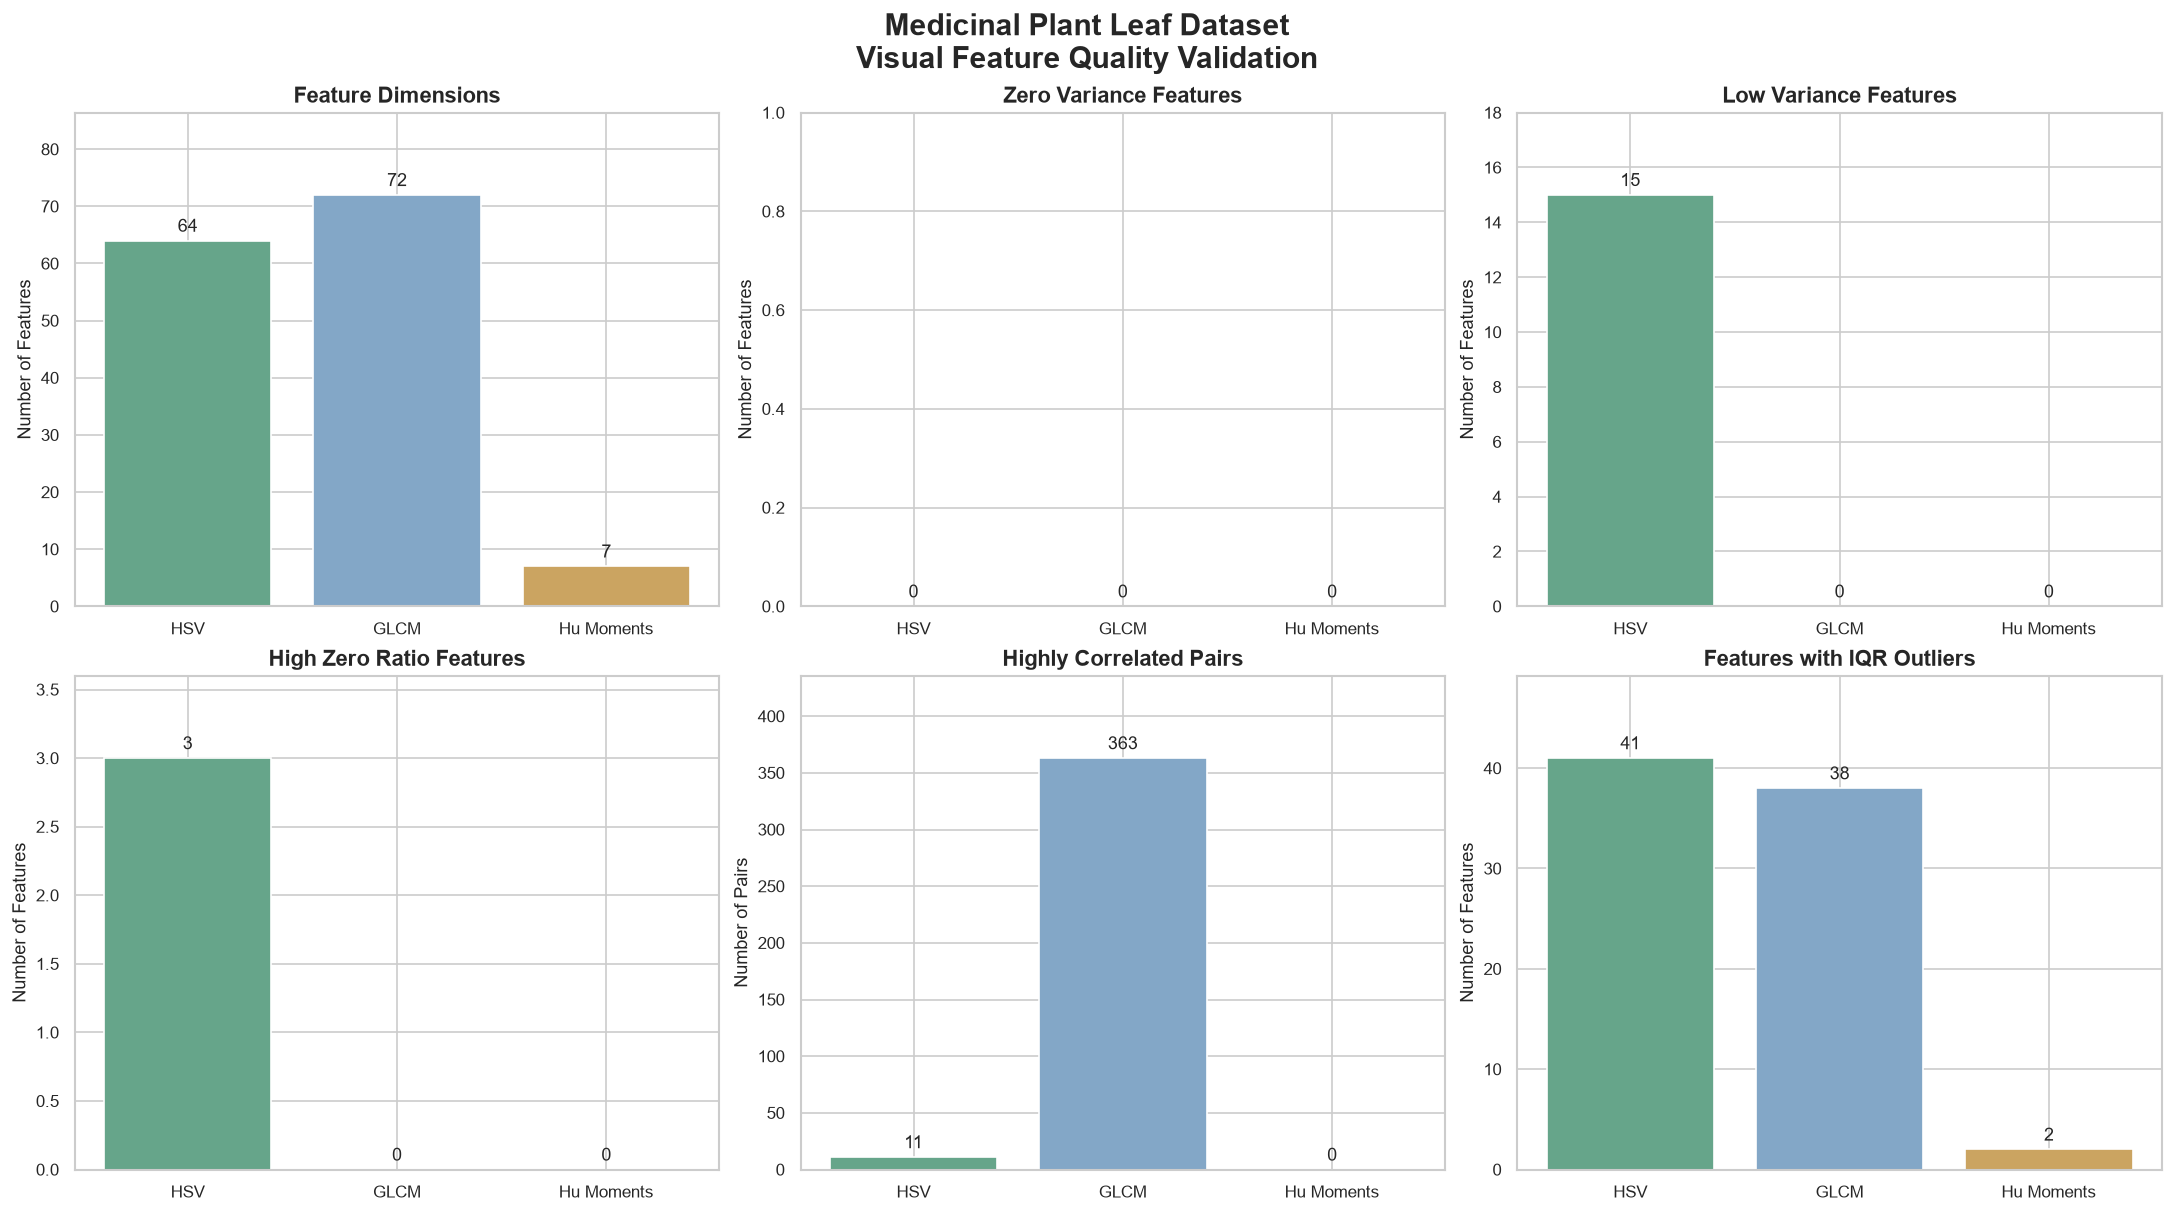

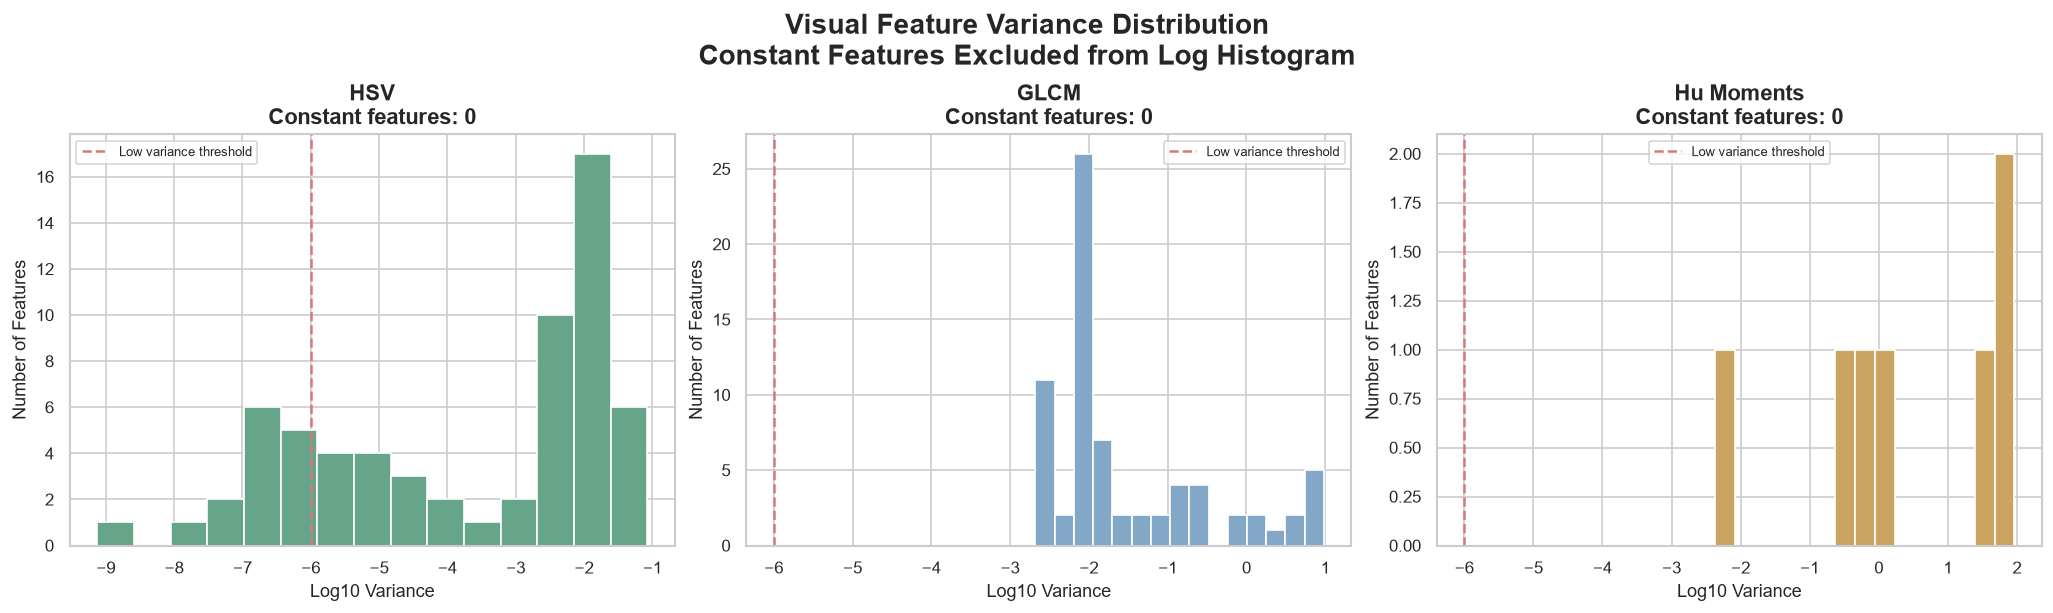

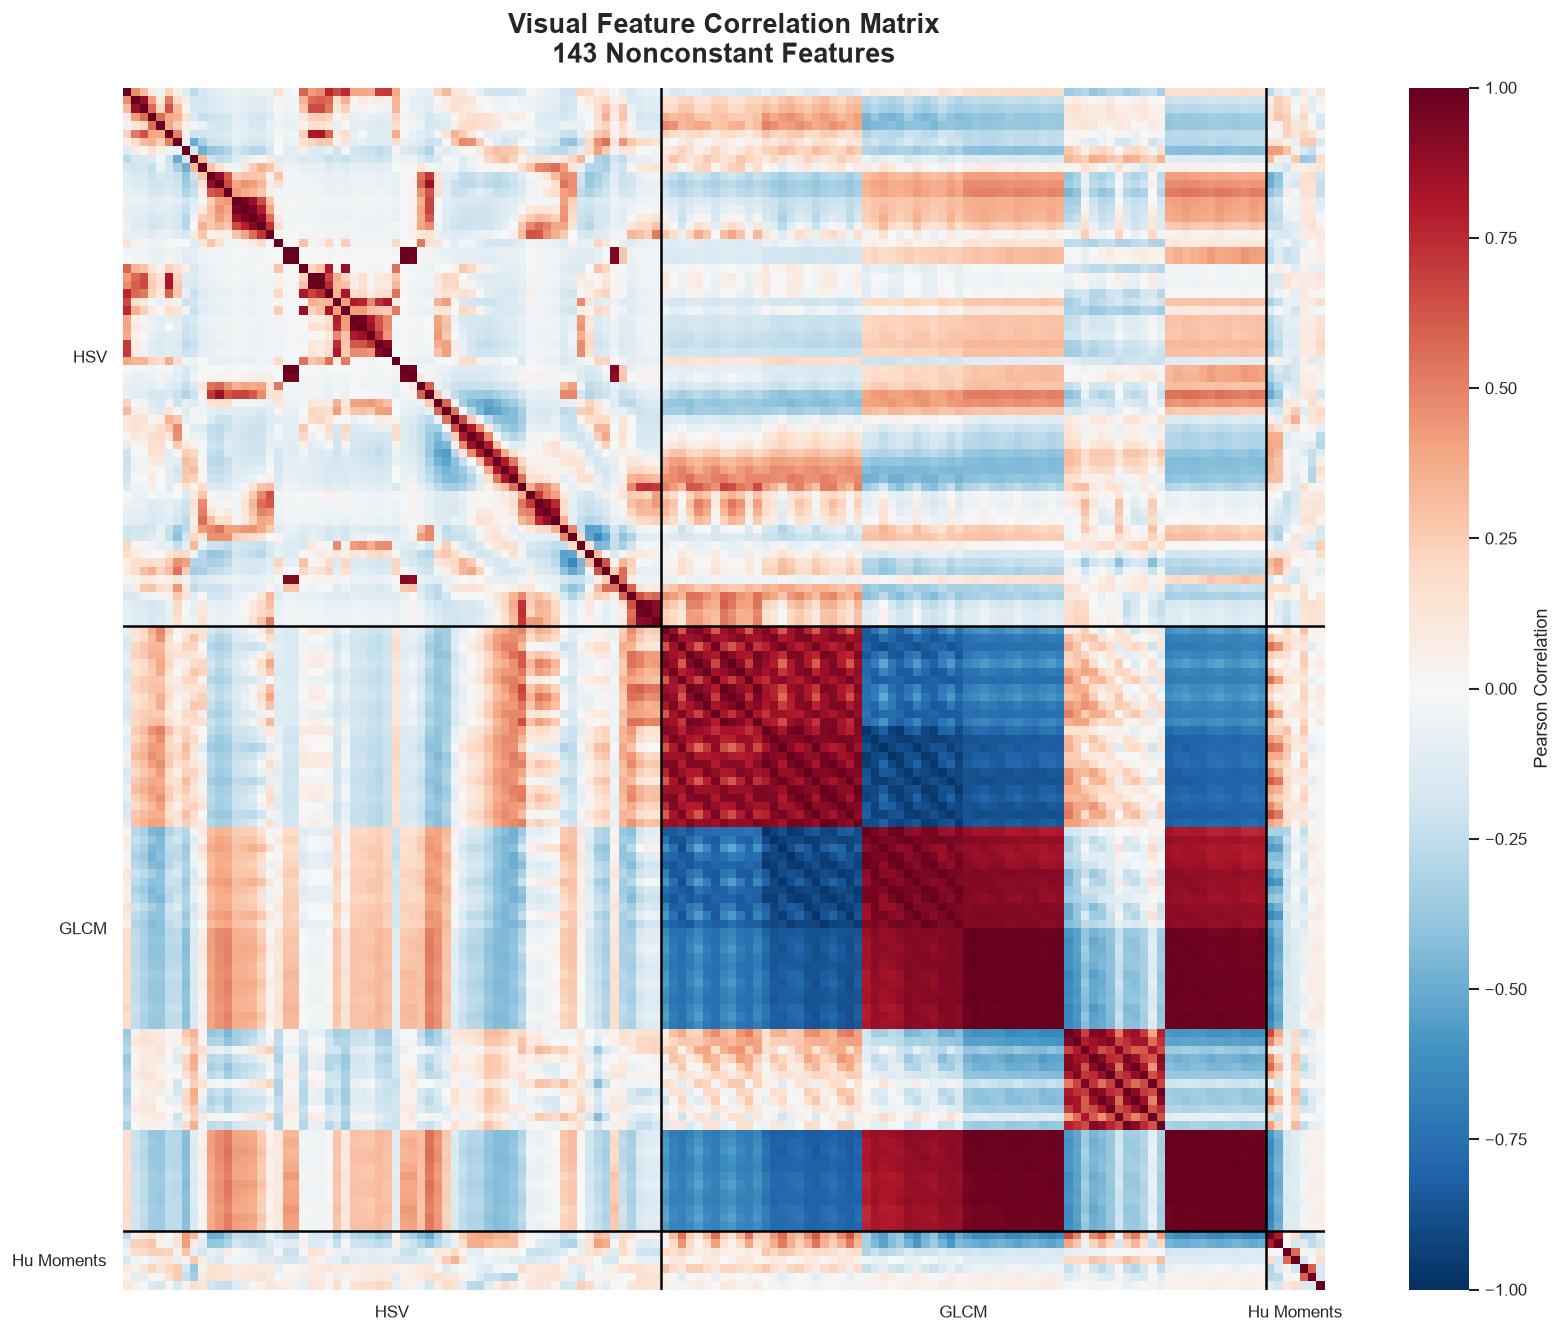

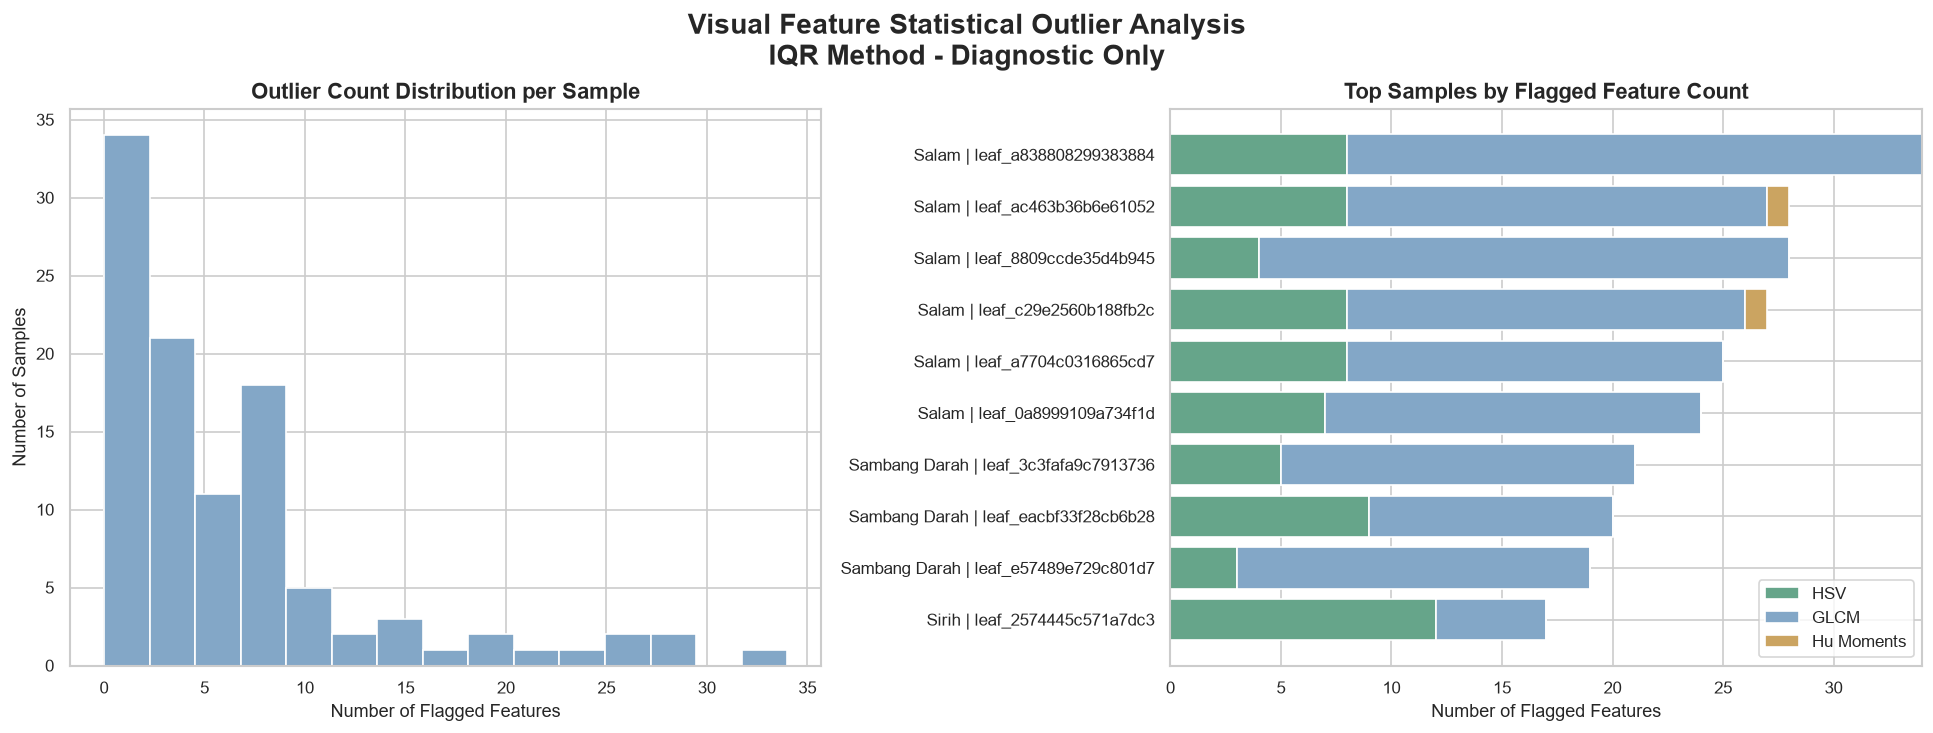


14. OVERALL FEATURE QUALITY SUMMARY


,Indicator,Result
0,Total samples,104
1,Total visual features,143
2,Total feature values,14872
3,NaN values,0
4,Infinite values,0
5,Mathematical validation checks,19
6,Mathematical checks passed,19
7,Constant features,0
8,Low variance nonconstant features,15
9,High zero ratio features,3



15. FINAL FEATURE QUALITY VALIDATION SUMMARY
Total samples          : 104
Total visual features  : 143
Total feature values   : 14,872

NUMERICAL VALIDATION
------------------------------------------------------------
NaN values             : 0
Infinite values        : 0
Mathematical checks    : 19/19

STATISTICAL QUALITY ANALYSIS
------------------------------------------------------------
Constant features      : 0
Low variance features  : 15
High zero ratio        : 3
High correlation pairs : 374
Total outlier values   : 696
Samples with outliers  : 103

[PASS] Feature dimensions are consistent.
[PASS] No missing or non-finite feature values.
[PASS] Mathematical feature checks passed.
[PASS] Feature variance analysis completed.
[PASS] Feature correlation analysis completed.
[PASS] Statistical outlier analysis completed.
[PASS] Duplicate feature vector analysis completed.
[PASS] Original feature matrices remain unchanged.
[PASS] Sample alignment and review status preserved.
[PASS] A

In [14]:
# ==================================================
# FEATURE QUALITY VALIDATION
# ==================================================

print("FEATURE QUALITY VALIDATION")
print("=" * 60)


# ==================================================
# 1. QUALITY VALIDATION CONFIGURATION
# ==================================================

LOW_VARIANCE_THRESHOLD = 1e-6

HIGH_CORRELATION_THRESHOLD = 0.95

OUTLIER_IQR_MULTIPLIER = 1.5

QUALITY_TOLERANCE = 1e-8

HIGH_ZERO_RATIO_THRESHOLD = 0.95

QUALITY_FEATURE_GROUPS = {
    "HSV": hsv_features,
    "GLCM": glcm_features,
    "Hu Moments": hu_features
}

QUALITY_FEATURE_NAMES = {
    "HSV": list(HSV_FEATURE_NAMES),
    "GLCM": list(GLCM_FEATURE_NAMES),
    "Hu Moments": list(HU_FEATURE_NAMES)
}

QUALITY_FEATURE_DIMENSIONS = {
    "HSV": HSV_FEATURE_DIM,
    "GLCM": GLCM_FEATURE_DIM,
    "Hu Moments": HU_FEATURE_DIM
}

QUALITY_GROUP_COLORS = {
    "HSV": "#66A58A",
    "GLCM": "#83A7C7",
    "Hu Moments": "#CBA461"
}

quality_n_samples = len(df_visual_features)

assert BATCH_FAILED_COUNT == 0

assert quality_n_samples == BATCH_SUCCESS_COUNT

assert df_visual_features["sample_id"].is_unique

print("\n1. QUALITY VALIDATION CONFIGURATION")

print(f"Total samples              : {quality_n_samples}")
print(f"Low variance threshold     : {LOW_VARIANCE_THRESHOLD}")
print(f"High correlation threshold : {HIGH_CORRELATION_THRESHOLD}")
print(f"IQR multiplier             : {OUTLIER_IQR_MULTIPLIER}")
print(f"High zero ratio threshold  : {HIGH_ZERO_RATIO_THRESHOLD}")

print("\n[INFO] Statistical thresholds are diagnostic only.")
print("[INFO] No features or samples will be removed.")


# ==================================================
# 2. VALIDATE FEATURE MATRICES AND ALIGNMENT
# ==================================================

quality_matrix_records = []

for group_name, matrix in QUALITY_FEATURE_GROUPS.items():

    feature_names = QUALITY_FEATURE_NAMES[group_name]

    expected_dimension = QUALITY_FEATURE_DIMENSIONS[
        group_name
    ]

    assert matrix.shape == (
        quality_n_samples,
        expected_dimension
    )

    assert len(feature_names) == expected_dimension

    assert len(set(feature_names)) == expected_dimension

    quality_matrix_records.append({

        "feature_group": group_name,

        "number_of_samples": matrix.shape[0],

        "feature_dimension": matrix.shape[1],

        "total_values": matrix.size,

        "nan_values": int(np.isnan(matrix).sum()),

        "infinite_values": int(np.isinf(matrix).sum()),

        "all_finite": bool(np.isfinite(matrix).all()),

        "data_type": str(matrix.dtype)
    })


quality_matrix_validation_df = pd.DataFrame(
    quality_matrix_records
)

assert quality_matrix_validation_df[
    "all_finite"
].all()

feature_dataframe_groups = {
    "HSV": hsv_features_df,
    "GLCM": glcm_features_df,
    "Hu Moments": hu_features_df
}

for group_name, feature_df in (
    feature_dataframe_groups.items()
):

    assert np.array_equal(
        feature_df["sample_id"].to_numpy(),
        visual_feature_sample_ids
    )

    assert np.array_equal(
        feature_df[
            QUALITY_FEATURE_NAMES[group_name]
        ].to_numpy(),
        QUALITY_FEATURE_GROUPS[group_name]
    )

assert np.array_equal(
    df_visual_features["sample_id"].to_numpy(),
    visual_feature_sample_ids
)

print("\n2. FEATURE MATRIX VALIDATION")

display(quality_matrix_validation_df)

print("[PASS] All feature matrix dimensions are valid.")
print("[PASS] No NaN or infinity values detected.")
print("[PASS] All feature groups are aligned.")


# ==================================================
# 3. MATHEMATICAL VALIDATION - HSV
# ==================================================

hsv_hue_sums = hsv_features[
    :, HSV_H_SLICE
].sum(axis=1)

hsv_saturation_sums = hsv_features[
    :, HSV_S_SLICE
].sum(axis=1)

hsv_value_sums = hsv_features[
    :, HSV_V_SLICE
].sum(axis=1)

hsv_math_checks = {

    "HSV values are non-negative": bool(
        np.all(hsv_features >= 0)
    ),

    "HSV values do not exceed one": bool(
        np.all(
            hsv_features <= 1 + QUALITY_TOLERANCE
        )
    ),

    "Hue histograms sum to one": bool(
        np.allclose(hsv_hue_sums, 1.0)
    ),

    "Saturation histograms sum to one": bool(
        np.allclose(hsv_saturation_sums, 1.0)
    ),

    "Value histograms sum to one": bool(
        np.allclose(hsv_value_sums, 1.0)
    ),

    "Combined HSV histograms sum to three": bool(
        np.allclose(
            hsv_features.sum(axis=1),
            3.0
        )
    )
}


# ==================================================
# 4. MATHEMATICAL VALIDATION - GLCM
# ==================================================

glcm_features_per_property = (
    len(GLCM_DISTANCES)
    * len(GLCM_ANGLES_DEGREES)
)

glcm_property_blocks = {}

for property_idx, property_name in enumerate(
    GLCM_PROPERTIES
):

    start_idx = (
        property_idx * glcm_features_per_property
    )

    end_idx = (
        start_idx + glcm_features_per_property
    )

    glcm_property_blocks[property_name] = (
        glcm_features[:, start_idx:end_idx]
    )


glcm_max_gray_difference = GLCM_LEVELS - 1

glcm_theoretical_ranges = {

    "contrast": (
        0,
        glcm_max_gray_difference ** 2
    ),

    "dissimilarity": (
        0,
        glcm_max_gray_difference
    ),

    "homogeneity": (
        1 / (1 + glcm_max_gray_difference ** 2),
        1
    ),

    "energy": (
        1 / GLCM_LEVELS,
        1
    ),

    "correlation": (
        -1,
        1
    ),

    "ASM": (
        1 / GLCM_LEVELS ** 2,
        1
    )
}

glcm_math_checks = {}

for property_name, bounds in (
    glcm_theoretical_ranges.items()
):

    values = glcm_property_blocks[property_name]

    lower_bound, upper_bound = bounds

    glcm_math_checks[
        f"GLCM {property_name} within theoretical range"
    ] = bool(

        np.all(
            values >= lower_bound - QUALITY_TOLERANCE
        )

        and np.all(
            values <= upper_bound + QUALITY_TOLERANCE
        )
    )

# Energy squared must equal ASM

glcm_math_checks["GLCM Energy squared equals ASM"] = bool(

    np.allclose(

        glcm_property_blocks["energy"] ** 2,

        glcm_property_blocks["ASM"],

        rtol=1e-7,

        atol=QUALITY_TOLERANCE
    )
)

# For integer gray-level differences, d^2 >= |d|

glcm_math_checks[
    "GLCM Contrast is not below Dissimilarity"
] = bool(

    np.all(

        glcm_property_blocks["contrast"]

        >= glcm_property_blocks["dissimilarity"]

        - QUALITY_TOLERANCE
    )
)


# ==================================================
# 5. MATHEMATICAL VALIDATION - HU MOMENTS
# ==================================================

hu_recomputed_features = np.vstack([

    transform_hu_moments(raw_vector)

    for raw_vector in hu_raw_features
])

hu_math_checks = {

    "Hu Moments contain seven features": bool(
        hu_features.shape[1] == 7
    ),

    "Raw Hu Moments are finite": bool(
        np.isfinite(hu_raw_features).all()
    ),

    "Signed log transformation is consistent": bool(

        np.allclose(

            hu_features,

            hu_recomputed_features,

            rtol=0,

            atol=1e-12
        )
    ),

    "Exact zero Hu Moments are preserved": bool(

        np.all(
            hu_features[hu_raw_features == 0] == 0
        )
    ),

    "First four raw Hu Moments are non-negative": bool(

        np.all(
            hu_raw_features[:, :4] >= 0
        )
    )
}


# ==================================================
# 6. COMBINE MATHEMATICAL VALIDATION RESULTS
# ==================================================

quality_math_records = []

for group_name, checks in [

    ("HSV", hsv_math_checks),

    ("GLCM", glcm_math_checks),

    ("Hu Moments", hu_math_checks)
]:

    for check_name, passed in checks.items():

        quality_math_records.append({

            "feature_group": group_name,

            "validation_check": check_name,

            "passed": bool(passed),

            "status": (
                "Passed" if passed else "Failed"
            )
        })


feature_math_validation_df = pd.DataFrame(
    quality_math_records
)

print("\n3. MATHEMATICAL FEATURE VALIDATION")

display(feature_math_validation_df)

feature_math_validation_df.to_csv(

    METRICS_DIR /
    "141_feature_mathematical_validation.csv",

    index=False,

    encoding="utf-8-sig"
)

assert feature_math_validation_df["passed"].all(), (
    "Mathematical feature validation failed. "
    "Inspect report 141 before continuing."
)

print("[PASS] All mathematical validation checks passed.")


# ==================================================
# 7. ANALYZE INDIVIDUAL FEATURE STATISTICS
# ==================================================

feature_statistics_records = []

for group_name, matrix in QUALITY_FEATURE_GROUPS.items():

    feature_names = QUALITY_FEATURE_NAMES[group_name]

    for feature_idx, feature_name in enumerate(
        feature_names
    ):

        values = matrix[:, feature_idx]

        minimum_value = float(values.min())

        maximum_value = float(values.max())

        mean_value = float(values.mean())

        variance_value = float(
            values.var(ddof=0)
        )

        std_value = float(
            values.std(ddof=0)
        )

        unique_values = int(
            np.unique(values).size
        )

        zero_count = int(
            np.count_nonzero(values == 0)
        )

        zero_ratio = (
            zero_count / len(values)
        )

        zero_variance = (
            unique_values == 1
        )

        low_variance = bool(

            not zero_variance

            and variance_value
            < LOW_VARIANCE_THRESHOLD
        )

        high_zero_ratio = bool(

            zero_ratio
            >= HIGH_ZERO_RATIO_THRESHOLD
        )

        quality_flags = []

        if zero_variance:
            quality_flags.append("Zero variance")

        if low_variance:
            quality_flags.append("Low variance")

        if high_zero_ratio:
            quality_flags.append("High zero ratio")

        feature_statistics_records.append({

            "feature_group": group_name,

            "feature_index": feature_idx,

            "feature_name": feature_name,

            "minimum": minimum_value,

            "maximum": maximum_value,

            "mean": mean_value,

            "median": float(np.median(values)),

            "variance": variance_value,

            "standard_deviation": std_value,

            "range": (
                maximum_value - minimum_value
            ),

            "q1": float(
                np.percentile(values, 25)
            ),

            "q3": float(
                np.percentile(values, 75)
            ),

            "unique_values": unique_values,

            "zero_values": zero_count,

            "zero_ratio": zero_ratio,

            "negative_values": int(
                np.count_nonzero(values < 0)
            ),

            "zero_variance": zero_variance,

            "low_variance": low_variance,

            "high_zero_ratio": high_zero_ratio,

            "quality_status": (
                "Needs Attention"
                if quality_flags
                else "Passed"
            ),

            "quality_issues": "; ".join(
                quality_flags
            )
        })


feature_statistics_df = pd.DataFrame(
    feature_statistics_records
)

assert len(feature_statistics_df) == (
    TOTAL_VISUAL_FEATURE_DIM
)

assert feature_statistics_df[
    "feature_name"
].is_unique

print("\n4. INDIVIDUAL FEATURE STATISTICS")

display(
    feature_statistics_df.head(10).round(6)
)


# ==================================================
# 8. IDENTIFY CONSTANT AND LOW-VARIANCE FEATURES
# ==================================================

zero_variance_features_df = (

    feature_statistics_df[
        feature_statistics_df["zero_variance"]
    ]

    .copy()

    .reset_index(drop=True)
)

low_variance_features_df = (

    feature_statistics_df[
        feature_statistics_df["low_variance"]
    ]

    .copy()

    .sort_values("variance")

    .reset_index(drop=True)
)

high_zero_features_df = (

    feature_statistics_df[
        feature_statistics_df["high_zero_ratio"]
    ]

    .copy()

    .sort_values(
        "zero_ratio",
        ascending=False
    )

    .reset_index(drop=True)
)

print("\n5. ZERO VARIANCE FEATURES")

print(
    f"Constant features: "
    f"{len(zero_variance_features_df)}"
)

display(
    zero_variance_features_df[
        [
            "feature_group",
            "feature_name",
            "mean",
            "variance",
            "zero_ratio"
        ]
    ]
)

print("\n6. LOW VARIANCE FEATURES")

print(
    f"Low variance features: "
    f"{len(low_variance_features_df)}"
)

display(
    low_variance_features_df[
        [
            "feature_group",
            "feature_name",
            "variance",
            "standard_deviation",
            "zero_ratio"
        ]
    ]
)

print("\n7. HIGH ZERO RATIO FEATURES")

print(
    f"High zero ratio features: "
    f"{len(high_zero_features_df)}"
)

display(
    high_zero_features_df[
        [
            "feature_group",
            "feature_name",
            "zero_values",
            "zero_ratio"
        ]
    ]
)

print("\n[INFO] Constant and low-variance features are retained.")
print("[INFO] Low variance is assessed in original feature units.")


# ==================================================
# 9. CREATE TEMPORARY FEATURE AUDIT MATRIX
# ==================================================

# Temporary concatenation for quality analysis only.
# This is NOT the final normalized feature matrix.

quality_all_feature_names = [

    *HSV_FEATURE_NAMES,

    *GLCM_FEATURE_NAMES,

    *HU_FEATURE_NAMES
]

quality_audit_matrix = np.concatenate(

    [
        hsv_features,
        glcm_features,
        hu_features
    ],

    axis=1
)

quality_audit_df = pd.DataFrame(

    quality_audit_matrix,

    columns=quality_all_feature_names
)

assert quality_audit_matrix.shape == (

    quality_n_samples,

    TOTAL_VISUAL_FEATURE_DIM
)

assert quality_audit_df.columns.is_unique

assert np.isfinite(
    quality_audit_matrix
).all()

feature_group_lookup = (

    feature_statistics_df

    .set_index("feature_name")["feature_group"]

    .to_dict()
)

print("\n[OK] Temporary feature audit matrix created.")

print(
    f"Audit matrix shape: "
    f"{quality_audit_matrix.shape}"
)


# ==================================================
# 10. FEATURE CORRELATION ANALYSIS
# ==================================================

# Constant features have undefined Pearson correlation.
# Exclude them from correlation calculations only.

nonconstant_feature_names = (

    feature_statistics_df.loc[

        ~feature_statistics_df["zero_variance"],

        "feature_name"
    ]

    .tolist()
)

feature_correlation_df = (

    quality_audit_df[
        nonconstant_feature_names
    ]

    .corr(method="pearson")
)

correlation_array = (
    feature_correlation_df.to_numpy()
)

correlation_names = (
    feature_correlation_df.columns.tolist()
)

high_correlation_records = []

# Upper triangle prevents duplicate feature pairs.

for i in range(len(correlation_names)):

    for j in range(
        i + 1,
        len(correlation_names)
    ):

        correlation_value = (
            correlation_array[i, j]
        )

        if not np.isfinite(correlation_value):
            continue

        if abs(correlation_value) >= (
            HIGH_CORRELATION_THRESHOLD
        ):

            feature_a = correlation_names[i]
            feature_b = correlation_names[j]

            group_a = feature_group_lookup[feature_a]
            group_b = feature_group_lookup[feature_b]

            high_correlation_records.append({

                "feature_a": feature_a,

                "feature_b": feature_b,

                "group_a": group_a,

                "group_b": group_b,

                "correlation": float(
                    correlation_value
                ),

                "absolute_correlation": float(
                    abs(correlation_value)
                ),

                "correlation_type": (

                    "Within Group"

                    if group_a == group_b

                    else "Between Groups"
                )
            })


high_correlation_pairs_df = pd.DataFrame(

    high_correlation_records,

    columns=[
        "feature_a",
        "feature_b",
        "group_a",
        "group_b",
        "correlation",
        "absolute_correlation",
        "correlation_type"
    ]
)

high_correlation_pairs_df = (

    high_correlation_pairs_df

    .sort_values(
        "absolute_correlation",
        ascending=False
    )

    .reset_index(drop=True)
)

print("\n8. HIGH CORRELATION FEATURE PAIRS")

print(
    f"Nonconstant features: "
    f"{len(nonconstant_feature_names)}"
)

print(
    f"Highly correlated pairs: "
    f"{len(high_correlation_pairs_df)}"
)

display(
    high_correlation_pairs_df.head(20).round(6)
)


# ==================================================
# 11. ANALYZE GLCM ENERGY AND ASM REDUNDANCY
# ==================================================

energy_values = glcm_property_blocks["energy"]

asm_values = glcm_property_blocks["ASM"]

glcm_redundancy_records = []

for d_idx, distance in enumerate(
    GLCM_DISTANCES
):

    for a_idx, angle in enumerate(
        GLCM_ANGLES_DEGREES
    ):

        spatial_idx = (

            d_idx * len(GLCM_ANGLES_DEGREES)

            + a_idx
        )

        energy_column = energy_values[
            :, spatial_idx
        ]

        asm_column = asm_values[
            :, spatial_idx
        ]

        if (

            np.ptp(energy_column) > 0

            and np.ptp(asm_column) > 0
        ):

            pearson_correlation = float(

                np.corrcoef(
                    energy_column,
                    asm_column
                )[0, 1]
            )

        else:

            pearson_correlation = np.nan

        glcm_redundancy_records.append({

            "distance": distance,

            "angle": angle,

            "pearson_correlation": (
                pearson_correlation
            ),

            "maximum_energy_squared_difference": float(

                np.abs(

                    energy_column ** 2

                    - asm_column

                ).max()
            ),

            "mathematical_relationship_valid": bool(

                np.allclose(

                    energy_column ** 2,

                    asm_column,

                    atol=QUALITY_TOLERANCE
                )
            )
        })


glcm_redundancy_df = pd.DataFrame(
    glcm_redundancy_records
)

print("\n9. GLCM ENERGY AND ASM REDUNDANCY")

display(glcm_redundancy_df.round(8))

assert glcm_redundancy_df[
    "mathematical_relationship_valid"
].all()

print("[INFO] Energy and ASM have a known mathematical relationship.")
print("[INFO] Both properties remain in the baseline configuration.")


# ==================================================
# 12. OUTLIER DETECTION USING IQR
# ==================================================

outlier_feature_records = []

outlier_sample_records = []

outlier_flags = np.zeros(

    quality_audit_matrix.shape,

    dtype=bool
)

for feature_idx, feature_name in enumerate(
    quality_all_feature_names
):

    values = quality_audit_matrix[
        :, feature_idx
    ]

    group_name = feature_group_lookup[
        feature_name
    ]

    q1 = float(
        np.percentile(values, 25)
    )

    q3 = float(
        np.percentile(values, 75)
    )

    iqr = q3 - q1

    lower_bound = (

        q1 - OUTLIER_IQR_MULTIPLIER * iqr
    )

    upper_bound = (

        q3 + OUTLIER_IQR_MULTIPLIER * iqr
    )

    # Avoid treating sparse histogram bins
    # with zero IQR as automatic outliers.

    if iqr == 0:

        flags = np.zeros(
            len(values),
            dtype=bool
        )

        iqr_status = "Skipped - Zero IQR"

        nonmedian_count = int(

            np.count_nonzero(
                values != np.median(values)
            )
        )

    else:

        flags = (

            (values < lower_bound)

            | (values > upper_bound)
        )

        iqr_status = "Evaluated"

        nonmedian_count = int(

            np.count_nonzero(
                values != np.median(values)
            )
        )

    outlier_flags[
        :, feature_idx
    ] = flags

    outlier_count = int(flags.sum())

    outlier_feature_records.append({

        "feature_group": group_name,

        "feature_name": feature_name,

        "q1": q1,

        "q3": q3,

        "iqr": iqr,

        "lower_bound": lower_bound,

        "upper_bound": upper_bound,

        "outlier_count": outlier_count,

        "outlier_ratio": (
            outlier_count / quality_n_samples
        ),

        "nonmedian_count": nonmedian_count,

        "iqr_status": iqr_status
    })

    for sample_idx in np.flatnonzero(flags):

        metadata_row = df_visual_features.iloc[
            sample_idx
        ]

        outlier_sample_records.append({

            "sample_id": metadata_row["sample_id"],

            "nama_file": metadata_row["nama_file"],

            "kelas": metadata_row["kelas"],

            "tampilan_daun": metadata_row[
                "tampilan_daun"
            ],

            "validation_status": metadata_row[
                "validation_status"
            ],

            "feature_group": group_name,

            "feature_name": feature_name,

            "feature_value": float(
                values[sample_idx]
            ),

            "lower_bound": lower_bound,

            "upper_bound": upper_bound,

            "outlier_type": (

                "Below Lower Bound"

                if values[sample_idx] < lower_bound

                else "Above Upper Bound"
            )
        })


feature_outlier_summary_df = pd.DataFrame(
    outlier_feature_records
)

feature_outlier_details_df = pd.DataFrame(

    outlier_sample_records,

    columns=[
        "sample_id",
        "nama_file",
        "kelas",
        "tampilan_daun",
        "validation_status",
        "feature_group",
        "feature_name",
        "feature_value",
        "lower_bound",
        "upper_bound",
        "outlier_type"
    ]
)

print("\n10. FEATURE OUTLIER SUMMARY")

display(

    feature_outlier_summary_df

    .sort_values(
        "outlier_count",
        ascending=False
    )

    .head(15)

    .round(6)
)

print(
    f"Total flagged feature values: "
    f"{int(outlier_flags.sum())}"
)

print("[INFO] Outliers are not automatically considered errors.")


# ==================================================
# 13. ANALYZE OUTLIERS PER SAMPLE
# ==================================================

sample_feature_quality_df = (

    df_visual_features[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)

sample_feature_quality_df["hsv_outlier_count"] = (

    outlier_flags[
        :, :HSV_FEATURE_DIM
    ].sum(axis=1)
)

sample_feature_quality_df["glcm_outlier_count"] = (

    outlier_flags[
        :,
        HSV_FEATURE_DIM:
        HSV_FEATURE_DIM + GLCM_FEATURE_DIM
    ].sum(axis=1)
)

sample_feature_quality_df["hu_outlier_count"] = (

    outlier_flags[
        :,
        HSV_FEATURE_DIM + GLCM_FEATURE_DIM:
    ].sum(axis=1)
)

sample_feature_quality_df["total_outlier_count"] = (

    outlier_flags.sum(axis=1)
)

sample_feature_quality_df["outlier_ratio"] = (

    sample_feature_quality_df[
        "total_outlier_count"
    ]

    / TOTAL_VISUAL_FEATURE_DIM
)

sample_feature_quality_df["contains_outlier"] = (

    sample_feature_quality_df[
        "total_outlier_count"
    ].gt(0)
)

sample_feature_quality_df["numerical_valid"] = True

sample_feature_quality_df["feature_quality_status"] = (

    np.where(

        sample_feature_quality_df[
            "contains_outlier"
        ],

        "Statistical Review",

        "Passed Initial Check"
    )
)

print("\n11. SAMPLE-LEVEL FEATURE QUALITY")

display(

    sample_feature_quality_df

    .sort_values(
        "total_outlier_count",
        ascending=False
    )

    .head(15)
)


# ==================================================
# 14. CHECK DUPLICATE FEATURE VECTORS
# ==================================================

duplicate_feature_records = []

duplicate_feature_summary_records = []

duplicate_check_groups = {

    **QUALITY_FEATURE_GROUPS,

    "All Visual Features": quality_audit_matrix
}

for group_name, matrix in (
    duplicate_check_groups.items()
):

    _, inverse_indices, counts = np.unique(

        matrix,

        axis=0,

        return_inverse=True,

        return_counts=True
    )

    duplicate_mask = (
        counts[inverse_indices] > 1
    )

    duplicate_feature_summary_records.append({

        "feature_group": group_name,

        "total_samples": matrix.shape[0],

        "unique_vectors": len(counts),

        "duplicate_vector_groups": int(
            np.count_nonzero(counts > 1)
        ),

        "samples_in_duplicate_groups": int(
            duplicate_mask.sum()
        ),

        "redundant_vectors": int(
            matrix.shape[0] - len(counts)
        )
    })

    for idx in np.flatnonzero(
        duplicate_mask
    ):

        metadata_row = df_visual_features.iloc[idx]

        vector_group = int(
            inverse_indices[idx]
        )

        duplicate_feature_records.append({

            "feature_group": group_name,

            "duplicate_group_id": vector_group,

            "sample_id": metadata_row["sample_id"],

            "nama_file": metadata_row["nama_file"],

            "kelas": metadata_row["kelas"],

            "duplicate_group_size": int(
                counts[vector_group]
            )
        })


duplicate_feature_summary_df = pd.DataFrame(
    duplicate_feature_summary_records
)

duplicate_feature_details_df = pd.DataFrame(

    duplicate_feature_records,

    columns=[
        "feature_group",
        "duplicate_group_id",
        "sample_id",
        "nama_file",
        "kelas",
        "duplicate_group_size"
    ]
)

print("\n12. DUPLICATE FEATURE VECTOR ANALYSIS")

display(duplicate_feature_summary_df)

if not duplicate_feature_details_df.empty:

    display(
        duplicate_feature_details_df.head(20)
    )

print("[INFO] Duplicate detection uses exact feature equality.")
print("[INFO] Identical features do not necessarily mean identical images.")


# ==================================================
# 15. CREATE FEATURE QUALITY SUMMARY PER GROUP
# ==================================================

feature_group_quality_records = []

for group_name, matrix in (
    QUALITY_FEATURE_GROUPS.items()
):

    group_stats = feature_statistics_df[

        feature_statistics_df[
            "feature_group"
        ].eq(group_name)
    ]

    group_outliers = feature_outlier_summary_df[

        feature_outlier_summary_df[
            "feature_group"
        ].eq(group_name)
    ]

    group_correlations = high_correlation_pairs_df[

        high_correlation_pairs_df[
            "group_a"
        ].eq(group_name)

        & high_correlation_pairs_df[
            "group_b"
        ].eq(group_name)
    ]

    feature_group_quality_records.append({

        "feature_group": group_name,

        "samples": matrix.shape[0],

        "feature_dimension": matrix.shape[1],

        "total_values": matrix.size,

        "zero_values": int(
            np.count_nonzero(matrix == 0)
        ),

        "zero_ratio": float(
            np.count_nonzero(matrix == 0)
            / matrix.size
        ),

        "constant_features": int(
            group_stats["zero_variance"].sum()
        ),

        "low_variance_features": int(
            group_stats["low_variance"].sum()
        ),

        "high_zero_ratio_features": int(
            group_stats["high_zero_ratio"].sum()
        ),

        "high_correlation_pairs": len(
            group_correlations
        ),

        "features_with_outliers": int(

            group_outliers[
                "outlier_count"
            ].gt(0).sum()
        ),

        "zero_iqr_features": int(

            group_outliers[
                "iqr"
            ].eq(0).sum()
        ),

        "total_outlier_values": int(

            group_outliers[
                "outlier_count"
            ].sum()
        ),

        "nan_values": int(
            np.isnan(matrix).sum()
        ),

        "infinite_values": int(
            np.isinf(matrix).sum()
        ),

        "numerical_valid": bool(
            np.isfinite(matrix).all()
        )
    })


feature_group_quality_df = pd.DataFrame(
    feature_group_quality_records
)

print("\n13. FEATURE QUALITY PER GROUP")

display(feature_group_quality_df.round(6))


# ==================================================
# 16. VISUALIZE FEATURE QUALITY SUMMARY
# ==================================================

quality_visualization_paths = []

fig, axes = plt.subplots(

    2, 3,

    figsize=(18, 10),

    constrained_layout=True
)

quality_plot_configurations = [

    (
        "feature_dimension",
        "Feature Dimensions",
        "Number of Features"
    ),

    (
        "constant_features",
        "Zero Variance Features",
        "Number of Features"
    ),

    (
        "low_variance_features",
        "Low Variance Features",
        "Number of Features"
    ),

    (
        "high_zero_ratio_features",
        "High Zero Ratio Features",
        "Number of Features"
    ),

    (
        "high_correlation_pairs",
        "Highly Correlated Pairs",
        "Number of Pairs"
    ),

    (
        "features_with_outliers",
        "Features with IQR Outliers",
        "Number of Features"
    )
]

group_labels = (
    feature_group_quality_df["feature_group"]
)

group_colors = [

    QUALITY_GROUP_COLORS[group]

    for group in group_labels
]

for ax, configuration in zip(

    axes.ravel(),

    quality_plot_configurations
):

    column, title, ylabel = configuration

    values = feature_group_quality_df[column]

    bars = ax.bar(

        group_labels,

        values,

        color=group_colors
    )

    ax.set_title(title)

    ax.set_ylabel(ylabel)

    ax.bar_label(
        bars,
        padding=3
    )

    ax.set_ylim(

        0,

        max(
            float(values.max()) * 1.2,
            1
        )
    )

fig.suptitle(

    "Medicinal Plant Leaf Dataset\n"
    "Visual Feature Quality Validation",

    fontsize=18,

    fontweight="bold"
)

quality_summary_figure_path = (

    FEATURE_FIGURES_DIR /

    "46_feature_quality_validation_summary.png"
)

fig.savefig(

    quality_summary_figure_path,

    dpi=300,

    bbox_inches="tight"
)

quality_visualization_paths.append(
    quality_summary_figure_path
)

plt.show()
plt.close(fig)


# ==================================================
# 17. VISUALIZE FEATURE VARIANCE DISTRIBUTION
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(17, 5),

    constrained_layout=True
)

for ax, group_name in zip(

    axes,

    QUALITY_FEATURE_GROUPS
):

    group_stats = feature_statistics_df[

        feature_statistics_df[
            "feature_group"
        ].eq(group_name)
    ]

    positive_variance = group_stats.loc[

        group_stats["variance"].gt(0),

        "variance"
    ]

    # Log scale for displaying variance only.

    log_variance = np.log10(
        positive_variance.to_numpy()
    )

    if len(log_variance) > 0:

        ax.hist(

            log_variance,

            bins=15,

            color=QUALITY_GROUP_COLORS[
                group_name
            ],

            edgecolor="white"
        )

    ax.axvline(

        np.log10(LOW_VARIANCE_THRESHOLD),

        color="#D97878",

        linestyle="--",

        label="Low variance threshold"
    )

    constant_count = int(
        group_stats["zero_variance"].sum()
    )

    ax.set_title(

        f"{group_name}\n"
        f"Constant features: {constant_count}"
    )

    ax.set_xlabel("Log10 Variance")

    ax.set_ylabel("Number of Features")

    ax.legend(fontsize=8)


fig.suptitle(

    "Visual Feature Variance Distribution\n"
    "Constant Features Excluded from Log Histogram",

    fontsize=17,

    fontweight="bold"
)

variance_figure_path = (

    FEATURE_FIGURES_DIR /

    "47_feature_variance_distribution.png"
)

fig.savefig(

    variance_figure_path,

    dpi=300,

    bbox_inches="tight"
)

quality_visualization_paths.append(
    variance_figure_path
)

plt.show()
plt.close(fig)


# ==================================================
# 18. VISUALIZE FEATURE CORRELATION MATRIX
# ==================================================

fig, ax = plt.subplots(

    figsize=(13, 11),

    constrained_layout=True
)

sns.heatmap(

    feature_correlation_df,

    cmap="RdBu_r",

    center=0,

    vmin=-1,

    vmax=1,

    square=True,

    xticklabels=False,

    yticklabels=False,

    cbar_kws={

        "label": "Pearson Correlation"
    },

    ax=ax
)

group_sizes = [

    sum(

        feature_group_lookup[name] == group_name

        for name in nonconstant_feature_names
    )

    for group_name in QUALITY_FEATURE_GROUPS
]

group_boundaries = np.cumsum(
    group_sizes
)

for boundary in group_boundaries[:-1]:

    ax.axvline(
        boundary,
        color="black",
        linewidth=1.5
    )

    ax.axhline(
        boundary,
        color="black",
        linewidth=1.5
    )

group_starts = np.concatenate([

    [0],

    group_boundaries[:-1]
])

group_centers = [

    start + size / 2

    for start, size in zip(
        group_starts,
        group_sizes
    )
]

active_centers = [

    center

    for center, size in zip(
        group_centers,
        group_sizes
    )

    if size > 0
]

active_labels = [

    name

    for name, size in zip(
        QUALITY_FEATURE_GROUPS,
        group_sizes
    )

    if size > 0
]

ax.set_xticks(active_centers)
ax.set_yticks(active_centers)

ax.set_xticklabels(
    active_labels,
    rotation=0
)

ax.set_yticklabels(
    active_labels,
    rotation=0
)

ax.set_title(

    "Visual Feature Correlation Matrix\n"
    f"{len(nonconstant_feature_names)} "
    "Nonconstant Features",

    fontsize=16,

    fontweight="bold",

    pad=15
)

correlation_figure_path = (

    FEATURE_FIGURES_DIR /

    "48_visual_feature_correlation_matrix.png"
)

fig.savefig(

    correlation_figure_path,

    dpi=300,

    bbox_inches="tight"
)

quality_visualization_paths.append(
    correlation_figure_path
)

plt.show()
plt.close(fig)


# ==================================================
# 19. VISUALIZE SAMPLE OUTLIER ANALYSIS
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 6),

    constrained_layout=True
)

# A. Distribution of flagged feature values per sample

axes[0].hist(

    sample_feature_quality_df[
        "total_outlier_count"
    ],

    bins=15,

    color="#83A7C7",

    edgecolor="white"
)

axes[0].set_title(
    "Outlier Count Distribution per Sample"
)

axes[0].set_xlabel(
    "Number of Flagged Features"
)

axes[0].set_ylabel(
    "Number of Samples"
)

# B. Samples with the highest number of flagged values

top_outlier_samples = (

    sample_feature_quality_df

    .sort_values(

        "total_outlier_count",

        ascending=False
    )

    .head(10)

    .sort_values("total_outlier_count")
)

top_outlier_labels = [

    f"{row['kelas']} | {row['sample_id']}"

    for _, row in top_outlier_samples.iterrows()
]

left = np.zeros(
    len(top_outlier_samples)
)

for group_name, column in [

    ("HSV", "hsv_outlier_count"),

    ("GLCM", "glcm_outlier_count"),

    ("Hu Moments", "hu_outlier_count")
]:

    values = top_outlier_samples[
        column
    ].to_numpy()

    axes[1].barh(

        top_outlier_labels,

        values,

        left=left,

        color=QUALITY_GROUP_COLORS[
            group_name
        ],

        label=group_name
    )

    left += values

axes[1].set_title(
    "Top Samples by Flagged Feature Count"
)

axes[1].set_xlabel(
    "Number of Flagged Features"
)

axes[1].legend()

fig.suptitle(

    "Visual Feature Statistical Outlier Analysis\n"
    "IQR Method - Diagnostic Only",

    fontsize=17,

    fontweight="bold"
)

outlier_figure_path = (

    FEATURE_FIGURES_DIR /

    "49_visual_feature_outlier_analysis.png"
)

fig.savefig(

    outlier_figure_path,

    dpi=300,

    bbox_inches="tight"
)

quality_visualization_paths.append(
    outlier_figure_path
)

plt.show()
plt.close(fig)


# ==================================================
# 20. CREATE OVERALL QUALITY VALIDATION SUMMARY
# ==================================================

feature_quality_summary_df = pd.DataFrame({

    "Indicator": [

        "Total samples",

        "Total visual features",

        "Total feature values",

        "NaN values",

        "Infinite values",

        "Mathematical validation checks",

        "Mathematical checks passed",

        "Constant features",

        "Low variance nonconstant features",

        "High zero ratio features",

        "Nonconstant features",

        "Highly correlated feature pairs",

        "Features evaluated by IQR",

        "Features skipped due to zero IQR",

        "Features containing outliers",

        "Total outlier values",

        "Samples containing outliers",

        "Samples requiring previous dataset review",

        "Identical combined feature vector groups",

        "Features removed",

        "Samples removed",

        "Normalization fitted",

        "Final feature concatenation completed",

        "Ready for feature normalization"
    ],

    "Result": [

        quality_n_samples,

        TOTAL_VISUAL_FEATURE_DIM,

        quality_audit_matrix.size,

        int(
            np.isnan(quality_audit_matrix).sum()
        ),

        int(
            np.isinf(quality_audit_matrix).sum()
        ),

        len(feature_math_validation_df),

        int(
            feature_math_validation_df[
                "passed"
            ].sum()
        ),

        len(zero_variance_features_df),

        len(low_variance_features_df),

        len(high_zero_features_df),

        len(nonconstant_feature_names),

        len(high_correlation_pairs_df),

        int(

            feature_outlier_summary_df[
                "iqr_status"
            ].eq("Evaluated").sum()
        ),

        int(

            feature_outlier_summary_df[
                "iqr"
            ].eq(0).sum()
        ),

        int(

            feature_outlier_summary_df[
                "outlier_count"
            ].gt(0).sum()
        ),

        int(outlier_flags.sum()),

        int(

            sample_feature_quality_df[
                "contains_outlier"
            ].sum()
        ),

        int(

            sample_feature_quality_df[
                "validation_status"
            ].eq("Needs Review").sum()
        ),

        int(

            duplicate_feature_summary_df.loc[

                duplicate_feature_summary_df[
                    "feature_group"
                ].eq("All Visual Features"),

                "duplicate_vector_groups"

            ].iloc[0]
        ),

        0,

        0,

        False,

        False,

        True
    ]
})

print("\n14. OVERALL FEATURE QUALITY SUMMARY")

display(feature_quality_summary_df)


# ==================================================
# 21. SAVE FEATURE QUALITY REPORTS
# ==================================================

feature_quality_reports = {

    "142_feature_matrix_validation.csv":
        quality_matrix_validation_df,

    "143_individual_feature_statistics.csv":
        feature_statistics_df,

    "144_zero_variance_features.csv":
        zero_variance_features_df,

    "145_low_variance_features.csv":
        low_variance_features_df,

    "146_high_zero_ratio_features.csv":
        high_zero_features_df,

    "148_high_correlation_feature_pairs.csv":
        high_correlation_pairs_df,

    "149_glcm_energy_asm_redundancy.csv":
        glcm_redundancy_df,

    "150_feature_outlier_summary.csv":
        feature_outlier_summary_df,

    "151_feature_outlier_details.csv":
        feature_outlier_details_df,

    "152_sample_feature_quality.csv":
        sample_feature_quality_df,

    "153_duplicate_feature_summary.csv":
        duplicate_feature_summary_df,

    "154_duplicate_feature_details.csv":
        duplicate_feature_details_df,

    "155_feature_group_quality_summary.csv":
        feature_group_quality_df,

    "156_feature_quality_validation_summary.csv":
        feature_quality_summary_df
}

for filename, dataframe in (
    feature_quality_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

# Preserve feature names as both rows and columns.

feature_correlation_df.to_csv(

    METRICS_DIR /
    "147_visual_feature_correlation_matrix.csv",

    index=True,

    encoding="utf-8-sig",

    float_format="%.17g"
)


# ==================================================
# 22. FINAL FEATURE QUALITY VALIDATION
# ==================================================

assert len(feature_statistics_df) == (
    TOTAL_VISUAL_FEATURE_DIM
)

assert len(zero_variance_features_df) + (
    len(nonconstant_feature_names)
) == TOTAL_VISUAL_FEATURE_DIM

assert len(sample_feature_quality_df) == (
    quality_n_samples
)

assert sample_feature_quality_df[
    "numerical_valid"
].all()

assert np.array_equal(

    sample_feature_quality_df[
        "sample_id"
    ].to_numpy(),

    visual_feature_sample_ids
)

assert np.array_equal(

    sample_feature_quality_df[
        "validation_status"
    ].to_numpy(),

    df_visual_features[
        "validation_status"
    ].to_numpy()
)

assert feature_math_validation_df[
    "passed"
].all()

assert quality_audit_matrix.shape == (

    quality_n_samples,

    TOTAL_VISUAL_FEATURE_DIM
)

# Verify original feature matrices remain unchanged.

assert np.array_equal(

    hsv_features,

    hsv_features_raw
)

assert np.array_equal(

    glcm_features,

    glcm_features_raw
)

assert np.array_equal(

    hu_features,

    hu_features_raw
)

assert len(quality_visualization_paths) == 4

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in quality_visualization_paths
)

FEATURE_QUALITY_VALIDATION_COMPLETED = True


# ==================================================
# 23. FINAL QUALITY VALIDATION SUMMARY
# ==================================================

print("\n15. FINAL FEATURE QUALITY VALIDATION SUMMARY")
print("=" * 60)

print(f"Total samples          : {quality_n_samples}")
print(f"Total visual features  : {TOTAL_VISUAL_FEATURE_DIM}")
print(f"Total feature values   : {quality_audit_matrix.size:,}")

print("\nNUMERICAL VALIDATION")
print("-" * 60)

print(f"NaN values             : {np.isnan(quality_audit_matrix).sum()}")

print(f"Infinite values        : {np.isinf(quality_audit_matrix).sum()}")

print(
    f"Mathematical checks    : "
    f"{feature_math_validation_df['passed'].sum()}/"
    f"{len(feature_math_validation_df)}"
)

print("\nSTATISTICAL QUALITY ANALYSIS")
print("-" * 60)

print(
    f"Constant features      : "
    f"{len(zero_variance_features_df)}"
)

print(
    f"Low variance features  : "
    f"{len(low_variance_features_df)}"
)

print(
    f"High zero ratio        : "
    f"{len(high_zero_features_df)}"
)

print(
    f"High correlation pairs : "
    f"{len(high_correlation_pairs_df)}"
)

print(
    f"Total outlier values   : "
    f"{int(outlier_flags.sum())}"
)

print(
    f"Samples with outliers  : "
    f"{sample_feature_quality_df['contains_outlier'].sum()}"
)

print("\n[PASS] Feature dimensions are consistent.")

print("[PASS] No missing or non-finite feature values.")

print("[PASS] Mathematical feature checks passed.")

print("[PASS] Feature variance analysis completed.")

print("[PASS] Feature correlation analysis completed.")

print("[PASS] Statistical outlier analysis completed.")

print("[PASS] Duplicate feature vector analysis completed.")

print("[PASS] Original feature matrices remain unchanged.")

print("[PASS] Sample alignment and review status preserved.")

print("[PASS] All quality reports and figures saved.")

print("\n[INFO] No features have been removed.")

print("[INFO] No samples have been removed.")

print("[INFO] All 143 features are retained.")

print("[INFO] StandardScaler has not been fitted.")

print("[INFO] Statistical findings are diagnostic only.")

print("\nFeature quality validation completed successfully!")

print("\nNext cell: Cell 15 - Visual Feature Normalization")